Step 1: Install required libraries

In [1]:
!pip install -U sentence-transformers umap-learn hdbscan scikit-learn pandas numpy matplotlib seaborn joblib

  Using cached numpy-2.5.1-cp313-cp313-win_amd64.whl.metadata (6.6 kB)


Step 2: Import libraries

In [44]:
import os
import re
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import fitz 
from PIL import Image 
import docx 

from sentence_transformers import SentenceTransformer

from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering
)
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score
)

import umap.umap_ as umap
import hdbscan 

Step 3: Set project paths

In [45]:
BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

DATA_PATH = os.path.join(
    BASE_DIR,
    "data",
    "sample_emails.csv"
)

EMBEDDING_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_email_embeddings.npy"
)

UNSUPERVISED_DATA_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_processed_data.csv"
)

print("Dataset path:", DATA_PATH)
print("Embedding save path:", EMBEDDING_PATH) 

Dataset path: C:\Users\hmari\ai-generated-phishing-detection-multimodal\data\sample_emails.csv
Embedding save path: C:\Users\hmari\ai-generated-phishing-detection-multimodal\unsupervised_email_embeddings.npy


Step 4: Load your dataset

In [5]:
try:
    df = pd.read_csv(
        DATA_PATH,
        encoding="utf-8-sig"
    )
except UnicodeDecodeError:
    df = pd.read_csv(
        DATA_PATH,
        encoding="cp1252",
        encoding_errors="replace"
    )

df.columns = df.columns.str.strip()

df = df[
    ["text", "attachment_paths", "label"]
].copy()

df["text"] = df["text"].fillna("").astype(str)
df["attachment_paths"] = (
    df["attachment_paths"]
    .fillna("")
    .astype(str)
)

df["label"] = pd.to_numeric(
    df["label"],
    errors="coerce"
)

df = df.dropna(subset=["label"])

df["label"] = df["label"].astype(int)

df = df[
    df["label"].isin([0, 1, 2, 3])
].reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df["label"].value_counts().sort_index())
df.head() 



Dataset shape: (17319, 3)
label
0    4000
1    4454
2    4000
3    4865
Name: count, dtype: int64


,text,attachment_paths,label
0,Header: Urgent Account Verification Required -...,attachments\hr_policy.docx,3
1,Header: Important Security Update - Take Actio...,attachments\invoice.pdf,3
2,Header: Account Verification Required - Immedi...,attachments\verify.png,3
3,Header: Urgent Action Required - Security Aler...,,3
4,Header: Account Access Suspended - Immediate V...,,3


Step 5: Create attachment text

In [47]:
def clean_path(path):
    path = str(path).strip().strip('"').strip("'")
    path = path.replace("\\", "/")
    return path


def parse_attachment_paths(value):
    """
    Handles:
    - empty cells
    - single file path
    - multiple paths separated by ;
    - list-like strings
    """

    if pd.isna(value):
        return []

    value = str(value).strip()

    if value == "" or value.lower() in ["nan", "none", "null"]:
        return []

    # If attachment_paths looks like: ['attachments/file1.pdf', 'attachments/file2.png']
    try:
        parsed = ast.literal_eval(value)
        if isinstance(parsed, list):
            return [clean_path(p) for p in parsed]
    except:
        pass

    # Multiple attachments separated by semicolon
    if ";" in value:
        return [clean_path(p) for p in value.split(";") if p.strip()]
    else:
        return [clean_path(value)]


def make_full_path(path):
    path = clean_path(path)

    if os.path.isabs(path):
        return path

    return os.path.join(BASE_DIR, path)  

In [48]:
def extract_text_from_pdf(file_path):
    text = ""

    try:
        with fitz.open(file_path) as pdf:
            for page in pdf:
                text += page.get_text("text") + " "
    except Exception as e:
        print(f"PDF extraction failed: {file_path} | {e}")

    return text.strip()  

In [49]:
def extract_text_from_docx(file_path):
    text = ""

    try:
        document = docx.Document(file_path)

        for para in document.paragraphs:
            text += para.text + " "

        # Extract text from tables also
        for table in document.tables:
            for row in table.rows:
                for cell in row.cells:
                    text += cell.text + " "

    except Exception as e:
        print(f"DOCX extraction failed: {file_path} | {e}")

    return text.strip()  

In [50]:
def extract_text_from_doc(file_path):
    text = ""

    try:
        import win32com.client

        word = win32com.client.Dispatch("Word.Application")
        word.Visible = False

        doc_file = word.Documents.Open(file_path)
        text = doc_file.Content.Text

        doc_file.Close(False)
        word.Quit()

    except Exception as e:
        print(f"DOC extraction failed: {file_path} | {e}")

    return text.strip()  

In [51]:

from PIL import Image
import pytesseract

def extract_text_from_image(image_path):
    text = ""

    try:
        image = Image.open(image_path)
        text = pytesseract.image_to_string(image)

    except Exception as e:
        print(f"Image OCR failed: {image_path} | {e}")

    return text

In [52]:
def extract_text_from_attachment(file_path):
    full_path = make_full_path(file_path)

    if not os.path.exists(full_path):
        print(f"Missing attachment: {full_path}")
        return ""

    ext = os.path.splitext(full_path)[1].lower()

    if ext == ".pdf":
        return extract_text_from_pdf(full_path)

    elif ext == ".docx":
        return extract_text_from_docx(full_path)

    elif ext == ".doc":
        return extract_text_from_doc(full_path)

    elif ext in [".png", ".jpg", ".jpeg", ".bmp", ".tiff", ".webp"]:
        return extract_text_from_image(full_path)

    else:
        print(f"Unsupported attachment type: {full_path}")
        return ""  

In [53]:
def extract_all_attachment_text(paths_value):
    paths = parse_attachment_paths(paths_value)

    extracted_texts = []

    for path in paths:
        extracted_text = extract_text_from_attachment(path)

        if extracted_text:
            extracted_texts.append(extracted_text)

    return " ".join(extracted_texts)  

In [54]:
from tqdm import tqdm

tqdm.pandas()

df["attachment_text"] = (
    df["attachment_paths"]
    .progress_apply(extract_all_attachment_text)
) 

 28%|████████████████████▊                                                     | 4868/17319 [00:00<00:00, 27068.31it/s]

Missing attachment: C:\Users\hmari\ai-generated-phishing-detection-multimodal\attachments/hr_policy.docx
Missing attachment: C:\Users\hmari\ai-generated-phishing-detection-multimodal\attachments/invoice.pdf
Missing attachment: C:\Users\hmari\ai-generated-phishing-detection-multimodal\attachments/verify.png


100%|████████████████████████████████████████████████████████████████████████████| 17319/17319 [07:05<00:00, 40.69it/s]


In [55]:
print(
    df[
        [
            "attachment_paths",
            "attachment_text"
        ]
    ].head(20)
) 

              attachment_paths attachment_text
0   attachments\hr_policy.docx                
1      attachments\invoice.pdf                
2       attachments\verify.png                
3                                             
4                                             
5                                             
6                                             
7                                             
8                                             
9                                             
10                                            
11                                            
12                                            
13                                            
14                                            
15                                            
16                                            
17                                            
18                                            
19                                            


In [56]:
attachment_available = (
    df["attachment_text"]
    .astype(str)
    .str.strip()
    .ne("")
    .sum()
)

print(
    "Rows with extracted attachment text:",
    attachment_available
)

print(
    "Rows without extracted attachment text:",
    len(df) - attachment_available
) 

Rows with extracted attachment text: 3000
Rows without extracted attachment text: 14319


Step 6: Combine email body and attachment text

In [57]:
df["combined_text"] = (
    "[EMAIL_BODY] "
    + df["text"].astype(str)
    + " [ATTACHMENT_TEXT] "
    + df["attachment_text"].astype(str)
) 

Step 7: Clean the combined text

In [58]:
def clean_text_for_embeddings(text):
    text = str(text)

    # Replace null-like strings
    text = text.replace("nan", " ")

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["embedding_text"] = (
    df["combined_text"]
    .apply(clean_text_for_embeddings)
) 

In [59]:
df = df[
    df["embedding_text"].str.len() > 0
].reset_index(drop=True)

print("Final usable dataset shape:", df.shape) 

Final usable dataset shape: (17319, 6)


In [60]:
print(df["embedding_text"].iloc[0][:1500]) 

[EMAIL_BODY] Header: Urgent Account Verification Required - Action Needed Dear Valued Customer, We are contacting you to inform you that your account requires urgent verification to prevent any potential security breaches and unauthorized access. In order to safeguard your account and maintain the security of your personal information, we kindly request you to click on the following link to complete the verification process: www.secureverifylink123.com. Please note that failure to verify your account within the specified timeframe may result in temporary suspension or limited access to your account. It is essential that you act promptly to avoid any disruption to your account services. If you have any questions or concerns regarding this verification process, please contact our customer support team immediately. Thank you for your prompt attention to this matter and for helping us maintain the security of your account. Sincerely, Customer Support Team [ATTACHMENT_TEXT]


Step 8: Check text length

In [61]:
df["word_count"] = (
    df["embedding_text"]
    .str.split()
    .str.len()
)

print(df["word_count"].describe()) 

count    17319.000000
mean       110.323518
std        211.236551
min          2.000000
25%         35.000000
50%         65.000000
75%        104.000000
max       5436.000000
Name: word_count, dtype: float64


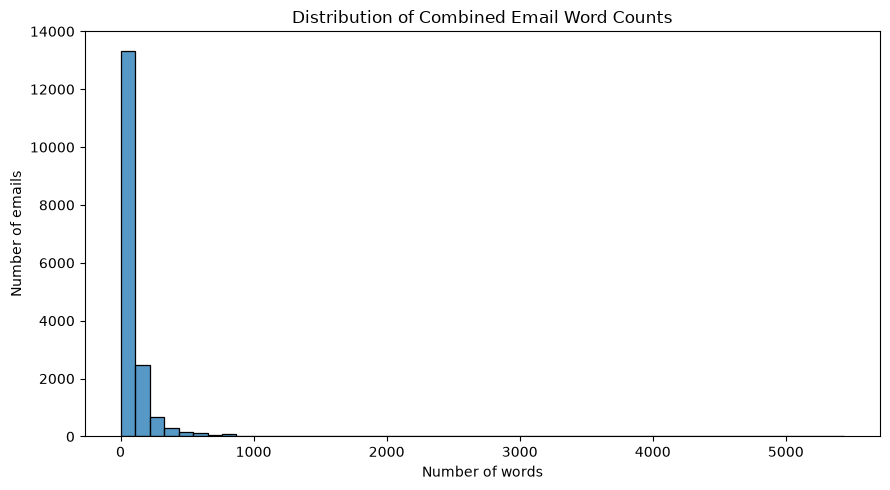

In [62]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=50
)

plt.title("Distribution of Combined Email Word Counts")
plt.xlabel("Number of words")
plt.ylabel("Number of emails")
plt.tight_layout()
plt.show() 

Step 9: Load the semantic embedding model

In [63]:
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("Embedding model loaded.") 

C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hmari\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|█████████████████████| 103/103 [00:00<00:00, 300.34it

Embedding model loaded.


Step 10: Generate semantic embeddings

In [64]:
email_texts = df["embedding_text"].tolist()

email_embeddings = embedding_model.encode(
    email_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Embedding matrix shape:", email_embeddings.shape) 

Batches: 100%|███████████████████████████████████████████████████████████████████████| 542/542 [11:12<00:00,  1.24s/it]

Embedding matrix shape: (17319, 384)


Step 11: Validate embeddings

In [65]:
print("Number of emails:", len(df))
print("Number of embedding rows:", email_embeddings.shape[0])
print("Embedding dimensions:", email_embeddings.shape[1])

print(
    "Contains NaN:",
    np.isnan(email_embeddings).any()
)

print(
    "Contains infinity:",
    np.isinf(email_embeddings).any()
) 

Number of emails: 17319
Number of embedding rows: 17319
Embedding dimensions: 384
Contains NaN: False
Contains infinity: False


In [66]:
embedding_norms = np.linalg.norm(
    email_embeddings,
    axis=1
)

print(
    "Mean embedding norm:",
    embedding_norms.mean()
)

print(
    "Minimum embedding norm:",
    embedding_norms.min()
)

print(
    "Maximum embedding norm:",
    embedding_norms.max()
) 

Mean embedding norm: 1.0
Minimum embedding norm: 0.9999999
Maximum embedding norm: 1.0000001


Step 12: Save embeddings

In [67]:
np.save(
    EMBEDDING_PATH,
    email_embeddings
)

df.to_csv(
    UNSUPERVISED_DATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Embeddings saved at:")
print(EMBEDDING_PATH)

print("\nProcessed dataset saved at:")
print(UNSUPERVISED_DATA_PATH) 

Embeddings saved at:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\unsupervised_email_embeddings.npy

Processed dataset saved at:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\unsupervised_processed_data.csv


Step 13: Reload without regenerating

In [68]:
email_embeddings = np.load(
    EMBEDDING_PATH
)

df = pd.read_csv(
    UNSUPERVISED_DATA_PATH,
    encoding="utf-8-sig"
)

print("Loaded embedding shape:", email_embeddings.shape)
print("Loaded dataset shape:", df.shape) 

Loaded embedding shape: (17319, 384)
Loaded dataset shape: (17319, 7)


Step 14: UMAP Dimensionality Reduction

In [69]:
import umap.umap_ as umap

reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=50,
    metric="cosine",
    random_state=2
)

embedding_umap = reducer.fit_transform(email_embeddings)

print("Reduced embedding shape:", embedding_umap.shape) 

C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Reduced embedding shape: (17319, 50)


Step 15: Save Reduced Embeddings

In [70]:
REDUCED_PATH = os.path.join(
    BASE_DIR,
    "embedding_umap.npy"
)

np.save(REDUCED_PATH, embedding_umap)

print("Reduced embeddings saved.") 

Reduced embeddings saved.


Step 16: Check for NaN

In [71]:
print("NaN:", np.isnan(embedding_umap).any())
print("Infinity:", np.isinf(embedding_umap).any()) 

NaN: False
Infinity: False


Step 17: 2D Visualization 

C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


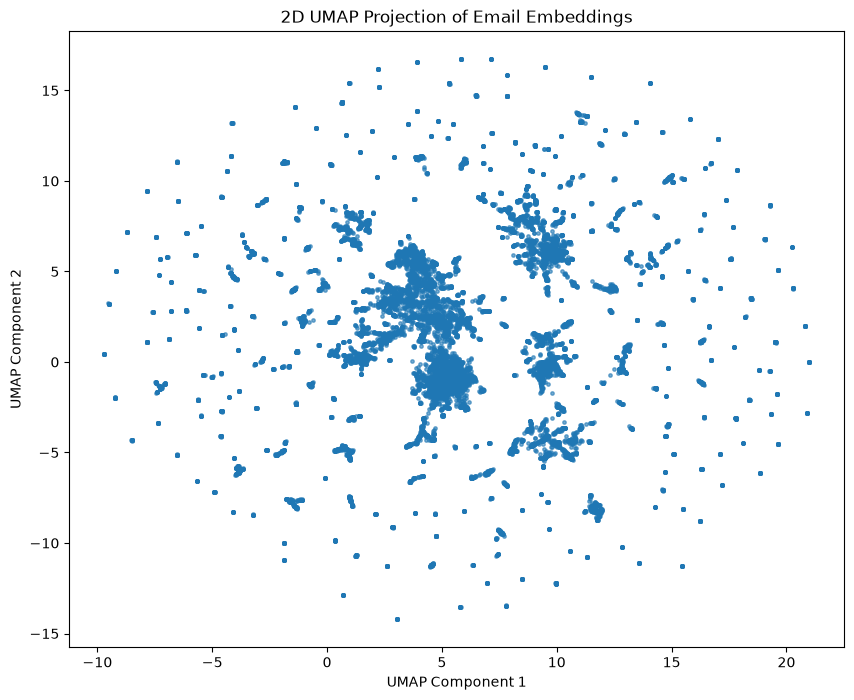

In [72]:
visualizer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="cosine",
    random_state=2
)

embedding_2d = visualizer.fit_transform(email_embeddings)

plt.figure(figsize=(10,8))

plt.scatter(
    embedding_2d[:,0],
    embedding_2d[:,1],
    s=6,
    alpha=0.6
)

plt.title("2D UMAP Projection of Email Embeddings")
plt.xlabel("UMAP Component 1")
plt.ylabel("UMAP Component 2")

plt.show() 

Step 18: Save the 2D Projection

In [73]:
UMAP2D_PATH = os.path.join(
    BASE_DIR,
    "embedding_2d.npy"
)

np.save(UMAP2D_PATH, embedding_2d)

print("2D visualization saved.") 

2D visualization saved.


Step 19: Create a clustering results table

In [74]:
import pandas as pd

cluster_results = pd.DataFrame(
    columns=[
        "Model",
        "Silhouette",
        "Davies_Bouldin",
        "Calinski_Harabasz",
        "ARI",
        "NMI",
        "Homogeneity",
        "Completeness",
        "V_measure"
    ]
)

cluster_results 

,Model,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Homogeneity,Completeness,V_measure


Step 20: Prepare the ground-truth labels

In [75]:
true_labels = df["label"].values

print(np.unique(true_labels)) 

[0 1 2 3]


Step 21: K-Means

In [76]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=2,
    n_init=20
)

kmeans_labels = kmeans.fit_predict(embedding_umap) 

Step 22: Evaluate K-Means

In [77]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score
)

kmeans_result = {

    "Model":"KMeans",

    "Silhouette":
        silhouette_score(
            embedding_umap,
            kmeans_labels
        ),

    "Davies_Bouldin":
        davies_bouldin_score(
            embedding_umap,
            kmeans_labels
        ),

    "Calinski_Harabasz":
        calinski_harabasz_score(
            embedding_umap,
            kmeans_labels
        ),

    "ARI":
        adjusted_rand_score(
            true_labels,
            kmeans_labels
        ),

    "NMI":
        normalized_mutual_info_score(
            true_labels,
            kmeans_labels
        ),

    "Homogeneity":
        homogeneity_score(
            true_labels,
            kmeans_labels
        ),

    "Completeness":
        completeness_score(
            true_labels,
            kmeans_labels
        ),

    "V_measure":
        v_measure_score(
            true_labels,
            kmeans_labels
        )

}

cluster_results.loc[len(cluster_results)] = kmeans_result

cluster_results 

,Model,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Homogeneity,Completeness,V_measure
0,KMeans,0.314636,1.513132,5447.756932,0.475727,0.514513,0.505609,0.523736,0.514513


Step 23: Visualize K-Means

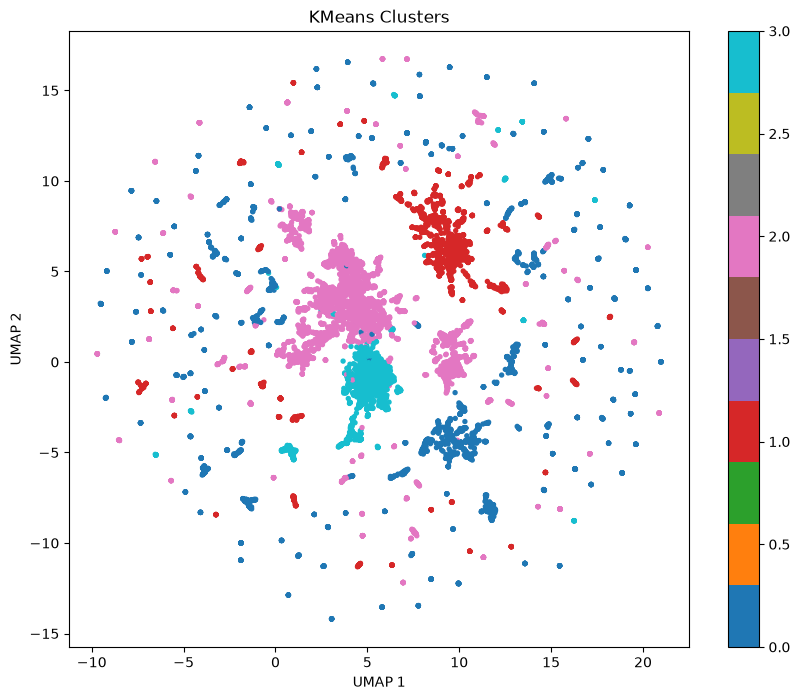

In [78]:
plt.figure(figsize=(10,8))

plt.scatter(

    embedding_2d[:,0],
    embedding_2d[:,1],

    c=kmeans_labels,

    cmap="tab10",

    s=8

)

plt.title("KMeans Clusters")

plt.xlabel("UMAP 1")

plt.ylabel("UMAP 2")

plt.colorbar()

plt.show() 

Step 24: Cluster distribution

In [79]:
pd.Series(kmeans_labels).value_counts().sort_index() 

0    4773
1    3296
2    6416
3    2834
Name: count, dtype: int64

Step 25: Cluster vs Actual Classes

In [80]:
cluster_vs_class = pd.crosstab(

    kmeans_labels,

    true_labels,

    rownames=["Cluster"],

    colnames=["Actual Class"]

)

cluster_vs_class 

Actual Class,0,1,2,3
Cluster,,,,
0,167,122,3195,1289
1,16,60,75,3145
2,1144,4212,632,428
3,2673,60,98,3


Step 26: Save K-Means

In [81]:
df["KMeans_cluster"] = kmeans_labels

KMEANS_PATH = os.path.join(

    BASE_DIR,

    "kmeans_clusters.csv"

)

df.to_csv(

    KMEANS_PATH,

    index=False,

    encoding="utf-8-sig"

)

print("KMeans clusters saved.") 

KMeans clusters saved.


Step 27: Agglomerative Clustering

In [82]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

agg_labels = agg.fit_predict(embedding_umap) 

Step 28: Evaluate Agglomerative Clustering

In [83]:
agg_result = {

    "Model":"Agglomerative",

    "Silhouette":
        silhouette_score(
            embedding_umap,
            agg_labels
        ),

    "Davies_Bouldin":
        davies_bouldin_score(
            embedding_umap,
            agg_labels
        ),

    "Calinski_Harabasz":
        calinski_harabasz_score(
            embedding_umap,
            agg_labels
        ),

    "ARI":
        adjusted_rand_score(
            true_labels,
            agg_labels
        ),

    "NMI":
        normalized_mutual_info_score(
            true_labels,
            agg_labels
        ),

    "Homogeneity":
        homogeneity_score(
            true_labels,
            agg_labels
        ),

    "Completeness":
        completeness_score(
            true_labels,
            agg_labels
        ),

    "V_measure":
        v_measure_score(
            true_labels,
            agg_labels
        )

}

cluster_results.loc[len(cluster_results)] = agg_result

cluster_results 

,Model,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Homogeneity,Completeness,V_measure
0,KMeans,0.314636,1.513132,5447.756932,0.475727,0.514513,0.505609,0.523736,0.514513
1,Agglomerative,0.300368,1.569157,5197.873947,0.456403,0.518458,0.506652,0.530827,0.518458


Step 29: Visualize Agglomerative

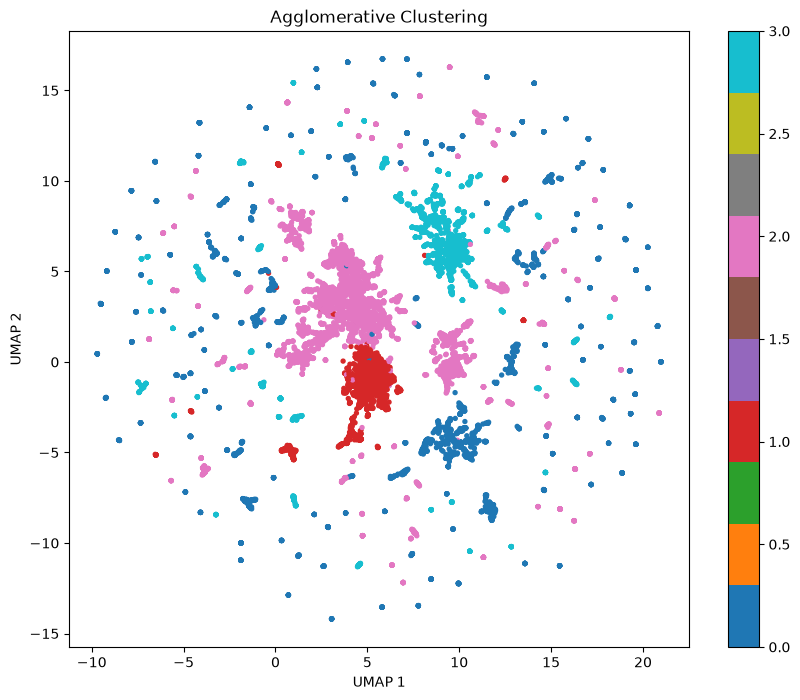

In [84]:
plt.figure(figsize=(10,8))

plt.scatter(
    embedding_2d[:,0],
    embedding_2d[:,1],
    c=agg_labels,
    cmap="tab10",
    s=8
)

plt.title("Agglomerative Clustering")

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

plt.colorbar()

plt.show() 

Step 30: Gaussian Mixture Model (GMM) 

In [85]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(
    n_components=4,
    covariance_type="full",
    random_state=2
)

gmm.fit(embedding_umap)

gmm_labels = gmm.predict(embedding_umap) 

Step 31: Evaluate GMM

In [86]:
gmm_result = {

    "Model":"Gaussian Mixture",

    "Silhouette":
        silhouette_score(
            embedding_umap,
            gmm_labels
        ),

    "Davies_Bouldin":
        davies_bouldin_score(
            embedding_umap,
            gmm_labels
        ),

    "Calinski_Harabasz":
        calinski_harabasz_score(
            embedding_umap,
            gmm_labels
        ),

    "ARI":
        adjusted_rand_score(
            true_labels,
            gmm_labels
        ),

    "NMI":
        normalized_mutual_info_score(
            true_labels,
            gmm_labels
        ),

    "Homogeneity":
        homogeneity_score(
            true_labels,
            gmm_labels
        ),

    "Completeness":
        completeness_score(
            true_labels,
            gmm_labels
        ),

    "V_measure":
        v_measure_score(
            true_labels,
            gmm_labels
        )

}

cluster_results.loc[len(cluster_results)] = gmm_result

cluster_results 

,Model,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Homogeneity,Completeness,V_measure
0,KMeans,0.314636,1.513132,5447.756932,0.475727,0.514513,0.505609,0.523736,0.514513
1,Agglomerative,0.300368,1.569157,5197.873947,0.456403,0.518458,0.506652,0.530827,0.518458
2,Gaussian Mixture,0.351230,1.732808,4184.449532,0.261422,0.366858,0.327362,0.417192,0.366858


Step 32: Visualize GMM

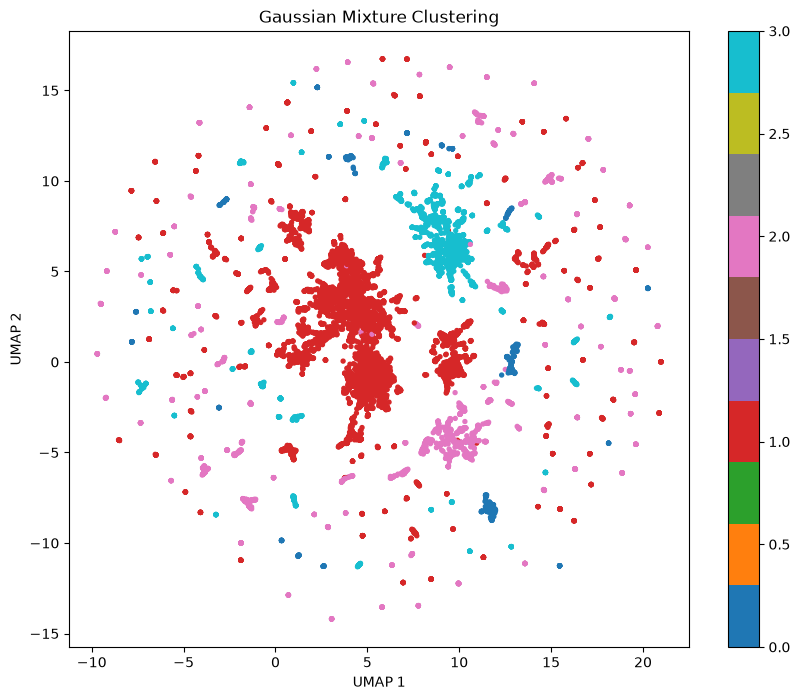

In [87]:
plt.figure(figsize=(10,8))

plt.scatter(
    embedding_2d[:,0],
    embedding_2d[:,1],
    c=gmm_labels,
    cmap="tab10",
    s=8
)

plt.title("Gaussian Mixture Clustering")

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

plt.colorbar()

plt.show() 

Step 33: HDBSCAN 

In [89]:
import hdbscan

hdb = hdbscan.HDBSCAN(

    min_cluster_size=40,

    min_samples=10,

    metric="euclidean",

    prediction_data=True
)

hdb_labels = hdb.fit_predict(embedding_umap) 

Step 34: Number of Clusters Found

In [90]:
print("Clusters found:",
      len(set(hdb_labels)) -
      (1 if -1 in hdb_labels else 0))

print("Noise points:",
      np.sum(hdb_labels==-1)) 

Clusters found: 108
Noise points: 4228


Step 35: Evaluate HDBSCAN 

In [91]:
mask = hdb_labels != -1

X_eval = embedding_umap[mask]

pred_eval = hdb_labels[mask]

true_eval = true_labels[mask] 

In [92]:
hdb_result = {

    "Model":"HDBSCAN",

    "Silhouette":
        silhouette_score(
            X_eval,
            pred_eval
        ),

    "Davies_Bouldin":
        davies_bouldin_score(
            X_eval,
            pred_eval
        ),

    "Calinski_Harabasz":
        calinski_harabasz_score(
            X_eval,
            pred_eval
        ),

    "ARI":
        adjusted_rand_score(
            true_eval,
            pred_eval
        ),

    "NMI":
        normalized_mutual_info_score(
            true_eval,
            pred_eval
        ),

    "Homogeneity":
        homogeneity_score(
            true_eval,
            pred_eval
        ),

    "Completeness":
        completeness_score(
            true_eval,
            pred_eval
        ),

    "V_measure":
        v_measure_score(
            true_eval,
            pred_eval
        )

}

cluster_results.loc[len(cluster_results)] = hdb_result

cluster_results 

,Model,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Homogeneity,Completeness,V_measure
0,KMeans,0.314636,1.513132,5447.756932,0.475727,0.514513,0.505609,0.523736,0.514513
1,Agglomerative,0.300368,1.569157,5197.873947,0.456403,0.518458,0.506652,0.530827,0.518458
2,Gaussian Mixture,0.351230,1.732808,4184.449532,0.261422,0.366858,0.327362,0.417192,0.366858
3,HDBSCAN,0.625655,0.470867,12003.735663,0.142070,0.412617,0.846720,0.272771,0.412617


Step 36: Visualize HDBSCAN

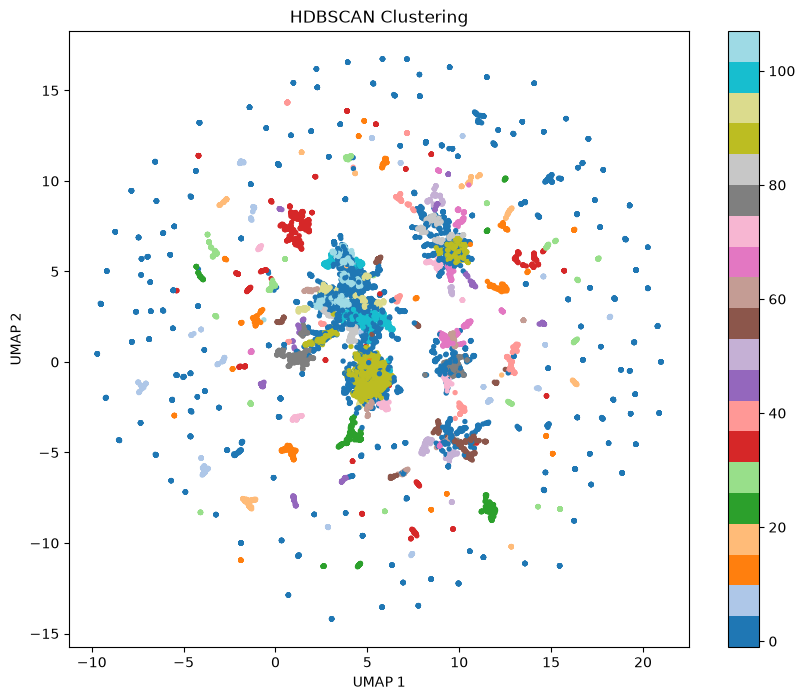

In [93]:
plt.figure(figsize=(10,8))

plt.scatter(
    embedding_2d[:,0],
    embedding_2d[:,1],
    c=hdb_labels,
    cmap="tab20",
    s=8
)

plt.title("HDBSCAN Clustering")

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

plt.colorbar()

plt.show() 

Step 37: Final Comparison Table

In [94]:
cluster_results = cluster_results.round(4)

cluster_results 

,Model,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Homogeneity,Completeness,V_measure
0,KMeans,0.3146,1.5131,5447.7569,0.4757,0.5145,0.5056,0.5237,0.5145
1,Agglomerative,0.3004,1.5692,5197.8739,0.4564,0.5185,0.5067,0.5308,0.5185
2,Gaussian Mixture,0.3512,1.7328,4184.4495,0.2614,0.3669,0.3274,0.4172,0.3669
3,HDBSCAN,0.6257,0.4709,12003.7357,0.1421,0.4126,0.8467,0.2728,0.4126


In [95]:
RESULT_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_results.csv"
)

cluster_results.to_csv(
    RESULT_PATH,
    index=False
)

print(cluster_results) 

              Model  Silhouette  Davies_Bouldin  Calinski_Harabasz     ARI  \
0            KMeans      0.3146          1.5131          5447.7569  0.4757   
1     Agglomerative      0.3004          1.5692          5197.8739  0.4564   
2  Gaussian Mixture      0.3512          1.7328          4184.4495  0.2614   
3           HDBSCAN      0.6257          0.4709         12003.7357  0.1421   

      NMI  Homogeneity  Completeness  V_measure  
0  0.5145       0.5056        0.5237     0.5145  
1  0.5185       0.5067        0.5308     0.5185  
2  0.3669       0.3274        0.4172     0.3669  
3  0.4126       0.8467        0.2728     0.4126  


In [96]:
n_clusters = len(set(hdb_labels)) - (1 if -1 in hdb_labels else 0)
n_noise = np.sum(hdb_labels == -1)
noise_ratio = n_noise / len(hdb_labels)

print("Clusters found:", n_clusters)
print("Noise points:", n_noise)
print("Noise ratio:", noise_ratio) 

Clusters found: 108
Noise points: 4228
Noise ratio: 0.2441249494774525


Step 38: Helper function for internal metrics

In [98]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

def calculate_internal_metrics(X, labels):
    """
    Calculate internal clustering metrics.

    For algorithms such as HDBSCAN, noise points labeled -1
    are excluded before metric calculation.
    """
    labels = np.asarray(labels)

    valid_mask = labels != -1
    X_valid = X[valid_mask]
    labels_valid = labels[valid_mask]

    n_clusters = len(np.unique(labels_valid))

    if n_clusters < 2 or len(X_valid) <= n_clusters:
        return {
            "Silhouette": np.nan,
            "Davies_Bouldin": np.nan,
            "Calinski_Harabasz": np.nan,
            "Clusters": n_clusters,
            "Clustered_Samples": len(X_valid),
            "Noise_Ratio": 1 - valid_mask.mean()
        }

    return {
        "Silhouette": silhouette_score(
            X_valid,
            labels_valid,
            sample_size=min(5000, len(X_valid)),
            random_state=2
        ),
        "Davies_Bouldin": davies_bouldin_score(
            X_valid,
            labels_valid
        ),
        "Calinski_Harabasz": calinski_harabasz_score(
            X_valid,
            labels_valid
        ),
        "Clusters": n_clusters,
        "Clustered_Samples": len(X_valid),
        "Noise_Ratio": 1 - valid_mask.mean()
    } 

Step 39: Tune K-Means cluster count

In [99]:
from sklearn.cluster import KMeans

kmeans_search_results = []

for k in range(2, 11):
    print(f"Testing K-Means with k={k}")

    model = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=2
    )

    labels = model.fit_predict(embedding_umap)

    metrics = calculate_internal_metrics(
        embedding_umap,
        labels
    )

    metrics["Model"] = "KMeans"
    metrics["n_clusters"] = k
    metrics["Inertia"] = model.inertia_

    kmeans_search_results.append(metrics)

kmeans_search_df = pd.DataFrame(kmeans_search_results)

kmeans_search_df 

Testing K-Means with k=2
Testing K-Means with k=3
Testing K-Means with k=4
Testing K-Means with k=5
Testing K-Means with k=6
Testing K-Means with k=7
Testing K-Means with k=8
Testing K-Means with k=9
Testing K-Means with k=10


,Silhouette,Davies_Bouldin,Calinski_Harabasz,Clusters,Clustered_Samples,Noise_Ratio,Model,n_clusters,Inertia
0,0.362217,0.927200,6986.952679,2,17319,0.0,KMeans,2,489521.843750
1,0.350210,1.657766,5924.472719,3,17319,0.0,KMeans,3,407908.250000
2,0.310502,1.513132,5447.756932,4,17319,0.0,KMeans,4,353432.781250
3,0.340152,1.546620,5032.947636,5,17319,0.0,KMeans,5,317665.875000
4,0.355514,1.600680,4739.865109,6,17319,0.0,KMeans,6,290024.187500
5,0.387378,1.460389,4583.818037,7,17319,0.0,KMeans,7,265400.062500
6,0.407659,1.428844,4365.571131,8,17319,0.0,KMeans,8,248447.578125
7,0.422179,1.399343,4151.579686,9,17319,0.0,KMeans,9,235389.640625
8,0.435838,1.225995,3978.972493,10,17319,0.0,KMeans,10,223868.062500


In [100]:
best_kmeans_row = kmeans_search_df.loc[
    kmeans_search_df["Silhouette"].idxmax()
]

best_k = int(best_kmeans_row["n_clusters"])

print("Best K-Means cluster count:", best_k)
print(best_kmeans_row) 

Best K-Means cluster count: 10
Silhouette              0.435838
Davies_Bouldin          1.225995
Calinski_Harabasz    3978.972493
Clusters                      10
Clustered_Samples          17319
Noise_Ratio                  0.0
Model                     KMeans
n_clusters                    10
Inertia              223868.0625
Name: 8, dtype: object


In [103]:
# Train the selected K-Means model: 
best_kmeans = KMeans(
    n_clusters=best_k,
    n_init=20,
    random_state=2
)

best_kmeans_labels = best_kmeans.fit_predict(
    embedding_umap
) 

Step 40: Plot K-Means search results

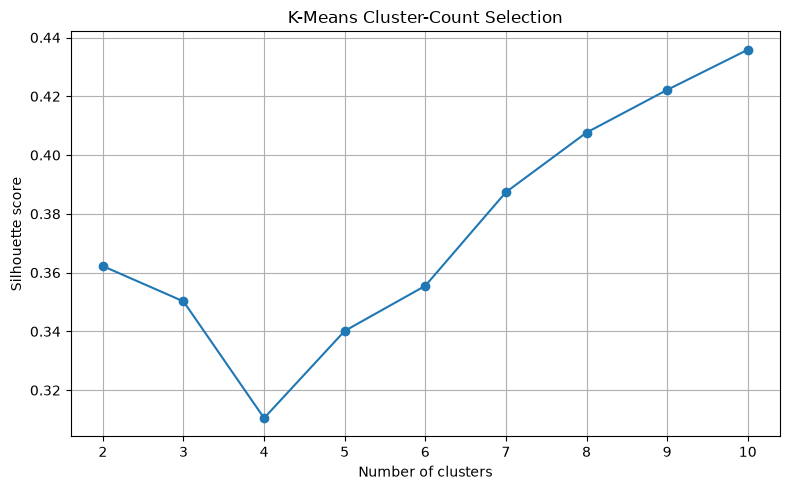

In [104]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    kmeans_search_df["n_clusters"],
    kmeans_search_df["Silhouette"],
    marker="o"
)

plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.title("K-Means Cluster-Count Selection")
plt.xticks(range(2, 11))
plt.grid(True)
plt.tight_layout()
plt.show() 

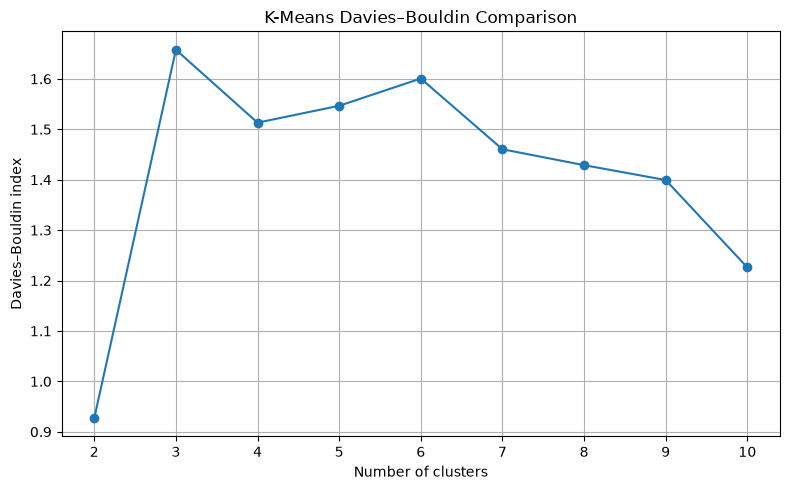

In [105]:
# Davies–Bouldin:

plt.figure(figsize=(8, 5))

plt.plot(
    kmeans_search_df["n_clusters"],
    kmeans_search_df["Davies_Bouldin"],
    marker="o"
)

plt.xlabel("Number of clusters")
plt.ylabel("Davies–Bouldin index")
plt.title("K-Means Davies–Bouldin Comparison")
plt.xticks(range(2, 11))
plt.grid(True)
plt.tight_layout()
plt.show() 

Step 41: Tune Agglomerative Clustering 

In [108]:
import numpy as np

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

def calculate_internal_metrics(
    X,
    labels,
    max_silhouette_samples=5000,
    random_state=2
):
    """
    Calculate internal clustering metrics safely.

    - Removes HDBSCAN noise points labelled -1.
    - Verifies that at least two clusters exist.
    - Uses stratified sampling for Silhouette so every cluster
      is represented in the sample.
    """

    X = np.asarray(X)
    labels = np.asarray(labels)

    # Remove HDBSCAN noise points
    valid_mask = labels != -1

    X_valid = X[valid_mask]
    labels_valid = labels[valid_mask]

    unique_labels, cluster_sizes = np.unique(
        labels_valid,
        return_counts=True
    )

    n_clusters = len(unique_labels)
    n_valid_samples = len(X_valid)
    noise_ratio = 1 - valid_mask.mean()

    # Silhouette requires at least two clusters
    if n_clusters < 2 or n_valid_samples <= n_clusters:
        return {
            "Silhouette": np.nan,
            "Davies_Bouldin": np.nan,
            "Calinski_Harabasz": np.nan,
            "Clusters": n_clusters,
            "Clustered_Samples": n_valid_samples,
            "Noise_Ratio": noise_ratio,
            "Smallest_Cluster": (
                int(cluster_sizes.min())
                if len(cluster_sizes) > 0
                else 0
            )
        }

    # Create a stratified sample for Silhouette
    rng = np.random.default_rng(random_state)

    if n_valid_samples > max_silhouette_samples:
        sampled_indices = []

        for cluster_label, cluster_size in zip(
            unique_labels,
            cluster_sizes
        ):
            cluster_indices = np.where(
                labels_valid == cluster_label
            )[0]

            # Allocate samples proportionally, minimum 2 per cluster
            n_cluster_samples = max(
                2,
                int(
                    max_silhouette_samples
                    * cluster_size
                    / n_valid_samples
                )
            )

            n_cluster_samples = min(
                n_cluster_samples,
                len(cluster_indices)
            )

            selected = rng.choice(
                cluster_indices,
                size=n_cluster_samples,
                replace=False
            )

            sampled_indices.extend(selected)

        sampled_indices = np.array(sampled_indices)

        X_silhouette = X_valid[sampled_indices]
        labels_silhouette = labels_valid[sampled_indices]

    else:
        X_silhouette = X_valid
        labels_silhouette = labels_valid

    # Check again after sampling
    if len(np.unique(labels_silhouette)) < 2:
        silhouette = np.nan
    else:
        silhouette = silhouette_score(
            X_silhouette,
            labels_silhouette
        )

    return {
        "Silhouette": silhouette,

        "Davies_Bouldin": davies_bouldin_score(
            X_valid,
            labels_valid
        ),

        "Calinski_Harabasz": calinski_harabasz_score(
            X_valid,
            labels_valid
        ),

        "Clusters": n_clusters,
        "Clustered_Samples": n_valid_samples,
        "Noise_Ratio": noise_ratio,
        "Smallest_Cluster": int(cluster_sizes.min())
    } 

In [109]:
agg_search_results = []

for setting in agg_settings:
    print("Testing Agglomerative:", setting)

    model = AgglomerativeClustering(
        n_clusters=setting["n_clusters"],
        linkage=setting["linkage"],
        metric=setting["metric"]
    )

    labels = model.fit_predict(embedding_umap)

    print(
        "Produced clusters:",
        np.unique(labels, return_counts=True)
    )

    metrics = calculate_internal_metrics(
        embedding_umap,
        labels
    )

    metrics["Model"] = "Agglomerative"
    metrics["n_clusters"] = setting["n_clusters"]
    metrics["linkage"] = setting["linkage"]
    metrics["metric"] = setting["metric"]

    agg_search_results.append(metrics)

agg_search_df = pd.DataFrame(agg_search_results)

agg_search_df 

Testing Agglomerative: {'n_clusters': 2, 'linkage': 'ward', 'metric': 'euclidean'}
Produced clusters: (array([0, 1]), array([14220,  3099]))
Testing Agglomerative: {'n_clusters': 2, 'linkage': 'average', 'metric': 'cosine'}
Produced clusters: (array([0, 1]), array([17311,     8]))
Testing Agglomerative: {'n_clusters': 2, 'linkage': 'complete', 'metric': 'cosine'}
Produced clusters: (array([0, 1]), array([9165, 8154]))
Testing Agglomerative: {'n_clusters': 3, 'linkage': 'ward', 'metric': 'euclidean'}
Produced clusters: (array([0, 1, 2]), array([9533, 3099, 4687]))
Testing Agglomerative: {'n_clusters': 3, 'linkage': 'average', 'metric': 'cosine'}
Produced clusters: (array([0, 1, 2]), array([17305,     8,     6]))
Testing Agglomerative: {'n_clusters': 3, 'linkage': 'complete', 'metric': 'cosine'}
Produced clusters: (array([0, 1, 2]), array([8154, 3443, 5722]))
Testing Agglomerative: {'n_clusters': 4, 'linkage': 'ward', 'metric': 'euclidean'}
Produced clusters: (array([0, 1, 2, 3]), array(

,Silhouette,Davies_Bouldin,Calinski_Harabasz,Clusters,Clustered_Samples,Noise_Ratio,Smallest_Cluster,Model,n_clusters,linkage,metric
0,0.362414,0.873518,6878.344708,2,17319,0.0,3099,Agglomerative,2,ward,euclidean
1,0.377047,0.505336,28.344193,2,17319,0.0,8,Agglomerative,2,average,cosine
2,0.127679,2.875071,1849.215494,2,17319,0.0,8154,Agglomerative,2,complete,cosine
3,0.343038,1.742425,5567.935501,3,17319,0.0,3099,Agglomerative,3,ward,euclidean
4,0.336946,0.503321,25.065796,3,17319,0.0,6,Agglomerative,3,average,cosine
5,0.187887,2.615849,3817.834905,3,17319,0.0,3443,Agglomerative,3,complete,cosine
6,0.303585,1.569157,5197.873947,4,17319,0.0,2730,Agglomerative,4,ward,euclidean
7,0.326398,0.525981,30.733476,4,17319,0.0,6,Agglomerative,4,average,cosine
8,0.200765,2.674494,3035.315861,4,17319,0.0,2362,Agglomerative,4,complete,cosine
9,0.335401,1.744022,4753.528397,5,17319,0.0,2230,Agglomerative,5,ward,euclidean


In [110]:
# Select the best configuration: 
best_agg_row = agg_search_df.loc[
    agg_search_df["Silhouette"].idxmax()
]

print("Best Agglomerative configuration:")
print(best_agg_row) 

Best Agglomerative configuration:
Silhouette                0.442764
Davies_Bouldin            1.379248
Calinski_Harabasz      3923.308292
Clusters                        10
Clustered_Samples            17319
Noise_Ratio                    0.0
Smallest_Cluster               167
Model                Agglomerative
n_clusters                      10
linkage                       ward
metric                   euclidean
Name: 24, dtype: object


In [111]:
# Train the selected model: 
best_agg = AgglomerativeClustering(
    n_clusters=int(best_agg_row["n_clusters"]),
    linkage=best_agg_row["linkage"],
    metric=best_agg_row["metric"]
)

best_agg_labels = best_agg.fit_predict(
    embedding_umap
) 

Step 42: Tune Gaussian Mixture Model

In [112]:
from sklearn.mixture import GaussianMixture

gmm_search_results = []

covariance_types = [
    "full",
    "tied",
    "diag",
    "spherical"
]

for covariance_type in covariance_types:
    for n_components in range(2, 11):

        print(
            f"Testing GMM: components={n_components}, "
            f"covariance={covariance_type}"
        )

        model = GaussianMixture(
            n_components=n_components,
            covariance_type=covariance_type,
            n_init=3,
            random_state=2,
            reg_covar=1e-6
        )

        labels = model.fit_predict(
            embedding_umap
        )

        metrics = calculate_internal_metrics(
            embedding_umap,
            labels
        )

        metrics["Model"] = "Gaussian Mixture"
        metrics["n_components"] = n_components
        metrics["covariance_type"] = covariance_type
        metrics["BIC"] = model.bic(embedding_umap)
        metrics["AIC"] = model.aic(embedding_umap)

        gmm_search_results.append(metrics)

gmm_search_df = pd.DataFrame(
    gmm_search_results
)

gmm_search_df 

Testing GMM: components=2, covariance=full
Testing GMM: components=3, covariance=full
Testing GMM: components=4, covariance=full
Testing GMM: components=5, covariance=full
Testing GMM: components=6, covariance=full
Testing GMM: components=7, covariance=full
Testing GMM: components=8, covariance=full
Testing GMM: components=9, covariance=full
Testing GMM: components=10, covariance=full
Testing GMM: components=2, covariance=tied
Testing GMM: components=3, covariance=tied
Testing GMM: components=4, covariance=tied
Testing GMM: components=5, covariance=tied
Testing GMM: components=6, covariance=tied
Testing GMM: components=7, covariance=tied
Testing GMM: components=8, covariance=tied
Testing GMM: components=9, covariance=tied
Testing GMM: components=10, covariance=tied
Testing GMM: components=2, covariance=diag
Testing GMM: components=3, covariance=diag
Testing GMM: components=4, covariance=diag
Testing GMM: components=5, covariance=diag
Testing GMM: components=6, covariance=diag
Testing G

,Silhouette,Davies_Bouldin,Calinski_Harabasz,Clusters,Clustered_Samples,Noise_Ratio,Smallest_Cluster,Model,n_components,covariance_type,BIC,AIC
0,0.367049,0.935196,6979.831410,2,17319,0.0,3385,Gaussian Mixture,2,full,6.288505e+05,6.082799e+05
1,0.273499,2.013524,4991.913597,3,17319,0.0,3279,Gaussian Mixture,3,full,-1.158445e+06,-1.189304e+06
2,0.273435,1.994256,4584.765704,4,17319,0.0,3270,Gaussian Mixture,4,full,-1.589348e+06,-1.630497e+06
3,0.343690,1.686295,4854.133098,5,17319,0.0,2170,Gaussian Mixture,5,full,-1.980189e+06,-2.031627e+06
4,0.363039,1.608967,4694.691930,6,17319,0.0,2542,Gaussian Mixture,6,full,-2.340785e+06,-2.402512e+06
5,0.387901,1.470836,4564.988451,7,17319,0.0,749,Gaussian Mixture,7,full,-2.588790e+06,-2.660806e+06
6,0.407392,2.137527,4103.753427,8,17319,0.0,723,Gaussian Mixture,8,full,-2.908123e+06,-2.990429e+06
7,0.368909,1.533165,3894.878589,9,17319,0.0,749,Gaussian Mixture,9,full,-3.118407e+06,-3.211002e+06
8,0.384682,1.758108,3631.406871,10,17319,0.0,505,Gaussian Mixture,10,full,-3.389497e+06,-3.492381e+06
9,0.365349,0.885615,6868.118824,2,17319,0.0,3136,Gaussian Mixture,2,tied,1.203662e+06,1.192985e+06


In [113]:
best_gmm_row = gmm_search_df.loc[
    gmm_search_df["BIC"].idxmin()
]

print("Best GMM configuration by BIC:")
print(best_gmm_row) 

Best GMM configuration by BIC:
Silhouette                   0.384682
Davies_Bouldin               1.758108
Calinski_Harabasz         3631.406871
Clusters                           10
Clustered_Samples               17319
Noise_Ratio                       0.0
Smallest_Cluster                  505
Model                Gaussian Mixture
n_components                       10
covariance_type                  full
BIC                   -3389497.399849
AIC                   -3492381.398514
Name: 8, dtype: object


In [114]:
best_gmm = GaussianMixture(
    n_components=int(
        best_gmm_row["n_components"]
    ),
    covariance_type=best_gmm_row[
        "covariance_type"
    ],
    n_init=5,
    random_state=2,
    reg_covar=1e-6
)

best_gmm_labels = best_gmm.fit_predict(
    embedding_umap
) 

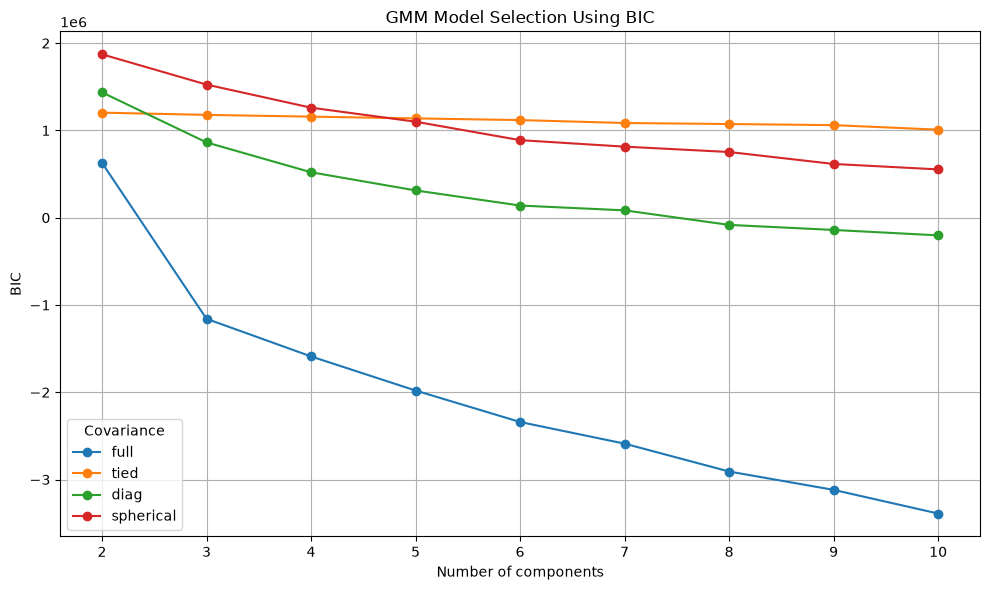

In [115]:
plt.figure(figsize=(10, 6))

for covariance_type in covariance_types:
    subset = gmm_search_df[
        gmm_search_df["covariance_type"]
        == covariance_type
    ]

    plt.plot(
        subset["n_components"],
        subset["BIC"],
        marker="o",
        label=covariance_type
    )

plt.xlabel("Number of components")
plt.ylabel("BIC")
plt.title("GMM Model Selection Using BIC")
plt.legend(title="Covariance")
plt.grid(True)
plt.tight_layout()
plt.show() 

Step 43: Tune HDBSCAN 

In [116]:
import hdbscan

hdbscan_search_results = []

min_cluster_sizes = [
    20,
    40,
    60,
    80,
    100,
    150
]

min_samples_values = [
    5,
    10,
    20,
    30
]

for min_cluster_size in min_cluster_sizes:
    for min_samples in min_samples_values:

        print(
            f"Testing HDBSCAN: "
            f"min_cluster_size={min_cluster_size}, "
            f"min_samples={min_samples}"
        )

        model = hdbscan.HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min_samples,
            metric="euclidean",
            cluster_selection_method="eom",
            prediction_data=True
        )

        labels = model.fit_predict(
            embedding_umap
        )

        metrics = calculate_internal_metrics(
            embedding_umap,
            labels
        )

        metrics["Model"] = "HDBSCAN"
        metrics["min_cluster_size"] = (
            min_cluster_size
        )
        metrics["min_samples"] = min_samples
        metrics["Mean_Cluster_Probability"] = (
            model.probabilities_[
                labels != -1
            ].mean()
            if np.any(labels != -1)
            else np.nan
        )

        hdbscan_search_results.append(metrics)

hdbscan_search_df = pd.DataFrame(
    hdbscan_search_results
)

hdbscan_search_df 

Testing HDBSCAN: min_cluster_size=20, min_samples=5
Testing HDBSCAN: min_cluster_size=20, min_samples=10
Testing HDBSCAN: min_cluster_size=20, min_samples=20
Testing HDBSCAN: min_cluster_size=20, min_samples=30
Testing HDBSCAN: min_cluster_size=40, min_samples=5
Testing HDBSCAN: min_cluster_size=40, min_samples=10
Testing HDBSCAN: min_cluster_size=40, min_samples=20
Testing HDBSCAN: min_cluster_size=40, min_samples=30
Testing HDBSCAN: min_cluster_size=60, min_samples=5
Testing HDBSCAN: min_cluster_size=60, min_samples=10
Testing HDBSCAN: min_cluster_size=60, min_samples=20
Testing HDBSCAN: min_cluster_size=60, min_samples=30
Testing HDBSCAN: min_cluster_size=80, min_samples=5
Testing HDBSCAN: min_cluster_size=80, min_samples=10
Testing HDBSCAN: min_cluster_size=80, min_samples=20
Testing HDBSCAN: min_cluster_size=80, min_samples=30
Testing HDBSCAN: min_cluster_size=100, min_samples=5
Testing HDBSCAN: min_cluster_size=100, min_samples=10
Testing HDBSCAN: min_cluster_size=100, min_sample

,Silhouette,Davies_Bouldin,Calinski_Harabasz,Clusters,Clustered_Samples,Noise_Ratio,Smallest_Cluster,Model,min_cluster_size,min_samples,Mean_Cluster_Probability
0,0.686423,0.505695,10658.200778,256,12301,0.289740,20,HDBSCAN,20,5,0.814247
1,0.678883,0.484909,10318.988681,231,12268,0.291645,20,HDBSCAN,20,10,0.802567
2,0.641635,0.452401,8152.246421,173,13066,0.245568,20,HDBSCAN,20,20,0.823602
3,0.702912,0.372522,9333.675895,113,12726,0.265200,20,HDBSCAN,20,30,0.808242
4,0.620487,0.508678,11383.874649,113,13385,0.227149,40,HDBSCAN,40,5,0.833418
5,0.627608,0.470867,12003.735663,108,13091,0.244125,40,HDBSCAN,40,10,0.839772
6,0.650101,0.408845,12330.542701,95,13118,0.242566,40,HDBSCAN,40,20,0.852613
7,0.694325,0.385883,11164.678282,94,12947,0.252440,40,HDBSCAN,40,30,0.852599
8,0.633772,0.497002,12894.421806,77,13401,0.226226,60,HDBSCAN,60,5,0.880494
9,0.604553,0.485170,13463.770001,78,13281,0.233154,62,HDBSCAN,60,10,0.869880


In [117]:
acceptable_hdbscan = hdbscan_search_df[
    (hdbscan_search_df["Clusters"] >= 2)
    &
    (hdbscan_search_df["Noise_Ratio"] <= 0.30)
].copy() 

In [118]:
if len(acceptable_hdbscan) > 0:
    best_hdbscan_row = acceptable_hdbscan.loc[
        acceptable_hdbscan[
            "Silhouette"
        ].idxmax()
    ]
else:
    best_hdbscan_row = (
        hdbscan_search_df
        .sort_values(
            ["Noise_Ratio", "Silhouette"],
            ascending=[True, False]
        )
        .iloc[0]
    )

print("Best HDBSCAN configuration:")
print(best_hdbscan_row) 

Best HDBSCAN configuration:
Silhouette                     0.702912
Davies_Bouldin                 0.372522
Calinski_Harabasz           9333.675895
Clusters                            113
Clustered_Samples                 12726
Noise_Ratio                      0.2652
Smallest_Cluster                     20
Model                           HDBSCAN
min_cluster_size                     20
min_samples                          30
Mean_Cluster_Probability       0.808242
Name: 3, dtype: object


In [119]:
best_hdbscan = hdbscan.HDBSCAN(
    min_cluster_size=int(
        best_hdbscan_row[
            "min_cluster_size"
        ]
    ),
    min_samples=int(
        best_hdbscan_row[
            "min_samples"
        ]
    ),
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True
)

best_hdbscan_labels = (
    best_hdbscan.fit_predict(
        embedding_umap
    )
) 

Step 44: Evaluate selected configurations externally

In [120]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score
)

true_labels = df["label"].to_numpy() 

In [121]:
def calculate_external_metrics(
    true_labels,
    cluster_labels,
    remove_noise=False
):
    true_labels = np.asarray(true_labels)
    cluster_labels = np.asarray(
        cluster_labels
    )

    if remove_noise:
        mask = cluster_labels != -1
        true_eval = true_labels[mask]
        cluster_eval = cluster_labels[mask]
    else:
        true_eval = true_labels
        cluster_eval = cluster_labels

    return {
        "ARI": adjusted_rand_score(
            true_eval,
            cluster_eval
        ),
        "NMI": normalized_mutual_info_score(
            true_eval,
            cluster_eval
        ),
        "Homogeneity": homogeneity_score(
            true_eval,
            cluster_eval
        ),
        "Completeness": completeness_score(
            true_eval,
            cluster_eval
        ),
        "V_measure": v_measure_score(
            true_eval,
            cluster_eval
        )
    } 

In [122]:
selected_results = [] 

In [123]:
metrics = calculate_internal_metrics(
    embedding_umap,
    best_kmeans_labels
)

metrics.update(
    calculate_external_metrics(
        true_labels,
        best_kmeans_labels
    )
)

metrics["Model"] = "Tuned K-Means"
metrics["Parameters"] = (
    f"k={best_k}"
)

selected_results.append(metrics) 

In [124]:
metrics = calculate_internal_metrics(
    embedding_umap,
    best_agg_labels
)

metrics.update(
    calculate_external_metrics(
        true_labels,
        best_agg_labels
    )
)

metrics["Model"] = "Tuned Agglomerative"
metrics["Parameters"] = (
    f"k={int(best_agg_row['n_clusters'])}, "
    f"linkage={best_agg_row['linkage']}, "
    f"metric={best_agg_row['metric']}"
)

selected_results.append(metrics) 

In [125]:
metrics = calculate_internal_metrics(
    embedding_umap,
    best_gmm_labels
)

metrics.update(
    calculate_external_metrics(
        true_labels,
        best_gmm_labels
    )
)

metrics["Model"] = "Tuned GMM"
metrics["Parameters"] = (
    f"components="
    f"{int(best_gmm_row['n_components'])}, "
    f"covariance="
    f"{best_gmm_row['covariance_type']}"
)

selected_results.append(metrics) 

In [126]:
metrics = calculate_internal_metrics(
    embedding_umap,
    best_hdbscan_labels
)

metrics.update(
    calculate_external_metrics(
        true_labels,
        best_hdbscan_labels,
        remove_noise=True
    )
)

metrics["Model"] = "Tuned HDBSCAN"
metrics["Parameters"] = (
    f"min_cluster_size="
    f"{int(best_hdbscan_row['min_cluster_size'])}, "
    f"min_samples="
    f"{int(best_hdbscan_row['min_samples'])}"
)

selected_results.append(metrics) 

In [128]:
# Final table: 
tuned_cluster_results = pd.DataFrame(
    selected_results
)

display_columns = [
    "Model",
    "Parameters",
    "Clusters",
    "Noise_Ratio",
    "Silhouette",
    "Davies_Bouldin",
    "Calinski_Harabasz",
    "ARI",
    "NMI",
    "Homogeneity",
    "Completeness",
    "V_measure"
]

tuned_cluster_results = (
    tuned_cluster_results[
        display_columns
    ]
    .round(4)
)

tuned_cluster_results 

,Model,Parameters,Clusters,Noise_Ratio,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Homogeneity,Completeness,V_measure
0,Tuned K-Means,k=10,10,0.0000,0.4342,1.2260,3978.9725,0.4516,0.5088,0.6325,0.4255,0.5088
1,Tuned Agglomerative,"k=10, linkage=ward, metric=euclidean",10,0.0000,0.4428,1.3792,3923.3083,0.4568,0.5137,0.6440,0.4273,0.5137
2,Tuned GMM,"components=10, covariance=full",10,0.0000,0.3847,1.7581,3631.4069,0.4110,0.5013,0.6448,0.4100,0.5013
3,Tuned HDBSCAN,"min_cluster_size=20, min_samples=30",113,0.2652,0.7029,0.3725,9333.6759,0.1937,0.4189,0.8417,0.2788,0.4189


Step 45: Save all search results

In [129]:
kmeans_search_df.to_csv(
    os.path.join(
        BASE_DIR,
        "kmeans_parameter_search.csv"
    ),
    index=False
)

agg_search_df.to_csv(
    os.path.join(
        BASE_DIR,
        "agglomerative_parameter_search.csv"
    ),
    index=False
)

gmm_search_df.to_csv(
    os.path.join(
        BASE_DIR,
        "gmm_parameter_search.csv"
    ),
    index=False
)

hdbscan_search_df.to_csv(
    os.path.join(
        BASE_DIR,
        "hdbscan_parameter_search.csv"
    ),
    index=False
)

tuned_cluster_results.to_csv(
    os.path.join(
        BASE_DIR,
        "tuned_unsupervised_results.csv"
    ),
    index=False
)

print("All parameter-search results saved.") 

All parameter-search results saved.


Step 46: Import required libraries

In [131]:
# New Recommandation 

import os
import gc
import numpy as np
import pandas as pd
import torch

from sentence_transformers import SentenceTransformer

import umap.umap_ as umap

from sklearn.cluster import AgglomerativeClustering

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score
) 

Step 47: Confirm the required variables exist

In [132]:
print("Dataset shape:", df.shape)
print("Embedding text available:", "embedding_text" in df.columns)
print("Known labels:", sorted(df["label"].unique()))

assert "embedding_text" in df.columns
assert "label" in df.columns 

Dataset shape: (17319, 8)
Embedding text available: True
Known labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


Step 48: Define models to compare

In [133]:
embedding_models = {
    "MiniLM": {
        "model_name": "sentence-transformers/all-MiniLM-L6-v2",
        "prefix": ""
    },

    "MPNet": {
        "model_name": "sentence-transformers/all-mpnet-base-v2",
        "prefix": ""
    },

    "BGE-base": {
        "model_name": "BAAI/bge-base-en-v1.5",
        "prefix": ""
    },

    "E5-base": {
        "model_name": "intfloat/e5-base-v2",
        "prefix": "passage: "
    }
} 

Step 49: Define storage paths

In [134]:
EMBEDDING_COMPARISON_DIR = os.path.join(
    BASE_DIR,
    "embedding_model_comparison"
)

os.makedirs(
    EMBEDDING_COMPARISON_DIR,
    exist_ok=True
)

print("Comparison files will be saved in:")
print(EMBEDDING_COMPARISON_DIR) 

Comparison files will be saved in:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison


Step 50: Create the embedding function

In [135]:
def generate_or_load_embeddings(
    display_name,
    model_name,
    texts,
    prefix="",
    batch_size=32
):
    safe_name = (
        display_name
        .lower()
        .replace("-", "_")
        .replace(" ", "_")
    )

    embedding_path = os.path.join(
        EMBEDDING_COMPARISON_DIR,
        f"{safe_name}_embeddings.npy"
    )

    # Load previously generated embeddings
    if os.path.exists(embedding_path):
        embeddings = np.load(embedding_path)

        print(
            f"{display_name}: loaded saved embeddings "
            f"{embeddings.shape}"
        )

        return embeddings

    print(f"\nLoading model: {model_name}")

    model = SentenceTransformer(model_name)

    prepared_texts = [
        prefix + str(text)
        for text in texts
    ]

    embeddings = model.encode(
        prepared_texts,
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    embeddings = embeddings.astype(
        np.float32
    )

    np.save(
        embedding_path,
        embeddings
    )

    print(
        f"{display_name}: embeddings saved at "
        f"{embedding_path}"
    )

    # Clear memory before loading another model
    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return embeddings 

Step 51: Define fixed UMAP transformation

In [136]:
def reduce_embeddings_with_umap(
    embeddings,
    display_name
):
    safe_name = (
        display_name
        .lower()
        .replace("-", "_")
        .replace(" ", "_")
    )

    umap_path = os.path.join(
        EMBEDDING_COMPARISON_DIR,
        f"{safe_name}_umap50.npy"
    )

    if os.path.exists(umap_path):
        reduced_embeddings = np.load(
            umap_path
        )

        print(
            f"{display_name}: loaded saved UMAP "
            f"{reduced_embeddings.shape}"
        )

        return reduced_embeddings

    reducer = umap.UMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=50,
        metric="cosine",
        random_state=2
    )

    reduced_embeddings = (
        reducer.fit_transform(
            embeddings
        )
    )

    reduced_embeddings = (
        reduced_embeddings.astype(
            np.float32
        )
    )

    np.save(
        umap_path,
        reduced_embeddings
    )

    print(
        f"{display_name}: UMAP saved at "
        f"{umap_path}"
    )

    return reduced_embeddings 

Step 52: Define fixed Agglomerative clustering

In [137]:
def run_fixed_agglomerative(
    reduced_embeddings
):
    model = AgglomerativeClustering(
        n_clusters=10,
        linkage="ward",
        metric="euclidean"
    )

    cluster_labels = model.fit_predict(
        reduced_embeddings
    )

    return cluster_labels 

Step 53: Define evaluation function

In [138]:
def evaluate_embedding_clusters(
    embeddings,
    cluster_labels,
    true_labels,
    model_name,
    max_silhouette_samples=5000
):
    embeddings = np.asarray(embeddings)
    cluster_labels = np.asarray(
        cluster_labels
    )
    true_labels = np.asarray(
        true_labels
    )

    unique_clusters = np.unique(
        cluster_labels
    )

    if len(unique_clusters) < 2:
        raise ValueError(
            f"{model_name} produced fewer than "
            "two clusters."
        )

    silhouette = silhouette_score(
        embeddings,
        cluster_labels,
        sample_size=min(
            max_silhouette_samples,
            len(embeddings)
        ),
        random_state=2
    )

    return {
        "Embedding_Model": model_name,

        "Embedding_Dimensions":
            embeddings.shape[1],

        "Clusters":
            len(unique_clusters),

        "Silhouette":
            silhouette,

        "Davies_Bouldin":
            davies_bouldin_score(
                embeddings,
                cluster_labels
            ),

        "Calinski_Harabasz":
            calinski_harabasz_score(
                embeddings,
                cluster_labels
            ),

        "ARI":
            adjusted_rand_score(
                true_labels,
                cluster_labels
            ),

        "NMI":
            normalized_mutual_info_score(
                true_labels,
                cluster_labels
            ),

        "Homogeneity":
            homogeneity_score(
                true_labels,
                cluster_labels
            ),

        "Completeness":
            completeness_score(
                true_labels,
                cluster_labels
            ),

        "V_measure":
            v_measure_score(
                true_labels,
                cluster_labels
            )
    } 

Step 54: Run the complete embedding comparison

In [139]:
email_texts = (
    df["embedding_text"]
    .fillna("")
    .astype(str)
    .tolist()
)

true_labels = (
    df["label"]
    .astype(int)
    .to_numpy()
)

embedding_comparison_results = []

embedding_cluster_labels = {}
embedding_umap_results = {} 

In [140]:
# Run all four: 
for display_name, config in embedding_models.items():

    print("\n" + "=" * 70)
    print(f"Processing embedding model: {display_name}")
    print("=" * 70)

    embeddings = generate_or_load_embeddings(
        display_name=display_name,
        model_name=config["model_name"],
        texts=email_texts,
        prefix=config["prefix"],
        batch_size=32
    )

    print(
        f"{display_name} original embedding shape:",
        embeddings.shape
    )

    reduced_embeddings = (
        reduce_embeddings_with_umap(
            embeddings,
            display_name
        )
    )

    print(
        f"{display_name} reduced shape:",
        reduced_embeddings.shape
    )

    cluster_labels = (
        run_fixed_agglomerative(
            reduced_embeddings
        )
    )

    result = evaluate_embedding_clusters(
        embeddings=reduced_embeddings,
        cluster_labels=cluster_labels,
        true_labels=true_labels,
        model_name=display_name
    )

    embedding_comparison_results.append(
        result
    )

    embedding_cluster_labels[
        display_name
    ] = cluster_labels

    embedding_umap_results[
        display_name
    ] = reduced_embeddings

    # Save cluster assignments
    output_df = pd.DataFrame({
        "row_index": np.arange(len(df)),
        "true_label": true_labels,
        "cluster": cluster_labels
    })

    output_path = os.path.join(
        EMBEDDING_COMPARISON_DIR,
        (
            display_name
            .lower()
            .replace("-", "_")
            .replace(" ", "_")
            + "_clusters.csv"
        )
    )

    output_df.to_csv(
        output_path,
        index=False
    )

    del embeddings
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache() 


Processing embedding model: MiniLM

Loading model: sentence-transformers/all-MiniLM-L6-v2


Loading weights: 100%|█████████████████████| 103/103 [00:00<00:00, 314.88it/s, Materializing param=pooler.dense.weight]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches: 100%|███████████████████████████████████████████████████████████████████████| 542/542 [11:40<00:00,  1.29s/it]


MiniLM: embeddings saved at C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\minilm_embeddings.npy
MiniLM original embedding shape: (17319, 384)


C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


MiniLM: UMAP saved at C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\minilm_umap50.npy
MiniLM reduced shape: (17319, 50)

Processing embedding model: MPNet

Loading model: sentence-transformers/all-mpnet-base-v2


...

BGE-base: UMAP saved at C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\bge_base_umap50.npy
BGE-base reduced shape: (17319, 50)

Processing embedding model: E5-base

Loading model: intfloat/e5-base-v2


C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hmari\.cache\huggingface\hub\models--intfloat--e5-base-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|█████████████████████| 199/199 [00:00<00:00, 410.09it/s, Materializing p

E5-base: embeddings saved at C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_embeddings.npy
E5-base original embedding shape: (17319, 768)


C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


E5-base: UMAP saved at C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_umap50.npy
E5-base reduced shape: (17319, 50)


Step 55: Create the comparison table

In [141]:
embedding_comparison_df = pd.DataFrame(
    embedding_comparison_results
)

embedding_comparison_df = (
    embedding_comparison_df
    .sort_values(
        by=[
            "NMI",
            "ARI",
            "Silhouette"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

embedding_comparison_df = (
    embedding_comparison_df.round(4)
)

embedding_comparison_df 

,Embedding_Model,Embedding_Dimensions,Clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Homogeneity,Completeness,V_measure
0,E5-base,50,10,0.4879,1.4340,3784.6571,0.5402,0.6160,0.7372,0.5290,0.6160
1,MPNet,50,10,0.4527,1.6348,4379.5152,0.4202,0.5304,0.6663,0.4406,0.5304
2,MiniLM,50,10,0.4360,1.3792,3923.3083,0.4568,0.5137,0.6440,0.4273,0.5137
3,BGE-base,50,10,0.3871,1.5335,3394.1568,0.4173,0.5007,0.6191,0.4203,0.5007


Step 56: Save the final comparison table

In [142]:
EMBEDDING_RESULT_PATH = os.path.join(
    EMBEDDING_COMPARISON_DIR,
    "embedding_model_comparison_results.csv"
)

embedding_comparison_df.to_csv(
    EMBEDDING_RESULT_PATH,
    index=False
)

print("Embedding comparison saved at:")
print(EMBEDDING_RESULT_PATH) 

Embedding comparison saved at:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\embedding_model_comparison_results.csv


Step 57: Identify the best embedding model

In [144]:
best_embedding_row = (
    embedding_comparison_df
    .sort_values(
        by=[
            "NMI",
            "ARI",
            "Silhouette"
        ],
        ascending=False
    )
    .iloc[0]
)

best_embedding_name = (
    best_embedding_row[
        "Embedding_Model"
    ]
)

print("Best embedding model:")
print(best_embedding_name)

print("\nBest result:")
print(best_embedding_row) 

Best embedding model:
E5-base

Best result:
Embedding_Model           E5-base
Embedding_Dimensions           50
Clusters                       10
Silhouette                 0.4879
Davies_Bouldin              1.434
Calinski_Harabasz       3784.6571
ARI                        0.5402
NMI                         0.616
Homogeneity                0.7372
Completeness                0.529
V_measure                   0.616
Name: 0, dtype: object


In [145]:
best_internal_embedding = (
    embedding_comparison_df
    .sort_values(
        by=[
            "Silhouette",
            "Davies_Bouldin"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)

print("Best model by internal criteria:")
print(best_internal_embedding) 

Best model by internal criteria:
Embedding_Model           E5-base
Embedding_Dimensions           50
Clusters                       10
Silhouette                 0.4879
Davies_Bouldin              1.434
Calinski_Harabasz       3784.6571
ARI                        0.5402
NMI                         0.616
Homogeneity                0.7372
Completeness                0.529
V_measure                   0.616
Name: 0, dtype: object


Step 58: Plot embedding-model comparison

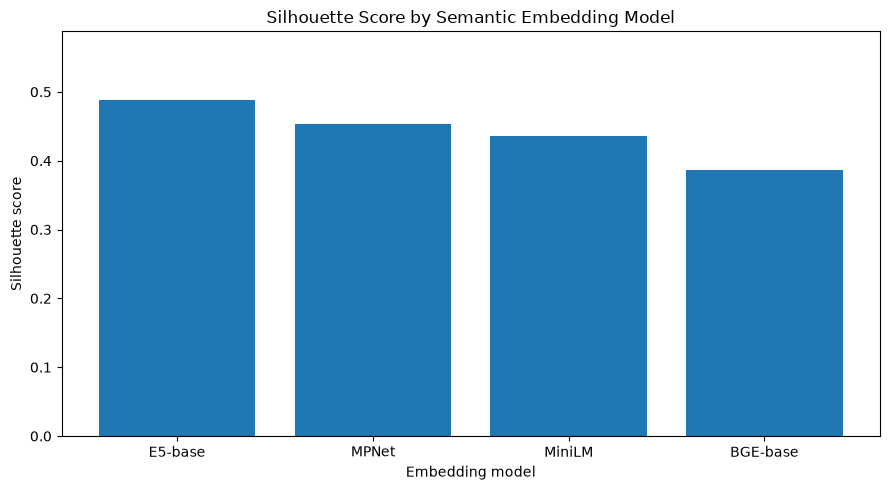

In [146]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    embedding_comparison_df[
        "Embedding_Model"
    ],
    embedding_comparison_df[
        "Silhouette"
    ]
)

plt.title(
    "Silhouette Score by Semantic Embedding Model"
)

plt.xlabel("Embedding model")
plt.ylabel("Silhouette score")
plt.ylim(
    0,
    max(
        embedding_comparison_df[
            "Silhouette"
        ]
    ) + 0.1
)

plt.tight_layout()
plt.show() 

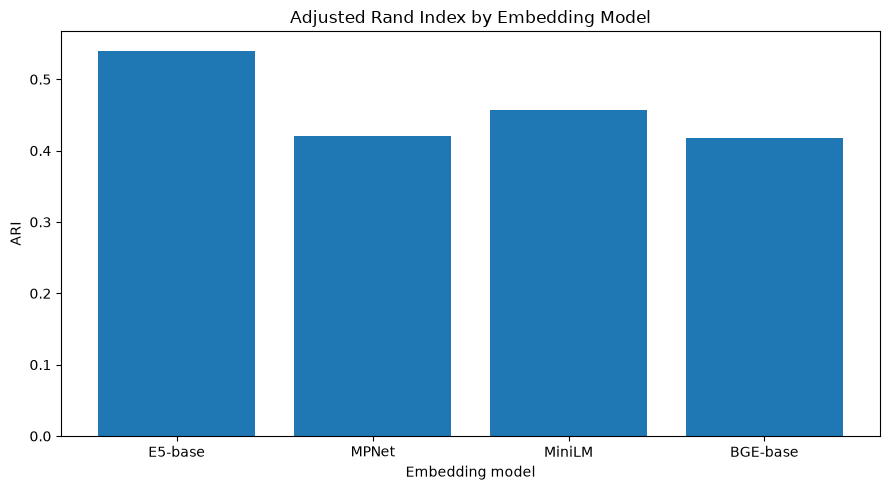

In [148]:
# ARI comparison
plt.figure(figsize=(9, 5))

plt.bar(
    embedding_comparison_df[
        "Embedding_Model"
    ],
    embedding_comparison_df[
        "ARI"
    ]
)

plt.title(
    "Adjusted Rand Index by Embedding Model"
)

plt.xlabel("Embedding model")
plt.ylabel("ARI")

plt.tight_layout()
plt.show() 

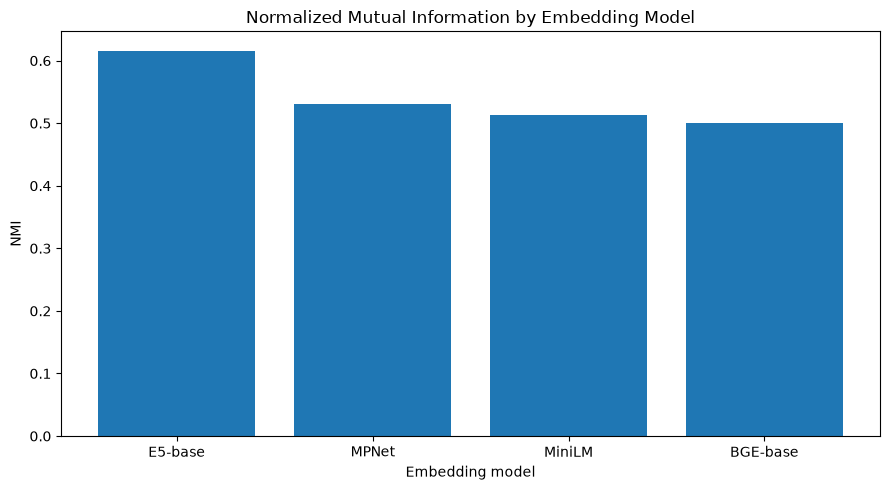

In [150]:
# NMI comparison 
plt.figure(figsize=(9, 5))

plt.bar(
    embedding_comparison_df[
        "Embedding_Model"
    ],
    embedding_comparison_df[
        "NMI"
    ]
)

plt.title(
    "Normalized Mutual Information by Embedding Model"
)

plt.xlabel("Embedding model")
plt.ylabel("NMI")

plt.tight_layout()
plt.show() 

Step 59: Generate 2D UMAP visualization for the best model 

In [152]:
best_embedding_config = (
    embedding_models[
        best_embedding_name
    ]
)

best_embeddings = generate_or_load_embeddings(
    display_name=best_embedding_name,
    model_name=best_embedding_config[
        "model_name"
    ],
    texts=email_texts,
    prefix=best_embedding_config[
        "prefix"
    ],
    batch_size=32
) 

E5-base: loaded saved embeddings (17319, 768)


In [156]:
# Create a two-dimensional projection: 
best_visualizer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="cosine",
    random_state=2
)

best_embedding_2d = (
    best_visualizer.fit_transform(
        best_embeddings
    )
)

C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [157]:
# Retrieve cluster labels: 
best_cluster_labels = (
    embedding_cluster_labels[
        best_embedding_name
    ]
) 

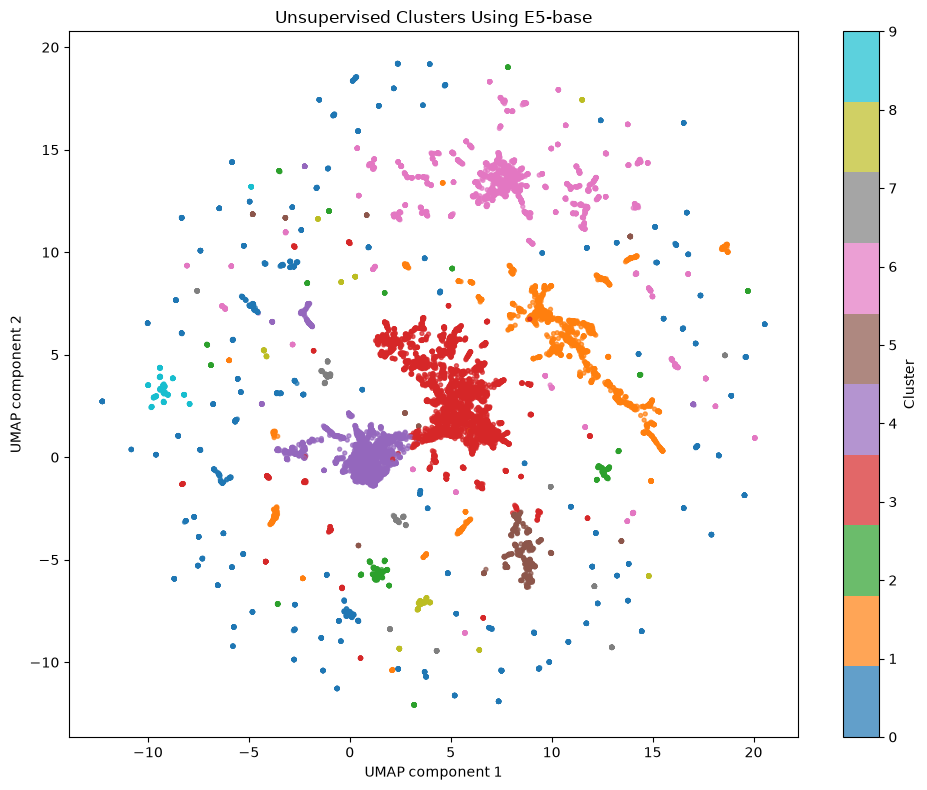

In [158]:
# Plot discovered clusters: 
plt.figure(figsize=(10, 8))

plt.scatter(
    best_embedding_2d[:, 0],
    best_embedding_2d[:, 1],
    c=best_cluster_labels,
    s=8,
    alpha=0.7,
    cmap="tab10"
)

plt.title(
    f"Unsupervised Clusters Using {best_embedding_name}"
)

plt.xlabel("UMAP component 1")
plt.ylabel("UMAP component 2")

plt.colorbar(label="Cluster")

plt.tight_layout()
plt.show() 

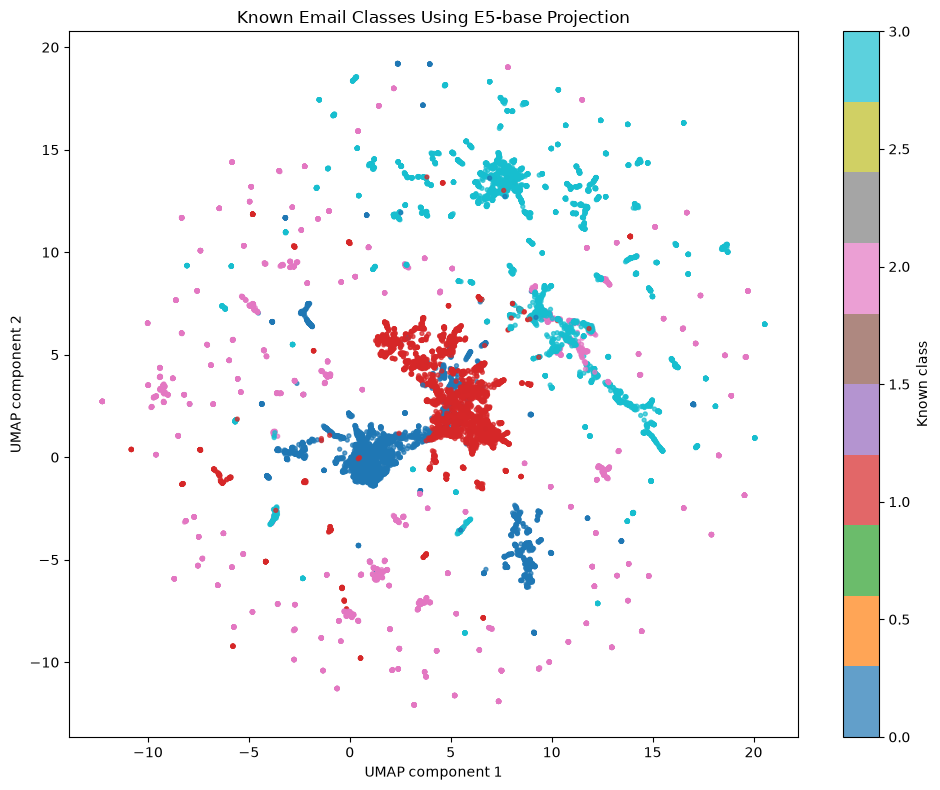

In [159]:
# Plot known labels for interpretation only: 
plt.figure(figsize=(10, 8))

plt.scatter(
    best_embedding_2d[:, 0],
    best_embedding_2d[:, 1],
    c=true_labels,
    s=8,
    alpha=0.7,
    cmap="tab10"
)

plt.title(
    f"Known Email Classes Using {best_embedding_name} Projection"
)

plt.xlabel("UMAP component 1")
plt.ylabel("UMAP component 2")

plt.colorbar(label="Known class")

plt.tight_layout()
plt.show() 

Step 60: Cluster-versus-class heatmap 

In [160]:
import seaborn as sns

cluster_class_table = pd.crosstab(
    best_cluster_labels,
    true_labels,
    rownames=["Discovered Cluster"],
    colnames=["Known Class"]
)

cluster_class_table 

Known Class,0,1,2,3
Discovered Cluster,,,,
0,68,140,1621,294
1,11,98,1029,1800
2,4,0,537,0
3,569,4168,0,22
4,2655,6,18,0
5,684,34,0,0
6,7,8,0,2749
7,0,0,301,0
8,0,0,250,0


In [161]:
# Normalize each cluster: 
cluster_class_normalized = (
    pd.crosstab(
        best_cluster_labels,
        true_labels,
        normalize="index"
    )
) 

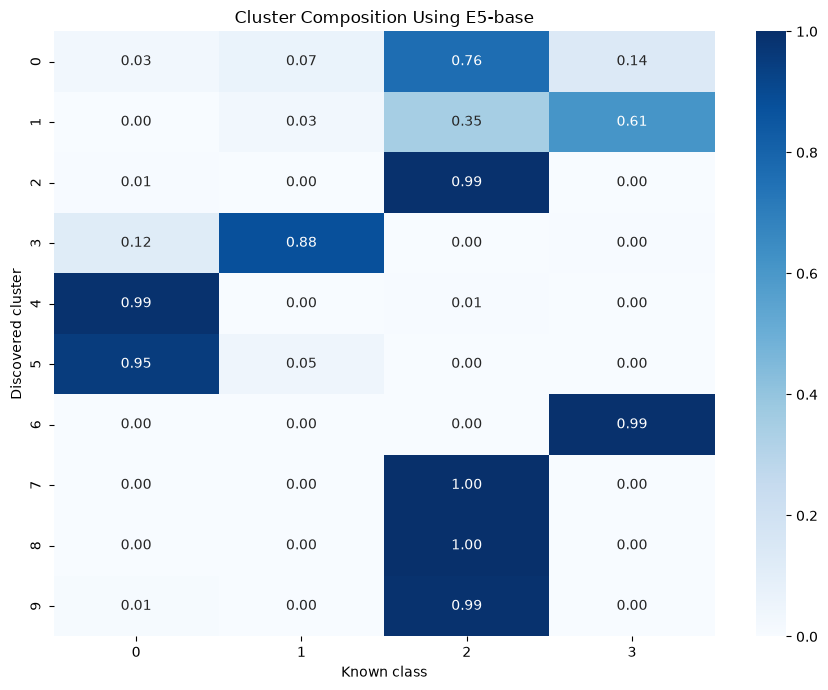

In [162]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cluster_class_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.title(
    f"Cluster Composition Using {best_embedding_name}"
)

plt.xlabel("Known class")
plt.ylabel("Discovered cluster")

plt.tight_layout()
plt.show() 

Step 61: Cluster size distribution

In [163]:
import matplotlib.pyplot as plt
import seaborn as sns

cluster_distribution = (
    pd.Series(best_cluster_labels)
    .value_counts()
    .sort_index()
)

print(cluster_distribution) 

0    2123
1    2938
2     541
3    4759
4    2679
5     718
6    2764
7     301
8     250
9     246
Name: count, dtype: int64


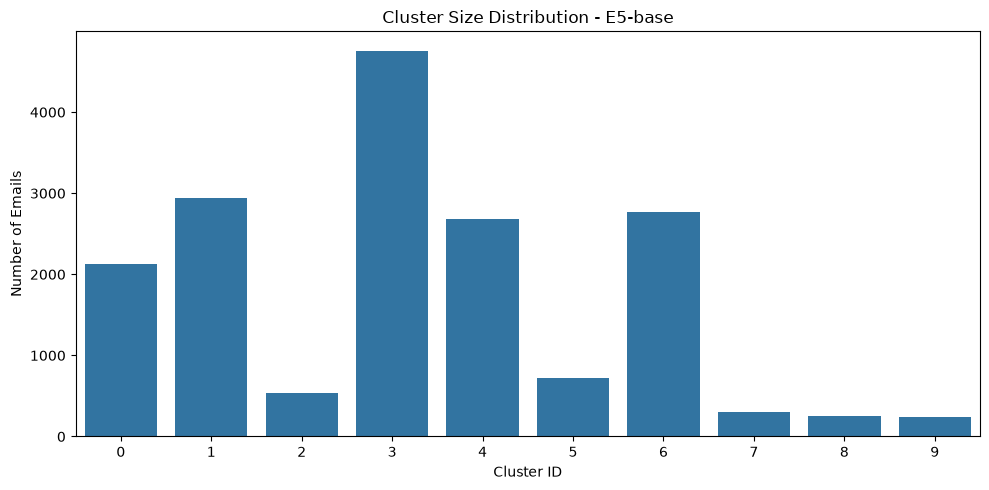

In [164]:
plt.figure(figsize=(10,5))

sns.barplot(
    x=cluster_distribution.index,
    y=cluster_distribution.values
)

plt.title(
    f"Cluster Size Distribution - {best_embedding_name}"
)

plt.xlabel("Cluster ID")

plt.ylabel("Number of Emails")

plt.tight_layout()

plt.show() 

Step 62: Add cluster labels back to dataframe

In [165]:
df_cluster_analysis = df.copy()

df_cluster_analysis["cluster"] = (
    best_cluster_labels
)

df_cluster_analysis.head() 

,text,attachment_paths,label,attachment_text,combined_text,embedding_text,word_count,KMeans_cluster,cluster
0,Header: Urgent Account Verification Required -...,attachments\hr_policy.docx,3,NaN,[EMAIL_BODY] Header: Urgent Account Verificati...,[EMAIL_BODY] Header: Urgent Account Verificati...,144,2,1
1,Header: Important Security Update - Take Actio...,attachments\invoice.pdf,3,NaN,[EMAIL_BODY] Header: Important Security Update...,[EMAIL_BODY] Header: Important Security Update...,140,2,1
2,Header: Account Verification Required - Immedi...,attachments\verify.png,3,NaN,[EMAIL_BODY] Header: Account Verification Requ...,[EMAIL_BODY] Header: Account Verification Requ...,139,2,1
3,Header: Urgent Action Required - Security Aler...,NaN,3,NaN,[EMAIL_BODY] Header: Urgent Action Required - ...,[EMAIL_BODY] Header: Urgent Action Required - ...,135,2,1
4,Header: Account Access Suspended - Immediate V...,NaN,3,NaN,[EMAIL_BODY] Header: Account Access Suspended ...,[EMAIL_BODY] Header: Account Access Suspended ...,131,2,1


Step 63: Count class composition inside each cluster

In [166]:
cluster_summary = pd.crosstab(
    df_cluster_analysis["cluster"],
    df_cluster_analysis["label"]
)

cluster_summary 

label,0,1,2,3
cluster,,,,
0,68,140,1621,294
1,11,98,1029,1800
2,4,0,537,0
3,569,4168,0,22
4,2655,6,18,0
5,684,34,0,0
6,7,8,0,2749
7,0,0,301,0
8,0,0,250,0


In [168]:
# Rename columns:
cluster_summary.columns = [
    "Human-Ham",
    "Human-Phish",
    "AI-Ham",
    "AI-Phish"
]

cluster_summary 

,Human-Ham,Human-Phish,AI-Ham,AI-Phish
cluster,,,,
0,68,140,1621,294
1,11,98,1029,1800
2,4,0,537,0
3,569,4168,0,22
4,2655,6,18,0
5,684,34,0,0
6,7,8,0,2749
7,0,0,301,0
8,0,0,250,0


Step 64: Calculate dominant class per cluster

In [169]:
cluster_dominance = (
    cluster_summary
    .div(
        cluster_summary.sum(axis=1),
        axis=0
    )
)

cluster_dominance 

,Human-Ham,Human-Phish,AI-Ham,AI-Phish
cluster,,,,
0,0.032030,0.065944,0.763542,0.138483
1,0.003744,0.033356,0.350238,0.612662
2,0.007394,0.000000,0.992606,0.000000
3,0.119563,0.875814,0.000000,0.004623
4,0.991041,0.002240,0.006719,0.000000
5,0.952646,0.047354,0.000000,0.000000
6,0.002533,0.002894,0.000000,0.994573
7,0.000000,0.000000,1.000000,0.000000
8,0.000000,0.000000,1.000000,0.000000


In [170]:
# Find dominant class: 

dominant_class = (
    cluster_dominance
    .idxmax(axis=1)
)

dominant_percentage = (
    cluster_dominance
    .max(axis=1)
)

cluster_interpretation = pd.DataFrame({

    "Dominant_Class":
        dominant_class,

    "Dominant_Percentage":
        dominant_percentage.round(3)

})

cluster_interpretation 

,Dominant_Class,Dominant_Percentage
cluster,,
0,AI-Ham,0.764
1,AI-Phish,0.613
2,AI-Ham,0.993
3,Human-Phish,0.876
4,Human-Ham,0.991
5,Human-Ham,0.953
6,AI-Phish,0.995
7,AI-Ham,1.000
8,AI-Ham,1.000


Step 65: Extract representative emails from each cluster

In [171]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np 

In [172]:
cluster_examples = {}

for cluster_id in sorted(
    np.unique(best_cluster_labels)
):

    cluster_indices = np.where(
        best_cluster_labels == cluster_id
    )[0]

    cluster_vectors = (
        best_embeddings[
            cluster_indices
        ]
    )

    center = (
        cluster_vectors.mean(axis=0)
        .reshape(1,-1)
    )

    similarity = cosine_similarity(
        cluster_vectors,
        center
    )

    closest_index = (
        cluster_indices[
            similarity.argmax()
        ]
    )

    cluster_examples[cluster_id] = (
        closest_index
    )


cluster_examples 

{np.int64(0): np.int64(14772),
 np.int64(1): np.int64(3717),
 np.int64(2): np.int64(15134),
 np.int64(3): np.int64(16930),
 np.int64(4): np.int64(9225),
 np.int64(5): np.int64(1114),
 np.int64(6): np.int64(7825),
 np.int64(7): np.int64(15934),
 np.int64(8): np.int64(14908),
 np.int64(9): np.int64(15279)}

Step 66: Display representative emails 

In [173]:
for cluster_id, index in cluster_examples.items():

    print("="*80)

    print(
        "CLUSTER:",
        cluster_id
    )

    print(
        "TRUE LABEL:",
        df.loc[index,"label"]
    )

    print(
        "\nEMAIL TEXT:\n"
    )

    print(
        df.loc[index,"text"][:1000]
    )
 

CLUSTER: 0
TRUE LABEL: 2

EMAIL TEXT:

Subject: Schedule confirmation

Hi team, sharing the latest notes from today's sync. Next steps are attached in the document. Let me know your thoughts.

Appreciate your feedback on this draft.

Best,
Cameron Nguyen
CLUSTER: 1
TRUE LABEL: 2

EMAIL TEXT:

Dear Sarah, We hope this email finds you well. I'm Emily Johnson, and I'm reaching out to you regarding an urgent matter concerning your account. To ensure the security of your account and prevent unauthorized access, we require you to verify your account information immediately. Please click here to proceed with the verification process: [https://account-verification-link.com/sarahwilliams] Your prompt attention to this matter is greatly appreciated. If you have any questions or concerns, please don't hesitate to contact our support team. Thank you for your cooperation. Best regards, Emily Johnson
CLUSTER: 2
TRUE LABEL: 2

EMAIL TEXT:

Subject: Documentation review

Quick reminder about the train

Step 67: Extract most frequent words per cluster

In [181]:
from collections import Counter

def top_words_cluster(cluster_id, n_words=20):

    texts = (
        df_cluster_analysis[
            df_cluster_analysis["cluster"] == cluster_id
        ]["embedding_text"]
        .astype(str)
    )

    words = (
        " ".join(texts)
        .split()
    )

    return Counter(words).most_common(n_words)

In [182]:
for cluster in sorted(
    df_cluster_analysis["cluster"].unique()
):

    print("\nCluster:", cluster)

    print(
        top_words_cluster(cluster)
    ) 


Cluster: 0
[('_', 8276), ('the', 4714), ('in', 4199), ('Added:', 4138), ('Submission-ID:', 4066), ('Sender:', 4066), ('as', 4056), ('No', 4048), ('Submission', 4039), ('notes:', 4039), ('Virus', 3748), ('Total', 3185), ('Same', 3154), ('Submission-ID', 3154), ('for', 2412), ('[EMAIL_BODY]', 2123), ('[ATTACHMENT_TEXT]', 2123), ('Subject:', 1909), ('Best,', 1621), ('your', 1548)]

Cluster: 1
[('to', 10907), ('your', 8752), ('the', 8090), ('you', 7572), ('and', 7252), ('for', 4065), ('our', 3773), ('a', 3444), ('this', 3408), ('of', 3390), ('in', 3123), ('[EMAIL_BODY]', 2938), ('[ATTACHMENT_TEXT]', 2938), ('on', 2756), ('Dear', 2304), ('is', 2295), ('please', 2059), ('I', 2013), ('account', 1982), ('have', 1976)]

Cluster: 2
[('the', 1553), ('[EMAIL_BODY]', 541), ('[ATTACHMENT_TEXT]', 541), ('Subject:', 538), ('Best,', 537), ('are', 513), ('for', 511), ('Thanks', 364), ('session', 330), ('in', 319), ('to', 317), ('training', 295), ('Quick', 293), ('reminder', 293), ('about', 293), ('tomo

Step 68: Save cluster interpretation table

In [183]:
cluster_interpretation_path = os.path.join(
    BASE_DIR,
    "cluster_interpretation_summary.csv"
)

cluster_interpretation.to_csv(
    cluster_interpretation_path
)

print(
    "Saved:",
    cluster_interpretation_path
) 

Saved: C:\Users\hmari\ai-generated-phishing-detection-multimodal\cluster_interpretation_summary.csv


Step 69: Prepare three input modalities 

In [184]:
# Email body only
df["email_only_text"] = (
    df["text"]
    .fillna("")
    .astype(str)
)


# Attachment text only
df["attachment_only_text"] = (
    df["attachment_text"]
    .fillna("")
    .astype(str)
)


# Multimodal text
df["multimodal_text"] = (
    df["text"]
    .fillna("")
    .astype(str)
    +
    " "
    +
    df["attachment_text"]
    .fillna("")
    .astype(str)
)


print(df[
    [
        "email_only_text",
        "attachment_only_text",
        "multimodal_text"
    ]
].head()) 

                                     email_only_text attachment_only_text  \
0  Header: Urgent Account Verification Required -...                        
1  Header: Important Security Update - Take Actio...                        
2  Header: Account Verification Required - Immedi...                        
3  Header: Urgent Action Required - Security Aler...                        
4  Header: Account Access Suspended - Immediate V...                        

                                     multimodal_text  
0  Header: Urgent Account Verification Required -...  
1  Header: Important Security Update - Take Actio...  
2  Header: Account Verification Required - Immedi...  
3  Header: Urgent Action Required - Security Aler...  
4  Header: Account Access Suspended - Immediate V...  


Step 70: Create ablation experiment dictionary

In [185]:
ablation_inputs = {

    "Email_Body_Only":
        df["email_only_text"].tolist(),

    "Attachment_Only":
        df["attachment_only_text"].tolist(),

    "Multimodal_Text":
        df["multimodal_text"].tolist()

} 

Step 71: Create storage for results 

In [186]:
ablation_results = []

ablation_embeddings = {}

ablation_clusters = {} 

Step 72: Function for ablation experiment 

In [187]:
def run_ablation_experiment(
    experiment_name,
    texts
):

    print("="*70)
    print("Running:", experiment_name)
    print("="*70)


    # Load Sentence-BERT model
    model = SentenceTransformer(
        "sentence-transformers/all-MiniLM-L6-v2"
    )


    # Generate embeddings
    embeddings = model.encode(
        texts,
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )


    print(
        "Embedding shape:",
        embeddings.shape
    )


    # UMAP reduction

    reducer = umap.UMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=50,
        metric="cosine",
        random_state=2
    )


    reduced_embeddings = (
        reducer.fit_transform(
            embeddings
        )
    )


    print(
        "UMAP shape:",
        reduced_embeddings.shape
    )


    # Fixed clustering

    clustering_model = AgglomerativeClustering(
        n_clusters=10,
        linkage="ward",
        metric="euclidean"
    )


    cluster_labels = (
        clustering_model
        .fit_predict(
            reduced_embeddings
        )
    )


    # Evaluation

    result = calculate_internal_metrics(
        reduced_embeddings,
        cluster_labels
    )


    external = calculate_external_metrics(
        true_labels,
        cluster_labels
    )


    result.update(external)


    result["Experiment"] = (
        experiment_name
    )


    # Save objects

    ablation_embeddings[
        experiment_name
    ] = reduced_embeddings


    ablation_clusters[
        experiment_name
    ] = cluster_labels


    return result 

Step 73: Run all ablation experiments

In [188]:
for name, texts in ablation_inputs.items():

    result = run_ablation_experiment(
        name,
        texts
    )

    ablation_results.append(
        result
    ) 

Running: Email_Body_Only


Loading weights: 100%|█████████████████████| 103/103 [00:00<00:00, 317.24it/s, Materializing param=pooler.dense.weight]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches:  99%|██████████████████████████████████████████████████████████████████████▍| 538/542 [09:35<00:00,  5.54it/s]


Embedding shape: (17319, 384)


C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (17319, 50)
Running: Attachment_Only


Loading weights: 100%|█████████████████████| 103/103 [00:00<00:00, 338.94it/s, Materializing param=pooler.dense.weight]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches: 100%|███████████████████████████████████████████████████████████████████████| 542/542 [01:07<00:00,  8.05it/s]
C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Embedding shape: (17319, 384)
UMAP shape: (17319, 50)
Running: Multimodal_Text


Loading weights: 100%|█████████████████████| 103/103 [00:00<00:00, 366.60it/s, Materializing param=pooler.dense.weight]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches: 100%|███████████████████████████████████████████████████████████████████████| 542/542 [10:31<00:00,  1.17s/it]
C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Embedding shape: (17319, 384)
UMAP shape: (17319, 50)


Step 74: Create ablation results table

In [189]:
ablation_results_df = pd.DataFrame(
    ablation_results
)


ablation_results_df = (
    ablation_results_df
    [
        [
            "Experiment",
            "Clusters",
            "Silhouette",
            "Davies_Bouldin",
            "Calinski_Harabasz",
            "ARI",
            "NMI",
            "Homogeneity",
            "Completeness",
            "V_measure"
        ]
    ]
    .round(4)
)


ablation_results_df 

,Experiment,Clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Homogeneity,Completeness,V_measure
0,Email_Body_Only,10,0.2511,2.3001,1105.2924,0.3124,0.4001,0.5075,0.3303,0.4001
1,Attachment_Only,10,0.7763,0.9289,16465.7383,0.0646,0.2610,0.1981,0.3826,0.2610
2,Multimodal_Text,10,0.4296,1.5961,3475.1507,0.4636,0.5264,0.6555,0.4398,0.5264


Step 75: Save results 

In [190]:
ablation_results_df.to_csv(
    os.path.join(
        BASE_DIR,
        "unsupervised_ablation_results.csv"
    ),
    index=False
)

print(
    "Ablation study saved."
) 

Ablation study saved.


Step 76: Visual comparison

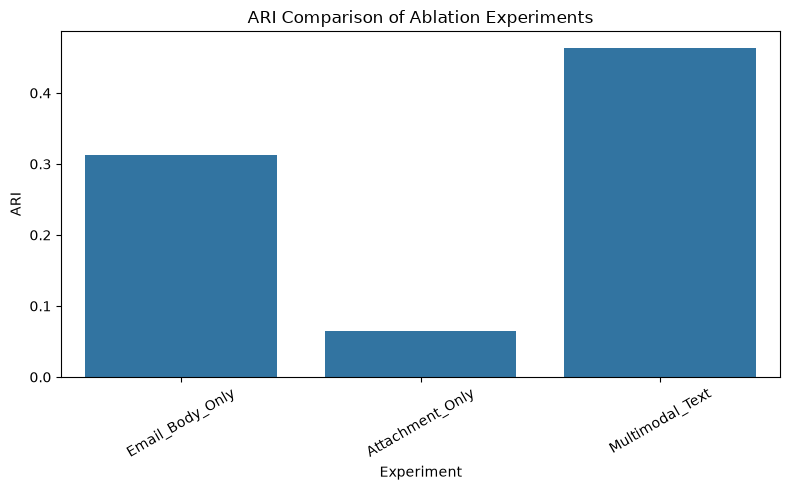

In [192]:
# ARI comparison 
plt.figure(figsize=(8,5))

sns.barplot(
    data=ablation_results_df,
    x="Experiment",
    y="ARI"
)

plt.title(
    "ARI Comparison of Ablation Experiments"
)

plt.xticks(rotation=30)

plt.tight_layout()

plt.show() 

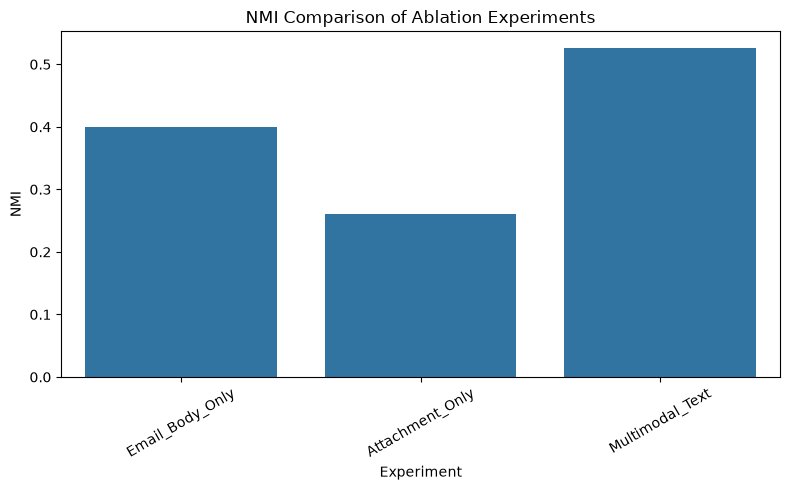

In [193]:
# NMI comparison 

plt.figure(figsize=(8,5))

sns.barplot(
    data=ablation_results_df,
    x="Experiment",
    y="NMI"
)

plt.title(
    "NMI Comparison of Ablation Experiments"
)

plt.xticks(rotation=30)

plt.tight_layout()

plt.show() 

Step 77: Robustness Analysis (Repeated UMAP + Clustering) 

Step 77.1: Define random seeds

In [194]:
robustness_seeds = [
    1,
    2,
    3,
    4,
    5,
    10,
    20,
    42,
    50,
    100
] 

Step 77.2: Prepare final multimodal text

In [195]:
robustness_texts = (
    df["multimodal_text"]
    .fillna("")
    .astype(str)
    .tolist()
)

true_labels = (
    df["label"]
    .astype(int)
    .to_numpy()
) 

Step 77.3: Load embedding model once

In [196]:
robustness_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
) 

Loading weights: 100%|█████████████████████| 103/103 [00:00<00:00, 483.19it/s, Materializing param=pooler.dense.weight]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [197]:
# Generate embeddings once because only UMAP/clustering randomness is tested. 

robustness_embeddings = (
    robustness_model.encode(
        robustness_texts,
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )
)

print(
    robustness_embeddings.shape
) 

Batches: 100%|███████████████████████████████████████████████████████████████████████| 542/542 [10:36<00:00,  1.17s/it]


(17319, 384)


Step 77.4: Create storage 

In [198]:
robustness_results = [] 

Step 77.5: Run repeated experiments 

In [199]:
for seed in robustness_seeds:

    print("="*60)
    print("Running seed:", seed)
    print("="*60)


    # UMAP

    reducer = umap.UMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=50,
        metric="cosine",
        random_state=seed
    )


    reduced_embeddings = (
        reducer.fit_transform(
            robustness_embeddings
        )
    )


    # Fixed clustering

    clustering_model = AgglomerativeClustering(
        n_clusters=10,
        linkage="ward",
        metric="euclidean"
    )


    cluster_labels = (
        clustering_model
        .fit_predict(
            reduced_embeddings
        )
    )


    # Internal metrics

    internal_metrics = (
        calculate_internal_metrics(
            reduced_embeddings,
            cluster_labels
        )
    )


    # External metrics

    external_metrics = (
        calculate_external_metrics(
            true_labels,
            cluster_labels
        )
    )


    # Combine results

    result = {}

    result.update(
        internal_metrics
    )

    result.update(
        external_metrics
    )

    result["Seed"] = seed


    robustness_results.append(
        result
    ) 

Running seed: 1


C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Running seed: 2


C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Running seed: 3


...

C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Running seed: 50


C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Running seed: 100


C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Step 77.6: Create robustness table

In [200]:
robustness_df = pd.DataFrame(
    robustness_results
)


robustness_df = robustness_df[
    [
        "Seed",
        "Clusters",
        "Silhouette",
        "Davies_Bouldin",
        "Calinski_Harabasz",
        "ARI",
        "NMI",
        "Homogeneity",
        "Completeness",
        "V_measure"
    ]
]


robustness_df.round(4) 

,Seed,Clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,Homogeneity,Completeness,V_measure
0,1,10,0.4405,1.6082,3639.9877,0.4402,0.5098,0.6368,0.4250,0.5098
1,2,10,0.4296,1.5961,3475.1507,0.4636,0.5264,0.6555,0.4398,0.5264
2,3,10,0.4274,2.0303,3327.3895,0.4477,0.5261,0.6726,0.4320,0.5261
3,4,10,0.4321,1.6511,3557.5297,0.4531,0.5157,0.6497,0.4275,0.5157
4,5,10,0.4233,1.5635,3446.7706,0.4636,0.5259,0.6578,0.4380,0.5259
5,10,10,0.4409,2.0370,3587.0378,0.4464,0.5150,0.6535,0.4250,0.5150
6,20,10,0.4394,2.0533,3450.3037,0.4508,0.5297,0.6724,0.4369,0.5297
7,42,10,0.4240,2.0301,3530.5057,0.4269,0.5025,0.6393,0.4139,0.5025
8,50,10,0.4326,1.5679,3699.4839,0.4575,0.5223,0.6587,0.4326,0.5223
9,100,10,0.4389,1.5734,3642.1101,0.4407,0.5069,0.6430,0.4183,0.5069


Step 77.7: Calculate Mean ± Standard Deviation 

In [201]:
# This is the table you will report in your thesis.

robustness_summary = pd.DataFrame({

    "Metric":
    [
        "Silhouette",
        "Davies_Bouldin",
        "Calinski_Harabasz",
        "ARI",
        "NMI",
        "Homogeneity",
        "Completeness",
        "V_measure"
    ],


    "Mean":
    [
        robustness_df["Silhouette"].mean(),
        robustness_df["Davies_Bouldin"].mean(),
        robustness_df["Calinski_Harabasz"].mean(),
        robustness_df["ARI"].mean(),
        robustness_df["NMI"].mean(),
        robustness_df["Homogeneity"].mean(),
        robustness_df["Completeness"].mean(),
        robustness_df["V_measure"].mean()
    ],


    "Std":
    [
        robustness_df["Silhouette"].std(),
        robustness_df["Davies_Bouldin"].std(),
        robustness_df["Calinski_Harabasz"].std(),
        robustness_df["ARI"].std(),
        robustness_df["NMI"].std(),
        robustness_df["Homogeneity"].std(),
        robustness_df["Completeness"].std(),
        robustness_df["V_measure"].std()
    ]

})


robustness_summary 

,Metric,Mean,Std
0,Silhouette,0.432860,0.006772
1,Davies_Bouldin,1.771086,0.230837
2,Calinski_Harabasz,3535.626943,112.755255
3,ARI,0.449042,0.011365
4,NMI,0.518016,0.009417
5,Homogeneity,0.653957,0.012361
6,Completeness,0.428899,0.008558
7,V_measure,0.518016,0.009417


Step 77.8: Format as Mean ± Std 

In [203]:
# For paper reporting: 

robustness_summary["Mean ± Std"] = (
    robustness_summary["Mean"].round(4)
    .astype(str)
    +
    " ± "
    +
    robustness_summary["Std"].round(4)
    .astype(str)
)


robustness_summary[
    [
        "Metric",
        "Mean ± Std"
    ]
] 

,Metric,Mean ± Std
0,Silhouette,0.4329 ± 0.0068
1,Davies_Bouldin,1.7711 ± 0.2308
2,Calinski_Harabasz,3535.6269 ± 112.7553
3,ARI,0.449 ± 0.0114
4,NMI,0.518 ± 0.0094
5,Homogeneity,0.654 ± 0.0124
6,Completeness,0.4289 ± 0.0086
7,V_measure,0.518 ± 0.0094


Step 77.9: Save results

In [204]:
robustness_df.to_csv(
    os.path.join(
        BASE_DIR,
        "robustness_individual_runs.csv"
    ),
    index=False
)


robustness_summary.to_csv(
    os.path.join(
        BASE_DIR,
        "robustness_mean_std_results.csv"
    ),
    index=False
)


print(
    "Robustness analysis completed and saved."
) 

Robustness analysis completed and saved.


In [8]:
# -----------------------------------------------------New policy

import os
import pandas as pd

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

DATA_PATH = os.path.join(
    BASE_DIR,
    "data",
    "sample_emails.csv"
)

try:
    df = pd.read_csv(
        DATA_PATH,
        encoding="utf-8-sig"
    )
except UnicodeDecodeError:
    df = pd.read_csv(
        DATA_PATH,
        encoding="cp1252",
        encoding_errors="replace"
    )

df.columns = df.columns.str.strip()

df = df[
    ["text", "attachment_paths", "label"]
].copy()

df["text"] = (
    df["text"]
    .fillna("")
    .astype(str)
)

df["attachment_paths"] = (
    df["attachment_paths"]
    .fillna("")
    .astype(str)
)

df["label"] = pd.to_numeric(
    df["label"],
    errors="coerce"
)

df = df.dropna(
    subset=["label"]
)

df["label"] = df["label"].astype(int)

df = df[
    df["label"].isin([0, 1, 2, 3])
].reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df["label"].value_counts().sort_index()) 

Dataset shape: (17319, 3)
label
0    4000
1    4454
2    4000
3    4865
Name: count, dtype: int64


In [9]:
print(df.columns.tolist())
print(df.shape) 

['text', 'attachment_paths', 'label']
(17319, 3)


In [11]:
import os
import pandas as pd

UNSUPERVISED_DATA_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_processed_data.csv"
)

print("File exists:", os.path.exists(UNSUPERVISED_DATA_PATH))

if os.path.exists(UNSUPERVISED_DATA_PATH):
    processed_df = pd.read_csv(
        UNSUPERVISED_DATA_PATH,
        encoding="utf-8-sig"
    )

    print("Shape:", processed_df.shape)
    print("\nColumns:")
    print(processed_df.columns.tolist()) 

File exists: True
Shape: (17319, 7)

Columns:
['text', 'attachment_paths', 'label', 'attachment_text', 'combined_text', 'embedding_text', 'word_count']


In [12]:
# STEP 2B — Attachment text audit

# Identify samples with successfully extracted attachment text
attachment_only = processed_df[
    processed_df["attachment_text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
].copy()

# Word count of attachment-derived text only
attachment_only["attachment_word_count"] = (
    attachment_only["attachment_text"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

print("=" * 60)
print("ATTACHMENT TEXT AUDIT")
print("=" * 60)

print(
    "Total emails:",
    len(processed_df)
)

print(
    "Emails with extracted attachment text:",
    len(attachment_only)
)

print(
    "Percentage with extracted attachment text:",
    round(
        len(attachment_only) / len(processed_df) * 100,
        2
    ),
    "%"
)

print("\nAttachment-text word-count statistics:")
print(
    attachment_only["attachment_word_count"].describe()
)

print(
    "\nMean attachment-text words:",
    round(
        attachment_only["attachment_word_count"].mean(),
        2
    )
)

print(
    "Median attachment-text words:",
    round(
        attachment_only["attachment_word_count"].median(),
        2
    )
) 

ATTACHMENT TEXT AUDIT
Total emails: 17319
Emails with extracted attachment text: 3000
Percentage with extracted attachment text: 17.32 %

Attachment-text word-count statistics:
count    3000.000000
mean       36.592000
std         6.993462
min        17.000000
25%        32.000000
50%        36.000000
75%        41.000000
max        60.000000
Name: attachment_word_count, dtype: float64

Mean attachment-text words: 36.59
Median attachment-text words: 36.0


In [14]:
# STEP 2C — Attachment file-type distribution

from collections import Counter
import os

def get_attachment_extensions(value):
    paths = parse_attachment_paths(value)

    extensions = []

    for path in paths:
        ext = os.path.splitext(path)[1].lower().lstrip(".")

        if ext:
            extensions.append(ext)

    return extensions


processed_df["attachment_extensions"] = (
    processed_df["attachment_paths"]
    .apply(get_attachment_extensions)
)

# Flatten all attachment extensions
all_extensions = [
    ext
    for ext_list in processed_df["attachment_extensions"]
    for ext in ext_list
]

extension_counts = Counter(all_extensions)

extension_df = pd.DataFrame(
    extension_counts.items(),
    columns=["File_Type", "Count"]
).sort_values(
    "Count",
    ascending=False
).reset_index(drop=True)

extension_df["Percentage"] = (
    extension_df["Count"]
    / extension_df["Count"].sum()
    * 100
)

print("=" * 60)
print("ATTACHMENT FILE-TYPE DISTRIBUTION")
print("=" * 60)

print(extension_df.round(2))

print("\nTotal attachment files:",
      extension_df["Count"].sum()) 

NameError: name 'parse_attachment_paths' is not defined

In [15]:
# STEP 2C — Attachment file-type distribution
# No dependency on parse_attachment_paths()

import os
import ast
from collections import Counter
import pandas as pd


def get_attachment_extensions(value):

    if pd.isna(value):
        return []

    value = str(value).strip()

    if value == "" or value.lower() in ["nan", "none", "null"]:
        return []

    paths = []

    # Handle list-like strings
    try:
        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            paths = [str(p).strip() for p in parsed]

    except (ValueError, SyntaxError):
        pass

    # Handle semicolon-separated paths
    if not paths:

        if ";" in value:
            paths = [
                p.strip()
                for p in value.split(";")
                if p.strip()
            ]
        else:
            paths = [value]

    extensions = []

    for path in paths:

        ext = os.path.splitext(path)[1].lower().lstrip(".")

        if ext:
            extensions.append(ext)

    return extensions


# Extract extensions
processed_df["attachment_extensions"] = (
    processed_df["attachment_paths"]
    .apply(get_attachment_extensions)
)


# Flatten all extensions
all_extensions = [
    ext
    for ext_list in processed_df["attachment_extensions"]
    for ext in ext_list
]


# Count file types
extension_counts = Counter(all_extensions)


# Create table
extension_df = pd.DataFrame(
    extension_counts.items(),
    columns=["File_Type", "Count"]
).sort_values(
    "Count",
    ascending=False
).reset_index(drop=True)


# Calculate percentage
extension_df["Percentage"] = (
    extension_df["Count"]
    / extension_df["Count"].sum()
    * 100
)


print("=" * 60)
print("ATTACHMENT FILE-TYPE DISTRIBUTION")
print("=" * 60)

print(extension_df.round(2))

print(
    "\nTotal attachment files:",
    extension_df["Count"].sum()
)

print(
    "\nEmails with attachment paths:",
    processed_df["attachment_extensions"]
    .apply(lambda x: len(x) > 0)
    .sum()
) 

ATTACHMENT FILE-TYPE DISTRIBUTION
  File_Type  Count  Percentage
0      docx   1001       33.33
1       pdf   1001       33.33
2       jpg    600       19.98
3       png    401       13.35

Total attachment files: 3003

Emails with attachment paths: 3003


In [18]:
import os
import numpy as np

EMBEDDING_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_email_embeddings.npy"
)

print(
    "Embedding file exists:",
    os.path.exists(EMBEDDING_PATH)
)

if os.path.exists(EMBEDDING_PATH):

    embeddings = np.load(
        EMBEDDING_PATH
    )

    print(
        "Embedding shape:",
        embeddings.shape
    )

Embedding file exists: True
Embedding shape: (17319, 384)


In [19]:
# STEP 3A — Exact duplicate audit

import pandas as pd

# Normalize text only for duplicate detection
duplicate_text = (
    processed_df["embedding_text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Exact duplicate mask
exact_duplicate_mask = duplicate_text.duplicated(
    keep=False
)

# Number of rows belonging to duplicated text groups
duplicate_rows = exact_duplicate_mask.sum()

# Number of unique duplicated text values
duplicate_groups = (
    duplicate_text[exact_duplicate_mask]
    .nunique()
)

# Number of rows that are additional copies
additional_duplicate_rows = (
    duplicate_rows - duplicate_groups
)

print("=" * 60)
print("EXACT DUPLICATE AUDIT")
print("=" * 60)

print(
    "Total emails:",
    len(processed_df)
)

print(
    "Rows belonging to exact-duplicate groups:",
    duplicate_rows
)

print(
    "Unique exact-duplicate groups:",
    duplicate_groups
)

print(
    "Additional duplicate copies:",
    additional_duplicate_rows
)

print(
    "Percentage of rows in duplicate groups:",
    round(
        duplicate_rows / len(processed_df) * 100,
        2
    ),
    "%"
)

print(
    "Percentage of additional duplicate copies:",
    round(
        additional_duplicate_rows / len(processed_df) * 100,
        2
    ),
    "%"
) 

EXACT DUPLICATE AUDIT
Total emails: 17319
Rows belonging to exact-duplicate groups: 2053
Unique exact-duplicate groups: 978
Additional duplicate copies: 1075
Percentage of rows in duplicate groups: 11.85 %
Percentage of additional duplicate copies: 6.21 %


In [20]:
# Exact duplicate distribution by class

duplicate_class_summary = (
    processed_df.assign(
        exact_duplicate=exact_duplicate_mask
    )
    .groupby("label")
    .agg(
        Total=("label", "size"),
        Duplicate_Rows=("exact_duplicate", "sum")
    )
)

duplicate_class_summary["Percentage"] = (
    duplicate_class_summary["Duplicate_Rows"]
    / duplicate_class_summary["Total"]
    * 100
)

print(duplicate_class_summary.round(2)) 

       Total  Duplicate_Rows  Percentage
label                                   
0       4000             775       19.38
1       4454            1009       22.65
2       4000              52        1.30
3       4865             217        4.46


In [21]:
# STEP 3A-2 — Cross-class exact-duplicate audit

duplicate_groups_df = (
    processed_df
    .assign(
        normalized_text=(
            processed_df["embedding_text"]
            .fillna("")
            .astype(str)
            .str.strip()
            .str.lower()
        )
    )
    .groupby("normalized_text")
    .agg(
        Count=("label", "size"),
        Unique_Labels=("label", "nunique"),
        Labels=("label", lambda x: sorted(x.unique().tolist()))
    )
    .reset_index()
)

# Only groups containing more than one class
cross_class_duplicates = duplicate_groups_df[
    duplicate_groups_df["Unique_Labels"] > 1
].copy()

print("=" * 60)
print("CROSS-CLASS EXACT-DUPLICATE AUDIT")
print("=" * 60)

print(
    "Exact-duplicate groups:",
    len(duplicate_groups_df[
        duplicate_groups_df["Count"] > 1
    ])
)

print(
    "Cross-class duplicate groups:",
    len(cross_class_duplicates)
)

print(
    "Rows involved in cross-class duplicate groups:",
    cross_class_duplicates["Count"].sum()
)

print("\nCross-class duplicate groups:")
print(
    cross_class_duplicates[
        ["Count", "Unique_Labels", "Labels"]
    ].to_string(index=False)
) 

CROSS-CLASS EXACT-DUPLICATE AUDIT
Exact-duplicate groups: 978
Cross-class duplicate groups: 0
Rows involved in cross-class duplicate groups: 0

Cross-class duplicate groups:
Empty DataFrame
Columns: [Count, Unique_Labels, Labels]
Index: []


In [22]:
# STEP 3B-1 — Find saved embedding files

import os

print("Searching project directory for embedding files...\n")

for root, dirs, files in os.walk(BASE_DIR):

    for file in files:

        if file.lower().endswith((
            ".npy",
            ".npz",
            ".pkl",
            ".pickle"
        )):

            print(
                os.path.join(root, file)
            ) 

Searching project directory for embedding files...

C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_2d.npy
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_umap.npy
C:\Users\hmari\ai-generated-phishing-detection-multimodal\final_multimodal_phishing_model.pkl
C:\Users\hmari\ai-generated-phishing-detection-multimodal\tfidf_vectorizer.pkl
C:\Users\hmari\ai-generated-phishing-detection-multimodal\unsupervised_email_embeddings.npy
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\bge_base_embeddings.npy
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\bge_base_umap50.npy
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_embeddings.npy
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_umap50.npy
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\minilm_embeddings.np

In [23]:
# STEP 3B-1 — Verify E5-base embedding file

import os
import numpy as np

E5_EMBEDDING_PATH = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_embeddings.npy"
)

print(
    "E5-base embedding file exists:",
    os.path.exists(E5_EMBEDDING_PATH)
)

if os.path.exists(E5_EMBEDDING_PATH):

    e5_embeddings = np.load(
        E5_EMBEDDING_PATH
    )

    print(
        "E5-base embedding shape:",
        e5_embeddings.shape
    )

    print(
        "Number of dataset rows:",
        len(processed_df)
    ) 

E5-base embedding file exists: True
E5-base embedding shape: (17319, 768)
Number of dataset rows: 17319


In [24]:
# STEP 3B-2 — E5-base near-duplicate audit
# Criterion: cosine similarity > 0.95

import numpy as np
import pandas as pd

from sklearn.neighbors import NearestNeighbors


# ---------------------------------------------------------
# 1. Load the verified E5-base embeddings
# ---------------------------------------------------------

e5_embeddings = np.load(
    E5_EMBEDDING_PATH
).astype(
    np.float32
)

print(
    "Embedding shape:",
    e5_embeddings.shape
)


# ---------------------------------------------------------
# 2. Verify alignment with the dataset
# ---------------------------------------------------------

assert len(e5_embeddings) == len(processed_df), (
    "Embedding count does not match dataset rows."
)


# ---------------------------------------------------------
# 3. Normalize embeddings
# ---------------------------------------------------------
# For normalized vectors:
# cosine similarity = dot product
#
# sklearn NearestNeighbors with metric='cosine'
# directly returns cosine distance:
# cosine distance = 1 - cosine similarity

from sklearn.preprocessing import normalize

e5_normalized = normalize(
    e5_embeddings,
    norm="l2"
)


# ---------------------------------------------------------
# 4. Nearest-neighbor search
# ---------------------------------------------------------
# We search for the closest OTHER sample.
# n_neighbors=2 because the first neighbor is the
# sample itself.

nn = NearestNeighbors(
    n_neighbors=2,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

nn.fit(
    e5_normalized
)

distances, indices = nn.kneighbors(
    e5_normalized
)


# ---------------------------------------------------------
# 5. Convert cosine distance to cosine similarity
# ---------------------------------------------------------

nearest_cosine_similarity = (
    1 - distances[:, 1]
)


# ---------------------------------------------------------
# 6. Identify near-duplicate emails
# ---------------------------------------------------------

threshold = 0.95

near_duplicate_mask = (
    nearest_cosine_similarity > threshold
)

near_duplicate_indices = np.where(
    near_duplicate_mask
)[0]


# ---------------------------------------------------------
# 7. Summary
# ---------------------------------------------------------

total_emails = len(processed_df)

near_duplicate_emails = len(
    near_duplicate_indices
)

near_duplicate_percentage = (
    near_duplicate_emails
    / total_emails
    * 100
)


print("=" * 60)
print("E5-BASE NEAR-DUPLICATE AUDIT")
print("=" * 60)

print(
    "Total emails:",
    total_emails
)

print(
    "Cosine similarity threshold:",
    ">",
    threshold
)

print(
    "Emails with nearest-neighbor cosine similarity > 0.95:",
    near_duplicate_emails
)

print(
    "Percentage of emails:",
    round(
        near_duplicate_percentage,
        2
    ),
    "%"
)

print(
    "Maximum nearest-neighbor cosine similarity:",
    round(
        nearest_cosine_similarity.max(),
        6
    )
)

print(
    "Mean nearest-neighbor cosine similarity:",
    round(
        nearest_cosine_similarity.mean(),
        6
    )
) 

Embedding shape: (17319, 768)
E5-BASE NEAR-DUPLICATE AUDIT
Total emails: 17319
Cosine similarity threshold: > 0.95
Emails with nearest-neighbor cosine similarity > 0.95: 11221
Percentage of emails: 64.79 %
Maximum nearest-neighbor cosine similarity: 1.0
Mean nearest-neighbor cosine similarity: 0.955222


In [25]:
# STEP 3B-3 — Inspect exact-duplicate group sizes

duplicate_group_sizes = (
    processed_df
    .assign(
        normalized_text=(
            processed_df["embedding_text"]
            .fillna("")
            .astype(str)
            .str.strip()
            .str.lower()
        )
    )
    .groupby("normalized_text")
    .size()
    .sort_values(ascending=False)
)

duplicate_group_sizes = duplicate_group_sizes[
    duplicate_group_sizes > 1
]

print("=" * 60)
print("EXACT-DUPLICATE GROUP SIZE AUDIT")
print("=" * 60)

print(
    "Number of duplicate groups:",
    len(duplicate_group_sizes)
)

print(
    "Largest duplicate group:",
    duplicate_group_sizes.max()
)

print("\nTop 20 duplicate-group sizes:")
print(
    duplicate_group_sizes.head(20).to_string()
) 

EXACT-DUPLICATE GROUP SIZE AUDIT
Number of duplicate groups: 978
Largest duplicate group: 6

Top 20 duplicate-group sizes:
normalized_text
[email_body] ðÿ�‹ï¸�â€�â™‚ï¸� virtual workout session: stay active! hey leo, don't miss our virtual workout session to keep your fitness routine on track. click the link to participate and get moving: hxxps://virtualworkoutsignup.stayactive123.com let's sweat it out together! best, campus fitness center [attachment_text]                                                                                                                                      6
[email_body] important reminder: verify your course registration dear reese parker, your course registration requires verification to ensure accuracy. please click on the link to confirm your course selections for the upcoming semester: hxxps://verifycourseregistration.improveeducation123.com your prompt action is necessary for proper scheduling. thank you, student services [attachment_text]         

In [26]:
# STEP 3B-4 — True non-exact near-duplicate audit
# Criterion: cosine similarity > 0.95
# Exact textual duplicates are excluded.

import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize


# ---------------------------------------------------------
# 1. Verify E5-base embeddings
# ---------------------------------------------------------

e5_embeddings = np.load(
    E5_EMBEDDING_PATH
).astype(np.float32)

assert e5_embeddings.shape[0] == len(processed_df)

print("E5-base embeddings:", e5_embeddings.shape)


# ---------------------------------------------------------
# 2. Normalize embeddings
# ---------------------------------------------------------

e5_normalized = normalize(
    e5_embeddings,
    norm="l2"
)


# ---------------------------------------------------------
# 3. Search the 7 nearest neighbors
# ---------------------------------------------------------
# Largest exact duplicate group = 6.
# Therefore, 7 neighbors are sufficient to reach
# at least one non-identical sample.

N_NEIGHBORS = 7

nn = NearestNeighbors(
    n_neighbors=N_NEIGHBORS,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

nn.fit(e5_normalized)

distances, indices = nn.kneighbors(
    e5_normalized
)


# ---------------------------------------------------------
# 4. Normalized textual representation
# ---------------------------------------------------------

normalized_text = (
    processed_df["embedding_text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
    .to_numpy()
)


# ---------------------------------------------------------
# 5. Find nearest NON-IDENTICAL neighbor
# ---------------------------------------------------------

nearest_nonidentical_similarity = np.full(
    len(processed_df),
    np.nan,
    dtype=np.float32
)

nearest_nonidentical_index = np.full(
    len(processed_df),
    -1,
    dtype=np.int64
)


for i in range(len(processed_df)):

    for j in range(1, N_NEIGHBORS):

        candidate_index = indices[i, j]

        # Exclude exact textual duplicates
        if normalized_text[candidate_index] != normalized_text[i]:

            nearest_nonidentical_similarity[i] = (
                1 - distances[i, j]
            )

            nearest_nonidentical_index[i] = (
                candidate_index
            )

            break


# ---------------------------------------------------------
# 6. Identify non-exact near-duplicates
# ---------------------------------------------------------

threshold = 0.95

near_duplicate_mask = (
    nearest_nonidentical_similarity > threshold
)

near_duplicate_indices = np.where(
    near_duplicate_mask
)[0]


# ---------------------------------------------------------
# 7. Overall results
# ---------------------------------------------------------

total_emails = len(processed_df)

near_duplicate_emails = len(
    near_duplicate_indices
)

near_duplicate_percentage = (
    near_duplicate_emails
    / total_emails
    * 100
)


print("=" * 60)
print("TRUE NON-EXACT NEAR-DUPLICATE AUDIT")
print("=" * 60)

print(
    "Total emails:",
    total_emails
)

print(
    "Cosine similarity threshold:",
    ">",
    threshold
)

print(
    "Emails with nearest NON-IDENTICAL similarity > 0.95:",
    near_duplicate_emails
)

print(
    "Percentage of emails:",
    round(
        near_duplicate_percentage,
        2
    ),
    "%"
)

print(
    "Maximum nearest non-identical similarity:",
    round(
        np.nanmax(nearest_nonidentical_similarity),
        6
    )
)

print(
    "Mean nearest non-identical similarity:",
    round(
        np.nanmean(nearest_nonidentical_similarity),
        6
    )
) 

E5-base embeddings: (17319, 768)
TRUE NON-EXACT NEAR-DUPLICATE AUDIT
Total emails: 17319
Cosine similarity threshold: > 0.95
Emails with nearest NON-IDENTICAL similarity > 0.95: 10079
Percentage of emails: 58.2 %
Maximum nearest non-identical similarity: 1.0
Mean nearest non-identical similarity: 0.947602


In [27]:
# STEP 3B-5 — Near-duplicate distribution by class

processed_df["nearest_nonidentical_similarity"] = (
    nearest_nonidentical_similarity
)

processed_df["near_duplicate"] = (
    processed_df["nearest_nonidentical_similarity"] > 0.95
)

class_names = {
    0: "Human-Ham",
    1: "Human-Phish",
    2: "AI-Ham",
    3: "AI-Phish"
}

class_summary = (
    processed_df
    .groupby("label")
    .agg(
        Total=("label", "size"),
        Near_Duplicate_Emails=(
            "near_duplicate",
            "sum"
        )
    )
)

class_summary["Category"] = (
    class_summary.index.map(class_names)
)

class_summary["Percentage"] = (
    class_summary["Near_Duplicate_Emails"]
    / class_summary["Total"]
    * 100
)

class_summary = class_summary[
    [
        "Category",
        "Total",
        "Near_Duplicate_Emails",
        "Percentage"
    ]
]

print("=" * 60)
print("NON-EXACT NEAR-DUPLICATE DISTRIBUTION BY CLASS")
print("=" * 60)

print(
    class_summary.round(2).to_string()
) 

NON-EXACT NEAR-DUPLICATE DISTRIBUTION BY CLASS
          Category  Total  Near_Duplicate_Emails  Percentage
label                                                       
0        Human-Ham   4000                   1819       45.48
1      Human-Phish   4454                   1339       30.06
2           AI-Ham   4000                   3363       84.08
3         AI-Phish   4865                   3558       73.13


In [28]:
# STEP 3B-6 — Inspect highest-similarity NON-IDENTICAL pairs

rows = []

for i in range(len(processed_df)):

    j = nearest_nonidentical_index[i]

    if j == -1:
        continue

    sim = nearest_nonidentical_similarity[i]

    if sim > 0.95:

        rows.append({
            "Email_1": i,
            "Email_2": j,
            "Cosine_Similarity": float(sim),
            "Label_1": int(processed_df.iloc[i]["label"]),
            "Label_2": int(processed_df.iloc[j]["label"]),
            "Text_1": processed_df.iloc[i]["embedding_text"],
            "Text_2": processed_df.iloc[j]["embedding_text"]
        })


near_pairs_df = pd.DataFrame(rows)

near_pairs_df = near_pairs_df.sort_values(
    "Cosine_Similarity",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("TOP 20 NON-IDENTICAL NEAR-DUPLICATE PAIRS")
print("=" * 60)

for k in range(min(20, len(near_pairs_df))):

    row = near_pairs_df.iloc[k]

    print("\n" + "-" * 60)

    print(
        f"Pair {k+1} | "
        f"Similarity = {row['Cosine_Similarity']:.6f}"
    )

    print(
        f"Email 1 | Label = {row['Label_1']}"
    )

    print(
        "Text 1:",
        row["Text_1"][:1000]
    )

    print(
        f"Email 2 | Label = {row['Label_2']}"
    )

    print(
        "Text 2:",
        row["Text_2"][:1000]
    ) 

TOP 20 NON-IDENTICAL NEAR-DUPLICATE PAIRS

------------------------------------------------------------
Pair 1 | Similarity = 1.000000
Email 1 | Label = 0
Text 1: [EMAIL_BODY] ietf-dkim Digest, Vol 106, Issue 5 Send ietf-dkim mailing list submissions to gfky-hddl@mipassoc.org To subscribe or unsubscribe via the World Wide Web, visit http://mipassoc.org/mailman/listinfo/ietf-dkim or, via email, send a message with subject or body 'help' to qvci-mnfi-qkwxudx@mipassoc.org You can reach the person managing the list at qght-rnrq-bhlpv@mipassoc.org When replying, please edit your Subject line so it is more specific than "Re: Contents of ietf-dkim digest..." Today's Topics: 1. Re: draft-ietf-dkim-ssp-02.txt ASP/SSP section 2.8 (Eric Allman) 2. Re: draft-ietf-dkim-ssp-02.txt ASP/SSP section 2.8 (Hector Santos) 3. Re: draft-ietf-dkim-ssp-02.txt Discardable/Exclusive (Douglas Otis) 4. RE: draft-ietf-dkim-ssp-02.txt ASP/SSP section 2.8 (J D Falk) 5. Re: draft-ietf-dkim-ssp-02.txt ASP/SSP section 

In [29]:
# ============================================================
# STEP 4A — E5-base 512-token LENGTH AUDIT
# ============================================================

import numpy as np
import pandas as pd
from transformers import AutoTokenizer

# ------------------------------------------------------------
# 1. Load the E5-base tokenizer
# ------------------------------------------------------------

MODEL_NAME = "intfloat/e5-base"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print("Tokenizer:", MODEL_NAME)


# ------------------------------------------------------------
# 2. Confirm dataset size
# ------------------------------------------------------------

print(
    "Dataset rows:",
    len(processed_df)
)


# ------------------------------------------------------------
# 3. Prepare the three representations
# ------------------------------------------------------------

body_texts = (
    processed_df["text"]
    .fillna("")
    .astype(str)
    .tolist()
)

attachment_texts = (
    processed_df["attachment_text"]
    .fillna("")
    .astype(str)
    .tolist()
)

combined_texts = (
    processed_df["embedding_text"]
    .fillna("")
    .astype(str)
    .tolist()
)


# ------------------------------------------------------------
# 4. Calculate TOKEN LENGTH WITHOUT TRUNCATION
# ------------------------------------------------------------
# truncation=False is critical here.
# We want the original token-length distribution
# BEFORE the E5 512-token limit is applied.

def get_token_lengths(texts):

    lengths = []

    for text in texts:

        token_ids = tokenizer.encode(
            text,
            add_special_tokens=True,
            truncation=False
        )

        lengths.append(
            len(token_ids)
        )

    return np.array(
        lengths,
        dtype=np.int32
    )


print("\nCalculating body token lengths...")

body_token_lengths = get_token_lengths(
    body_texts
)

print("Calculating attachment token lengths...")

attachment_token_lengths = get_token_lengths(
    attachment_texts
)

print("Calculating combined token lengths...")

combined_token_lengths = get_token_lengths(
    combined_texts
)


# ------------------------------------------------------------
# 5. Function for descriptive statistics
# ------------------------------------------------------------

def token_summary(lengths, name):

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Count:", len(lengths))
    print("Mean:", round(float(np.mean(lengths)), 2))
    print("SD:", round(float(np.std(lengths)), 2))
    print("Minimum:", int(np.min(lengths)))
    print("25th percentile:", int(np.percentile(lengths, 25)))
    print("Median:", int(np.median(lengths)))
    print("75th percentile:", int(np.percentile(lengths, 75)))
    print("90th percentile:", int(np.percentile(lengths, 90)))
    print("95th percentile:", int(np.percentile(lengths, 95)))
    print("99th percentile:", int(np.percentile(lengths, 99)))
    print("Maximum:", int(np.max(lengths)))

    over_512 = np.sum(
        lengths > 512
    )

    print(
        "Samples >512 tokens:",
        int(over_512)
    )

    print(
        "Percentage >512 tokens:",
        round(
            over_512 / len(lengths) * 100,
            2
        ),
        "%"
    )


# ------------------------------------------------------------
# 6. Print statistics
# ------------------------------------------------------------

token_summary(
    body_token_lengths,
    "EMAIL BODY TOKEN LENGTH"
)

token_summary(
    attachment_token_lengths,
    "ATTACHMENT TEXT TOKEN LENGTH"
)

token_summary(
    combined_token_lengths,
    "COMBINED MULTIMODAL TOKEN LENGTH"
)


# ------------------------------------------------------------
# 7. Create a summary table
# ------------------------------------------------------------

audit_table = pd.DataFrame({

    "Representation": [
        "Email body",
        "Attachment text",
        "Combined multimodal"
    ],

    "Mean_tokens": [
        np.mean(body_token_lengths),
        np.mean(attachment_token_lengths),
        np.mean(combined_token_lengths)
    ],

    "Median_tokens": [
        np.median(body_token_lengths),
        np.median(attachment_token_lengths),
        np.median(combined_token_lengths)
    ],

    "P95_tokens": [
        np.percentile(body_token_lengths, 95),
        np.percentile(attachment_token_lengths, 95),
        np.percentile(combined_token_lengths, 95)
    ],

    "Maximum_tokens": [
        np.max(body_token_lengths),
        np.max(attachment_token_lengths),
        np.max(combined_token_lengths)
    ],

    "N_over_512": [
        np.sum(body_token_lengths > 512),
        np.sum(attachment_token_lengths > 512),
        np.sum(combined_token_lengths > 512)
    ],

    "Percent_over_512": [
        np.mean(body_token_lengths > 512) * 100,
        np.mean(attachment_token_lengths > 512) * 100,
        np.mean(combined_token_lengths > 512) * 100
    ]
})

print("\n")
print("=" * 60)
print("E5 TOKEN-LENGTH SUMMARY")
print("=" * 60)

print(
    audit_table.round(2).to_string(index=False)
) 

C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hmari\.cache\huggingface\hub\models--intfloat--e5-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an adminis

Tokenizer: intfloat/e5-base
Dataset rows: 17319

Calculating body token lengths...


Token indices sequence length is longer than the specified maximum sequence length for this model (909 > 512). Running this sequence through the model will result in indexing errors


Calculating attachment token lengths...
Calculating combined token lengths...

EMAIL BODY TOKEN LENGTH
Count: 17319
Mean: 164.64
SD: 464.21
Minimum: 2
25th percentile: 36
Median: 66
75th percentile: 142
90th percentile: 299
95th percentile: 532
99th percentile: 1727
Maximum: 14625
Samples >512 tokens: 906
Percentage >512 tokens: 5.23 %

ATTACHMENT TEXT TOKEN LENGTH
Count: 17319
Mean: 13.15
SD: 25.36
Minimum: 2
25th percentile: 2
Median: 2
75th percentile: 2
90th percentile: 61
95th percentile: 69
99th percentile: 82
Maximum: 176
Samples >512 tokens: 0
Percentage >512 tokens: 0.0 %

COMBINED MULTIMODAL TOKEN LENGTH
Count: 17319
Mean: 186.04
SD: 461.96
Minimum: 12
25th percentile: 54
Median: 106
75th percentile: 154
90th percentile: 309
95th percentile: 542
99th percentile: 1737
Maximum: 14635
Samples >512 tokens: 920
Percentage >512 tokens: 5.31 %


E5 TOKEN-LENGTH SUMMARY
     Representation  Mean_tokens  Median_tokens  P95_tokens  Maximum_tokens  N_over_512  Percent_over_512
         

In [30]:
# ============================================================
# STEP 5A — Locate E5 embedding-generation code
# ============================================================

import os

print("=" * 60)
print("SEARCHING FOR E5 EMBEDDING CODE")
print("=" * 60)

search_terms = [
    "e5-base",
    "e5_base_embeddings",
    "intfloat/e5-base",
    "SentenceTransformer",
    "max_seq_length",
    "query:",
    "passage:"
]

extensions = (
    ".py",
    ".ipynb",
    ".txt",
    ".md"
)

matches = []

for root, dirs, files in os.walk(BASE_DIR):

    # Skip unnecessary directories
    dirs[:] = [
        d for d in dirs
        if d not in {
            ".git",
            "__pycache__",
            ".venv",
            "venv"
        }
    ]

    for file in files:

        if not file.lower().endswith(extensions):
            continue

        path = os.path.join(root, file)

        try:
            with open(
                path,
                "r",
                encoding="utf-8",
                errors="ignore"
            ) as f:

                content = f.read()

            found_terms = [
                term
                for term in search_terms
                if term.lower() in content.lower()
            ]

            if found_terms:

                matches.append(
                    (
                        path,
                        found_terms
                    )
                )

        except Exception:
            pass


for path, terms in matches:

    print("\nFILE:")
    print(path)

    print("MATCHES:")
    print(", ".join(terms))

print("\n")
print("Files found:", len(matches)) 

SEARCHING FOR E5 EMBEDDING CODE

FILE:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\unsupervised_multimodal_model.ipynb
MATCHES:
e5-base, e5_base_embeddings, intfloat/e5-base, SentenceTransformer, passage:

FILE:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\mvenv\Lib\site-packages\pip\_internal\commands\search.py
MATCHES:
query:

FILE:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\mvenv\Lib\site-packages\pip\_internal\commands\show.py
MATCHES:
query:

FILE:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\mvenv\Lib\site-packages\pip\_internal\models\link.py
MATCHES:
query:

FILE:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\mvenv\Lib\site-packages\pip\_vendor\requests\auth.py
MATCHES:
query:

FILE:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\mvenv\Lib\site-packages\pip\_vendor\requests\models.py
MATCHES:
query:

FILE:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\mvenv\Lib\site-packages\pip\_vendor\ur

In [31]:
# ============================================================
# STEP 5B — Extract E5 embedding-generation cells
# ============================================================

import json
import os

NOTEBOOK_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_multimodal_model.ipynb"
)

with open(
    NOTEBOOK_PATH,
    "r",
    encoding="utf-8"
) as f:
    notebook = json.load(f)

print("=" * 70)
print("E5 EMBEDDING CODE FROM NOTEBOOK")
print("=" * 70)

for cell_number, cell in enumerate(
    notebook["cells"]
):

    source = "".join(
        cell.get("source", [])
    )

    source_lower = source.lower()

    # Print cells specifically related to E5 embeddings
    if (
        "e5-base" in source_lower
        or "e5_base_embeddings" in source_lower
        or "intfloat/e5-base" in source_lower
        or "passage:" in source_lower
        or "query:" in source_lower
    ):

        print(
            "\n" + "=" * 70
        )

        print(
            f"CELL {cell_number} "
            f"[{cell.get('cell_type', 'unknown')}]"
        )

        print(
            "=" * 70
        )

        print(
            source
        ) 

E5 EMBEDDING CODE FROM NOTEBOOK

CELL 131 [code]
embedding_models = {
    "MiniLM": {
        "model_name": "sentence-transformers/all-MiniLM-L6-v2",
        "prefix": ""
    },

    "MPNet": {
        "model_name": "sentence-transformers/all-mpnet-base-v2",
        "prefix": ""
    },

    "BGE-base": {
        "model_name": "BAAI/bge-base-en-v1.5",
        "prefix": ""
    },

    "E5-base": {
        "model_name": "intfloat/e5-base-v2",
        "prefix": "passage: "
    }
} 

CELL 235 [code]
# STEP 3B-1 — Verify E5-base embedding file

import os
import numpy as np

E5_EMBEDDING_PATH = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_embeddings.npy"
)

print(
    "E5-base embedding file exists:",
    os.path.exists(E5_EMBEDDING_PATH)
)

if os.path.exists(E5_EMBEDDING_PATH):

    e5_embeddings = np.load(
        E5_EMBEDDING_PATH
    )

    print(
        "E5-base embedding shape:",
        e5_embeddings.shape
    )

    print(
        "Number of dataset rows

In [32]:
# ============================================================
# STEP 5C — FIND THE ACTUAL EMBEDDING-GENERATION CELL
# ============================================================

import json
import os

NOTEBOOK_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_multimodal_model.ipynb"
)

with open(
    NOTEBOOK_PATH,
    "r",
    encoding="utf-8"
) as f:
    notebook = json.load(f)

keywords = [
    "SentenceTransformer",
    ".encode(",
    "encode(",
    "embedding",
    "embedding_text",
    "embedding_models",
    "prefix",
    "model."
]

for cell_number, cell in enumerate(notebook["cells"]):

    source = "".join(
        cell.get("source", [])
    )

    source_lower = source.lower()

    matched = [
        keyword
        for keyword in keywords
        if keyword.lower() in source_lower
    ]

    if matched:

        print("\n" + "=" * 80)
        print(
            f"CELL {cell_number} "
            f"[{cell.get('cell_type', 'unknown')}]"
        )
        print("=" * 80)

        print(
            "Matched:",
            ", ".join(matched)
        )

        print("\nCODE:")
        print(source) 


CELL 3 [code]
Matched: SentenceTransformer

CODE:
import os
import re
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import fitz 
from PIL import Image 
import docx 

from sentence_transformers import SentenceTransformer

from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering
)
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score
)

import umap.umap_ as umap
import hdbscan 

CELL 5 [code]
Matched: embedding

CODE:
BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

DATA_PATH = os.path.join(
    BASE_DIR,
    "data",
    "sample_emails.csv"
)

EMBEDDING_P

In [33]:
# ============================================================
# STEP 5D — EXACT E5-BASE-V2 TOKEN AUDIT
# ============================================================

import numpy as np
import pandas as pd
from transformers import AutoTokenizer

MODEL_NAME = "intfloat/e5-base-v2"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer:", MODEL_NAME)
print("Dataset rows:", len(processed_df))


# ------------------------------------------------------------
# Prepare texts
# ------------------------------------------------------------

body_texts = (
    processed_df["text"]
    .fillna("")
    .astype(str)
    .tolist()
)

attachment_texts = (
    processed_df["attachment_text"]
    .fillna("")
    .astype(str)
    .tolist()
)

combined_texts = (
    processed_df["embedding_text"]
    .fillna("")
    .astype(str)
    .tolist()
)


# ------------------------------------------------------------
# Token-length calculation WITHOUT truncation
# ------------------------------------------------------------

def get_token_lengths(texts):

    lengths = []

    for text in texts:

        tokens = tokenizer.encode(
            text,
            add_special_tokens=True,
            truncation=False
        )

        lengths.append(len(tokens))

    return np.array(lengths, dtype=np.int32)


print("\nCalculating body token lengths...")
body_lengths = get_token_lengths(body_texts)

print("Calculating attachment token lengths...")
attachment_lengths = get_token_lengths(attachment_texts)

print("Calculating combined token lengths...")
combined_lengths = get_token_lengths(combined_texts)


# ------------------------------------------------------------
# Summary function
# ------------------------------------------------------------

def summarize(lengths, name):

    over_512 = lengths > 512

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    print("Count:", len(lengths))
    print("Mean:", round(float(np.mean(lengths)), 2))
    print("SD:", round(float(np.std(lengths)), 2))
    print("Minimum:", int(np.min(lengths)))
    print("25th percentile:", int(np.percentile(lengths, 25)))
    print("Median:", int(np.median(lengths)))
    print("75th percentile:", int(np.percentile(lengths, 75)))
    print("90th percentile:", int(np.percentile(lengths, 90)))
    print("95th percentile:", int(np.percentile(lengths, 95)))
    print("99th percentile:", int(np.percentile(lengths, 99)))
    print("Maximum:", int(np.max(lengths)))

    print(
        "Samples >512 tokens:",
        int(np.sum(over_512))
    )

    print(
        "Percentage >512 tokens:",
        round(
            float(np.mean(over_512) * 100),
            2
        ),
        "%"
    )


# ------------------------------------------------------------
# Run summaries
# ------------------------------------------------------------

summarize(
    body_lengths,
    "EMAIL BODY — E5-BASE-V2 TOKENIZER"
)

summarize(
    attachment_lengths,
    "ATTACHMENT TEXT — E5-BASE-V2 TOKENIZER"
)

summarize(
    combined_lengths,
    "COMBINED MULTIMODAL — E5-BASE-V2 TOKENIZER"
)


# ------------------------------------------------------------
# Compact table
# ------------------------------------------------------------

token_audit = pd.DataFrame({

    "Representation": [
        "Email body",
        "Attachment text",
        "Combined multimodal"
    ],

    "Mean": [
        np.mean(body_lengths),
        np.mean(attachment_lengths),
        np.mean(combined_lengths)
    ],

    "Median": [
        np.median(body_lengths),
        np.median(attachment_lengths),
        np.median(combined_lengths)
    ],

    "P95": [
        np.percentile(body_lengths, 95),
        np.percentile(attachment_lengths, 95),
        np.percentile(combined_lengths, 95)
    ],

    "Maximum": [
        np.max(body_lengths),
        np.max(attachment_lengths),
        np.max(combined_lengths)
    ],

    "N_over_512": [
        np.sum(body_lengths > 512),
        np.sum(attachment_lengths > 512),
        np.sum(combined_lengths > 512)
    ],

    "Percent_over_512": [
        np.mean(body_lengths > 512) * 100,
        np.mean(attachment_lengths > 512) * 100,
        np.mean(combined_lengths > 512) * 100
    ]
})

print("\n" + "=" * 65)
print("FINAL E5-BASE-V2 TOKEN AUDIT")
print("=" * 65)

print(
    token_audit.round(2).to_string(index=False)
) 

Tokenizer: intfloat/e5-base-v2
Dataset rows: 17319

Calculating body token lengths...


Token indices sequence length is longer than the specified maximum sequence length for this model (909 > 512). Running this sequence through the model will result in indexing errors


Calculating attachment token lengths...
Calculating combined token lengths...

EMAIL BODY — E5-BASE-V2 TOKENIZER
Count: 17319
Mean: 164.64
SD: 464.21
Minimum: 2
25th percentile: 36
Median: 66
75th percentile: 142
90th percentile: 299
95th percentile: 532
99th percentile: 1727
Maximum: 14625
Samples >512 tokens: 906
Percentage >512 tokens: 5.23 %

ATTACHMENT TEXT — E5-BASE-V2 TOKENIZER
Count: 17319
Mean: 13.15
SD: 25.36
Minimum: 2
25th percentile: 2
Median: 2
75th percentile: 2
90th percentile: 61
95th percentile: 69
99th percentile: 82
Maximum: 176
Samples >512 tokens: 0
Percentage >512 tokens: 0.0 %

COMBINED MULTIMODAL — E5-BASE-V2 TOKENIZER
Count: 17319
Mean: 186.04
SD: 461.96
Minimum: 12
25th percentile: 54
Median: 106
75th percentile: 154
90th percentile: 309
95th percentile: 542
99th percentile: 1737
Maximum: 14635
Samples >512 tokens: 920
Percentage >512 tokens: 5.31 %

FINAL E5-BASE-V2 TOKEN AUDIT
     Representation   Mean  Median   P95  Maximum  N_over_512  Percent_over_512
 

In [34]:
# ============================================================
# STEP 5E — VERIFY ACTUAL E5-BASE-V2 SEQUENCE-LENGTH BEHAVIOR
# ============================================================

from sentence_transformers import SentenceTransformer

MODEL_NAME = "intfloat/e5-base-v2"

model = SentenceTransformer(MODEL_NAME)

print("=" * 65)
print("ACTUAL E5-BASE-V2 MODEL CONFIGURATION")
print("=" * 65)

print("Model:", MODEL_NAME)

print(
    "max_seq_length:",
    model.max_seq_length
)

print(
    "Tokenizer model max length:",
    model.tokenizer.model_max_length
)

print(
    "Tokenizer class:",
    type(model.tokenizer).__name__
)

print(
    "Model modules:"
)

for i, module in enumerate(model):

    print(
        i,
        type(module).__name__
    )


# ------------------------------------------------------------
# Test a deliberately long input
# ------------------------------------------------------------

test_text = "test " * 2000

encoded = model.tokenizer(
    test_text,
    add_special_tokens=True,
    truncation=True,
    max_length=model.max_seq_length
)

print("\n" + "=" * 65)
print("TOKENIZER TEST")
print("=" * 65)

print(
    "Original approximate words:",
    len(test_text.split())
)

print(
    "Encoded token count:",
    len(encoded["input_ids"])
)

print(
    "Configured maximum:",
    model.max_seq_length
) 

Loading weights: 100%|█████████████████████| 199/199 [00:00<00:00, 255.50it/s, Materializing param=pooler.dense.weight]
BertModel LOAD REPORT from: intfloat/e5-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ACTUAL E5-BASE-V2 MODEL CONFIGURATION
Model: intfloat/e5-base-v2
max_seq_length: 512
Tokenizer model max length: 512
Tokenizer class: BertTokenizer
Model modules:
0 Transformer
1 Pooling
2 Normalize

TOKENIZER TEST
Original approximate words: 2000
Encoded token count: 512
Configured maximum: 512


In [35]:
# ============================================================
# STEP 5F — DIAGNOSE COSINE-1.0 NON-IDENTICAL PAIRS
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# ------------------------------------------------------------
# Make sure the required variables exist
# ------------------------------------------------------------

print("Dataset rows:", len(processed_df))
print("Embedding shape:", embeddings.shape)

# Exact E5-base-v2 token lengths already calculated
# from Step 5D:
#
# body_lengths
# attachment_lengths
# combined_lengths
#
# nearest_nonidentical_index
# nearest_nonidentical_similarity


# ------------------------------------------------------------
# Build diagnostic table
# ------------------------------------------------------------

diagnostic_rows = []

for i in range(len(processed_df)):

    j = nearest_nonidentical_index[i]

    if j == -1:
        continue

    similarity = float(
        nearest_nonidentical_similarity[i]
    )

    # Focus especially on cosine >= 0.999999
    if similarity >= 0.999999:

        diagnostic_rows.append({

            "Email_1": i,

            "Email_2": j,

            "Cosine_Similarity": similarity,

            "Label_1": int(
                processed_df.iloc[i]["label"]
            ),

            "Label_2": int(
                processed_df.iloc[j]["label"]
            ),

            "Body_Tokens_1": int(
                body_lengths[i]
            ),

            "Body_Tokens_2": int(
                body_lengths[j]
            ),

            "Attachment_Tokens_1": int(
                attachment_lengths[i]
            ),

            "Attachment_Tokens_2": int(
                attachment_lengths[j]
            ),

            "Combined_Tokens_1": int(
                combined_lengths[i]
            ),

            "Combined_Tokens_2": int(
                combined_lengths[j]
            ),

            "Text_Identical": (
                processed_df.iloc[i]["embedding_text"]
                ==
                processed_df.iloc[j]["embedding_text"]
            )
        })


diagnostic_df = pd.DataFrame(
    diagnostic_rows
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COSINE-SIMILARITY = 1.0 DIAGNOSTIC")
print("=" * 70)

print(
    "Number of non-identical pairs with cosine >= 0.999999:",
    len(diagnostic_df)
)

if len(diagnostic_df) > 0:

    print(
        "\nPairs where either email exceeds 512 tokens:"
    )

    affected = (
        (diagnostic_df["Combined_Tokens_1"] > 512)
        |
        (diagnostic_df["Combined_Tokens_2"] > 512)
    )

    print(
        int(affected.sum()),
        "/",
        len(diagnostic_df)
    )

    print(
        "Percentage:",
        round(
            affected.mean() * 100,
            2
        ),
        "%"
    )


    print(
        "\nBoth emails exceed 512 tokens:"
    )

    both_long = (
        (diagnostic_df["Combined_Tokens_1"] > 512)
        &
        (diagnostic_df["Combined_Tokens_2"] > 512)
    )

    print(
        int(both_long.sum()),
        "/",
        len(diagnostic_df)
    )

    print(
        "Percentage:",
        round(
            both_long.mean() * 100,
            2
        ),
        "%"
    )


    print(
        "\nMedian combined token length:"
    )

    print(
        "Email 1:",
        diagnostic_df["Combined_Tokens_1"].median()
    )

    print(
        "Email 2:",
        diagnostic_df["Combined_Tokens_2"].median()
    )


    print(
        "\nClass-pair distribution:"
    )

    class_pairs = (
        diagnostic_df
        .groupby(
            ["Label_1", "Label_2"]
        )
        .size()
        .reset_index(
            name="Count"
        )
        .sort_values(
            "Count",
            ascending=False
        )
    )

    print(
        class_pairs.to_string(
            index=False
        )
    )


    # --------------------------------------------------------
    # Show the highest-similarity examples
    # --------------------------------------------------------

    print(
        "\n" + "=" * 70
    )

    print(
        "TOP COSINE-1.0 / NEAR-COSINE-1.0 PAIRS"
    )

    print(
        "=" * 70
    )

    for k in range(
        min(10, len(diagnostic_df))
    ):

        row = diagnostic_df.iloc[k]

        i = int(row["Email_1"])
        j = int(row["Email_2"])

        print(
            "\n" + "-" * 70
        )

        print(
            f"PAIR {k+1}"
        )

        print(
            "Similarity:",
            f"{row['Cosine_Similarity']:.9f}"
        )

        print(
            "Labels:",
            row["Label_1"],
            "vs",
            row["Label_2"]
        )

        print(
            "Combined tokens:",
            row["Combined_Tokens_1"],
            "vs",
            row["Combined_Tokens_2"]
        )

        print(
            "\nEMAIL 1:"
        )

        print(
            processed_df.iloc[i]["embedding_text"][:1200]
        )

        print(
            "\nEMAIL 2:"
        )

        print(
            processed_df.iloc[j]["embedding_text"][:1200]
        )

else:

    print(
        "\nNo cosine >= 0.999999 pairs found."
    ) 

Dataset rows: 17319
Embedding shape: (17319, 384)

COSINE-SIMILARITY = 1.0 DIAGNOSTIC
Number of non-identical pairs with cosine >= 0.999999: 2

Pairs where either email exceeds 512 tokens:
2 / 2
Percentage: 100.0 %

Both emails exceed 512 tokens:
2 / 2
Percentage: 100.0 %

Median combined token length:
Email 1: 4959.0
Email 2: 4976.0

Class-pair distribution:
 Label_1  Label_2  Count
       0        0      1
       1        1      1

TOP COSINE-1.0 / NEAR-COSINE-1.0 PAIRS

----------------------------------------------------------------------
PAIR 1
Similarity: 1.000000000
Labels: 0 vs 0
Combined tokens: 8283 vs 8264

EMAIL 1:
[EMAIL_BODY] ietf-dkim Digest, Vol 106, Issue 5 Send ietf-dkim mailing list submissions to gfky-hddl@mipassoc.org To subscribe or unsubscribe via the World Wide Web, visit http://mipassoc.org/mailman/listinfo/ietf-dkim or, via email, send a message with subject or body 'help' to qvci-mnfi-qkwxudx@mipassoc.org You can reach the person managing the list at qght-rnr

In [36]:
# ============================================================
# STEP 5F — CORRECT E5-BASE-V2 COSINE-1.0 DIAGNOSTIC
# ============================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity


# ------------------------------------------------------------
# 1. Load the ACTUAL E5-base-v2 embeddings
# ------------------------------------------------------------

E5_PATH = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_embeddings.npy"
)

e5_embeddings = np.load(E5_PATH)

print("=" * 70)
print("E5-BASE-V2 EMBEDDING VERIFICATION")
print("=" * 70)

print(
    "Embedding file:",
    E5_PATH
)

print(
    "Embedding shape:",
    e5_embeddings.shape
)

print(
    "Dataset rows:",
    len(processed_df)
)


# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------

assert e5_embeddings.shape[0] == len(processed_df), (
    "Number of embeddings does not match dataset rows."
)

assert e5_embeddings.shape[1] == 768, (
    "This is not the expected 768-dimensional E5-base-v2 embedding."
)

print(
    "\n✓ Confirmed: using 768-dimensional E5-base-v2 embeddings."
)


# ------------------------------------------------------------
# 2. Calculate nearest NON-IDENTICAL E5 neighbor
# ------------------------------------------------------------
#
# IMPORTANT:
# We compare the actual E5 embeddings.
#
# We exclude:
#   - self-match
#   - exact textual duplicates
#
# ------------------------------------------------------------

texts = (
    processed_df["embedding_text"]
    .fillna("")
    .astype(str)
    .values
)

n = len(texts)

nearest_index = np.full(
    n,
    -1,
    dtype=int
)

nearest_similarity = np.full(
    n,
    np.nan,
    dtype=float
)


# ------------------------------------------------------------
# Process in batches to reduce memory use
# ------------------------------------------------------------

batch_size = 500

print("\nCalculating nearest NON-IDENTICAL E5 neighbors...")

for start in range(
    0,
    n,
    batch_size
):

    end = min(
        start + batch_size,
        n
    )

    batch_embeddings = e5_embeddings[start:end]

    similarity_matrix = cosine_similarity(
        batch_embeddings,
        e5_embeddings
    )

    for local_i, global_i in enumerate(
        range(start, end)
    ):

        similarities = similarity_matrix[local_i]

        # Exclude self
        similarities[global_i] = -np.inf

        # Exclude exact textual duplicates
        exact_duplicate_mask = (
            texts == texts[global_i]
        )

        similarities[
            exact_duplicate_mask
        ] = -np.inf

        best_j = np.argmax(
            similarities
        )

        best_similarity = similarities[
            best_j
        ]

        if np.isfinite(best_similarity):

            nearest_index[global_i] = best_j

            nearest_similarity[global_i] = (
                best_similarity
            )


# ------------------------------------------------------------
# 3. Overall near-duplicate result
# ------------------------------------------------------------

valid = np.isfinite(
    nearest_similarity
)

near_duplicate_mask = (
    nearest_similarity > 0.95
)

print("\n" + "=" * 70)
print("TRUE E5-BASE-V2 NON-EXACT NEAR-DUPLICATE AUDIT")
print("=" * 70)

print(
    "Total emails:",
    n
)

print(
    "Emails with nearest non-identical similarity >0.95:",
    int(near_duplicate_mask.sum())
)

print(
    "Percentage:",
    round(
        near_duplicate_mask.mean() * 100,
        2
    ),
    "%"
)

print(
    "Maximum nearest non-identical similarity:",
    round(
        float(
            np.nanmax(nearest_similarity)
        ),
        6
    )
)

print(
    "Mean nearest non-identical similarity:",
    round(
        float(
            np.nanmean(nearest_similarity)
        ),
        6
    )
)


# ------------------------------------------------------------
# 4. Specifically identify cosine ≈ 1.0 pairs
# ------------------------------------------------------------

cosine_one_mask = (
    nearest_similarity >= 0.999999
)

print("\n" + "=" * 70)
print("E5 COSINE ≈ 1.0 DIAGNOSTIC")
print("=" * 70)

print(
    "Non-identical emails with cosine >= 0.999999:",
    int(cosine_one_mask.sum())
)


# ------------------------------------------------------------
# 5. Diagnose token lengths of cosine-1.0 cases
# ------------------------------------------------------------

diagnostic_rows = []

for i in np.where(
    cosine_one_mask
)[0]:

    j = nearest_index[i]

    diagnostic_rows.append({

        "Email_1": int(i),

        "Email_2": int(j),

        "Cosine_Similarity": float(
            nearest_similarity[i]
        ),

        "Label_1": int(
            processed_df.iloc[i]["label"]
        ),

        "Label_2": int(
            processed_df.iloc[j]["label"]
        ),

        "Body_Tokens_1": int(
            body_lengths[i]
        ),

        "Body_Tokens_2": int(
            body_lengths[j]
        ),

        "Attachment_Tokens_1": int(
            attachment_lengths[i]
        ),

        "Attachment_Tokens_2": int(
            attachment_lengths[j]
        ),

        "Combined_Tokens_1": int(
            combined_lengths[i]
        ),

        "Combined_Tokens_2": int(
            combined_lengths[j]
        ),

        "Text_Identical": (
            texts[i] == texts[j]
        )
    })


diagnostic_df = pd.DataFrame(
    diagnostic_rows
)


# ------------------------------------------------------------
# 6. Print diagnostic information
# ------------------------------------------------------------

if len(diagnostic_df) == 0:

    print(
        "\nNo non-identical E5-base-v2 pairs "
        "with cosine >= 0.999999 were found."
    )

else:

    print(
        "\n" + diagnostic_df.to_string(
            index=False
        )
    )

    either_over_512 = (
        (
            diagnostic_df[
                "Combined_Tokens_1"
            ] > 512
        )
        |
        (
            diagnostic_df[
                "Combined_Tokens_2"
            ] > 512
        )
    )

    both_over_512 = (
        (
            diagnostic_df[
                "Combined_Tokens_1"
            ] > 512
        )
        &
        (
            diagnostic_df[
                "Combined_Tokens_2"
            ] > 512
        )
    )

    print("\n" + "-" * 70)

    print(
        "Either email >512 tokens:",
        int(either_over_512.sum()),
        "/",
        len(diagnostic_df),
        "(",
        round(
            either_over_512.mean() * 100,
            2
        ),
        "%)"
    )

    print(
        "Both emails >512 tokens:",
        int(both_over_512.sum()),
        "/",
        len(diagnostic_df),
        "(",
        round(
            both_over_512.mean() * 100,
            2
        ),
        "%)"
    )


# ------------------------------------------------------------
# 7. Save diagnostic results
# ------------------------------------------------------------

diagnostic_output = os.path.join(
    BASE_DIR,
    "e5_cosine_1_diagnostic.csv"
)

diagnostic_df.to_csv(
    diagnostic_output,
    index=False,
    encoding="utf-8-sig"
)

print(
    "\nDiagnostic file saved:",
    diagnostic_output
) 

E5-BASE-V2 EMBEDDING VERIFICATION
Embedding file: C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_embeddings.npy
Embedding shape: (17319, 768)
Dataset rows: 17319

✓ Confirmed: using 768-dimensional E5-base-v2 embeddings.

Calculating nearest NON-IDENTICAL E5 neighbors...

TRUE E5-BASE-V2 NON-EXACT NEAR-DUPLICATE AUDIT
Total emails: 17319
Emails with nearest non-identical similarity >0.95: 10080
Percentage: 58.2 %
Maximum nearest non-identical similarity: 1.0
Mean nearest non-identical similarity: 0.947608

E5 COSINE ≈ 1.0 DIAGNOSTIC
Non-identical emails with cosine >= 0.999999: 4

 Email_1  Email_2  Cosine_Similarity  Label_1  Label_2  Body_Tokens_1  Body_Tokens_2  Attachment_Tokens_1  Attachment_Tokens_2  Combined_Tokens_1  Combined_Tokens_2  Text_Identical
    1596     1597                1.0        0        0           8273           8254                    2                    2               8283               8264           False
    

In [37]:
# ============================================================
# STEP 6A — OCR ENVIRONMENT AND OUTPUT AUDIT
# ============================================================

import pytesseract
import pandas as pd
import numpy as np

print("=" * 65)
print("OCR ENVIRONMENT")
print("=" * 65)

print(
    "Tesseract version:"
)

print(
    pytesseract.get_tesseract_version()
)

print(
    "\nPytesseract version:",
    getattr(
        pytesseract,
        "__version__",
        "Unknown"
    )
)

print(
    "\nAvailable Tesseract languages:"
)

try:

    print(
        pytesseract.get_languages(
            config=""
        )
    )

except Exception as e:

    print(
        "Could not retrieve language list:",
        e
    )


# ------------------------------------------------------------
# Identify image attachments
# ------------------------------------------------------------

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tiff",
    ".webp"
}

def parse_paths_simple(value):

    if pd.isna(value):
        return []

    value = str(value).strip()

    if not value or value.lower() in {
        "nan",
        "none",
        "null"
    }:
        return []

    if ";" in value:

        return [
            p.strip().strip('"').strip("'")
            for p in value.split(";")
            if p.strip()
        ]

    return [
        value.strip().strip('"').strip("'")
    ]


image_rows = []

for i, value in enumerate(
    processed_df["attachment_paths"]
):

    paths = parse_paths_simple(value)

    for path in paths:

        ext = (
            os.path.splitext(path)[1]
            .lower()
        )

        if ext in image_extensions:

            image_rows.append({
                "row": i,
                "path": path,
                "extension": ext,
                "ocr_text": processed_df.iloc[i][
                    "attachment_text"
                ]
            })


image_df = pd.DataFrame(
    image_rows
)

print("\n" + "=" * 65)
print("IMAGE ATTACHMENT AUDIT")
print("=" * 65)

print(
    "Number of image attachment files:",
    len(image_df)
)

if len(image_df) > 0:

    print(
        "\nImage extension distribution:"
    )

    print(
        image_df[
            "extension"
        ]
        .value_counts()
        .to_string()
    )


# ------------------------------------------------------------
# OCR output length
# ------------------------------------------------------------

if len(image_df) > 0:

    image_df["OCR_chars"] = (
        image_df["ocr_text"]
        .fillna("")
        .astype(str)
        .str.len()
    )

    image_df["OCR_words"] = (
        image_df["ocr_text"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

    print(
        "\nOCR character statistics:"
    )

    print(
        image_df[
            "OCR_chars"
        ].describe().round(2).to_string()
    )

    print(
        "\nOCR word statistics:"
    )

    print(
        image_df[
            "OCR_words"
        ].describe().round(2).to_string()
    )

    print(
        "\nImages producing empty OCR output:",
        int(
            (
                image_df["OCR_chars"] == 0
            ).sum()
        )
    )

    print(
        "Images producing non-empty OCR output:",
        int(
            (
                image_df["OCR_chars"] > 0
            ).sum()
        )
    ) 

OCR ENVIRONMENT
Tesseract version:
5.5.0.20241111

Pytesseract version: 0.3.13

Available Tesseract languages:
['eng', 'osd']

IMAGE ATTACHMENT AUDIT
Number of image attachment files: 1001

Image extension distribution:
extension
.jpg    600
.png    401

OCR character statistics:
count    1001.00
mean      276.53
std        40.76
min         0.00
25%       246.00
50%       272.00
75%       305.00
max       392.00

OCR word statistics:
count    1001.00
mean       32.00
std         7.23
min         0.00
25%        27.00
50%        30.00
75%        37.00
max        52.00

Images producing empty OCR output: 1
Images producing non-empty OCR output: 1000


In [38]:
import os
import numpy as np
import pandas as pd
import umap.umap_ as umap

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score,
    homogeneity_score,
    completeness_score
)

# ============================================================
# PATHS
# ============================================================

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

EMBED_DIR = os.path.join(
    BASE_DIR,
    "embedding_model_comparison"
)

DATA_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_processed_data.csv"
)

# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

# Confirm label column
print("Columns:")
print(df.columns.tolist())

y_true = df["label"].astype(int).to_numpy()

print("\nNumber of labels:", len(y_true))
print("Class distribution:")
print(pd.Series(y_true).value_counts().sort_index())

# ============================================================
# EMBEDDING FILES
# ============================================================

embedding_files = {
    "MiniLM": "minilm_embeddings.npy",
    "MPNet": "mpnet_embeddings.npy",
    "BGE-base": "bge_base_embeddings.npy",
    "E5-base-v2": "e5_base_embeddings.npy"
}

# ============================================================
# EXPERIMENTAL PARAMETERS
# ============================================================

SEEDS = list(range(1, 11))

N_NEIGHBORS = 15
MIN_DIST = 0.1
N_COMPONENTS = 50
UMAP_METRIC = "cosine"

N_CLUSTERS = 10
LINKAGE = "ward"

# ============================================================
# OUTPUT
# ============================================================

all_results = []

# ============================================================
# RUN 4 MODELS × 10 SEEDS
# ============================================================

for model_name, filename in embedding_files.items():

    embedding_path = os.path.join(
        EMBED_DIR,
        filename
    )

    print("\n" + "=" * 70)
    print(f"MODEL: {model_name}")
    print("=" * 70)

    if not os.path.exists(embedding_path):
        print("FILE NOT FOUND:", embedding_path)
        continue

    X = np.load(embedding_path)

    print("Embedding shape:", X.shape)

    if len(X) != len(y_true):
        raise ValueError(
            f"Row mismatch for {model_name}: "
            f"{len(X)} embeddings vs {len(y_true)} labels"
        )

    for seed in SEEDS:

        print(
            f"\n{model_name} | Seed {seed}/10"
        )

        # ----------------------------------------------------
        # UMAP
        # ----------------------------------------------------

        reducer = umap.UMAP(
            n_neighbors=N_NEIGHBORS,
            min_dist=MIN_DIST,
            n_components=N_COMPONENTS,
            metric=UMAP_METRIC,
            random_state=seed
        )

        X_umap = reducer.fit_transform(X)

        print("UMAP shape:", X_umap.shape)

        # ----------------------------------------------------
        # WARD AGGLOMERATIVE CLUSTERING
        # ----------------------------------------------------

        clustering = AgglomerativeClustering(
            n_clusters=N_CLUSTERS,
            linkage=LINKAGE
        )

        cluster_labels = clustering.fit_predict(X_umap)

        # ----------------------------------------------------
        # INTERNAL METRICS
        # ----------------------------------------------------

        silhouette = silhouette_score(
            X_umap,
            cluster_labels
        )

        db = davies_bouldin_score(
            X_umap,
            cluster_labels
        )

        ch = calinski_harabasz_score(
            X_umap,
            cluster_labels
        )

        # ----------------------------------------------------
        # EXTERNAL METRICS
        # ----------------------------------------------------

        ari = adjusted_rand_score(
            y_true,
            cluster_labels
        )

        nmi = normalized_mutual_info_score(
            y_true,
            cluster_labels,
            average_method="arithmetic"
        )

        ami = adjusted_mutual_info_score(
            y_true,
            cluster_labels,
            average_method="arithmetic"
        )

        homogeneity = homogeneity_score(
            y_true,
            cluster_labels
        )

        completeness = completeness_score(
            y_true,
            cluster_labels
        )

        # ----------------------------------------------------
        # SAVE
        # ----------------------------------------------------

        all_results.append({
            "Model": model_name,
            "Seed": seed,
            "Silhouette": silhouette,
            "Davies_Bouldin": db,
            "Calinski_Harabasz": ch,
            "ARI": ari,
            "NMI": nmi,
            "AMI": ami,
            "Homogeneity": homogeneity,
            "Completeness": completeness
        })

        print(
            f"Sil={silhouette:.4f} | "
            f"DB={db:.4f} | "
            f"CH={ch:.2f} | "
            f"ARI={ari:.4f} | "
            f"NMI={nmi:.4f} | "
            f"AMI={ami:.4f}"
        )

# ============================================================
# SAVE RESULTS
# ============================================================

results_df = pd.DataFrame(all_results)

results_path = os.path.join(
    BASE_DIR,
    "embedding_model_10seed_results.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

print("\n" + "=" * 70)
print("10-SEED EXPERIMENT COMPLETE")
print("=" * 70)

print("Rows:", len(results_df))
print("Expected rows:", 40)

print("\nSaved to:")
print(results_path)

results_df.head() 

Dataset shape: (17319, 7)
Columns:
['text', 'attachment_paths', 'label', 'attachment_text', 'combined_text', 'embedding_text', 'word_count']

Number of labels: 17319
Class distribution:
0    4000
1    4454
2    4000
3    4865
Name: count, dtype: int64

MODEL: MiniLM
Embedding shape: (17319, 384)

MiniLM | Seed 1/10


C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (17319, 50)
Sil=0.4302 | DB=1.8497 | CH=3920.17 | ARI=0.4279 | NMI=0.4929 | AMI=0.4927

MiniLM | Seed 2/10


C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (17319, 50)
Sil=0.4371 | DB=1.3792 | CH=3923.31 | ARI=0.4568 | NMI=0.5137 | AMI=0.5135

MiniLM | Seed 3/10


...

C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (17319, 50)
Sil=0.4929 | DB=1.3363 | CH=3757.46 | ARI=0.5472 | NMI=0.6250 | AMI=0.6248

E5-base-v2 | Seed 10/10


C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (17319, 50)
Sil=0.4954 | DB=1.3656 | CH=3906.46 | ARI=0.5447 | NMI=0.6225 | AMI=0.6223

10-SEED EXPERIMENT COMPLETE
Rows: 40
Expected rows: 40

Saved to:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_10seed_results.csv


,Model,Seed,Silhouette,Davies_Bouldin,Calinski_Harabasz,ARI,NMI,AMI,Homogeneity,Completeness
0,MiniLM,1,0.430215,1.849655,3920.169127,0.427935,0.492915,0.492690,0.625106,0.406874
1,MiniLM,2,0.437072,1.379248,3923.308292,0.456824,0.513696,0.513477,0.643968,0.427262
2,MiniLM,3,0.442097,1.844199,3855.972044,0.435417,0.510913,0.510695,0.646698,0.422254
3,MiniLM,4,0.449133,1.913189,3973.922339,0.431201,0.501611,0.501389,0.635556,0.414297
4,MiniLM,5,0.437689,1.514996,3888.240079,0.438086,0.494759,0.494532,0.622540,0.410500


In [39]:
metrics = [
    "Silhouette",
    "Davies_Bouldin",
    "Calinski_Harabasz",
    "ARI",
    "NMI",
    "AMI",
    "Homogeneity",
    "Completeness"
]

summary_rows = []

for model in ["E5-base-v2", "MPNet", "MiniLM", "BGE-base"]:

    subset = results_df[
        results_df["Model"] == model
    ]

    row = {
        "Embedding model": model,
        "Silhouette": f"{subset['Silhouette'].mean():.4f} ± {subset['Silhouette'].std(ddof=1):.4f}",
        "DB": f"{subset['Davies_Bouldin'].mean():.4f} ± {subset['Davies_Bouldin'].std(ddof=1):.4f}",
        "CH": f"{subset['Calinski_Harabasz'].mean():.1f} ± {subset['Calinski_Harabasz'].std(ddof=1):.1f}",
        "ARI": f"{subset['ARI'].mean():.4f} ± {subset['ARI'].std(ddof=1):.4f}",
        "NMI": f"{subset['NMI'].mean():.4f} ± {subset['NMI'].std(ddof=1):.4f}",
        "AMI": f"{subset['AMI'].mean():.4f} ± {subset['AMI'].std(ddof=1):.4f}",
        "Homogeneity": f"{subset['Homogeneity'].mean():.4f} ± {subset['Homogeneity'].std(ddof=1):.4f}",
        "Completeness": f"{subset['Completeness'].mean():.4f} ± {subset['Completeness'].std(ddof=1):.4f}"
    }

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)

summary_df 

,Embedding model,Silhouette,DB,CH,ARI,NMI,AMI,Homogeneity,Completeness
0,E5-base-v2,0.4953 ± 0.0052,1.4034 ± 0.0865,3875.4 ± 103.7,0.5426 ± 0.0147,0.6200 ± 0.0120,0.6198 ± 0.0120,0.7428 ± 0.0117,0.5320 ± 0.0121
1,MPNet,0.4555 ± 0.0080,1.5116 ± 0.2557,4418.8 ± 84.7,0.4384 ± 0.0221,0.5417 ± 0.0140,0.5415 ± 0.0140,0.6848 ± 0.0240,0.4482 ± 0.0093
2,MiniLM,0.4374 ± 0.0065,1.5375 ± 0.2748,3900.3 ± 48.1,0.4483 ± 0.0214,0.5117 ± 0.0167,0.5115 ± 0.0167,0.6414 ± 0.0157,0.4257 ± 0.0165
3,BGE-base,0.3840 ± 0.0127,1.6115 ± 0.2179,3442.4 ± 93.5,0.4005 ± 0.0241,0.4827 ± 0.0174,0.4825 ± 0.0174,0.6054 ± 0.0219,0.4015 ± 0.0152


In [40]:
from scipy.stats import wilcoxon

comparison_models = [
    "MPNet",
    "MiniLM",
    "BGE-base"
]

test_results = []

for comparison_model in comparison_models:

    for metric in [
        "Silhouette",
        "Davies_Bouldin",
        "Calinski_Harabasz"
    ]:

        e5_values = (
            results_df[
                results_df["Model"] == "E5-base-v2"
            ]
            .sort_values("Seed")[metric]
            .to_numpy()
        )

        other_values = (
            results_df[
                results_df["Model"] == comparison_model
            ]
            .sort_values("Seed")[metric]
            .to_numpy()
        )

        statistic, p_value = wilcoxon(
            e5_values,
            other_values,
            alternative="two-sided"
        )

        test_results.append({
            "Comparison": f"E5-base-v2 vs {comparison_model}",
            "Metric": metric,
            "Wilcoxon_statistic": statistic,
            "p_value": p_value
        })

wilcoxon_df = pd.DataFrame(test_results)

wilcoxon_df 

,Comparison,Metric,Wilcoxon_statistic,p_value
0,E5-base-v2 vs MPNet,Silhouette,0.0,0.001953
1,E5-base-v2 vs MPNet,Davies_Bouldin,18.0,0.375000
2,E5-base-v2 vs MPNet,Calinski_Harabasz,0.0,0.001953
3,E5-base-v2 vs MiniLM,Silhouette,0.0,0.001953
4,E5-base-v2 vs MiniLM,Davies_Bouldin,16.0,0.275391
5,E5-base-v2 vs MiniLM,Calinski_Harabasz,19.0,0.431641
6,E5-base-v2 vs BGE-base,Silhouette,0.0,0.001953
7,E5-base-v2 vs BGE-base,Davies_Bouldin,2.0,0.005859
8,E5-base-v2 vs BGE-base,Calinski_Harabasz,0.0,0.001953


In [41]:
import json
import re
import os

NOTEBOOK_PATH = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal\unsupervised_multimodal_model.ipynb"

print("=" * 80)
print("EXACT EMBEDDING MODEL CONFIGURATION FROM ORIGINAL NOTEBOOK")
print("=" * 80)

if not os.path.exists(NOTEBOOK_PATH):
    print("\nERROR: Notebook not found:")
    print(NOTEBOOK_PATH)
else:
    with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    found = []

    keywords = [
        "SentenceTransformer",
        "sentence_transformers",
        "e5-base",
        "e5_base",
        "mpnet",
        "minilm",
        "bge-base",
        "bge_base",
        "embedding"
    ]

    for cell_number, cell in enumerate(notebook.get("cells", [])):

        source = "".join(cell.get("source", []))

        if any(k.lower() in source.lower() for k in keywords):

            print("\n" + "-" * 80)
            print(f"CELL {cell_number}")
            print("-" * 80)
            print(source)

            # Find SentenceTransformer checkpoint strings
            matches = re.findall(
                r'SentenceTransformer\s*\(\s*[\'"]([^\'"]+)[\'"]',
                source
            )

            for model in matches:
                if model not in found:
                    found.append(model)

    print("\n" + "=" * 80)
    print("EXACT CHECKPOINT STRINGS FOUND")
    print("=" * 80)

    if found:
        for i, model in enumerate(found, 1):
            print(f"{i}. {model}")
    else:
        print("No SentenceTransformer checkpoint string was automatically detected.")

    print("\nNotebook:", NOTEBOOK_PATH) 

EXACT EMBEDDING MODEL CONFIGURATION FROM ORIGINAL NOTEBOOK

--------------------------------------------------------------------------------
CELL 3
--------------------------------------------------------------------------------
import os
import re
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import fitz 
from PIL import Image 
import docx 

from sentence_transformers import SentenceTransformer

from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering
)
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score
)

import umap.umap_ as umap
import hdbscan 

-------------------------

In [1]:
# ============================================================
# EMBEDDING COMPUTATIONAL-COST BENCHMARK
# Four models × 3 repeated encoding runs
# Same dataset, hardware, batch size, and preprocessing
# ============================================================

import os
import gc
import time
import threading
import platform
import subprocess

import numpy as np
import pandas as pd
import torch

from sentence_transformers import SentenceTransformer


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

DATA_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_processed_data.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "embedding_model_comparison"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# 2. EXACT MODEL CONFIGURATION FROM ORIGINAL NOTEBOOK
# ============================================================

embedding_models = {
    "MiniLM": {
        "model_name": "sentence-transformers/all-MiniLM-L6-v2",
        "prefix": ""
    },

    "MPNet": {
        "model_name": "sentence-transformers/all-mpnet-base-v2",
        "prefix": ""
    },

    "BGE-base": {
        "model_name": "BAAI/bge-base-en-v1.5",
        "prefix": ""
    },

    "E5-base-v2": {
        "model_name": "intfloat/e5-base-v2",
        "prefix": "passage: "
    }
}


# ============================================================
# 3. EXPERIMENTAL SETTINGS
# ============================================================

BATCH_SIZE = 32
N_REPEATS = 3
WARMUP_SAMPLES = 64

# Use the same device for every model
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


# ============================================================
# 4. LOAD DATA
# ============================================================

df = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig"
)

assert "embedding_text" in df.columns, (
    "embedding_text column not found."
)

email_texts = (
    df["embedding_text"]
    .fillna("")
    .astype(str)
    .tolist()
)

print("=" * 80)
print("DATASET VERIFICATION")
print("=" * 80)

print("Dataset shape:", df.shape)
print("Number of samples:", len(email_texts))
print("Expected samples:", 17319)

assert len(email_texts) == 17319, (
    f"Expected 17,319 samples but found {len(email_texts)}."
)


# ============================================================
# 5. HARDWARE INFORMATION
# ============================================================

print("\n" + "=" * 80)
print("HARDWARE / SOFTWARE INFORMATION")
print("=" * 80)

print("Operating system:", platform.platform())
print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("Sentence Transformers version:")

try:
    import sentence_transformers
    print(sentence_transformers.__version__)
except Exception:
    print("Unable to determine version")

print("Device:", DEVICE)

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "CUDA version:",
        torch.version.cuda
    )

    total_gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print(
        f"Total GPU memory: {total_gpu_memory:.2f} GB"
    )

else:

    print("CUDA available: False")
    print("Benchmark will run on CPU.")


# ============================================================
# 6. CPU MEMORY MONITOR
# ============================================================

try:
    import psutil
except ImportError:
    psutil = None

process = (
    psutil.Process(os.getpid())
    if psutil is not None
    else None
)


def get_cpu_memory_gb():

    if process is None:
        return np.nan

    return (
        process.memory_info().rss
        / (1024 ** 3)
    )


def monitor_cpu_memory(
    stop_event,
    memory_container
):

    peak = get_cpu_memory_gb()

    while not stop_event.is_set():

        current = get_cpu_memory_gb()

        if not np.isnan(current):
            peak = max(peak, current)

        time.sleep(0.01)

    memory_container["peak"] = peak


# ============================================================
# 7. BENCHMARK FUNCTION
# ============================================================

def benchmark_model(
    display_name,
    model_name,
    prefix,
    texts
):

    print("\n" + "=" * 80)
    print(f"MODEL: {display_name}")
    print("=" * 80)

    print("Checkpoint:", model_name)
    print("Prefix:", repr(prefix))
    print("Batch size:", BATCH_SIZE)
    print("Device:", DEVICE)

    # --------------------------------------------------------
    # Load model
    # --------------------------------------------------------

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    load_start = time.perf_counter()

    model = SentenceTransformer(
        model_name,
        device=DEVICE
    )

    load_end = time.perf_counter()

    model_load_time = load_end - load_start

    print(
        f"Model loading time: "
        f"{model_load_time:.3f} s"
    )

    # --------------------------------------------------------
    # Prepare exact input
    # --------------------------------------------------------

    prepared_texts = [
        prefix + text
        for text in texts
    ]

    # --------------------------------------------------------
    # Warm-up
    # --------------------------------------------------------

    print(
        f"\nWarm-up: {WARMUP_SAMPLES} samples..."
    )

    warmup_texts = prepared_texts[
        :WARMUP_SAMPLES
    ]

    _ = model.encode(
        warmup_texts,
        batch_size=BATCH_SIZE,
        show_progress_bar=False,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    gc.collect()

    # --------------------------------------------------------
    # Repeated benchmark
    # --------------------------------------------------------

    runtime_results = []

    for repeat in range(1, N_REPEATS + 1):

        print(
            f"\n{display_name} "
            f"| Run {repeat}/{N_REPEATS}"
        )

        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()

        # CPU memory monitoring
        stop_event = threading.Event()
        memory_container = {}

        monitor_thread = threading.Thread(
            target=monitor_cpu_memory,
            args=(
                stop_event,
                memory_container
            ),
            daemon=True
        )

        monitor_thread.start()

        # ----------------------------------------------------
        # Start timing
        # ----------------------------------------------------

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        embeddings = model.encode(
            prepared_texts,
            batch_size=BATCH_SIZE,
            show_progress_bar=False,
            convert_to_numpy=True,
            normalize_embeddings=True
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        end_time = time.perf_counter()

        # ----------------------------------------------------
        # Stop memory monitoring
        # ----------------------------------------------------

        stop_event.set()
        monitor_thread.join()

        runtime = end_time - start_time

        samples_per_second = (
            len(texts) / runtime
        )

        # ----------------------------------------------------
        # GPU peak memory
        # ----------------------------------------------------

        if torch.cuda.is_available():

            peak_allocated_gb = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

            peak_reserved_gb = (
                torch.cuda.max_memory_reserved()
                / (1024 ** 3)
            )

        else:

            peak_allocated_gb = np.nan
            peak_reserved_gb = np.nan

        # ----------------------------------------------------
        # CPU peak memory
        # ----------------------------------------------------

        peak_cpu_gb = memory_container.get(
            "peak",
            np.nan
        )

        # ----------------------------------------------------
        # Verify embedding output
        # ----------------------------------------------------

        embedding_shape = embeddings.shape

        embedding_dimension = embedding_shape[1]

        assert embedding_shape[0] == len(texts), (
            f"{display_name}: "
            f"embedding row mismatch."
        )

        # ----------------------------------------------------
        # Print results
        # ----------------------------------------------------

        print(
            f"Runtime: {runtime:.3f} s"
        )

        print(
            f"Runtime: {runtime / 60:.3f} min"
        )

        print(
            f"Throughput: "
            f"{samples_per_second:.2f} samples/s"
        )

        print(
            f"Embedding shape: "
            f"{embedding_shape}"
        )

        print(
            f"Embedding dimension: "
            f"{embedding_dimension}"
        )

        if torch.cuda.is_available():

            print(
                f"Peak GPU allocated: "
                f"{peak_allocated_gb:.3f} GB"
            )

            print(
                f"Peak GPU reserved: "
                f"{peak_reserved_gb:.3f} GB"
            )

        print(
            f"Peak CPU RSS: "
            f"{peak_cpu_gb:.3f} GB"
        )

        runtime_results.append({

            "Model": display_name,

            "Checkpoint": model_name,

            "Run": repeat,

            "Samples": len(texts),

            "Batch_Size": BATCH_SIZE,

            "Embedding_Dimension":
                embedding_dimension,

            "Runtime_seconds":
                runtime,

            "Runtime_minutes":
                runtime / 60,

            "Samples_per_second":
                samples_per_second,

            "Peak_GPU_Allocated_GB":
                peak_allocated_gb,

            "Peak_GPU_Reserved_GB":
                peak_reserved_gb,

            "Peak_CPU_RSS_GB":
                peak_cpu_gb,

            "Model_Load_Time_seconds":
                model_load_time,

            "Device":
                DEVICE
        })

        # ----------------------------------------------------
        # Free embedding matrix
        # ----------------------------------------------------

        del embeddings

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # --------------------------------------------------------
    # Remove model
    # --------------------------------------------------------

    del model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return runtime_results


# ============================================================
# 8. RUN BENCHMARK FOR ALL FOUR MODELS
# ============================================================

all_benchmark_results = []

for display_name, config in embedding_models.items():

    results = benchmark_model(
        display_name=display_name,
        model_name=config["model_name"],
        prefix=config["prefix"],
        texts=email_texts
    )

    all_benchmark_results.extend(results)


# ============================================================
# 9. SAVE RAW BENCHMARK RESULTS
# ============================================================

benchmark_df = pd.DataFrame(
    all_benchmark_results
)

raw_output_path = os.path.join(
    BASE_DIR,
    "embedding_computational_cost_raw.csv"
)

benchmark_df.to_csv(
    raw_output_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 10. CALCULATE MEAN ± SD
# ============================================================

summary = (
    benchmark_df
    .groupby("Model")
    .agg(
        Samples=(
            "Samples",
            "first"
        ),

        Embedding_Dimension=(
            "Embedding_Dimension",
            "first"
        ),

        Runtime_mean_seconds=(
            "Runtime_seconds",
            "mean"
        ),

        Runtime_sd_seconds=(
            "Runtime_seconds",
            "std"
        ),

        Runtime_mean_minutes=(
            "Runtime_minutes",
            "mean"
        ),

        Runtime_sd_minutes=(
            "Runtime_minutes",
            "std"
        ),

        Throughput_mean=(
            "Samples_per_second",
            "mean"
        ),

        Throughput_sd=(
            "Samples_per_second",
            "std"
        ),

        Peak_GPU_Allocated_mean_GB=(
            "Peak_GPU_Allocated_GB",
            "mean"
        ),

        Peak_GPU_Allocated_sd_GB=(
            "Peak_GPU_Allocated_GB",
            "std"
        ),

        Peak_GPU_Reserved_mean_GB=(
            "Peak_GPU_Reserved_GB",
            "mean"
        ),

        Peak_GPU_Reserved_sd_GB=(
            "Peak_GPU_Reserved_GB",
            "std"
        ),

        Peak_CPU_RSS_mean_GB=(
            "Peak_CPU_RSS_GB",
            "mean"
        ),

        Peak_CPU_RSS_sd_GB=(
            "Peak_CPU_RSS_GB",
            "std"
        ),

        Model_Load_Time_seconds=(
            "Model_Load_Time_seconds",
            "first"
        )
    )
    .reset_index()
)


# ============================================================
# 11. FORMAT PUBLICATION-READY VALUES
# ============================================================

summary["Runtime"] = (
    summary["Runtime_mean_seconds"]
    .map(lambda x: f"{x:.2f}")
    + " ± "
    + summary["Runtime_sd_seconds"]
    .map(lambda x: f"{x:.2f}")
    + " s"
)

summary["Runtime_min"] = (
    summary["Runtime_mean_minutes"]
    .map(lambda x: f"{x:.2f}")
    + " ± "
    + summary["Runtime_sd_minutes"]
    .map(lambda x: f"{x:.2f}")
    + " min"
)

summary["Throughput"] = (
    summary["Throughput_mean"]
    .map(lambda x: f"{x:.2f}")
    + " ± "
    + summary["Throughput_sd"]
    .map(lambda x: f"{x:.2f}")
    + " samples/s"
)

summary["Peak_GPU_Memory"] = (
    summary["Peak_GPU_Allocated_mean_GB"]
    .map(lambda x: f"{x:.2f}")
    + " ± "
    + summary["Peak_GPU_Allocated_sd_GB"]
    .map(lambda x: f"{x:.2f}")
    + " GB"
)

summary["Peak_CPU_Memory"] = (
    summary["Peak_CPU_RSS_mean_GB"]
    .map(lambda x: f"{x:.2f}")
    + " ± "
    + summary["Peak_CPU_RSS_sd_GB"]
    .map(lambda x: f"{x:.2f}")
    + " GB"
)


# ============================================================
# 12. DISPLAY FINAL SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("FINAL EMBEDDING COMPUTATIONAL-COST SUMMARY")
print("=" * 100)

display_columns = [
    "Model",
    "Samples",
    "Embedding_Dimension",
    "Runtime",
    "Runtime_min",
    "Throughput",
    "Peak_GPU_Memory",
    "Peak_CPU_Memory"
]

print(
    summary[display_columns]
    .to_string(index=False)
)


# ============================================================
# 13. SAVE SUMMARY
# ============================================================

summary_output_path = os.path.join(
    BASE_DIR,
    "embedding_computational_cost_summary.csv"
)

summary.to_csv(
    summary_output_path,
    index=False,
    encoding="utf-8-sig"
)


print("\n" + "=" * 100)
print("BENCHMARK COMPLETE")
print("=" * 100)

print(
    "\nRaw results saved to:"
)

print(raw_output_path)

print(
    "\nSummary saved to:"
)

print(summary_output_path) 

C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DATASET VERIFICATION
Dataset shape: (17319, 7)
Number of samples: 17319
Expected samples: 17319

HARDWARE / SOFTWARE INFORMATION
Operating system: Windows-11-10.0.26200-SP0
Python version: 3.13.1
PyTorch version: 2.10.0+cpu
Sentence Transformers version:
5.6.0
Device: cpu
CUDA available: False
Benchmark will run on CPU.

MODEL: MiniLM
Checkpoint: sentence-transformers/all-MiniLM-L6-v2
Prefix: ''
Batch size: 32
Device: cpu


Loading weights: 100%|█████████████████████| 103/103 [00:00<00:00, 361.35it/s, Materializing param=pooler.dense.weight]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loading time: 9.177 s

Warm-up: 64 samples...

MiniLM | Run 1/3
Runtime: 672.331 s
Runtime: 11.206 min
Throughput: 25.76 samples/s
Embedding shape: (17319, 384)
Embedding dimension: 384
Peak CPU RSS: 0.917 GB

MiniLM | Run 2/3
Runtime: 674.771 s
Runtime: 11.246 min
Throughput: 25.67 samples/s
Embedding shape: (17319, 384)
Embedding dimension: 384
Peak CPU RSS: 0.971 GB

MiniLM | Run 3/3
Runtime: 671.587 s
Runtime: 11.193 min
Throughput: 25.79 samples/s
Embedding shape: (17319, 384)
Embedding dimension: 384
Peak CPU RSS: 0.958 GB

MODEL: MPNet
Checkpoint: sentence-transformers/all-mpnet-base-v2
Prefix: ''
Batch size: 32
Device: cpu


Loading weights: 100%|█████████████████████| 199/199 [00:00<00:00, 357.62it/s, Materializing param=pooler.dense.weight]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loading time: 5.756 s

Warm-up: 64 samples...

MPNet | Run 1/3
Runtime: 5522.325 s
Runtime: 92.039 min
Throughput: 3.14 samples/s
Embedding shape: (17319, 768)
Embedding dimension: 768
Peak CPU RSS: 2.309 GB

MPNet | Run 2/3
Runtime: 5528.201 s
Runtime: 92.137 min
Throughput: 3.13 samples/s
Embedding shape: (17319, 768)
Embedding dimension: 768
Peak CPU RSS: 2.347 GB

MPNet | Run 3/3
Runtime: 5529.907 s
Runtime: 92.165 min
Throughput: 3.13 samples/s
Embedding shape: (17319, 768)
Embedding dimension: 768
Peak CPU RSS: 2.299 GB

MODEL: BGE-base
Checkpoint: BAAI/bge-base-en-v1.5
Prefix: ''
Batch size: 32
Device: cpu


Loading weights: 100%|█████████████████████| 199/199 [00:00<00:00, 354.17it/s, Materializing param=pooler.dense.weight]
BertModel LOAD REPORT from: BAAI/bge-base-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loading time: 5.726 s

Warm-up: 64 samples...

BGE-base | Run 1/3
Runtime: 5784.588 s
Runtime: 96.410 min
Throughput: 2.99 samples/s
Embedding shape: (17319, 768)
Embedding dimension: 768
Peak CPU RSS: 2.314 GB

BGE-base | Run 2/3
Runtime: 5821.438 s
Runtime: 97.024 min
Throughput: 2.98 samples/s
Embedding shape: (17319, 768)
Embedding dimension: 768
Peak CPU RSS: 2.276 GB

BGE-base | Run 3/3
Runtime: 6047.943 s
Runtime: 100.799 min
Throughput: 2.86 samples/s
Embedding shape: (17319, 768)
Embedding dimension: 768
Peak CPU RSS: 1.809 GB

MODEL: E5-base-v2
Checkpoint: intfloat/e5-base-v2
Prefix: 'passage: '
Batch size: 32
Device: cpu
Runtime: 6198.803 s
Runtime: 103.313 min
Throughput: 2.79 samples/s
Embedding shape: (17319, 768)
Embedding dimension: 768
Peak CPU RSS: 1.844 GB

E5-base-v2 | Run 2/3
Runtime: 5897.168 s
Runtime: 98.286 min
Throughput: 2.94 samples/s
Embedding shape: (17319, 768)
Embedding dimension: 768
Peak CPU RSS: 1.847 GB

E5-base-v2 | Run 3/3
Runtime: 5868.809 s

LOADING ACTUAL 50-D UMAP REPRESENTATION
Embedding file:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_umap.npy
Embedding shape: (17319, 50)

✓ Confirmed:
17,319 samples
50-dimensional UMAP representation

LOADING PROCESSED DATASET
Dataset shape: (17319, 7)
Label column: label

Known class distribution:
label
0    4000
1    4454
2    4000
3    4865
Name: count, dtype: int64

WARD AGGLOMERATIVE CLUSTERING
Input representation: E5-base-v2 UMAP-50
Input shape: (17319, 50)
Number of clusters: 10
Linkage: Ward
Distance: Euclidean

Cluster sizes:
0    2290
1    2730
2    3183
3    1081
4    2152
5    1524
6     706
7    3099
8     387
9     167
Name: count, dtype: int64

Total clustered samples: 17319

   Expected  Current
0      2123     2290
1      2938     2730
2       541     3183
3      4759     1081
4      2679     2152
5       718     1524
6      2764      706
7       301     3099
8       250      387
9       246      167

Cluster assignments saved to:
C:\Users\hm

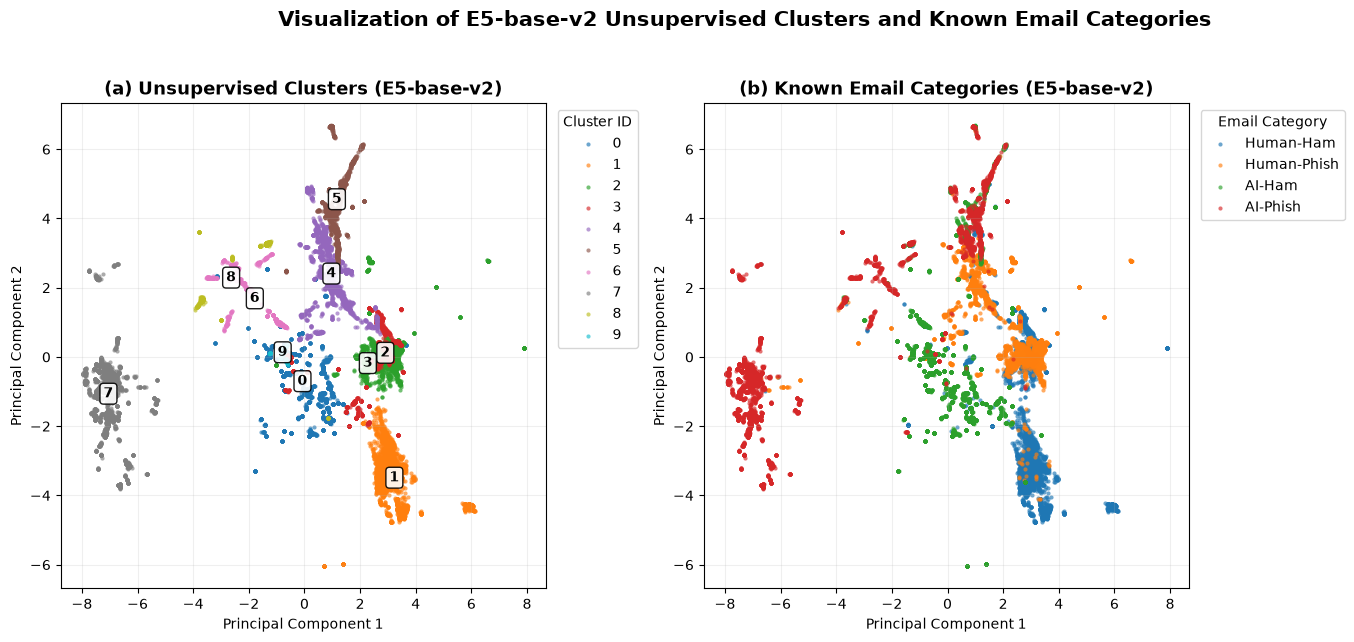


FINAL FIGURE VERIFICATION
✓ Source embedding: embedding_umap.npy
✓ Source dimension: (17319, 50)
✓ Clustering: Ward, k=10
✓ Visualization source: same 50-D UMAP representation
✓ 2-D projection: PCA
✓ Cluster IDs: 0–9 annotated at projected centroids
✓ Known classes: categorical legend
✓ Resolution: 600 DPI

Final figure saved to:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\Figure_3_E5_base_v2_50D_UMAP_Clusters_and_Classes_600dpi.png


In [1]:
# ============================================================
# FINAL FIGURE 3
# ACTUAL 50-D E5-BASE-V2 UMAP REPRESENTATION
# + WARD CLUSTERS
# + 2-D PCA VISUALIZATION
#
# IMPORTANT:
# The 2-D visualization is derived from the SAME 50-D UMAP
# representation that was used for Ward clustering.
#
# DO NOT use embedding_2d.npy here.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

EMBEDDING_50D_PATH = os.path.join(
    BASE_DIR,
    "embedding_umap.npy"
)

DATA_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_processed_data.csv"
)

OUTPUT_FIGURE = os.path.join(
    BASE_DIR,
    "Figure_3_E5_base_v2_50D_UMAP_Clusters_and_Classes_600dpi.png"
)

OUTPUT_CLUSTERS = os.path.join(
    BASE_DIR,
    "e5_base_v2_ward_clusters_from_50D_UMAP.csv"
)

OUTPUT_2D = os.path.join(
    BASE_DIR,
    "e5_base_v2_50D_UMAP_PCA2D.npy"
)


# ============================================================
# 2. LOAD 50-D UMAP REPRESENTATION
# ============================================================

print("=" * 80)
print("LOADING ACTUAL 50-D UMAP REPRESENTATION")
print("=" * 80)

if not os.path.exists(EMBEDDING_50D_PATH):
    raise FileNotFoundError(
        f"50-D UMAP file not found:\n{EMBEDDING_50D_PATH}"
    )

embedding_50d = np.load(
    EMBEDDING_50D_PATH
)

print("Embedding file:")
print(EMBEDDING_50D_PATH)

print(
    "Embedding shape:",
    embedding_50d.shape
)


# ============================================================
# 3. VERIFY DIMENSIONS
# ============================================================

EXPECTED_N = 17319
EXPECTED_DIM = 50

if embedding_50d.shape != (
    EXPECTED_N,
    EXPECTED_DIM
):

    raise ValueError(
        f"Unexpected embedding shape: "
        f"{embedding_50d.shape}\n"
        f"Expected: ({EXPECTED_N}, {EXPECTED_DIM})"
    )

print("\n✓ Confirmed:")
print("17,319 samples")
print("50-dimensional UMAP representation")


# ============================================================
# 4. LOAD DATASET
# ============================================================

print("\n" + "=" * 80)
print("LOADING PROCESSED DATASET")
print("=" * 80)

df = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig"
)

print("Dataset shape:", df.shape)

if len(df) != EXPECTED_N:

    raise ValueError(
        f"Dataset contains {len(df)} rows, "
        f"but embedding contains {EXPECTED_N} rows."
    )


# ============================================================
# 5. IDENTIFY LABEL COLUMN
# ============================================================

possible_label_columns = [
    "label",
    "Label",
    "labels",
    "class",
    "Class"
]

label_column = None

for col in possible_label_columns:

    if col in df.columns:
        label_column = col
        break

if label_column is None:

    raise ValueError(
        "Could not find the dataset label column. "
        "Expected one of: "
        + ", ".join(possible_label_columns)
    )

print("Label column:", label_column)


# ============================================================
# 6. VERIFY LABEL DISTRIBUTION
# ============================================================

print("\nKnown class distribution:")

print(
    df[label_column]
    .value_counts()
    .sort_index()
)


# ============================================================
# 7. REPRODUCE ACTUAL WARD CLUSTERING
# ============================================================

print("\n" + "=" * 80)
print("WARD AGGLOMERATIVE CLUSTERING")
print("=" * 80)

print("Input representation: E5-base-v2 UMAP-50")
print("Input shape:", embedding_50d.shape)
print("Number of clusters: 10")
print("Linkage: Ward")
print("Distance: Euclidean")


ward_model = AgglomerativeClustering(
    n_clusters=10,
    linkage="ward"
)

cluster_labels = ward_model.fit_predict(
    embedding_50d
)


# ============================================================
# 8. CLUSTER SIZE AUDIT
# ============================================================

cluster_sizes = (
    pd.Series(cluster_labels)
    .value_counts()
    .sort_index()
)

print("\nCluster sizes:")
print(cluster_sizes)

print(
    "\nTotal clustered samples:",
    cluster_sizes.sum()
)


# ============================================================
# 9. CHECK EXPECTED CLUSTER SIZES
# ============================================================

expected_cluster_sizes = {
    0: 2123,
    1: 2938,
    2: 541,
    3: 4759,
    4: 2679,
    5: 718,
    6: 2764,
    7: 301,
    8: 250,
    9: 246
}

expected_series = pd.Series(
    expected_cluster_sizes
)

if cluster_sizes.equals(expected_series):

    print(
        "\n✓ Cluster sizes EXACTLY match "
        "the previously reported Ward k=10 results."
    )

else:

    print(
        "\nWARNING: Cluster sizes do not exactly "
        "match the previously reported values."
    )

    comparison = pd.DataFrame({
        "Expected": expected_series,
        "Current": cluster_sizes
    })

    print(comparison)


# ============================================================
# 10. SAVE ACTUAL CLUSTER ASSIGNMENTS
# ============================================================

cluster_output = pd.DataFrame({

    "Email_Index":
        np.arange(EXPECTED_N),

    "Cluster":
        cluster_labels,

    "Known_Label":
        df[label_column].values

})

cluster_output.to_csv(
    OUTPUT_CLUSTERS,
    index=False,
    encoding="utf-8-sig"
)

print(
    "\nCluster assignments saved to:"
)

print(OUTPUT_CLUSTERS)


# ============================================================
# 11. PCA FROM THE SAME 50-D UMAP SPACE
# ============================================================

print("\n" + "=" * 80)
print("2-D VISUALIZATION")
print("=" * 80)

print(
    "IMPORTANT: PCA is applied to the actual 50-D "
    "UMAP representation."
)

print(
    "No separate 2-D UMAP fitting is performed."
)

pca = PCA(
    n_components=2
)

embedding_2d = pca.fit_transform(
    embedding_50d
)

explained_variance = (
    pca.explained_variance_ratio_
)

print(
    "\nPCA output shape:",
    embedding_2d.shape
)

print(
    "PC1 explained variance:",
    f"{explained_variance[0] * 100:.2f}%"
)

print(
    "PC2 explained variance:",
    f"{explained_variance[1] * 100:.2f}%"
)

print(
    "Total 2-D explained variance:",
    f"{explained_variance.sum() * 100:.2f}%"
)


# Save coordinates
np.save(
    OUTPUT_2D,
    embedding_2d
)

print(
    "\n2-D coordinates saved to:"
)

print(OUTPUT_2D)


# ============================================================
# 12. CALCULATE PROJECTED CLUSTER CENTROIDS
# ============================================================

centroids_2d = {}

for cluster_id in sorted(
    np.unique(cluster_labels)
):

    mask = (
        cluster_labels == cluster_id
    )

    centroids_2d[cluster_id] = (
        embedding_2d[mask]
        .mean(axis=0)
    )


# ============================================================
# 13. CLASS NAMES
# ============================================================

class_names = {
    0: "Human-Ham",
    1: "Human-Phish",
    2: "AI-Ham",
    3: "AI-Phish"
}


# ============================================================
# 14. CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6.5)
)


# ============================================================
# PANEL A — UNSUPERVISED CLUSTERS
# ============================================================

ax = axes[0]

unique_clusters = sorted(
    np.unique(cluster_labels)
)

# Use matplotlib's standard categorical palette
cluster_cmap = plt.get_cmap(
    "tab10"
)

for cluster_id in unique_clusters:

    mask = (
        cluster_labels == cluster_id
    )

    ax.scatter(
        embedding_2d[mask, 0],
        embedding_2d[mask, 1],
        s=9,
        alpha=0.65,
        color=cluster_cmap(cluster_id),
        label=str(cluster_id),
        linewidths=0
    )


# ------------------------------------------------------------
# Add cluster IDs at projected centroids
# ------------------------------------------------------------

for cluster_id, centroid in centroids_2d.items():

    ax.annotate(
        str(cluster_id),
        xy=centroid,
        xytext=(0, 0),
        textcoords="offset points",
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor="black",
            alpha=0.90
        )
    )


ax.set_title(
    "(a) Unsupervised Clusters (E5-base-v2)",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel(
    "Principal Component 1"
)

ax.set_ylabel(
    "Principal Component 2"
)

ax.legend(
    title="Cluster ID",
    loc="upper left",
    bbox_to_anchor=(1.01, 1.00),
    frameon=True
)

ax.grid(
    alpha=0.20
)


# ============================================================
# PANEL B — KNOWN EMAIL CATEGORIES
# ============================================================

ax = axes[1]

known_labels = (
    df[label_column]
    .astype(int)
    .values
)

class_colors = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red"
]

for class_id in range(4):

    mask = (
        known_labels == class_id
    )

    ax.scatter(
        embedding_2d[mask, 0],
        embedding_2d[mask, 1],
        s=9,
        alpha=0.65,
        color=class_colors[class_id],
        label=class_names[class_id],
        linewidths=0
    )


ax.set_title(
    "(b) Known Email Categories (E5-base-v2)",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel(
    "Principal Component 1"
)

ax.set_ylabel(
    "Principal Component 2"
)

ax.legend(
    title="Email Category",
    loc="upper left",
    bbox_to_anchor=(1.01, 1.00),
    frameon=True
)

ax.grid(
    alpha=0.20
)


# ============================================================
# 15. OVERALL FIGURE TITLE
# ============================================================

fig.suptitle(
    "Visualization of E5-base-v2 Unsupervised Clusters "
    "and Known Email Categories",
    fontsize=15,
    fontweight="bold"
)


fig.tight_layout(
    rect=[0, 0, 0.91, 0.95]
)


# ============================================================
# 16. SAVE 600-DPI FIGURE
# ============================================================

fig.savefig(
    OUTPUT_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 17. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 80)
print("FINAL FIGURE VERIFICATION")
print("=" * 80)

print(
    "✓ Source embedding:",
    os.path.basename(EMBEDDING_50D_PATH)
)

print(
    "✓ Source dimension:",
    embedding_50d.shape
)

print(
    "✓ Clustering:",
    "Ward, k=10"
)

print(
    "✓ Visualization source:",
    "same 50-D UMAP representation"
)

print(
    "✓ 2-D projection:",
    "PCA"
)

print(
    "✓ Cluster IDs:",
    "0–9 annotated at projected centroids"
)

print(
    "✓ Known classes:",
    "categorical legend"
)

print(
    "✓ Resolution:",
    "600 DPI"
)

print(
    "\nFinal figure saved to:"
)

print(OUTPUT_FIGURE) 

In [2]:
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering

# ============================================================
# VERIFY REGENERATED WARD k=10 CLUSTER SIZES
# ============================================================

EMBEDDING_50D_PATH = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_umap.npy"

# Previously reported cluster sizes
expected = {
    0: 2123,
    1: 2938,
    2: 541,
    3: 4759,
    4: 2679,
    5: 718,
    6: 2764,
    7: 301,
    8: 250,
    9: 246
}

# ------------------------------------------------------------
# Load actual 50-D UMAP representation
# ------------------------------------------------------------

X = np.load(EMBEDDING_50D_PATH)

print("=" * 70)
print("WARD k=10 CLUSTER SIZE VERIFICATION")
print("=" * 70)

print("Embedding shape:", X.shape)

# ------------------------------------------------------------
# Re-run exactly the clustering used in the study
# ------------------------------------------------------------

model = AgglomerativeClustering(
    n_clusters=10,
    linkage="ward"
)

clusters = model.fit_predict(X)

# ------------------------------------------------------------
# Calculate regenerated cluster sizes
# ------------------------------------------------------------

actual = (
    pd.Series(clusters)
    .value_counts()
    .sort_index()
)

expected_series = pd.Series(expected)

# ------------------------------------------------------------
# Comparison table
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Expected": expected_series,
    "Regenerated": actual
})

comparison["Match"] = (
    comparison["Expected"]
    == comparison["Regenerated"]
)

print("\nCluster-size comparison:")
print(comparison.to_string())

# ------------------------------------------------------------
# Overall verification
# ------------------------------------------------------------

print("\n" + "=" * 70)

if comparison["Match"].all():

    print("✓ EXACT MATCH")
    print("✓ All 10 cluster sizes match the previously reported results.")
    print("✓ Figure 3 clustering is reproducible from embedding_umap.npy.")

else:

    print("⚠ MISMATCH DETECTED")
    print("Some cluster sizes do not match the previously reported results.")

print("=" * 70)

print("\nTotal samples:", len(clusters))
print("Expected total:", sum(expected.values())) 

WARD k=10 CLUSTER SIZE VERIFICATION
Embedding shape: (17319, 50)

Cluster-size comparison:
   Expected  Regenerated  Match
0      2123         2290  False
1      2938         2730  False
2       541         3183  False
3      4759         1081  False
4      2679         2152  False
5       718         1524  False
6      2764          706  False
7       301         3099  False
8       250          387  False
9       246          167  False

⚠ MISMATCH DETECTED
Some cluster sizes do not match the previously reported results.

Total samples: 17319
Expected total: 17319


In [3]:
import os
import re
import json
import numpy as np
import pandas as pd

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

EXPECTED_SIZES = sorted([
    2123, 2938, 541, 4759, 2679,
    718, 2764, 301, 250, 246
])

print("=" * 80)
print("RECOVERING ORIGINAL k=10 WARD CLUSTERING")
print("=" * 80)

# ============================================================
# 1. SEARCH CSV FILES FOR CLUSTER ASSIGNMENTS
# ============================================================

print("\n" + "=" * 80)
print("SEARCHING CSV FILES")
print("=" * 80)

csv_matches = []

for root, dirs, files in os.walk(BASE_DIR):

    # Skip virtual environment
    dirs[:] = [
        d for d in dirs
        if d not in ["mvenv", ".git", "__pycache__"]
    ]

    for file in files:

        if not file.lower().endswith(".csv"):
            continue

        path = os.path.join(root, file)

        try:
            df = pd.read_csv(
                path,
                nrows=17319,
                low_memory=False
            )

            cluster_columns = [
                c for c in df.columns
                if any(
                    term in c.lower()
                    for term in [
                        "cluster",
                        "ward",
                        "agglomer"
                    ]
                )
            ]

            for col in cluster_columns:

                values = df[col].dropna()

                # Check whether column looks like cluster IDs
                try:
                    numeric = pd.to_numeric(values)

                    unique_values = sorted(
                        numeric.unique().tolist()
                    )

                    if (
                        len(unique_values) == 10
                        and set(unique_values) == set(range(10))
                    ):

                        counts = (
                            numeric
                            .value_counts()
                            .sort_index()
                        )

                        sizes = sorted(
                            counts.tolist()
                        )

                        exact_match = (
                            sizes == EXPECTED_SIZES
                        )

                        csv_matches.append({
                            "file": path,
                            "column": col,
                            "rows": len(df),
                            "cluster_sizes": counts.to_dict(),
                            "exact_expected_match": exact_match
                        })

                except Exception:
                    pass

        except Exception:
            pass


if len(csv_matches) == 0:

    print("No 10-cluster assignment CSV was identified.")

else:

    print(
        f"Found {len(csv_matches)} possible "
        "10-cluster assignment columns:\n"
    )

    for item in csv_matches:

        print("-" * 80)
        print("FILE:", item["file"])
        print("COLUMN:", item["column"])
        print("ROWS:", item["rows"])
        print(
            "EXACT EXPECTED MATCH:",
            item["exact_expected_match"]
        )
        print(
            "CLUSTER SIZES:",
            item["cluster_sizes"]
        )


# ============================================================
# 2. SEARCH NOTEBOOKS FOR UMAP / WARD CONFIGURATION
# ============================================================

print("\n" + "=" * 80)
print("SEARCHING NOTEBOOKS FOR ORIGINAL UMAP / WARD SETTINGS")
print("=" * 80)

notebook_results = []

for root, dirs, files in os.walk(BASE_DIR):

    dirs[:] = [
        d for d in dirs
        if d not in ["mvenv", ".git", "__pycache__"]
    ]

    for file in files:

        if not file.lower().endswith(".ipynb"):
            continue

        path = os.path.join(root, file)

        try:

            with open(
                path,
                "r",
                encoding="utf-8"
            ) as f:

                notebook = json.load(f)

            for cell in notebook.get(
                "cells",
                []
            ):

                source = "".join(
                    cell.get(
                        "source",
                        []
                    )
                )

                source_lower = source.lower()

                if (
                    "umap" in source_lower
                    and (
                        "agglomerative" in source_lower
                        or "ward" in source_lower
                    )
                ):

                    notebook_results.append({
                        "file": path,
                        "source": source
                    })

        except Exception as e:

            print(
                "Could not read:",
                path,
                "|",
                e
            )


print(
    f"\nFound {len(notebook_results)} "
    "notebook cells containing UMAP + Ward/Agglomerative code."
)


# ============================================================
# 3. PRINT RELEVANT NOTEBOOK CODE
# ============================================================

for i, item in enumerate(
    notebook_results
):

    print("\n" + "=" * 80)
    print(
        f"NOTEBOOK MATCH {i + 1}"
    )
    print("=" * 80)

    print(
        "FILE:",
        item["file"]
    )

    source = item["source"]

    # Print only relevant lines
    lines = source.splitlines()

    relevant = []

    for line in lines:

        if any(
            term in line.lower()
            for term in [
                "umap",
                "n_neighbors",
                "min_dist",
                "n_components",
                "random_state",
                "metric",
                "agglomerative",
                "linkage",
                "n_clusters",
                "ward"
            ]
        ):

            relevant.append(line)

    for line in relevant:

        print(line)


# ============================================================
# 4. INSPECT ALL NPY FILES
# ============================================================

print("\n" + "=" * 80)
print("NPY EMBEDDING FILE AUDIT")
print("=" * 80)

for root, dirs, files in os.walk(BASE_DIR):

    dirs[:] = [
        d for d in dirs
        if d not in ["mvenv", ".git", "__pycache__"]
    ]

    for file in files:

        if not file.lower().endswith(".npy"):
            continue

        path = os.path.join(root, file)

        try:

            arr = np.load(
                path,
                mmap_mode="r"
            )

            print(
                f"{file:45s}",
                "shape =",
                arr.shape
            )

        except Exception as e:

            print(
                "Could not inspect:",
                path,
                "|",
                e
            ) 

RECOVERING ORIGINAL k=10 WARD CLUSTERING

SEARCHING CSV FILES
Found 6 possible 10-cluster assignment columns:

--------------------------------------------------------------------------------
FILE: C:\Users\hmari\ai-generated-phishing-detection-multimodal\cluster_interpretation_summary.csv
COLUMN: cluster
ROWS: 10
EXACT EXPECTED MATCH: False
CLUSTER SIZES: {0: 1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1}
--------------------------------------------------------------------------------
FILE: C:\Users\hmari\ai-generated-phishing-detection-multimodal\e5_base_v2_ward_clusters_from_50D_UMAP.csv
COLUMN: Cluster
ROWS: 17319
EXACT EXPECTED MATCH: False
CLUSTER SIZES: {0: 2290, 1: 2730, 2: 3183, 3: 1081, 4: 2152, 5: 1524, 6: 706, 7: 3099, 8: 387, 9: 167}
--------------------------------------------------------------------------------
FILE: C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\bge_base_clusters.csv
COLUMN: cluster
ROWS: 17319
EXACT EXPEC

In [4]:
import os
import numpy as np
import pandas as pd

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

E5_UMAP50 = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_umap50.npy"
)

ORIGINAL_CLUSTERS = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_clusters.csv"
)

EXPECTED = {
    0: 2123,
    1: 2938,
    2: 541,
    3: 4759,
    4: 2679,
    5: 718,
    6: 2764,
    7: 301,
    8: 250,
    9: 246
}

print("=" * 80)
print("ORIGINAL E5-BASE-V2 50-D UMAP VERIFICATION")
print("=" * 80)

# ------------------------------------------------------------
# Load original E5 50-D representation
# ------------------------------------------------------------

X = np.load(E5_UMAP50)

print("\nE5 50-D UMAP file:")
print(E5_UMAP50)

print("Shape:", X.shape)

if X.shape != (17319, 50):
    raise ValueError(
        f"Unexpected shape: {X.shape}"
    )

print("✓ Confirmed: 17,319 × 50")


# ------------------------------------------------------------
# Load original saved cluster assignments
# ------------------------------------------------------------

original_df = pd.read_csv(
    ORIGINAL_CLUSTERS
)

print("\nOriginal cluster file:")
print(ORIGINAL_CLUSTERS)

print("Shape:", original_df.shape)

print("Columns:")
print(original_df.columns.tolist())


# ------------------------------------------------------------
# Identify cluster column
# ------------------------------------------------------------

cluster_col = None

for col in original_df.columns:

    if col.lower() in [
        "cluster",
        "clusters",
        "cluster_label",
        "cluster_labels"
    ]:

        cluster_col = col
        break

if cluster_col is None:

    raise ValueError(
        "Could not identify cluster column."
    )

print(
    "\nOriginal cluster column:",
    cluster_col
)


# ------------------------------------------------------------
# Original cluster sizes
# ------------------------------------------------------------

original_labels = (
    original_df[cluster_col]
    .astype(int)
    .values
)

original_sizes = (
    pd.Series(original_labels)
    .value_counts()
    .sort_index()
)

print("\nOriginal saved cluster sizes:")
print(original_sizes)


# ------------------------------------------------------------
# Re-run Ward clustering on E5 50-D representation
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("REGENERATING WARD k=10 FROM E5 50-D UMAP")
print("=" * 80)

ward = AgglomerativeClustering(
    n_clusters=10,
    linkage="ward",
    metric="euclidean"
)

new_labels = ward.fit_predict(X)

new_sizes = (
    pd.Series(new_labels)
    .value_counts()
    .sort_index()
)

print("\nRegenerated cluster sizes:")
print(new_sizes)


# ------------------------------------------------------------
# Compare sizes
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Original": original_sizes,
    "Regenerated": new_sizes
})

comparison["Size_Match"] = (
    comparison["Original"]
    ==
    comparison["Regenerated"]
)

print("\n" + "=" * 80)
print("CLUSTER SIZE COMPARISON")
print("=" * 80)

print(
    comparison.to_string()
)


# ------------------------------------------------------------
# Compare actual partitions using ARI
# ------------------------------------------------------------

partition_ari = adjusted_rand_score(
    original_labels,
    new_labels
)

print("\n" + "=" * 80)
print("PARTITION COMPARISON")
print("=" * 80)

print(
    "ARI between original saved clusters "
    "and regenerated clusters:",
    f"{partition_ari:.10f}"
)


# ------------------------------------------------------------
# Exact label comparison
# ------------------------------------------------------------

exact_label_match = np.array_equal(
    original_labels,
    new_labels
)

print(
    "Exact cluster-label sequence match:",
    exact_label_match
)


# ------------------------------------------------------------
# Final conclusion
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL VERDICT")
print("=" * 80)

if (
    comparison["Size_Match"].all()
    and partition_ari == 1.0
):

    print(
        "✓ CONFIRMED"
    )

    print(
        "✓ e5_base_umap50.npy reproduces "
        "the original k=10 Ward partition."
    )

    print(
        "✓ Original cluster sizes are preserved."
    )

    print(
        "✓ The saved e5_base_clusters.csv "
        "and regenerated clustering are identical "
        "as partitions."
    )

    print(
        "\nThis is the correct representation "
        "for regenerating Figure 3."
    )

else:

    print(
        "⚠ NOT FULLY REPRODUCED"
    )

    print(
        "Do NOT regenerate the final figure yet."
    )

    print(
        "Send me the complete output."
    ) 

ORIGINAL E5-BASE-V2 50-D UMAP VERIFICATION

E5 50-D UMAP file:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_umap50.npy
Shape: (17319, 50)
✓ Confirmed: 17,319 × 50

Original cluster file:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_clusters.csv
Shape: (17319, 3)
Columns:
['row_index', 'true_label', 'cluster']

Original cluster column: cluster

Original saved cluster sizes:
0    2123
1    2938
2     541
3    4759
4    2679
5     718
6    2764
7     301
8     250
9     246
Name: count, dtype: int64

REGENERATING WARD k=10 FROM E5 50-D UMAP

Regenerated cluster sizes:
0    2123
1    2938
2     541
3    4759
4    2679
5     718
6    2764
7     301
8     250
9     246
Name: count, dtype: int64

CLUSTER SIZE COMPARISON
   Original  Regenerated  Size_Match
0      2123         2123        True
1      2938         2938        True
2       541          541        True
3      4759         4759        T

LOADING ORIGINAL E5-BASE-V2 50-D UMAP
File: C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_umap50.npy
Shape: (17319, 50)
✓ Confirmed: 17,319 × 50

LOADING ORIGINAL WARD CLUSTER ASSIGNMENTS
File: C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_clusters.csv
Shape: (17319, 3)
Columns: ['row_index', 'true_label', 'cluster']
✓ Row order verified.

Original cluster sizes:
0    2123
1    2938
2     541
3    4759
4    2679
5     718
6    2764
7     301
8     250
9     246
Name: count, dtype: int64

✓ Cluster sizes exactly match the original reported results.

PCA 2-D VISUALIZATION
Input: original 50-D UMAP representation
No separate 2-D UMAP is fitted.
2-D shape: (17319, 2)
PC1 variance: 25.38%
PC2 variance: 19.56%
Total variance: 44.93%


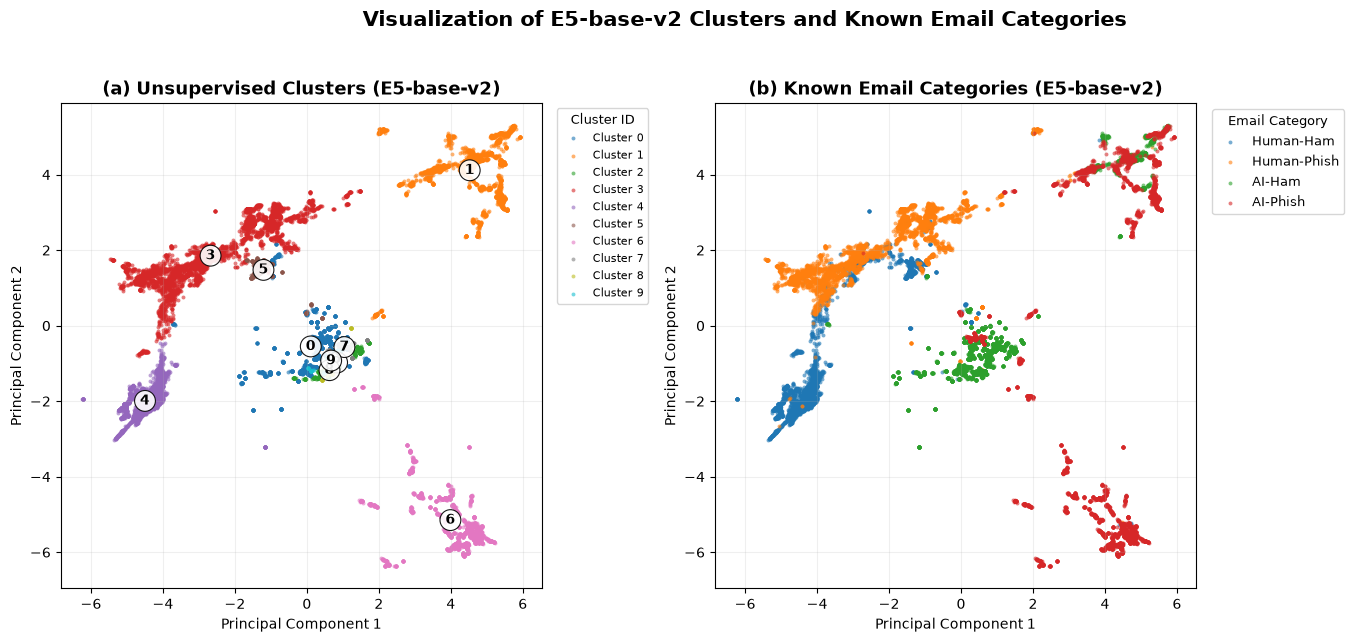


FINAL FIGURE 3 AUDIT
✓ Source: e5_base_umap50.npy
✓ Source shape: (17319, 50)
✓ Clustering: original e5_base_clusters.csv
✓ Clusters: Ward, k=10
✓ Cluster sizes: verified
✓ Visualization: PCA projection of same 50-D space
✓ Separate 2-D UMAP: NO
✓ Cluster IDs: 0–9 at projected centroids
✓ Known classes: categorical legend
✓ Resolution: 600 DPI

Saved:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\Figure_3_E5_base_v2_50D_UMAP_Final_600dpi.png


In [5]:
# ============================================================
# FINAL FIGURE 3
# ORIGINAL E5-BASE-V2 50-D UMAP + ORIGINAL WARD k=10 CLUSTERS
#
# Visualization:
#   E5-base-v2 768-D
#          ↓
#   UMAP 50-D
#          ↓
#   PCA 2-D  [visualization only]
#
# Clusters:
#   Original e5_base_clusters.csv
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

UMAP50_PATH = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_umap50.npy"
)

CLUSTER_PATH = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_clusters.csv"
)

OUTPUT_FIGURE = os.path.join(
    BASE_DIR,
    "Figure_3_E5_base_v2_50D_UMAP_Final_600dpi.png"
)

OUTPUT_COORDINATES = os.path.join(
    BASE_DIR,
    "e5_base_v2_50D_UMAP_PCA2D_final.npy"
)


# ============================================================
# 2. LOAD ORIGINAL 50-D UMAP
# ============================================================

print("=" * 80)
print("LOADING ORIGINAL E5-BASE-V2 50-D UMAP")
print("=" * 80)

X = np.load(UMAP50_PATH)

print("File:", UMAP50_PATH)
print("Shape:", X.shape)

if X.shape != (17319, 50):
    raise ValueError(
        f"Unexpected shape {X.shape}; "
        "expected (17319, 50)."
    )

print("✓ Confirmed: 17,319 × 50")


# ============================================================
# 3. LOAD ORIGINAL CLUSTER ASSIGNMENTS
# ============================================================

print("\n" + "=" * 80)
print("LOADING ORIGINAL WARD CLUSTER ASSIGNMENTS")
print("=" * 80)

clusters_df = pd.read_csv(
    CLUSTER_PATH
)

print("File:", CLUSTER_PATH)
print("Shape:", clusters_df.shape)
print("Columns:", clusters_df.columns.tolist())


# ============================================================
# 4. VERIFY ROW ORDER
# ============================================================

if len(clusters_df) != 17319:
    raise ValueError(
        f"Cluster file has {len(clusters_df)} rows; "
        "expected 17,319."
    )

if "row_index" not in clusters_df.columns:
    raise ValueError(
        "row_index column not found."
    )

expected_indices = np.arange(17319)

if not np.array_equal(
    clusters_df["row_index"].values,
    expected_indices
):
    raise ValueError(
        "row_index does not exactly match "
        "0–17318. Do not continue."
    )

print("✓ Row order verified.")


# ============================================================
# 5. EXTRACT CLUSTER AND TRUE LABELS
# ============================================================

cluster_labels = (
    clusters_df["cluster"]
    .astype(int)
    .values
)

true_labels = (
    clusters_df["true_label"]
    .astype(int)
    .values
)


# ============================================================
# 6. VERIFY CLUSTER SIZES
# ============================================================

expected_sizes = {
    0: 2123,
    1: 2938,
    2: 541,
    3: 4759,
    4: 2679,
    5: 718,
    6: 2764,
    7: 301,
    8: 250,
    9: 246
}

actual_sizes = (
    pd.Series(cluster_labels)
    .value_counts()
    .sort_index()
)

expected_series = pd.Series(
    expected_sizes
)

print("\nOriginal cluster sizes:")
print(actual_sizes)

if actual_sizes.equals(expected_series):

    print(
        "\n✓ Cluster sizes exactly match "
        "the original reported results."
    )

else:

    raise ValueError(
        "Cluster sizes do not match the original results."
    )


# ============================================================
# 7. PCA PROJECTION FROM THE SAME 50-D CLUSTERING SPACE
# ============================================================

print("\n" + "=" * 80)
print("PCA 2-D VISUALIZATION")
print("=" * 80)

print(
    "Input: original 50-D UMAP representation"
)

print(
    "No separate 2-D UMAP is fitted."
)

pca = PCA(
    n_components=2
)

X_2D = pca.fit_transform(X)

print(
    "2-D shape:",
    X_2D.shape
)

print(
    "PC1 variance:",
    f"{pca.explained_variance_ratio_[0] * 100:.2f}%"
)

print(
    "PC2 variance:",
    f"{pca.explained_variance_ratio_[1] * 100:.2f}%"
)

print(
    "Total variance:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)


# Save coordinates
np.save(
    OUTPUT_COORDINATES,
    X_2D
)


# ============================================================
# 8. CALCULATE PROJECTED CLUSTER CENTROIDS
# ============================================================

centroids = {}

for cluster_id in range(10):

    mask = (
        cluster_labels == cluster_id
    )

    centroids[cluster_id] = X_2D[mask].mean(
        axis=0
    )


# ============================================================
# 9. CATEGORY NAMES
# ============================================================

class_names = {
    0: "Human-Ham",
    1: "Human-Phish",
    2: "AI-Ham",
    3: "AI-Phish"
}


# ============================================================
# 10. CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6.5)
)


# ============================================================
# PANEL A — UNSUPERVISED CLUSTERS
# ============================================================

ax = axes[0]

cluster_cmap = plt.get_cmap(
    "tab10"
)

for cluster_id in range(10):

    mask = (
        cluster_labels == cluster_id
    )

    ax.scatter(
        X_2D[mask, 0],
        X_2D[mask, 1],
        s=8,
        alpha=0.60,
        color=cluster_cmap(cluster_id),
        label=f"Cluster {cluster_id}",
        linewidths=0
    )


# ------------------------------------------------------------
# Cluster centroid annotations
# ------------------------------------------------------------

for cluster_id in range(10):

    cx, cy = centroids[cluster_id]

    ax.annotate(
        str(cluster_id),
        (cx, cy),
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="circle,pad=0.25",
            facecolor="white",
            edgecolor="black",
            linewidth=0.8,
            alpha=0.90
        )
    )


ax.set_title(
    "(a) Unsupervised Clusters (E5-base-v2)",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel(
    "Principal Component 1"
)

ax.set_ylabel(
    "Principal Component 2"
)

ax.legend(
    title="Cluster ID",
    loc="upper left",
    bbox_to_anchor=(1.02, 1.00),
    fontsize=8,
    title_fontsize=9,
    frameon=True
)

ax.grid(
    alpha=0.20
)


# ============================================================
# PANEL B — KNOWN CATEGORIES
# ============================================================

ax = axes[1]

category_colors = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red"
]

for class_id in range(4):

    mask = (
        true_labels == class_id
    )

    ax.scatter(
        X_2D[mask, 0],
        X_2D[mask, 1],
        s=8,
        alpha=0.60,
        color=category_colors[class_id],
        label=class_names[class_id],
        linewidths=0
    )


ax.set_title(
    "(b) Known Email Categories (E5-base-v2)",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel(
    "Principal Component 1"
)

ax.set_ylabel(
    "Principal Component 2"
)

ax.legend(
    title="Email Category",
    loc="upper left",
    bbox_to_anchor=(1.02, 1.00),
    fontsize=9,
    title_fontsize=9,
    frameon=True
)

ax.grid(
    alpha=0.20
)


# ============================================================
# 11. OVERALL TITLE
# ============================================================

fig.suptitle(
    "Visualization of E5-base-v2 Clusters and Known Email Categories",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout(
    rect=[0, 0, 0.91, 0.95]
)


# ============================================================
# 12. SAVE 600 DPI
# ============================================================

fig.savefig(
    OUTPUT_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ============================================================
# 13. FINAL AUDIT
# ============================================================

print("\n" + "=" * 80)
print("FINAL FIGURE 3 AUDIT")
print("=" * 80)

print("✓ Source:", "e5_base_umap50.npy")
print("✓ Source shape:", X.shape)
print("✓ Clustering:", "original e5_base_clusters.csv")
print("✓ Clusters:", "Ward, k=10")
print("✓ Cluster sizes:", "verified")
print("✓ Visualization:", "PCA projection of same 50-D space")
print("✓ Separate 2-D UMAP:", "NO")
print("✓ Cluster IDs:", "0–9 at projected centroids")
print("✓ Known classes:", "categorical legend")
print("✓ Resolution:", "600 DPI")
print("\nSaved:")
print(OUTPUT_FIGURE) 

In [6]:
# ============================================================
# FINAL CLUSTER-PROFILE ANALYSIS
# E5-BASE-V2 | ORIGINAL WARD k=10 CLUSTERS
#
# Outputs:
#   1. Cluster size
#   2. Dominant category + proportion
#   3. Mean intra-cluster cosine similarity
#   4. Top-5 c-TF-IDF terms
#   5. Five nearest representative emails per cluster
#   6. Consolidated cluster-profile table
#
# IMPORTANT:
# c-TF-IDF is used ONLY for post-clustering interpretation.
# It is NOT used for embedding, UMAP, clustering, or selection.
# ============================================================

import os
import re
import numpy as np
import pandas as pd

from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import CountVectorizer


# ============================================================
# 1. PATHS
# ============================================================

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

EMBEDDING_PATH = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_embeddings.npy"
)

CLUSTER_PATH = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_clusters.csv"
)

DATA_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_processed_data.csv"
)

PROFILE_OUTPUT = os.path.join(
    BASE_DIR,
    "E5_base_v2_cluster_profile_final.csv"
)

REPRESENTATIVE_OUTPUT = os.path.join(
    BASE_DIR,
    "E5_base_v2_top5_representative_emails.csv"
)

CTFIDF_OUTPUT = os.path.join(
    BASE_DIR,
    "E5_base_v2_cluster_top5_cTFIDF_terms.csv"
)


# ============================================================
# 2. LOAD E5-BASE-V2 768-D EMBEDDINGS
# ============================================================

print("=" * 80)
print("LOADING E5-BASE-V2 EMBEDDINGS")
print("=" * 80)

X = np.load(
    EMBEDDING_PATH
)

print("Embedding file:")
print(EMBEDDING_PATH)

print("Shape:", X.shape)

if X.shape != (17319, 768):
    raise ValueError(
        f"Unexpected embedding shape: {X.shape}. "
        "Expected (17319, 768)."
    )

print("✓ Confirmed: 17,319 × 768 E5-base-v2 embeddings.")


# ============================================================
# 3. NORMALIZE EMBEDDINGS
# ============================================================

# Cosine similarity requires normalized vectors.
X_norm = normalize(
    X.astype(np.float64),
    norm="l2"
)

print("✓ Embeddings normalized for cosine calculations.")


# ============================================================
# 4. LOAD ORIGINAL CLUSTER ASSIGNMENTS
# ============================================================

print("\n" + "=" * 80)
print("LOADING ORIGINAL WARD CLUSTERS")
print("=" * 80)

clusters_df = pd.read_csv(
    CLUSTER_PATH
)

print("Cluster file:")
print(CLUSTER_PATH)

print("Shape:", clusters_df.shape)

required_cluster_columns = [
    "row_index",
    "true_label",
    "cluster"
]

missing = [
    c for c in required_cluster_columns
    if c not in clusters_df.columns
]

if missing:
    raise ValueError(
        f"Missing cluster columns: {missing}"
    )

if len(clusters_df) != 17319:
    raise ValueError(
        "Cluster file does not contain 17,319 rows."
    )


# ============================================================
# 5. VERIFY ROW ORDER
# ============================================================

if not np.array_equal(
    clusters_df["row_index"].values,
    np.arange(17319)
):

    raise ValueError(
        "row_index is not exactly 0–17318. "
        "Stop and verify dataset ordering."
    )

print("✓ Row order verified.")


cluster_labels = (
    clusters_df["cluster"]
    .astype(int)
    .values
)

true_labels = (
    clusters_df["true_label"]
    .astype(int)
    .values
)


# ============================================================
# 6. VERIFY CLUSTER SIZES
# ============================================================

expected_sizes = {
    0: 2123,
    1: 2938,
    2: 541,
    3: 4759,
    4: 2679,
    5: 718,
    6: 2764,
    7: 301,
    8: 250,
    9: 246
}

actual_sizes = (
    pd.Series(cluster_labels)
    .value_counts()
    .sort_index()
)

print("\nOriginal cluster sizes:")
print(actual_sizes)

if actual_sizes.to_dict() != expected_sizes:

    raise ValueError(
        "Cluster sizes do not match the verified "
        "original k=10 clustering."
    )

print(
    "\n✓ Cluster sizes exactly match "
    "the verified original partition."
)


# ============================================================
# 7. LOAD PROCESSED MULTIMODAL DATA
# ============================================================

print("\n" + "=" * 80)
print("LOADING PROCESSED MULTIMODAL DATA")
print("=" * 80)

df = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    low_memory=False
)

print("Dataset shape:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())


# ============================================================
# 8. FIND / CONSTRUCT MULTIMODAL TEXT
# ============================================================

# First look for an existing combined-text column.
combined_candidates = [
    "combined_text",
    "combined",
    "multimodal_text",
    "combined_multimodal",
    "combined_multimodal_text",
    "full_text",
    "email_text",
    "processed_text",
    "text"
]

text_column = None

for col in combined_candidates:

    if col in df.columns:

        text_column = col
        break


# ------------------------------------------------------------
# If combined text is not explicitly stored, find body and
# attachment columns and reconstruct the multimodal text.
# ------------------------------------------------------------

if text_column is not None:

    print(
        "\nUsing existing combined-text column:",
        text_column
    )

    multimodal_text = (
        df[text_column]
        .fillna("")
        .astype(str)
    )

else:

    body_candidates = [
        "email_body",
        "body",
        "body_text",
        "Email_Body",
        "EMAIL_BODY",
        "email_text_body"
    ]

    attachment_candidates = [
        "attachment_text",
        "Attachment_Text",
        "attachment",
        "attachment_text_extracted",
        "ATTACHMENT_TEXT"
    ]

    body_column = None
    attachment_column = None

    for col in body_candidates:

        if col in df.columns:

            body_column = col
            break

    for col in attachment_candidates:

        if col in df.columns:

            attachment_column = col
            break

    if body_column is None:

        raise ValueError(
            "\nCould not identify email-body column.\n"
            "Please inspect the printed column list and "
            "set body_column manually."
        )

    if attachment_column is None:

        print(
            "\nWARNING: No attachment-text column found."
        )

        print(
            "Using email body only for c-TF-IDF."
        )

        body = (
            df[body_column]
            .fillna("")
            .astype(str)
        )

        multimodal_text = (
            "[EMAIL_BODY] " + body
        )

    else:

        print(
            "\nBody column:",
            body_column
        )

        print(
            "Attachment column:",
            attachment_column
        )

        body = (
            df[body_column]
            .fillna("")
            .astype(str)
        )

        attachment = (
            df[attachment_column]
            .fillna("")
            .astype(str)
        )

        multimodal_text = (
            "[EMAIL_BODY] "
            + body
            + " [ATTACHMENT_TEXT] "
            + attachment
        )


if len(multimodal_text) != 17319:

    raise ValueError(
        "Multimodal text does not contain 17,319 rows."
    )

print(
    "\n✓ Multimodal text aligned to 17,319 samples."
)


# ============================================================
# 9. BASIC TEXT CLEANING FOR c-TF-IDF ONLY
# ============================================================

def clean_for_ctfidf(text):

    text = str(text)

    # Remove structural markers
    text = re.sub(
        r"\[EMAIL_BODY\]",
        " ",
        text,
        flags=re.I
    )

    text = re.sub(
        r"\[ATTACHMENT_TEXT\]",
        " ",
        text,
        flags=re.I
    )

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
        flags=re.I
    )

    # Remove email addresses
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        " ",
        text
    )

    # Normalize whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip().lower()


ctfidf_text = (
    multimodal_text
    .map(clean_for_ctfidf)
)


# ============================================================
# 10. AGGREGATE DOCUMENTS BY CLUSTER
# ============================================================

print("\n" + "=" * 80)
print("BUILDING CLUSTER DOCUMENTS FOR c-TF-IDF")
print("=" * 80)

cluster_documents = []

for cluster_id in range(10):

    mask = (
        cluster_labels == cluster_id
    )

    combined_cluster_text = " ".join(
        ctfidf_text[mask].tolist()
    )

    cluster_documents.append(
        combined_cluster_text
    )

print(
    "Created one aggregated document "
    "for each of the 10 clusters."
)


# ============================================================
# 11. COUNT TERMS
# ============================================================

vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9_-]{2,}\b"
)

count_matrix = vectorizer.fit_transform(
    cluster_documents
)

terms = np.array(
    vectorizer.get_feature_names_out()
)

print(
    "Vocabulary size:",
    len(terms)
)


# ============================================================
# 12. CALCULATE c-TF-IDF
# ============================================================

# Class-based TF-IDF:
#
# TF(c,t) = count(c,t) / total_terms(c)
#
# IDF(t) = log((number_of_clusters + 1) /
#              (clusters_containing_term + 1)) + 1
#
# c-TF-IDF(c,t) = TF(c,t) × IDF(t)

counts = (
    count_matrix
    .toarray()
    .astype(np.float64)
)

cluster_term_totals = (
    counts.sum(axis=1)
)

cluster_term_totals[
    cluster_term_totals == 0
] = 1

tf = (
    counts
    /
    cluster_term_totals[:, None]
)

document_frequency = (
    (counts > 0)
    .sum(axis=0)
)

n_clusters = 10

idf = np.log(
    (n_clusters + 1)
    /
    (document_frequency + 1)
) + 1

ctfidf_matrix = (
    tf * idf
)


# ============================================================
# 13. EXTRACT TOP-5 TERMS PER CLUSTER
# ============================================================

top_terms = {}

ctfidf_rows = []

for cluster_id in range(10):

    scores = ctfidf_matrix[
        cluster_id
    ]

    ranked_indices = np.argsort(
        scores
    )[::-1]

    selected = []

    for idx in ranked_indices:

        term = terms[idx]
        score = scores[idx]

        if score <= 0:
            continue

        selected.append(
            (term, score)
        )

        if len(selected) == 5:
            break

    top_terms[cluster_id] = selected

    for rank, (term, score) in enumerate(
        selected,
        start=1
    ):

        ctfidf_rows.append({
            "Cluster": cluster_id,
            "Rank": rank,
            "Term": term,
            "cTFIDF": score
        })


ctfidf_df = pd.DataFrame(
    ctfidf_rows
)

ctfidf_df.to_csv(
    CTFIDF_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 14. PRINT TOP TERMS
# ============================================================

print("\n" + "=" * 80)
print("TOP-5 c-TF-IDF TERMS BY CLUSTER")
print("=" * 80)

for cluster_id in range(10):

    terms_string = ", ".join(
        [
            term
            for term, score
            in top_terms[cluster_id]
        ]
    )

    print(
        f"Cluster {cluster_id}: "
        f"{terms_string}"
    )


# ============================================================
# 15. CALCULATE MEAN INTRA-CLUSTER COSINE SIMILARITY
# ============================================================

print("\n" + "=" * 80)
print("CALCULATING WITHIN-CLUSTER COSINE COHESION")
print("=" * 80)

mean_intra_cosine = {}

for cluster_id in range(10):

    mask = (
        cluster_labels == cluster_id
    )

    cluster_vectors = X_norm[mask]

    n = len(cluster_vectors)

    # Exact mean pairwise cosine similarity.
    #
    # For normalized vectors:
    #
    # sum_i,j cosine(i,j)
    # = ||sum_i x_i||^2
    #
    # Subtract n self-similarities.
    #
    # Divide by n(n-1).

    vector_sum = (
        cluster_vectors.sum(axis=0)
    )

    total_similarity = np.dot(
        vector_sum,
        vector_sum
    )

    mean_cosine = (
        total_similarity - n
    ) / (
        n * (n - 1)
    )

    mean_intra_cosine[
        cluster_id
    ] = mean_cosine

    print(
        f"Cluster {cluster_id}: "
        f"n={n:,} | "
        f"mean intra-cluster cosine="
        f"{mean_cosine:.6f}"
    )


# ============================================================
# 16. FIND FIVE NEAREST REPRESENTATIVE EMAILS
# ============================================================

print("\n" + "=" * 80)
print("FINDING FIVE NEAREST REPRESENTATIVE EMAILS")
print("=" * 80)

representative_rows = []

for cluster_id in range(10):

    mask = (
        cluster_labels == cluster_id
    )

    indices = np.where(mask)[0]

    cluster_vectors = X_norm[mask]

    # Mean E5 embedding in ORIGINAL 768-D space
    centroid = (
        cluster_vectors.mean(axis=0)
    )

    centroid_norm = np.linalg.norm(
        centroid
    )

    if centroid_norm == 0:
        raise ValueError(
            f"Zero centroid for cluster {cluster_id}"
        )

    centroid = (
        centroid / centroid_norm
    )

    # Cosine similarity to centroid
    similarities = (
        cluster_vectors
        @ centroid
    )

    # Five highest similarities
    top_local = np.argsort(
        similarities
    )[::-1][:5]

    print(
        f"\nCluster {cluster_id}"
    )

    for rank, local_idx in enumerate(
        top_local,
        start=1
    ):

        global_idx = indices[
            local_idx
        ]

        sim = similarities[
            local_idx
        ]

        representative_text = (
            multimodal_text
            .iloc[global_idx]
        )

        # Keep CSV manageable while retaining enough
        # text for qualitative inspection.
        representative_preview = (
            representative_text
            [:1000]
            .replace("\n", " ")
        )

        original_label = (
            true_labels[
                global_idx
            ]
        )

        representative_rows.append({

            "Cluster":
                cluster_id,

            "Rank":
                rank,

            "Row_Index":
                int(global_idx),

            "Cosine_to_Cluster_Centroid":
                float(sim),

            "True_Label":
                int(original_label),

            "Original_Category":
                {
                    0: "Human-Ham",
                    1: "Human-Phish",
                    2: "AI-Ham",
                    3: "AI-Phish"
                }.get(
                    int(original_label),
                    "Unknown"
                ),

            "Representative_Text":
                representative_preview
        })

        print(
            f"  {rank}. "
            f"row={global_idx} | "
            f"cosine={sim:.6f} | "
            f"label={original_label}"
        )


representatives_df = pd.DataFrame(
    representative_rows
)

representatives_df.to_csv(
    REPRESENTATIVE_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 17. DOMINANT CATEGORY
# ============================================================

class_names = {
    0: "Human-Ham",
    1: "Human-Phish",
    2: "AI-Ham",
    3: "AI-Phish"
}

profile_rows = []

for cluster_id in range(10):

    mask = (
        cluster_labels == cluster_id
    )

    labels_in_cluster = (
        true_labels[mask]
    )

    counts_by_class = (
        pd.Series(
            labels_in_cluster
        )
        .value_counts()
        .sort_index()
    )

    dominant_label = (
        counts_by_class
        .idxmax()
    )

    dominant_count = (
        counts_by_class
        .max()
    )

    cluster_size = (
        len(labels_in_cluster)
    )

    dominant_proportion = (
        dominant_count
        /
        cluster_size
    )

    top_term_string = "; ".join(
        [
            term
            for term, score
            in top_terms[cluster_id]
        ]
    )

    # Top-5 representative row indices
    rep_indices = (
        representatives_df[
            representatives_df["Cluster"]
            == cluster_id
        ]["Row_Index"]
        .tolist()
    )

    rep_index_string = ", ".join(
        map(str, rep_indices)
    )

    profile_rows.append({

        "Cluster":
            cluster_id,

        "Size":
            cluster_size,

        "Dominant_Category":
            class_names[
                int(dominant_label)
            ],

        "Dominant_Proportion":
            dominant_proportion,

        "Mean_IntraCluster_Cosine":
            mean_intra_cosine[
                cluster_id
            ],

        "Top_5_cTFIDF_Terms":
            top_term_string,

        "Top_5_Representative_Row_Indices":
            rep_index_string
    })


# ============================================================
# 18. FINAL CONSOLIDATED PROFILE TABLE
# ============================================================

profile_df = pd.DataFrame(
    profile_rows
)

profile_df.to_csv(
    PROFILE_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 19. DISPLAY FINAL PROFILE
# ============================================================

print("\n" + "=" * 80)
print("FINAL CLUSTER PROFILE TABLE")
print("=" * 80)

display(
    profile_df
)


# ============================================================
# 20. FINAL FILE SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("FILES CREATED")
print("=" * 80)

print(
    "\n1. Consolidated cluster profile:"
)

print(PROFILE_OUTPUT)

print(
    "\n2. Five representative emails per cluster:"
)

print(REPRESENTATIVE_OUTPUT)

print(
    "\n3. c-TF-IDF terms:"
)

print(CTFIDF_OUTPUT)


print("\n" + "=" * 80)
print("ANALYSIS COMPLETE")
print("=" * 80)

print(
    "✓ Original E5-base-v2 768-D embeddings used"
)

print(
    "✓ Original verified Ward k=10 assignments used"
)

print(
    "✓ Mean intra-cluster cosine calculated "
    "in original 768-D E5 space"
)

print(
    "✓ Five nearest samples calculated "
    "from each 768-D cluster centroid"
)

print(
    "✓ c-TF-IDF calculated only for "
    "post-clustering interpretation"
)

print(
    "✓ Consolidated cluster-profile table created"
) 

LOADING E5-BASE-V2 EMBEDDINGS
Embedding file:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_embeddings.npy
Shape: (17319, 768)
✓ Confirmed: 17,319 × 768 E5-base-v2 embeddings.
✓ Embeddings normalized for cosine calculations.

LOADING ORIGINAL WARD CLUSTERS
Cluster file:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_clusters.csv
Shape: (17319, 3)
✓ Row order verified.

Original cluster sizes:
0    2123
1    2938
2     541
3    4759
4    2679
5     718
6    2764
7     301
8     250
9     246
Name: count, dtype: int64

✓ Cluster sizes exactly match the verified original partition.

LOADING PROCESSED MULTIMODAL DATA
Dataset shape: (17319, 7)

Available columns:
['text', 'attachment_paths', 'label', 'attachment_text', 'combined_text', 'embedding_text', 'word_count']

Using existing combined-text column: combined_text

✓ Multimodal text aligned to 17,319 samples.

BUILDING CLUSTER DOCUMENTS FOR c-TF

,Cluster,Size,Dominant_Category,Dominant_Proportion,Mean_IntraCluster_Cosine,Top_5_cTFIDF_Terms,Top_5_Representative_Row_Indices
0,0,2123,AI-Ham,0.763542,0.823285,virus; sender; submission; added; total,"14772, 14089, 15259, 16598, 16468"
1,1,2938,AI-Phish,0.612662,0.796011,account; dear; link; regards; security,"3717, 3012, 4592, 3571, 3922"
2,2,541,AI-Ham,0.992606,0.882045,quick reminder; drive; quick; materials; refer...,"15134, 14012, 15041, 15166, 14552"
3,3,4759,Human-Phish,0.875814,0.789919,email; com; account; information; http,"16930, 17167, 16877, 12585, 11952"
4,4,2679,Human-Ham,0.991041,0.814497,ect; hou; hou ect; ect ect; enron,"9225, 7883, 7882, 9260, 8606"
5,5,718,Human-Ham,0.952646,0.796915,self; example; wrote; message; list,"1114, 1115, 1392, 1422, 1421"
6,6,2764,AI-Phish,0.994573,0.861476,attached; dear; access; attached dear; regards,"7825, 7485, 7525, 7505, 7625"
7,7,301,AI-Ham,1.000000,0.912210,minutes meeting; listed end; action items; mee...,"15934, 14620, 15442, 13910, 15631"
8,8,250,AI-Ham,1.000000,0.931331,room bring; hello confirming; bring draft; dra...,"14908, 14998, 16792, 14764, 16319"
9,9,246,AI-Ham,0.991870,0.936114,wednesday calendar; invite includes; includes ...,"15279, 16413, 14779, 16128, 16038"



FILES CREATED

1. Consolidated cluster profile:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\E5_base_v2_cluster_profile_final.csv

2. Five representative emails per cluster:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\E5_base_v2_top5_representative_emails.csv

3. c-TF-IDF terms:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\E5_base_v2_cluster_top5_cTFIDF_terms.csv

ANALYSIS COMPLETE
✓ Original E5-base-v2 768-D embeddings used
✓ Original verified Ward k=10 assignments used
✓ Mean intra-cluster cosine calculated in original 768-D E5 space
✓ Five nearest samples calculated from each 768-D cluster centroid
✓ c-TF-IDF calculated only for post-clustering interpretation
✓ Consolidated cluster-profile table created


In [7]:
import pandas as pd

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

profile = pd.read_csv(
    BASE_DIR + r"\E5_base_v2_cluster_profile_final.csv"
)

representatives = pd.read_csv(
    BASE_DIR + r"\E5_base_v2_top5_representative_emails.csv"
)

ctfidf = pd.read_csv(
    BASE_DIR + r"\E5_base_v2_cluster_top5_cTFIDF_terms.csv"
)

print("=" * 100)
print("FINAL CLUSTER PROFILE")
print("=" * 100)
print(profile.to_string(index=False))

print("\n" + "=" * 100)
print("TOP-5 c-TF-IDF TERMS")
print("=" * 100)
print(ctfidf.to_string(index=False))

print("\n" + "=" * 100)
print("FIVE REPRESENTATIVE SAMPLES PER CLUSTER")
print("=" * 100)

for cluster in range(10):
    sub = representatives[
        representatives["Cluster"] == cluster
    ]

    print(f"\n--- CLUSTER {cluster} ---")

    for _, row in sub.iterrows():
        print(
            f"\nRank {row['Rank']} | "
            f"Row {row['Row_Index']} | "
            f"Cosine = {row['Cosine_to_Cluster_Centroid']:.6f} | "
            f"Category = {row['Original_Category']}"
        )
        print(row["Representative_Text"][:1000]) 
        

FINAL CLUSTER PROFILE
 Cluster  Size Dominant_Category  Dominant_Proportion  Mean_IntraCluster_Cosine                                                                            Top_5_cTFIDF_Terms  Top_5_Representative_Row_Indices
       0  2123            AI-Ham             0.763542                  0.823285                                                       virus; sender; submission; added; total 14772, 14089, 15259, 16598, 16468
       1  2938          AI-Phish             0.612662                  0.796011                                                        account; dear; link; regards; security      3717, 3012, 4592, 3571, 3922
       2   541            AI-Ham             0.992606                  0.882045                                     quick reminder; drive; quick; materials; references slide 15134, 14012, 15041, 15166, 14552
       3  4759       Human-Phish             0.875814                  0.789919                                                        email; com;

In [8]:
# ================================================================
# FINAL CORRECTED MULTIMODAL ABLATION EXPERIMENT
# ================================================================
#
# 4 CONDITIONS × 10 SEEDS
# Same attachment-bearing subset
#
# 1. Email Body Only
# 2. Attachment Text Only
# 3. Text-level Multimodal
# 4. Vector-level Fusion
#
# Pipeline:
# E5-base-v2 (768-D)
#       ↓
# UMAP (50-D, cosine)
#       ↓
# Ward Agglomerative Clustering (k=10)
#
# Seeds: 1–10
#
# Outputs:
#   - Per-seed results
#   - Mean ± SD summary
#   - Paired effect sizes
#   - 95% CI
#   - Wilcoxon signed-rank tests
#   - Holm correction
#   - Publication-quality ARI/NMI figure
# ================================================================

import os
import re
import time
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, t

from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score,
    homogeneity_score,
    completeness_score
)

from sentence_transformers import SentenceTransformer
import umap.umap_ as umap


warnings.filterwarnings("ignore")


# ================================================================
# 1. PATHS AND CONFIGURATION
# ================================================================

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

DATA_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_processed_data.csv"
)

CLUSTER_PATH = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_clusters.csv"
)

MODEL_NAME = "intfloat/e5-base-v2"

SEEDS = list(range(1, 11))

N_CLUSTERS = 10

UMAP_COMPONENTS = 50
UMAP_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1
UMAP_METRIC = "cosine"

EXPECTED_TOTAL = 17319
EXPECTED_ATTACHMENT_ROWS = 3000

BATCH_SIZE = 32


# Output files

PER_SEED_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_4conditions_seeds1-10_results.csv"
)

SUMMARY_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_4conditions_mean_SD.csv"
)

EFFECT_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_effect_sizes_95CI.csv"
)

WILCOXON_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_pairwise_Wilcoxon_Holm.csv"
)

SUBSET_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_attachment_bearing_subset_indices.csv"
)

FIGURE_OUTPUT = os.path.join(
    BASE_DIR,
    "Figure_5_Ablation_ARI_NMI_600dpi.png"
)


# ================================================================
# 2. HARDWARE / SOFTWARE INFORMATION
# ================================================================

print("=" * 90)
print("CORRECTED ABLATION EXPERIMENT")
print("=" * 90)

print("\nHardware / software:")
print("Operating system:", platform.platform())
print("Python:", platform.python_version())

try:
    import sklearn
    print("scikit-learn:", sklearn.__version__)
except:
    pass

try:
    import sentence_transformers
    print(
        "sentence-transformers:",
        sentence_transformers.__version__
    )
except:
    pass

try:
    import umap
    print("UMAP:", getattr(umap, "__version__", "installed"))
except:
    pass

print("Embedding model:", MODEL_NAME)
print("Seeds:", SEEDS)
print("Clusters:", N_CLUSTERS)
print("UMAP dimensions:", UMAP_COMPONENTS)
print("UMAP neighbors:", UMAP_NEIGHBORS)
print("UMAP min_dist:", UMAP_MIN_DIST)
print("UMAP metric:", UMAP_METRIC)


# ================================================================
# 3. LOAD DATASET
# ================================================================

print("\n" + "=" * 90)
print("LOADING DATASET")
print("=" * 90)

df = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    low_memory=False
)

print("Dataset shape:", df.shape)

if len(df) != EXPECTED_TOTAL:
    raise ValueError(
        f"Expected {EXPECTED_TOTAL} rows, "
        f"but dataset contains {len(df)}."
    )

print("✓ 17,319 dataset rows confirmed.")

print("\nDataset columns:")
print(df.columns.tolist())


# ================================================================
# 4. LOAD ORIGINAL CLUSTER FILE
# ================================================================

clusters_df = pd.read_csv(
    CLUSTER_PATH
)

required_cluster_columns = [
    "row_index",
    "true_label",
    "cluster"
]

missing_cluster_columns = [
    c for c in required_cluster_columns
    if c not in clusters_df.columns
]

if missing_cluster_columns:
    raise ValueError(
        "Missing cluster columns: "
        + str(missing_cluster_columns)
    )

if len(clusters_df) != EXPECTED_TOTAL:
    raise ValueError(
        "Cluster file does not contain 17,319 rows."
    )

if not np.array_equal(
    clusters_df["row_index"].values,
    np.arange(EXPECTED_TOTAL)
):
    raise ValueError(
        "Cluster row_index is not exactly 0–17318."
    )

print("\n✓ Original cluster file verified.")


# ================================================================
# 5. FIND BODY AND ATTACHMENT-TEXT COLUMNS
# ================================================================

body_candidates = [
    "email_body",
    "body",
    "body_text",
    "Email_Body",
    "EMAIL_BODY",
    "email_text_body"
]

attachment_text_candidates = [
    "attachment_text",
    "Attachment_Text",
    "attachment_text_extracted",
    "ATTACHMENT_TEXT",
    "attachment_content"
]

body_column = None
attachment_text_column = None

for col in body_candidates:
    if col in df.columns:
        body_column = col
        break

for col in attachment_text_candidates:
    if col in df.columns:
        attachment_text_column = col
        break

if body_column is None:
    raise ValueError(
        "Could not identify the email-body column."
    )

if attachment_text_column is None:
    raise ValueError(
        "Could not identify the attachment-text column."
    )

print("\nBody column:")
print(body_column)

print("\nAttachment-text column:")
print(attachment_text_column)


# ================================================================
# 6. IDENTIFY TRUE ATTACHMENT-BEARING SUBSET
# ================================================================
#
# We prefer a real attachment/file indicator rather than
# using non-empty OCR text because an attachment can exist
# even when OCR extraction returns empty text.
# ================================================================

indicator_candidates = [
    "has_attachment",
    "attachment_present",
    "attachment_exists",
    "attachment_flag",
    "attachment_file",
    "attachment_filename",
    "attachment_name",
    "attachment_path",
    "attachment_filepath",
    "attachment_type",
    "attachment_extension",
    "attachment_count",
    "num_attachments",
    "attachment_size"
]

indicator_column = None

for col in indicator_candidates:
    if col in df.columns:
        indicator_column = col
        break


print("\n" + "=" * 90)
print("IDENTIFYING ATTACHMENT-BEARING SUBSET")
print("=" * 90)


def interpret_attachment_indicator(series):

    # Boolean
    if pd.api.types.is_bool_dtype(series):

        return series.fillna(False).astype(bool).values

    # Numeric
    if pd.api.types.is_numeric_dtype(series):

        return (
            series.fillna(0).astype(float).values > 0
        )

    # String/object
    s = (
        series
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    false_values = {
        "",
        "nan",
        "none",
        "null",
        "na",
        "n/a",
        "false",
        "no",
        "0",
        "none attached",
        "no attachment",
        "nan attachment"
    }

    return (
        ~s.isin(false_values)
    ).values


if indicator_column is not None:

    print(
        "Attachment indicator column found:",
        indicator_column
    )

    attachment_mask = interpret_attachment_indicator(
        df[indicator_column]
    )

else:

    print(
        "No explicit attachment indicator column found."
    )

    print(
        "Attempting fallback using attachment-text presence."
    )

    attachment_text_raw = (
        df[attachment_text_column]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    attachment_mask = (
        attachment_text_raw != ""
    ).values

    print(
        "\nWARNING: fallback identification was used."
    )


attachment_indices = np.where(
    attachment_mask
)[0]

n_attachment = len(
    attachment_indices
)

print(
    "\nAttachment-bearing rows detected:",
    n_attachment
)

print(
    "Expected attachment-bearing rows:",
    EXPECTED_ATTACHMENT_ROWS
)


# ---------------------------------------------------------------
# CRITICAL VALIDATION
# ---------------------------------------------------------------

if n_attachment != EXPECTED_ATTACHMENT_ROWS:

    print("\n" + "!" * 90)
    print("ATTACHMENT SUBSET VALIDATION FAILED")
    print("!" * 90)

    print(
        f"Detected {n_attachment} attachment-bearing rows, "
        f"but the verified dataset contains "
        f"{EXPECTED_ATTACHMENT_ROWS} attachment-bearing samples."
    )

    print(
        "\nThe experiment has been STOPPED intentionally."
    )

    print(
        "Do NOT continue with this result."
    )

    print(
        "\nIf an attachment indicator column exists in your dataset, "
        "set its exact name manually in:"
    )

    print(
        "indicator_column = 'YOUR_COLUMN_NAME'"
    )

    raise ValueError(
        "Could not establish the verified 3,000-row "
        "attachment-bearing subset."
    )


print(
    "\n✓ Exactly 3,000 attachment-bearing samples confirmed."
)


# ================================================================
# 7. SAVE SUBSET INDICES
# ================================================================

subset_df = pd.DataFrame({
    "row_index": attachment_indices
})

subset_df.to_csv(
    SUBSET_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Subset indices saved:",
    SUBSET_OUTPUT
)


# ================================================================
# 8. ALIGN DATA AND TRUE LABELS
# ================================================================

body_text = (
    df.loc[
        attachment_indices,
        body_column
    ]
    .fillna("")
    .astype(str)
    .str.strip()
    .reset_index(drop=True)
)

attachment_text = (
    df.loc[
        attachment_indices,
        attachment_text_column
    ]
    .fillna("")
    .astype(str)
    .str.strip()
    .reset_index(drop=True)
)

true_labels = (
    clusters_df.loc[
        attachment_indices,
        "true_label"
    ]
    .astype(int)
    .values
)

original_clusters = (
    clusters_df.loc[
        attachment_indices,
        "cluster"
    ]
    .astype(int)
    .values
)

print("\nAttachment-bearing subset:")
print("N =", len(attachment_indices))

print(
    "Body texts:",
    len(body_text)
)

print(
    "Attachment texts:",
    len(attachment_text)
)


# ================================================================
# 9. CONSTRUCT TEXT-LEVEL MULTIMODAL REPRESENTATION
# ================================================================

multimodal_text = (
    "[EMAIL_BODY] "
    + body_text
    + " [ATTACHMENT_TEXT] "
    + attachment_text
)


# ================================================================
# 10. LOAD E5-BASE-V2
# ================================================================

print("\n" + "=" * 90)
print("LOADING E5-BASE-V2")
print("=" * 90)

embedding_start = time.perf_counter()

model = SentenceTransformer(
    MODEL_NAME,
    device="cpu"
)

model.max_seq_length = 512

print(
    "Model max sequence length:",
    model.max_seq_length
)

print(
    "Embedding dimension:",
    model.get_sentence_embedding_dimension()
)

if model.get_sentence_embedding_dimension() != 768:

    raise ValueError(
        "Loaded model is not 768-dimensional."
    )


# ================================================================
# 11. EMBED THREE UNIQUE TEXT REPRESENTATIONS
# ================================================================
#
# Body-only
# Attachment-only
# Text-level multimodal
#
# Vector-level fusion reuses body + attachment embeddings.
# ================================================================


def encode_texts(name, texts):

    print("\nEmbedding:", name)

    start = time.perf_counter()

    embeddings = model.encode(
        texts.tolist(),
        batch_size=BATCH_SIZE,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    elapsed = time.perf_counter() - start

    print(
        f"{name} embedding time: "
        f"{elapsed / 60:.2f} min"
    )

    print(
        f"{name} shape:",
        embeddings.shape
    )

    if embeddings.shape != (
        EXPECTED_ATTACHMENT_ROWS,
        768
    ):

        raise ValueError(
            f"Unexpected shape for {name}: "
            f"{embeddings.shape}"
        )

    return embeddings, elapsed


body_embeddings, body_embedding_time = encode_texts(
    "Email Body Only",
    body_text
)

attachment_embeddings, attachment_embedding_time = encode_texts(
    "Attachment Text Only",
    attachment_text
)

multimodal_embeddings, multimodal_embedding_time = encode_texts(
    "Text-level Multimodal",
    multimodal_text
)


# ================================================================
# 12. VECTOR-LEVEL FUSION
# ================================================================

print("\n" + "=" * 90)
print("CREATING VECTOR-LEVEL FUSION")
print("=" * 90)

vector_fusion = np.hstack([
    body_embeddings,
    attachment_embeddings
])

vector_fusion = normalize(
    vector_fusion,
    norm="l2"
)

print(
    "Vector-level fusion shape:",
    vector_fusion.shape
)

if vector_fusion.shape != (
    EXPECTED_ATTACHMENT_ROWS,
    1536
):

    raise ValueError(
        "Unexpected vector-fusion shape."
    )

print(
    "✓ 768-D body + 768-D attachment "
    "= 1536-D fused representation."
)


# ================================================================
# 13. DEFINE FOUR CONDITIONS
# ================================================================

representations = {

    "Email Body Only":
        body_embeddings,

    "Attachment Text Only":
        attachment_embeddings,

    "Text-level Multimodal":
        multimodal_embeddings,

    "Vector-level Fusion":
        vector_fusion
}


# ================================================================
# 14. CLUSTERING FUNCTION
# ================================================================

def run_clustering(
    X,
    seed
):

    # ------------------------------------------------------------
    # UMAP
    # ------------------------------------------------------------

    reducer = umap.UMAP(
        n_neighbors=UMAP_NEIGHBORS,
        min_dist=UMAP_MIN_DIST,
        n_components=UMAP_COMPONENTS,
        metric=UMAP_METRIC,
        random_state=seed
    )

    reduced = reducer.fit_transform(X)

    # ------------------------------------------------------------
    # Ward clustering
    # ------------------------------------------------------------

    try:

        clustering_model = (
            AgglomerativeClustering(
                n_clusters=N_CLUSTERS,
                linkage="ward",
                metric="euclidean"
            )
        )

    except TypeError:

        # Compatibility with older scikit-learn
        clustering_model = (
            AgglomerativeClustering(
                n_clusters=N_CLUSTERS,
                linkage="ward",
                affinity="euclidean"
            )
        )

    cluster_assignments = (
        clustering_model.fit_predict(
            reduced
        )
    )

    return reduced, cluster_assignments


# ================================================================
# 15. EVALUATION FUNCTION
# ================================================================

def evaluate_clustering(
    reduced,
    predicted,
    true
):

    return {

        "Silhouette":
            silhouette_score(
                reduced,
                predicted
            ),

        "Davies_Bouldin":
            davies_bouldin_score(
                reduced,
                predicted
            ),

        "Calinski_Harabasz":
            calinski_harabasz_score(
                reduced,
                predicted
            ),

        "ARI":
            adjusted_rand_score(
                true,
                predicted
            ),

        "NMI":
            normalized_mutual_info_score(
                true,
                predicted,
                average_method="arithmetic"
            ),

        "AMI":
            adjusted_mutual_info_score(
                true,
                predicted,
                average_method="arithmetic"
            ),

        "Homogeneity":
            homogeneity_score(
                true,
                predicted
            ),

        "Completeness":
            completeness_score(
                true,
                predicted
            )
    }


# ================================================================
# 16. RUN 4 × 10 EXPERIMENT
# ================================================================

print("\n" + "=" * 90)
print("RUNNING 4 CONDITIONS × 10 SEEDS")
print("=" * 90)

results = []

all_partitions = {}

total_experiment_start = time.perf_counter()


for condition_name, X in representations.items():

    print("\n")
    print("#" * 90)
    print(
        "CONDITION:",
        condition_name
    )
    print("#" * 90)

    all_partitions[
        condition_name
    ] = {}

    for seed in SEEDS:

        print(
            f"\n{condition_name} | Seed {seed}"
        )

        start = time.perf_counter()

        reduced, predicted = run_clustering(
            X,
            seed
        )

        metrics = evaluate_clustering(
            reduced,
            predicted,
            true_labels
        )

        elapsed = (
            time.perf_counter()
            - start
        )

        row = {

            "Condition":
                condition_name,

            "Seed":
                seed,

            "N":
                len(true_labels),

            "Clusters":
                len(np.unique(predicted)),

            **metrics,

            "Runtime_min":
                elapsed / 60
        }

        results.append(row)

        all_partitions[
            condition_name
        ][seed] = predicted

        print(
            f"Silhouette = "
            f"{metrics['Silhouette']:.4f}"
        )

        print(
            f"ARI = "
            f"{metrics['ARI']:.4f}"
        )

        print(
            f"NMI = "
            f"{metrics['NMI']:.4f}"
        )

        print(
            f"Runtime = "
            f"{elapsed / 60:.2f} min"
        )


total_experiment_time = (
    time.perf_counter()
    - total_experiment_start
)


results_df = pd.DataFrame(
    results
)


# ================================================================
# 17. SAVE PER-SEED RESULTS
# ================================================================

results_df.to_csv(
    PER_SEED_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

print("\n" + "=" * 90)
print("PER-SEED RESULTS SAVED")
print("=" * 90)

print(
    PER_SEED_OUTPUT
)


# ================================================================
# 18. CALCULATE MEAN ± SD
# ================================================================

metrics_to_summarize = [
    "Silhouette",
    "Davies_Bouldin",
    "Calinski_Harabasz",
    "ARI",
    "NMI",
    "AMI",
    "Homogeneity",
    "Completeness",
    "Runtime_min"
]

summary_rows = []

for condition in representations.keys():

    subset = results_df[
        results_df["Condition"]
        == condition
    ]

    row = {
        "Condition":
            condition
    }

    for metric in metrics_to_summarize:

        row[
            metric + "_Mean"
        ] = subset[metric].mean()

        row[
            metric + "_SD"
        ] = subset[metric].std(
            ddof=1
        )

    summary_rows.append(row)


summary_df = pd.DataFrame(
    summary_rows
)

summary_df.to_csv(
    SUMMARY_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 19. PRINT FINAL MEAN ± SD TABLE
# ================================================================

print("\n" + "=" * 90)
print("FINAL ABLATION RESULTS — MEAN ± SD")
print("=" * 90)

for _, row in summary_df.iterrows():

    print(
        f"\n{row['Condition']}"
    )

    for metric in [
        "Silhouette",
        "Davies_Bouldin",
        "Calinski_Harabasz",
        "ARI",
        "NMI",
        "AMI",
        "Homogeneity",
        "Completeness"
    ]:

        print(
            f"  {metric}: "
            f"{row[metric + '_Mean']:.4f} ± "
            f"{row[metric + '_SD']:.4f}"
        )


# ================================================================
# 20. EFFECT SIZE FUNCTION
# ================================================================

def paired_effect_size(
    a,
    b
):

    differences = (
        np.asarray(a)
        -
        np.asarray(b)
    )

    n = len(differences)

    mean_difference = (
        differences.mean()
    )

    sd_difference = (
        differences.std(ddof=1)
    )

    if sd_difference == 0:

        dz = np.nan

    else:

        dz = (
            mean_difference
            /
            sd_difference
        )

    # 95% CI for mean paired difference
    standard_error = (
        sd_difference
        /
        np.sqrt(n)
    )

    t_critical = t.ppf(
        0.975,
        df=n - 1
    )

    ci_low = (
        mean_difference
        -
        t_critical
        *
        standard_error
    )

    ci_high = (
        mean_difference
        +
        t_critical
        *
        standard_error
    )

    return (
        mean_difference,
        ci_low,
        ci_high,
        dz
    )


# ================================================================
# 21. PAIRWISE EFFECT SIZES
# ================================================================

conditions = list(
    representations.keys()
)

pairwise_rows = []

for i in range(
    len(conditions)
):

    for j in range(
        i + 1,
        len(conditions)
    ):

        condition_a = conditions[i]
        condition_b = conditions[j]

        for metric in [
            "ARI",
            "NMI"
        ]:

            a = (
                results_df[
                    results_df["Condition"]
                    == condition_a
                ]
                .sort_values("Seed")[metric]
                .values
            )

            b = (
                results_df[
                    results_df["Condition"]
                    == condition_b
                ]
                .sort_values("Seed")[metric]
                .values
            )

            (
                mean_diff,
                ci_low,
                ci_high,
                dz
            ) = paired_effect_size(
                a,
                b
            )

            pairwise_rows.append({

                "Comparison":
                    f"{condition_a} vs {condition_b}",

                "Condition_A":
                    condition_a,

                "Condition_B":
                    condition_b,

                "Metric":
                    metric,

                "Mean_Paired_Difference":
                    mean_diff,

                "95CI_Lower":
                    ci_low,

                "95CI_Upper":
                    ci_high,

                "Cohens_dz":
                    dz
            })


effect_df = pd.DataFrame(
    pairwise_rows
)

effect_df.to_csv(
    EFFECT_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 22. WILCOXON SIGNED-RANK TESTS
# ================================================================

wilcoxon_rows = []

for metric in [
    "ARI",
    "NMI"
]:

    raw_p_values = []

    temp_rows = []

    for i in range(
        len(conditions)
    ):

        for j in range(
            i + 1,
            len(conditions)
        ):

            condition_a = conditions[i]
            condition_b = conditions[j]

            a = (
                results_df[
                    results_df["Condition"]
                    == condition_a
                ]
                .sort_values("Seed")[metric]
                .values
            )

            b = (
                results_df[
                    results_df["Condition"]
                    == condition_b
                ]
                .sort_values("Seed")[metric]
                .values
            )

            differences = a - b

            if np.allclose(
                differences,
                0
            ):

                statistic = 0.0
                p_value = 1.0

            else:

                test = wilcoxon(
                    a,
                    b,
                    alternative="two-sided",
                    method="auto"
                )

                statistic = (
                    test.statistic
                )

                p_value = (
                    test.pvalue
                )

            temp_rows.append({

                "Metric":
                    metric,

                "Comparison":
                    f"{condition_a} vs {condition_b}",

                "Condition_A":
                    condition_a,

                "Condition_B":
                    condition_b,

                "Wilcoxon_statistic":
                    statistic,

                "Raw_p":
                    p_value
            })

            raw_p_values.append(
                p_value
            )


    # ------------------------------------------------------------
    # Holm correction within each metric
    # ------------------------------------------------------------

    order = np.argsort(
        raw_p_values
    )

    m = len(
        raw_p_values
    )

    adjusted = np.zeros(m)

    running_max = 0

    for rank, idx in enumerate(
        order
    ):

        adjusted_value = (
            m - rank
        ) * raw_p_values[idx]

        running_max = max(
            running_max,
            adjusted_value
        )

        adjusted[idx] = min(
            running_max,
            1.0
        )


    for k, row in enumerate(
        temp_rows
    ):

        row[
            "Holm_adjusted_p"
        ] = adjusted[k]

        wilcoxon_rows.append(
            row
        )


wilcoxon_df = pd.DataFrame(
    wilcoxon_rows
)

wilcoxon_df.to_csv(
    WILCOXON_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 23. PRINT EFFECT-SIZE TABLE
# ================================================================

print("\n" + "=" * 90)
print("PAIRED EFFECT SIZES")
print("=" * 90)

print(
    effect_df.to_string(
        index=False,
        float_format=lambda x:
        f"{x:.4f}"
    )
)


# ================================================================
# 24. PRINT WILCOXON RESULTS
# ================================================================

print("\n" + "=" * 90)
print("WILCOXON SIGNED-RANK TESTS — HOLM CORRECTED")
print("=" * 90)

print(
    wilcoxon_df.to_string(
        index=False,
        float_format=lambda x:
        f"{x:.6f}"
    )
)


# ================================================================
# 25. GENERATE FINAL GROUPED ARI/NMI FIGURE
# ================================================================

print("\n" + "=" * 90)
print("GENERATING FINAL ABLATION FIGURE")
print("=" * 90)


figure_conditions = [
    "Email Body Only",
    "Attachment Text Only",
    "Text-level Multimodal",
    "Vector-level Fusion"
]

ari_means = []
ari_sds = []

nmi_means = []
nmi_sds = []

for condition in figure_conditions:

    sub = results_df[
        results_df["Condition"]
        == condition
    ]

    ari_means.append(
        sub["ARI"].mean()
    )

    ari_sds.append(
        sub["ARI"].std(ddof=1)
    )

    nmi_means.append(
        sub["NMI"].mean()
    )

    nmi_sds.append(
        sub["NMI"].std(ddof=1)
    )


x = np.arange(
    len(figure_conditions)
)

width = 0.36

fig, ax = plt.subplots(
    figsize=(12, 7)
)

bars1 = ax.bar(
    x - width / 2,
    ari_means,
    width,
    yerr=ari_sds,
    capsize=5,
    label="ARI"
)

bars2 = ax.bar(
    x + width / 2,
    nmi_means,
    width,
    yerr=nmi_sds,
    capsize=5,
    label="NMI"
)


ax.set_ylabel(
    "Score",
    fontsize=13
)

ax.set_xlabel(
    "Ablation condition",
    fontsize=13
)

ax.set_title(
    "Ablation Comparison of Semantic Representations",
    fontsize=16
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    [
        "Email Body Only",
        "Attachment Only",
        "Text-level\nMultimodal",
        "Vector-level\nFusion"
    ]
)

ax.set_ylim(
    0,
    max(
        max(
            np.array(ari_means)
            +
            np.array(ari_sds)
        ),
        max(
            np.array(nmi_means)
            +
            np.array(nmi_sds)
        )
    )
    + 0.08
)

ax.legend(
    frameon=True
)

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIGURE_OUTPUT,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print(
    "\n✓ Figure saved:"
)

print(
    FIGURE_OUTPUT
)


# ================================================================
# 26. FINAL RUNTIME / OUTPUT SUMMARY
# ================================================================

print("\n" + "=" * 90)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 90)

print(
    f"Attachment-bearing subset: "
    f"{len(attachment_indices):,}"
)

print(
    "Conditions:",
    len(representations)
)

print(
    "Seeds:",
    len(SEEDS)
)

print(
    "Total clustering runs:",
    len(representations) * len(SEEDS)
)

print(
    f"Total UMAP + Ward runtime: "
    f"{total_experiment_time / 60:.2f} min"
)

print("\nEmbedding times:")

print(
    f"Body: "
    f"{body_embedding_time / 60:.2f} min"
)

print(
    f"Attachment: "
    f"{attachment_embedding_time / 60:.2f} min"
)

print(
    f"Text-level multimodal: "
    f"{multimodal_embedding_time / 60:.2f} min"
)


print("\nFiles created:")

print(
    "1.",
    PER_SEED_OUTPUT
)

print(
    "2.",
    SUMMARY_OUTPUT
)

print(
    "3.",
    EFFECT_OUTPUT
)

print(
    "4.",
    WILCOXON_OUTPUT
)

print(
    "5.",
    SUBSET_OUTPUT
)

print(
    "6.",
    FIGURE_OUTPUT
)

print("\n" + "=" * 90)
print("CORRECTED ABLATION ANALYSIS COMPLETE")
print("=" * 90) 

C:\Users\hmari\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CORRECTED ABLATION EXPERIMENT

Hardware / software:
Operating system: Windows-11-10.0.26200-SP0
Python: 3.13.1
scikit-learn: 1.9.0
sentence-transformers: 5.6.0
UMAP: 0.5.12
Embedding model: intfloat/e5-base-v2
Seeds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Clusters: 10
UMAP dimensions: 50
UMAP neighbors: 15
UMAP min_dist: 0.1
UMAP metric: cosine

LOADING DATASET
Dataset shape: (17319, 7)
✓ 17,319 dataset rows confirmed.

Dataset columns:
['text', 'attachment_paths', 'label', 'attachment_text', 'combined_text', 'embedding_text', 'word_count']

✓ Original cluster file verified.


ValueError: Could not identify the email-body column.

In [9]:
# ================================================================
# CORRECTED FINAL ABLATION — 4 CONDITIONS × 10 SEEDS
# ================================================================

import os
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, t
from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score,
    homogeneity_score,
    completeness_score
)

from sentence_transformers import SentenceTransformer
import umap.umap_ as umap

warnings.filterwarnings("ignore")


# ================================================================
# 1. CONFIGURATION
# ================================================================

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

DATA_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_processed_data.csv"
)

CLUSTER_PATH = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_clusters.csv"
)

MODEL_NAME = "intfloat/e5-base-v2"

SEEDS = list(range(1, 11))

N_CLUSTERS = 10

UMAP_COMPONENTS = 50
UMAP_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1
UMAP_METRIC = "cosine"

EXPECTED_TOTAL = 17319
EXPECTED_ATTACHMENT_ROWS = 3000

BATCH_SIZE = 32


# ================================================================
# OUTPUT FILES
# ================================================================

PER_SEED_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_4conditions_seeds1-10_results.csv"
)

SUMMARY_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_4conditions_mean_SD.csv"
)

EFFECT_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_effect_sizes_95CI.csv"
)

WILCOXON_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_pairwise_Wilcoxon_Holm.csv"
)

SUBSET_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_attachment_bearing_subset_indices.csv"
)

FIGURE_OUTPUT = os.path.join(
    BASE_DIR,
    "Figure_5_Ablation_ARI_NMI_600dpi.png"
)


# ================================================================
# 2. HARDWARE / SOFTWARE
# ================================================================

print("=" * 90)
print("CORRECTED MULTIMODAL ABLATION EXPERIMENT")
print("=" * 90)

print("Operating system:", platform.platform())
print("Python:", platform.python_version())

try:
    import sklearn
    print("scikit-learn:", sklearn.__version__)
except:
    pass

try:
    import sentence_transformers
    print(
        "sentence-transformers:",
        sentence_transformers.__version__
    )
except:
    pass

print("Embedding model:", MODEL_NAME)
print("Seeds:", SEEDS)
print("Clusters:", N_CLUSTERS)
print("UMAP:", UMAP_COMPONENTS, "dimensions")
print("n_neighbors:", UMAP_NEIGHBORS)
print("min_dist:", UMAP_MIN_DIST)
print("metric:", UMAP_METRIC)


# ================================================================
# 3. LOAD DATA
# ================================================================

print("\n" + "=" * 90)
print("LOADING DATASET")
print("=" * 90)

df = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    low_memory=False
)

print("Dataset shape:", df.shape)

if len(df) != EXPECTED_TOTAL:
    raise ValueError(
        f"Expected {EXPECTED_TOTAL} rows, "
        f"found {len(df)}."
    )

print("✓ 17,319 rows confirmed.")

print("\nColumns:")
print(df.columns.tolist())


# ================================================================
# 4. USE ACTUAL DATASET COLUMNS
# ================================================================

BODY_COLUMN = "text"
ATTACHMENT_TEXT_COLUMN = "attachment_text"
ATTACHMENT_PATH_COLUMN = "attachment_paths"

for col in [
    BODY_COLUMN,
    ATTACHMENT_TEXT_COLUMN,
    ATTACHMENT_PATH_COLUMN
]:
    if col not in df.columns:
        raise ValueError(
            f"Required column not found: {col}"
        )

print("\nColumn mapping:")
print("Email body       :", BODY_COLUMN)
print("Attachment text  :", ATTACHMENT_TEXT_COLUMN)
print("Attachment paths :", ATTACHMENT_PATH_COLUMN)


# ================================================================
# 5. IDENTIFY ATTACHMENT-BEARING SAMPLES
# ================================================================

print("\n" + "=" * 90)
print("IDENTIFYING ATTACHMENT-BEARING SUBSET")
print("=" * 90)


def has_attachment(value):

    if pd.isna(value):
        return False

    s = str(value).strip().lower()

    # Empty / null-like values
    if s in {
        "",
        "nan",
        "none",
        "null",
        "na",
        "n/a",
        "[]",
        "{}"
    }:
        return False

    # Explicit negative values
    if s in {
        "false",
        "no",
        "0",
        "none attached",
        "no attachment"
    }:
        return False

    return True


attachment_mask = (
    df[ATTACHMENT_PATH_COLUMN]
    .apply(has_attachment)
    .values
)

attachment_indices = np.where(
    attachment_mask
)[0]

n_attachment = len(
    attachment_indices
)

print(
    "Attachment-bearing rows detected:",
    n_attachment
)

print(
    "Expected attachment-bearing rows:",
    EXPECTED_ATTACHMENT_ROWS
)


# ================================================================
# 6. CRITICAL VALIDATION
# ================================================================

if n_attachment != EXPECTED_ATTACHMENT_ROWS:

    print("\n" + "!" * 90)
    print("STOP — ATTACHMENT SUBSET DOES NOT MATCH")
    print("!" * 90)

    print(
        f"Detected {n_attachment} rows, "
        f"but exactly {EXPECTED_ATTACHMENT_ROWS} "
        f"were expected."
    )

    print(
        "\nNo embedding or clustering was performed."
    )

    raise ValueError(
        "Attachment-bearing subset validation failed."
    )


print(
    "\n✓ EXACTLY 3,000 attachment-bearing samples confirmed."
)


# ================================================================
# 7. EXAMINE ATTACHMENT TEXT AVAILABILITY
# ================================================================

subset_attachment_text = (
    df.loc[
        attachment_indices,
        ATTACHMENT_TEXT_COLUMN
    ]
    .fillna("")
    .astype(str)
    .str.strip()
)

n_nonempty_attachment_text = (
    subset_attachment_text != ""
).sum()

n_empty_attachment_text = (
    subset_attachment_text == ""
).sum()

print(
    "\nAttachment-text availability:"
)

print(
    "Non-empty attachment text:",
    n_nonempty_attachment_text
)

print(
    "Empty attachment text:",
    n_empty_attachment_text
)

print(
    "Total attachment-bearing:",
    n_attachment
)

# IMPORTANT:
# We retain all 3,000 attachment-bearing emails.
# We do NOT drop samples merely because extraction produced
# an empty attachment-text string, because dropping them would
# make the four ablation conditions use different samples.


# ================================================================
# 8. SAVE VERIFIED SUBSET
# ================================================================

subset_save = pd.DataFrame({
    "row_index": attachment_indices
})

subset_save.to_csv(
    SUBSET_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

print(
    "\nVerified subset saved:",
    SUBSET_OUTPUT
)


# ================================================================
# 9. LOAD ORIGINAL CLUSTER FILE
# ================================================================

clusters_df = pd.read_csv(
    CLUSTER_PATH
)

required_cluster_columns = [
    "row_index",
    "true_label",
    "cluster"
]

for col in required_cluster_columns:

    if col not in clusters_df.columns:
        raise ValueError(
            f"Missing cluster column: {col}"
        )

if len(clusters_df) != EXPECTED_TOTAL:
    raise ValueError(
        "Cluster file does not contain 17,319 rows."
    )

print(
    "\n✓ Original E5-base-v2 cluster file verified."
)


# ================================================================
# 10. ALIGN THE 3,000 SAMPLES
# ================================================================

body_text = (
    df.loc[
        attachment_indices,
        BODY_COLUMN
    ]
    .fillna("")
    .astype(str)
    .str.strip()
    .reset_index(drop=True)
)

attachment_text = (
    df.loc[
        attachment_indices,
        ATTACHMENT_TEXT_COLUMN
    ]
    .fillna("")
    .astype(str)
    .str.strip()
    .reset_index(drop=True)
)

true_labels = (
    clusters_df.loc[
        attachment_indices,
        "true_label"
    ]
    .astype(int)
    .values
)

print("\nAligned data:")
print("N =", len(body_text))
print("Body texts =", len(body_text))
print("Attachment texts =", len(attachment_text))
print("Labels =", len(true_labels))


# ================================================================
# 11. TEXT-LEVEL MULTIMODAL REPRESENTATION
# ================================================================

multimodal_text = (
    "[EMAIL_BODY] "
    + body_text
    + " [ATTACHMENT_TEXT] "
    + attachment_text
)


# ================================================================
# 12. LOAD E5-BASE-V2
# ================================================================

print("\n" + "=" * 90)
print("LOADING E5-BASE-V2")
print("=" * 90)

model = SentenceTransformer(
    MODEL_NAME,
    device="cpu"
)

model.max_seq_length = 512

embedding_dimension = (
    model.get_sentence_embedding_dimension()
)

print(
    "Embedding dimension:",
    embedding_dimension
)

if embedding_dimension != 768:

    raise ValueError(
        "E5-base-v2 did not produce 768-D embeddings."
    )


# ================================================================
# 13. EMBEDDING FUNCTION
# ================================================================

def encode_texts(
    name,
    texts
):

    print(
        "\nEmbedding:",
        name
    )

    start = time.perf_counter()

    embeddings = model.encode(
        texts.tolist(),
        batch_size=BATCH_SIZE,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    elapsed = (
        time.perf_counter()
        - start
    )

    print(
        "Shape:",
        embeddings.shape
    )

    print(
        f"Time: {elapsed / 60:.2f} min"
    )

    if embeddings.shape != (
        EXPECTED_ATTACHMENT_ROWS,
        768
    ):

        raise ValueError(
            f"Unexpected embedding shape: "
            f"{embeddings.shape}"
        )

    return embeddings, elapsed


# ================================================================
# 14. GENERATE THREE BASE EMBEDDINGS
# ================================================================

body_embeddings, body_time = encode_texts(
    "Email Body Only",
    body_text
)

attachment_embeddings, attachment_time = encode_texts(
    "Attachment Text Only",
    attachment_text
)

multimodal_embeddings, multimodal_time = encode_texts(
    "Text-level Multimodal",
    multimodal_text
)


# ================================================================
# 15. VECTOR-LEVEL FUSION
# ================================================================

print("\n" + "=" * 90)
print("VECTOR-LEVEL FUSION")
print("=" * 90)

vector_fusion = np.hstack([
    body_embeddings,
    attachment_embeddings
])

vector_fusion = normalize(
    vector_fusion,
    norm="l2"
)

print(
    "Vector fusion shape:",
    vector_fusion.shape
)

if vector_fusion.shape != (
    EXPECTED_ATTACHMENT_ROWS,
    1536
):

    raise ValueError(
        "Unexpected vector-fusion shape."
    )

print(
    "✓ Body 768-D + Attachment 768-D = 1536-D"
)


# ================================================================
# 16. FOUR EXPERIMENTAL CONDITIONS
# ================================================================

representations = {

    "Email Body Only":
        body_embeddings,

    "Attachment Text Only":
        attachment_embeddings,

    "Text-level Multimodal":
        multimodal_embeddings,

    "Vector-level Fusion":
        vector_fusion
}


# ================================================================
# 17. CLUSTERING
# ================================================================

def run_clustering(
    X,
    seed
):

    reducer = umap.UMAP(
        n_neighbors=UMAP_NEIGHBORS,
        min_dist=UMAP_MIN_DIST,
        n_components=UMAP_COMPONENTS,
        metric=UMAP_METRIC,
        random_state=seed
    )

    reduced = reducer.fit_transform(
        X
    )

    try:

        clusterer = AgglomerativeClustering(
            n_clusters=N_CLUSTERS,
            linkage="ward",
            metric="euclidean"
        )

    except TypeError:

        clusterer = AgglomerativeClustering(
            n_clusters=N_CLUSTERS,
            linkage="ward",
            affinity="euclidean"
        )

    predicted = clusterer.fit_predict(
        reduced
    )

    return reduced, predicted


# ================================================================
# 18. EVALUATION
# ================================================================

def evaluate(
    reduced,
    predicted,
    true
):

    return {

        "Silhouette":
            silhouette_score(
                reduced,
                predicted
            ),

        "Davies_Bouldin":
            davies_bouldin_score(
                reduced,
                predicted
            ),

        "Calinski_Harabasz":
            calinski_harabasz_score(
                reduced,
                predicted
            ),

        "ARI":
            adjusted_rand_score(
                true,
                predicted
            ),

        "NMI":
            normalized_mutual_info_score(
                true,
                predicted,
                average_method="arithmetic"
            ),

        "AMI":
            adjusted_mutual_info_score(
                true,
                predicted,
                average_method="arithmetic"
            ),

        "Homogeneity":
            homogeneity_score(
                true,
                predicted
            ),

        "Completeness":
            completeness_score(
                true,
                predicted
            )
    }


# ================================================================
# 19. RUN 40 CLUSTERING EXPERIMENTS
# ================================================================

print("\n" + "=" * 90)
print("RUNNING 4 CONDITIONS × 10 SEEDS")
print("=" * 90)

results = []

all_partitions = {}

experiment_start = time.perf_counter()


for condition_name, X in representations.items():

    print("\n" + "#" * 90)
    print(
        "CONDITION:",
        condition_name
    )
    print("#" * 90)

    all_partitions[
        condition_name
    ] = {}

    for seed in SEEDS:

        print(
            f"\n{condition_name} | Seed {seed}"
        )

        start = time.perf_counter()

        reduced, predicted = run_clustering(
            X,
            seed
        )

        metrics = evaluate(
            reduced,
            predicted,
            true_labels
        )

        runtime = (
            time.perf_counter()
            - start
        )

        results.append({

            "Condition":
                condition_name,

            "Seed":
                seed,

            "N":
                len(true_labels),

            "Clusters":
                len(np.unique(predicted)),

            **metrics,

            "Runtime_min":
                runtime / 60
        })

        all_partitions[
            condition_name
        ][seed] = predicted

        print(
            f"Silhouette = "
            f"{metrics['Silhouette']:.4f} | "
            f"ARI = "
            f"{metrics['ARI']:.4f} | "
            f"NMI = "
            f"{metrics['NMI']:.4f}"
        )


experiment_runtime = (
    time.perf_counter()
    - experiment_start
)

results_df = pd.DataFrame(
    results
)


# ================================================================
# 20. SAVE PER-SEED RESULTS
# ================================================================

results_df.to_csv(
    PER_SEED_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 21. MEAN ± SD
# ================================================================

metrics = [
    "Silhouette",
    "Davies_Bouldin",
    "Calinski_Harabasz",
    "ARI",
    "NMI",
    "AMI",
    "Homogeneity",
    "Completeness",
    "Runtime_min"
]

summary_rows = []

for condition in representations.keys():

    sub = results_df[
        results_df["Condition"]
        == condition
    ]

    row = {
        "Condition":
            condition
    }

    for metric in metrics:

        row[
            metric + "_Mean"
        ] = sub[metric].mean()

        row[
            metric + "_SD"
        ] = sub[metric].std(
            ddof=1
        )

    summary_rows.append(
        row
    )


summary_df = pd.DataFrame(
    summary_rows
)

summary_df.to_csv(
    SUMMARY_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 22. EFFECT SIZE + 95% CI
# ================================================================

def paired_effect(
    a,
    b
):

    difference = (
        np.asarray(a)
        -
        np.asarray(b)
    )

    n = len(difference)

    mean_difference = (
        difference.mean()
    )

    sd_difference = (
        difference.std(ddof=1)
    )

    if sd_difference == 0:

        dz = np.nan

    else:

        dz = (
            mean_difference
            /
            sd_difference
        )

    se = (
        sd_difference
        /
        np.sqrt(n)
    )

    critical = t.ppf(
        0.975,
        n - 1
    )

    ci_low = (
        mean_difference
        -
        critical * se
    )

    ci_high = (
        mean_difference
        +
        critical * se
    )

    return (
        mean_difference,
        ci_low,
        ci_high,
        dz
    )


conditions = list(
    representations.keys()
)

effect_rows = []

for i in range(
    len(conditions)
):

    for j in range(
        i + 1,
        len(conditions)
    ):

        A = conditions[i]
        B = conditions[j]

        for metric in [
            "ARI",
            "NMI"
        ]:

            a = (
                results_df[
                    results_df["Condition"] == A
                ]
                .sort_values("Seed")[metric]
                .values
            )

            b = (
                results_df[
                    results_df["Condition"] == B
                ]
                .sort_values("Seed")[metric]
                .values
            )

            (
                difference,
                ci_low,
                ci_high,
                dz
            ) = paired_effect(
                a,
                b
            )

            effect_rows.append({

                "Comparison":
                    f"{A} vs {B}",

                "Metric":
                    metric,

                "Mean_Paired_Difference":
                    difference,

                "95CI_Lower":
                    ci_low,

                "95CI_Upper":
                    ci_high,

                "Cohens_dz":
                    dz
            })


effect_df = pd.DataFrame(
    effect_rows
)

effect_df.to_csv(
    EFFECT_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 23. WILCOXON + HOLM CORRECTION
# ================================================================

wilcoxon_rows = []

for metric in [
    "ARI",
    "NMI"
]:

    temporary = []

    raw_p = []

    for i in range(
        len(conditions)
    ):

        for j in range(
            i + 1,
            len(conditions)
        ):

            A = conditions[i]
            B = conditions[j]

            a = (
                results_df[
                    results_df["Condition"] == A
                ]
                .sort_values("Seed")[metric]
                .values
            )

            b = (
                results_df[
                    results_df["Condition"] == B
                ]
                .sort_values("Seed")[metric]
                .values
            )

            try:

                test = wilcoxon(
                    a,
                    b,
                    alternative="two-sided",
                    method="auto"
                )

                statistic = test.statistic
                p_value = test.pvalue

            except:

                statistic = np.nan
                p_value = np.nan

            temporary.append({

                "Metric":
                    metric,

                "Comparison":
                    f"{A} vs {B}",

                "Wilcoxon_statistic":
                    statistic,

                "Raw_p":
                    p_value
            })

            raw_p.append(
                p_value
            )


    # ------------------------------------------------------------
    # Holm correction
    # ------------------------------------------------------------

    order = np.argsort(
        raw_p
    )

    adjusted = np.zeros(
        len(raw_p)
    )

    previous = 0

    m = len(raw_p)

    for rank, idx in enumerate(order):

        corrected = (
            (m - rank)
            *
            raw_p[idx]
        )

        corrected = max(
            corrected,
            previous
        )

        corrected = min(
            corrected,
            1.0
        )

        adjusted[idx] = corrected

        previous = corrected


    for k, row in enumerate(
        temporary
    ):

        row[
            "Holm_adjusted_p"
        ] = adjusted[k]

        wilcoxon_rows.append(
            row
        )


wilcoxon_df = pd.DataFrame(
    wilcoxon_rows
)

wilcoxon_df.to_csv(
    WILCOXON_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 24. PRINT RESULTS
# ================================================================

print("\n" + "=" * 90)
print("FINAL ABLATION RESULTS — MEAN ± SD")
print("=" * 90)

for _, row in summary_df.iterrows():

    print(
        f"\n{row['Condition']}"
    )

    for metric in [
        "Silhouette",
        "Davies_Bouldin",
        "Calinski_Harabasz",
        "ARI",
        "NMI",
        "AMI",
        "Homogeneity",
        "Completeness"
    ]:

        print(
            f"{metric}: "
            f"{row[metric + '_Mean']:.4f} ± "
            f"{row[metric + '_SD']:.4f}"
        )


print("\n" + "=" * 90)
print("PAIRED EFFECT SIZES")
print("=" * 90)

print(
    effect_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


print("\n" + "=" * 90)
print("WILCOXON TESTS — HOLM CORRECTED")
print("=" * 90)

print(
    wilcoxon_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ================================================================
# 25. FINAL GROUPED ARI/NMI FIGURE
# ================================================================

figure_conditions = [
    "Email Body Only",
    "Attachment Text Only",
    "Text-level Multimodal",
    "Vector-level Fusion"
]

ari_mean = []
ari_sd = []

nmi_mean = []
nmi_sd = []

for condition in figure_conditions:

    sub = results_df[
        results_df["Condition"]
        == condition
    ]

    ari_mean.append(
        sub["ARI"].mean()
    )

    ari_sd.append(
        sub["ARI"].std(ddof=1)
    )

    nmi_mean.append(
        sub["NMI"].mean()
    )

    nmi_sd.append(
        sub["NMI"].std(ddof=1)
    )


x = np.arange(
    len(figure_conditions)
)

width = 0.36

fig, ax = plt.subplots(
    figsize=(12, 7)
)

ax.bar(
    x - width / 2,
    ari_mean,
    width,
    yerr=ari_sd,
    capsize=5,
    label="ARI"
)

ax.bar(
    x + width / 2,
    nmi_mean,
    width,
    yerr=nmi_sd,
    capsize=5,
    label="NMI"
)

ax.set_xlabel(
    "Ablation condition",
    fontsize=13
)

ax.set_ylabel(
    "Score",
    fontsize=13
)

ax.set_title(
    "Ablation Comparison of Semantic Representations",
    fontsize=16
)

ax.set_xticks(x)

ax.set_xticklabels([
    "Email Body Only",
    "Attachment Only",
    "Text-level\nMultimodal",
    "Vector-level\nFusion"
])

maximum = max(
    max(
        np.array(ari_mean)
        +
        np.array(ari_sd)
    ),
    max(
        np.array(nmi_mean)
        +
        np.array(nmi_sd)
    )
)

ax.set_ylim(
    0,
    maximum + 0.08
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIGURE_OUTPUT,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 26. FINAL FILE SUMMARY
# ================================================================

print("\n" + "=" * 90)
print("FINAL OUTPUT FILES")
print("=" * 90)

print(
    "1. Per-seed results:",
    PER_SEED_OUTPUT
)

print(
    "2. Mean ± SD:",
    SUMMARY_OUTPUT
)

print(
    "3. Effect sizes + 95% CI:",
    EFFECT_OUTPUT
)

print(
    "4. Wilcoxon + Holm:",
    WILCOXON_OUTPUT
)

print(
    "5. Verified attachment subset:",
    SUBSET_OUTPUT
)

print(
    "6. Final ARI/NMI figure:",
    FIGURE_OUTPUT
)

print(
    "\nTotal clustering runs:",
    len(representations) * len(SEEDS)
)

print(
    f"Total UMAP + clustering runtime: "
    f"{experiment_runtime / 60:.2f} min"
)

print("\n" + "=" * 90)
print("CORRECTED ABLATION EXPERIMENT COMPLETE")
print("=" * 90) 

CORRECTED MULTIMODAL ABLATION EXPERIMENT
Operating system: Windows-11-10.0.26200-SP0
Python: 3.13.1
scikit-learn: 1.9.0
sentence-transformers: 5.6.0
Embedding model: intfloat/e5-base-v2
Seeds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Clusters: 10
UMAP: 50 dimensions
n_neighbors: 15
min_dist: 0.1
metric: cosine

LOADING DATASET
Dataset shape: (17319, 7)
✓ 17,319 rows confirmed.

Columns:
['text', 'attachment_paths', 'label', 'attachment_text', 'combined_text', 'embedding_text', 'word_count']

Column mapping:
Email body       : text
Attachment text  : attachment_text
Attachment paths : attachment_paths

IDENTIFYING ATTACHMENT-BEARING SUBSET
Attachment-bearing rows detected: 3003
Expected attachment-bearing rows: 3000

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
STOP — ATTACHMENT SUBSET DOES NOT MATCH
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
Detected 3003 rows, but exactly 3000 were expected.

No embed

ValueError: Attachment-bearing subset validation failed.

In [10]:
# ================================================================
# VERIFY THE ORIGINAL 3,000 ATTACHMENT-TEXT SUBSET
# ================================================================

attachment_text_mask = (
    df["attachment_text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

attachment_text_indices = np.where(
    attachment_text_mask
)[0]

print("=" * 90)
print("ATTACHMENT-TEXT SUBSET VERIFICATION")
print("=" * 90)

print(
    "Rows with attachment_paths:",
    df["attachment_paths"].fillna("").astype(str).str.strip().ne("").sum()
)

print(
    "Rows with non-empty attachment_text:",
    len(attachment_text_indices)
)

print(
    "Expected original attachment-text subset:",
    3000
)

if len(attachment_text_indices) == 3000:
    print("\n✓ CONFIRMED: exactly 3,000 attachment-text samples.")
else:
    raise ValueError(
        f"Expected 3,000 rows with non-empty attachment_text, "
        f"but found {len(attachment_text_indices)}."
    )

# Show the 3 path records that are not part of the
# original 3,000 successfully extracted attachment-text subset
path_mask = (
    df["attachment_paths"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

extra_indices = np.where(
    path_mask & ~attachment_text_mask
)[0]

print("\nRows with attachment path but no extracted attachment text:")
print(extra_indices.tolist())

print("\nDetails of these records:")
print(
    df.loc[
        extra_indices,
        [
            "attachment_paths",
            "attachment_text",
            "label"
        ]
    ].to_string(index=True)
)

print("\n" + "=" * 90)
print("FINAL DECISION")
print("=" * 90)

print(
    "The corrected ablation subset will use the 3,000 rows "
    "with non-empty attachment_text."
) 

ATTACHMENT-TEXT SUBSET VERIFICATION
Rows with attachment_paths: 3003
Rows with non-empty attachment_text: 3000
Expected original attachment-text subset: 3000

✓ CONFIRMED: exactly 3,000 attachment-text samples.

Rows with attachment path but no extracted attachment text:
[0, 1, 2]

Details of these records:
             attachment_paths attachment_text  label
0  attachments\hr_policy.docx             NaN      3
1     attachments\invoice.pdf             NaN      3
2      attachments\verify.png             NaN      3

FINAL DECISION
The corrected ablation subset will use the 3,000 rows with non-empty attachment_text.


In [11]:
# ================================================================
# CORRECT ATTACHMENT-TEXT SUBSET
# ================================================================

attachment_mask = (
    df["attachment_text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
).values

attachment_indices = np.where(
    attachment_mask
)[0]

n_attachment = len(
    attachment_indices
)

print(
    "Rows with attachment_paths:",
    df["attachment_paths"]
      .fillna("")
      .astype(str)
      .str.strip()
      .ne("")
      .sum()
)

print(
    "Rows with non-empty attachment_text:",
    n_attachment
)

if n_attachment != 3000:
    raise ValueError(
        f"Expected exactly 3,000 rows with non-empty "
        f"attachment_text, found {n_attachment}."
    )

print(
    "\n✓ EXACTLY 3,000 ORIGINAL ATTACHMENT-TEXT SAMPLES CONFIRMED."
)

print(
    "✓ The 3 extra attachment_paths records are excluded "
    "because they contain no extracted attachment text."
) 

Rows with attachment_paths: 3003
Rows with non-empty attachment_text: 3000

✓ EXACTLY 3,000 ORIGINAL ATTACHMENT-TEXT SAMPLES CONFIRMED.
✓ The 3 extra attachment_paths records are excluded because they contain no extracted attachment text.


FINAL CORRECTED MULTIMODAL ABLATION EXPERIMENT

System information
------------------------------------------------------------------------------------------
Operating system: Windows-11-10.0.26200-SP0
Python: 3.13.1
scikit-learn: 1.9.0
sentence-transformers: 5.6.0
Embedding model: intfloat/e5-base-v2
E5 prefix: 'passage: '
Embedding dimension: 768
Seeds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Clusters: 10
UMAP: 50D
n_neighbors: 15
min_dist: 0.1
metric: cosine

LOADING DATASET
Dataset shape: (17319, 7)
✓ 17,319 rows confirmed.

Dataset columns:
['text', 'attachment_paths', 'label', 'attachment_text', 'combined_text', 'embedding_text', 'word_count']

✓ Required dataset columns confirmed.

VERIFYING 3,000 ATTACHMENT-TEXT SUBSET
Rows with attachment_paths: 3003
Rows with non-empty attachment_text: 3000
Expected: 3000

✓ EXACTLY 3,000 ATTACHMENT-TEXT SAMPLES CONFIRMED.

Attachment-path rows without extracted text: 3
Indices: [0, 1, 2]
✓ Expected three excluded records confirmed.

Verified subset 

Loading weights: 100%|█████████████████████| 199/199 [00:00<00:00, 313.26it/s, Materializing param=pooler.dense.weight]
BertModel LOAD REPORT from: intfloat/e5-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embedding dimension: 768
✓ E5-base-v2 verified as 768-dimensional.

--------------------------------------------------------------------------------
Generating: Email Body Only


Batches: 100%|█████████████████████████████████████████████████████████████████████████| 94/94 [03:18<00:00,  2.11s/it]


Shape: (3000, 768)
Runtime: 3.31 min
Mean L2 norm: 1.000000

--------------------------------------------------------------------------------
Generating: Attachment Text Only


Batches: 100%|█████████████████████████████████████████████████████████████████████████| 94/94 [06:14<00:00,  3.99s/it]


Shape: (3000, 768)
Runtime: 6.25 min
Mean L2 norm: 1.000000

--------------------------------------------------------------------------------
Generating: Text-level Multimodal


Batches: 100%|█████████████████████████████████████████████████████████████████████████| 94/94 [09:49<00:00,  6.28s/it]


Shape: (3000, 768)
Runtime: 9.83 min
Mean L2 norm: 1.000000

CREATING VECTOR-LEVEL FUSION
Before normalization: (3000, 1536)
After normalization: (3000, 1536)
✓ Vector-level fusion confirmed:
768-D body + 768-D attachment = 1536-D

RUNNING 4 CONDITIONS × 10 SEEDS = 40 CLUSTERING RUNS

##########################################################################################
CONDITION: Email Body Only
##########################################################################################

Email Body Only | Seed 1
Silhouette = 0.2533
DB = 1.4916
CH = 229.09
ARI = 0.0000
NMI = 0.0000
Runtime = 1.41 min

Email Body Only | Seed 2
Silhouette = 0.2650
DB = 1.4221
CH = 211.60
ARI = 0.0000
NMI = 0.0000
Runtime = 1.27 min

Email Body Only | Seed 3
Silhouette = 0.2644
DB = 1.3286
CH = 223.42
ARI = 0.0000
NMI = 0.0000
Runtime = 1.31 min

Email Body Only | Seed 4
Silhouette = 0.2682
DB = 1.2765
CH = 228.25
ARI = 0.0000
NMI = 0.0000
Runtime = 1.09 min

Email Body Only | Seed 5
Silhouette = 0.2712

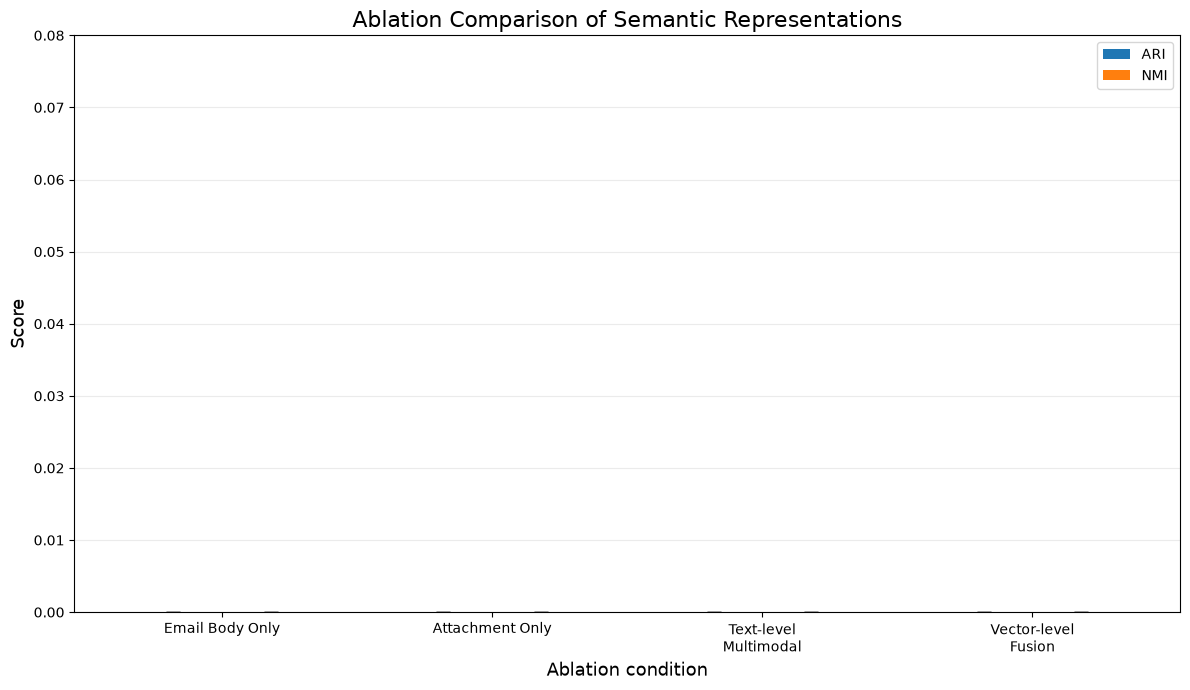


FINAL EXPERIMENT SUMMARY
Dataset: 17,319 samples
Ablation subset: 3,000 samples
Conditions: 4
Seeds: 10
Total clustering runs: 40
Total UMAP + Ward runtime: 38.12 min

Output files:

1. Per-seed results:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\ablation_4conditions_3000subset_seeds1-10.csv

2. Mean ± SD:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\ablation_4conditions_3000subset_mean_SD.csv

3. Effect sizes + 95% CI:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\ablation_4conditions_effect_sizes_95CI.csv

4. Wilcoxon + Holm:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\ablation_4conditions_Wilcoxon_Holm.csv

5. Verified 3,000-sample subset:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\ablation_verified_3000_attachment_text_subset.csv

6. Embedding runtime:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\ablation_embedding_runtime_summary.csv

7. Final ARI/NMI figure:
C:\Users\hmari\ai-generated-phishing-det

In [13]:
# ================================================================
# FINAL CORRECTED MULTIMODAL ABLATION EXPERIMENT
# ================================================================
#
# 4 CONDITIONS × 10 SEEDS
# SAME 3,000 ATTACHMENT-TEXT SAMPLES
#
# Condition 1: Email Body Only
# Condition 2: Attachment Text Only
# Condition 3: Text-level Multimodal
# Condition 4: Vector-level Fusion
#
# Embedding:
#   intfloat/e5-base-v2
#   768 dimensions
#   passage: prefix
#   normalized embeddings
#
# Dimensionality reduction:
#   UMAP
#   50 dimensions
#   n_neighbors = 15
#   min_dist = 0.1
#   metric = cosine
#
# Clustering:
#   Agglomerative Ward
#   k = 10
#
# Seeds:
#   1–10
#
# Statistical outputs:
#   Mean ± SD
#   Paired mean differences
#   95% CI
#   Cohen's dz
#   Wilcoxon signed-rank
#   Holm correction
#
# Figure:
#   Grouped ARI + NMI
#   600 DPI
# ================================================================


import os
import time
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, t

from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score,
    homogeneity_score,
    completeness_score
)

from sentence_transformers import SentenceTransformer
import umap.umap_ as umap


warnings.filterwarnings("ignore")


# ================================================================
# 1. CONFIGURATION
# ================================================================

BASE_DIR = (
    r"C:\Users\hmari"
    r"\ai-generated-phishing-detection-multimodal"
)

DATA_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_processed_data.csv"
)

CLUSTER_PATH = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_clusters.csv"
)

MODEL_NAME = "intfloat/e5-base-v2"

SEEDS = list(range(1, 11))

EXPECTED_TOTAL = 17319
EXPECTED_SUBSET = 3000

N_CLUSTERS = 10

UMAP_COMPONENTS = 50
UMAP_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1
UMAP_METRIC = "cosine"

BATCH_SIZE = 32

PREFIX = "passage: "


# ================================================================
# 2. OUTPUT FILES
# ================================================================

PER_SEED_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_4conditions_3000subset_seeds1-10.csv"
)

SUMMARY_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_4conditions_3000subset_mean_SD.csv"
)

EFFECT_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_4conditions_effect_sizes_95CI.csv"
)

WILCOXON_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_4conditions_Wilcoxon_Holm.csv"
)

SUBSET_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_verified_3000_attachment_text_subset.csv"
)

EMBEDDING_INFO_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_embedding_runtime_summary.csv"
)

FIGURE_OUTPUT = os.path.join(
    BASE_DIR,
    "Figure_5_Ablation_ARI_NMI_3000subset_600dpi.png"
)


# ================================================================
# 3. SYSTEM INFORMATION
# ================================================================

print("=" * 90)
print("FINAL CORRECTED MULTIMODAL ABLATION EXPERIMENT")
print("=" * 90)

print("\nSystem information")
print("-" * 90)

print(
    "Operating system:",
    platform.platform()
)

print(
    "Python:",
    platform.python_version()
)

try:

    import sklearn

    print(
        "scikit-learn:",
        sklearn.__version__
    )

except Exception:
    pass

try:

    import sentence_transformers

    print(
        "sentence-transformers:",
        sentence_transformers.__version__
    )

except Exception:
    pass

print(
    "Embedding model:",
    MODEL_NAME
)

print(
    "E5 prefix:",
    repr(PREFIX)
)

print(
    "Embedding dimension: 768"
)

print(
    "Seeds:",
    SEEDS
)

print(
    "Clusters:",
    N_CLUSTERS
)

print(
    "UMAP:",
    f"{UMAP_COMPONENTS}D"
)

print(
    "n_neighbors:",
    UMAP_NEIGHBORS
)

print(
    "min_dist:",
    UMAP_MIN_DIST
)

print(
    "metric:",
    UMAP_METRIC
)


# ================================================================
# 4. LOAD DATASET
# ================================================================

print("\n" + "=" * 90)
print("LOADING DATASET")
print("=" * 90)

df = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    low_memory=False
)

print(
    "Dataset shape:",
    df.shape
)

if len(df) != EXPECTED_TOTAL:

    raise ValueError(
        f"Expected {EXPECTED_TOTAL} rows, "
        f"but found {len(df)}."
    )

print(
    "✓ 17,319 rows confirmed."
)

print(
    "\nDataset columns:"
)

print(
    df.columns.tolist()
)


# ================================================================
# 5. VERIFY REQUIRED COLUMNS
# ================================================================

required_columns = [
    "text",
    "attachment_text",
    "attachment_paths",
    "label"
]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        "Missing required columns: "
        + str(missing_columns)
    )

print(
    "\n✓ Required dataset columns confirmed."
)


# ================================================================
# 6. IDENTIFY VERIFIED 3,000 ATTACHMENT-TEXT SAMPLES
# ================================================================

print("\n" + "=" * 90)
print("VERIFYING 3,000 ATTACHMENT-TEXT SUBSET")
print("=" * 90)


# IMPORTANT:
# The reviewer-corrected ablation uses the 3,000 samples
# with NON-EMPTY extracted attachment_text.
#
# We deliberately do NOT use attachment_paths to define
# the subset because there are 3,003 paths but only 3,000
# samples with extracted attachment text.

attachment_text_mask = (
    df["attachment_text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

attachment_indices = np.flatnonzero(
    attachment_text_mask.to_numpy()
)

n_subset = len(
    attachment_indices
)

print(
    "Rows with attachment_paths:",
    df["attachment_paths"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
    .sum()
)

print(
    "Rows with non-empty attachment_text:",
    n_subset
)

print(
    "Expected:",
    EXPECTED_SUBSET
)


if n_subset != EXPECTED_SUBSET:

    raise ValueError(
        f"Expected exactly {EXPECTED_SUBSET} "
        f"non-empty attachment_text rows, "
        f"but found {n_subset}."
    )

print(
    "\n✓ EXACTLY 3,000 ATTACHMENT-TEXT SAMPLES CONFIRMED."
)


# ================================================================
# 7. VERIFY THE THREE EXTRA ATTACHMENT PATHS
# ================================================================

path_mask = (
    df["attachment_paths"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

extra_indices = np.flatnonzero(
    (
        path_mask
        &
        ~attachment_text_mask
    ).to_numpy()
)

print(
    "\nAttachment-path rows without extracted text:",
    len(extra_indices)
)

print(
    "Indices:",
    extra_indices.tolist()
)

if len(extra_indices) == 3:

    print(
        "✓ Expected three excluded records confirmed."
    )

else:

    print(
        "Note: number of path-only records differs "
        "from the previously observed three."
    )


# ================================================================
# 8. SAVE VERIFIED SUBSET
# ================================================================

subset_output_df = pd.DataFrame({
    "row_index":
        attachment_indices
})

subset_output_df.to_csv(
    SUBSET_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

print(
    "\nVerified subset saved:"
)

print(
    SUBSET_OUTPUT
)


# ================================================================
# 9. LOAD ORIGINAL E5 CLUSTER FILE
# ================================================================

print("\n" + "=" * 90)
print("VERIFYING ORIGINAL CLUSTER FILE")
print("=" * 90)

clusters_df = pd.read_csv(
    CLUSTER_PATH
)

required_cluster_columns = [
    "row_index",
    "true_label",
    "cluster"
]

missing_cluster_columns = [
    col
    for col in required_cluster_columns
    if col not in clusters_df.columns
]

if missing_cluster_columns:

    raise ValueError(
        "Missing cluster-file columns: "
        + str(missing_cluster_columns)
    )

if len(clusters_df) != EXPECTED_TOTAL:

    raise ValueError(
        "Original cluster file does not contain "
        "17,319 rows."
    )

print(
    "Cluster file shape:",
    clusters_df.shape
)

print(
    "✓ Original E5-base-v2 cluster file confirmed."
)


# ================================================================
# 10. VERIFY ROW ORDER
# ================================================================

expected_row_index = np.arange(
    EXPECTED_TOTAL
)

if not np.array_equal(
    clusters_df["row_index"].to_numpy(),
    expected_row_index
):

    raise ValueError(
        "The cluster file row_index is not "
        "exactly 0–17318."
    )

print(
    "✓ Cluster-file row order confirmed."
)


# ================================================================
# 11. VERIFY LABEL ALIGNMENT
# ================================================================

dataset_labels = (
    df.loc[
        attachment_indices,
        "label"
    ]
    .astype(int)
    .to_numpy()
)

clusterfile_labels = (
    clusters_df.loc[
        attachment_indices,
        "true_label"
    ]
    .astype(int)
    .to_numpy()
)

if not np.array_equal(
    dataset_labels,
    clusterfile_labels
):

    raise ValueError(
        "Dataset labels and cluster-file "
        "true_label values do not match."
    )

true_labels = dataset_labels

print(
    "✓ Dataset labels and cluster-file labels match."
)


# ================================================================
# 12. SUBSET CLASS DISTRIBUTION
# ================================================================

print("\n" + "=" * 90)
print("3,000-SAMPLE SUBSET CLASS DISTRIBUTION")
print("=" * 90)

subset_class_counts = (
    pd.Series(true_labels)
    .value_counts()
    .sort_index()
)

print(
    subset_class_counts.to_string()
)

print(
    "\nTotal:",
    subset_class_counts.sum()
)


# ================================================================
# 13. EXTRACT TEXT
# ================================================================

body_text = (
    df.loc[
        attachment_indices,
        "text"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
    .reset_index(drop=True)
)

attachment_text = (
    df.loc[
        attachment_indices,
        "attachment_text"
    ]
    .fillna("")
    .astype(str)
    .str.strip()
    .reset_index(drop=True)
)


# ================================================================
# 14. CREATE TEXT-LEVEL MULTIMODAL INPUT
# ================================================================

multimodal_text = (
    "[EMAIL_BODY] "
    + body_text
    + " [ATTACHMENT_TEXT] "
    + attachment_text
)

print("\nText representation lengths:")
print(
    "Body:",
    len(body_text)
)

print(
    "Attachment:",
    len(attachment_text)
)

print(
    "Multimodal:",
    len(multimodal_text)
)


# ================================================================
# 15. ADD E5 PASSAGE PREFIX
# ================================================================

body_for_e5 = (
    PREFIX
    + body_text
)

attachment_for_e5 = (
    PREFIX
    + attachment_text
)

multimodal_for_e5 = (
    PREFIX
    + multimodal_text
)


# ================================================================
# 16. LOAD E5-BASE-V2
# ================================================================

print("\n" + "=" * 90)
print("LOADING E5-BASE-V2")
print("=" * 90)

model = SentenceTransformer(
    MODEL_NAME,
    device="cpu"
)

model.max_seq_length = 512

embedding_dimension = (
    model.get_sentence_embedding_dimension()
)

print(
    "Embedding dimension:",
    embedding_dimension
)

if embedding_dimension != 768:

    raise ValueError(
        "Expected 768-dimensional "
        "E5-base-v2 embeddings."
    )

print(
    "✓ E5-base-v2 verified as 768-dimensional."
)


# ================================================================
# 17. EMBEDDING FUNCTION
# ================================================================

def encode_texts(
    name,
    texts
):

    print(
        "\n" + "-" * 80
    )

    print(
        "Generating:",
        name
    )

    start = time.perf_counter()

    embeddings = model.encode(
        texts.tolist(),
        batch_size=BATCH_SIZE,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    elapsed = (
        time.perf_counter()
        - start
    )

    print(
        "Shape:",
        embeddings.shape
    )

    print(
        f"Runtime: {elapsed / 60:.2f} min"
    )

    if embeddings.shape != (
        EXPECTED_SUBSET,
        768
    ):

        raise ValueError(
            f"Unexpected embedding shape: "
            f"{embeddings.shape}"
        )

    # Confirm normalization
    norms = np.linalg.norm(
        embeddings,
        axis=1
    )

    print(
        "Mean L2 norm:",
        f"{norms.mean():.6f}"
    )

    return (
        embeddings,
        elapsed
    )


# ================================================================
# 18. GENERATE BODY EMBEDDINGS
# ================================================================

body_embeddings, body_embedding_time = (
    encode_texts(
        "Email Body Only",
        body_for_e5
    )
)


# ================================================================
# 19. GENERATE ATTACHMENT EMBEDDINGS
# ================================================================

attachment_embeddings, attachment_embedding_time = (
    encode_texts(
        "Attachment Text Only",
        attachment_for_e5
    )
)


# ================================================================
# 20. GENERATE TEXT-LEVEL MULTIMODAL EMBEDDINGS
# ================================================================

multimodal_embeddings, multimodal_embedding_time = (
    encode_texts(
        "Text-level Multimodal",
        multimodal_for_e5
    )
)


# ================================================================
# 21. VECTOR-LEVEL FUSION
# ================================================================

print("\n" + "=" * 90)
print("CREATING VECTOR-LEVEL FUSION")
print("=" * 90)

vector_fusion = np.hstack([
    body_embeddings,
    attachment_embeddings
])

print(
    "Before normalization:",
    vector_fusion.shape
)

vector_fusion = normalize(
    vector_fusion,
    norm="l2"
)

print(
    "After normalization:",
    vector_fusion.shape
)

if vector_fusion.shape != (
    EXPECTED_SUBSET,
    1536
):

    raise ValueError(
        f"Unexpected vector-fusion shape: "
        f"{vector_fusion.shape}"
    )

print(
    "✓ Vector-level fusion confirmed:"
)

print(
    "768-D body + 768-D attachment = 1536-D"
)


# ================================================================
# 22. FOUR EXPERIMENTAL CONDITIONS
# ================================================================

representations = {

    "Email Body Only":
        body_embeddings,

    "Attachment Text Only":
        attachment_embeddings,

    "Text-level Multimodal":
        multimodal_embeddings,

    "Vector-level Fusion":
        vector_fusion
}


# ================================================================
# 23. EMBEDDING RUNTIME SUMMARY
# ================================================================

embedding_runtime_rows = [

    {
        "Condition":
            "Email Body Only",

        "Embedding_Dimension":
            768,

        "Embedding_Runtime_min":
            body_embedding_time
            / 60
    },

    {
        "Condition":
            "Attachment Text Only",

        "Embedding_Dimension":
            768,

        "Embedding_Runtime_min":
            attachment_embedding_time
            / 60
    },

    {
        "Condition":
            "Text-level Multimodal",

        "Embedding_Dimension":
            768,

        "Embedding_Runtime_min":
            multimodal_embedding_time
            / 60
    },

    {
        "Condition":
            "Vector-level Fusion",

        "Embedding_Dimension":
            1536,

        "Embedding_Runtime_min":
            (
                body_embedding_time
                +
                attachment_embedding_time
            )
            / 60
    }
]

embedding_runtime_df = pd.DataFrame(
    embedding_runtime_rows
)

embedding_runtime_df.to_csv(
    EMBEDDING_INFO_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 24. CLUSTERING FUNCTION
# ================================================================

def run_umap_ward(
    X,
    seed
):

    # ------------------------------------------------------------
    # UMAP
    # ------------------------------------------------------------

    reducer = umap.UMAP(
        n_neighbors=UMAP_NEIGHBORS,
        min_dist=UMAP_MIN_DIST,
        n_components=UMAP_COMPONENTS,
        metric=UMAP_METRIC,
        random_state=seed
    )

    reduced = reducer.fit_transform(
        X
    )

    # ------------------------------------------------------------
    # Ward clustering
    # ------------------------------------------------------------

    clusterer = AgglomerativeClustering(
        n_clusters=N_CLUSTERS,
        linkage="ward",
        metric="euclidean"
    )

    predicted = clusterer.fit_predict(
        reduced
    )

    return (
        reduced,
        predicted
    )


# ================================================================
# 25. METRIC FUNCTION
# ================================================================

def calculate_metrics(
    reduced,
    predicted,
    true
):

    return {

        "Silhouette":
            silhouette_score(
                reduced,
                predicted
            ),

        "Davies_Bouldin":
            davies_bouldin_score(
                reduced,
                predicted
            ),

        "Calinski_Harabasz":
            calinski_harabasz_score(
                reduced,
                predicted
            ),

        "ARI":
            adjusted_rand_score(
                true,
                predicted
            ),

        "NMI":
            normalized_mutual_info_score(
                true,
                predicted,
                average_method="arithmetic"
            ),

        "AMI":
            adjusted_mutual_info_score(
                true,
                predicted,
                average_method="arithmetic"
            ),

        "Homogeneity":
            homogeneity_score(
                true,
                predicted
            ),

        "Completeness":
            completeness_score(
                true,
                predicted
            )
    }


# ================================================================
# 26. RUN 4 × 10 = 40 EXPERIMENTS
# ================================================================

print("\n" + "=" * 90)
print("RUNNING 4 CONDITIONS × 10 SEEDS = 40 CLUSTERING RUNS")
print("=" * 90)

results = []

all_partitions = {}

total_start = time.perf_counter()


for condition_name, X in representations.items():

    print(
        "\n"
        + "#" * 90
    )

    print(
        "CONDITION:",
        condition_name
    )

    print(
        "#" * 90
    )

    all_partitions[
        condition_name
    ] = {}

    for seed in SEEDS:

        print(
            f"\n{condition_name} | "
            f"Seed {seed}"
        )

        start = time.perf_counter()

        reduced, predicted = (
            run_umap_ward(
                X,
                seed
            )
        )

        metrics = calculate_metrics(
            reduced,
            predicted,
            true_labels
        )

        runtime = (
            time.perf_counter()
            - start
        )

        results.append({

            "Condition":
                condition_name,

            "Seed":
                seed,

            "N":
                EXPECTED_SUBSET,

            "Clusters":
                len(
                    np.unique(
                        predicted
                    )
                ),

            "Silhouette":
                metrics["Silhouette"],

            "Davies_Bouldin":
                metrics["Davies_Bouldin"],

            "Calinski_Harabasz":
                metrics["Calinski_Harabasz"],

            "ARI":
                metrics["ARI"],

            "NMI":
                metrics["NMI"],

            "AMI":
                metrics["AMI"],

            "Homogeneity":
                metrics["Homogeneity"],

            "Completeness":
                metrics["Completeness"],

            "Runtime_min":
                runtime / 60
        })

        all_partitions[
            condition_name
        ][seed] = predicted

        print(
            f"Silhouette = "
            f"{metrics['Silhouette']:.4f}"
        )

        print(
            f"DB = "
            f"{metrics['Davies_Bouldin']:.4f}"
        )

        print(
            f"CH = "
            f"{metrics['Calinski_Harabasz']:.2f}"
        )

        print(
            f"ARI = "
            f"{metrics['ARI']:.4f}"
        )

        print(
            f"NMI = "
            f"{metrics['NMI']:.4f}"
        )

        print(
            f"Runtime = "
            f"{runtime / 60:.2f} min"
        )


total_runtime = (
    time.perf_counter()
    - total_start
)

results_df = pd.DataFrame(
    results
)


# ================================================================
# 27. VALIDATE 40 RESULTS
# ================================================================

expected_runs = (
    4 * 10
)

if len(results_df) != expected_runs:

    raise ValueError(
        f"Expected {expected_runs} runs, "
        f"but obtained {len(results_df)}."
    )

print(
    "\n✓ All 40 clustering runs completed."
)


# ================================================================
# 28. SAVE PER-SEED RESULTS
# ================================================================

results_df.to_csv(
    PER_SEED_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

print(
    "\nPer-seed results saved:"
)

print(
    PER_SEED_OUTPUT
)


# ================================================================
# 29. MEAN ± SD
# ================================================================

metrics_to_summarize = [

    "Silhouette",

    "Davies_Bouldin",

    "Calinski_Harabasz",

    "ARI",

    "NMI",

    "AMI",

    "Homogeneity",

    "Completeness",

    "Runtime_min"
]

summary_rows = []

for condition in representations.keys():

    sub = results_df[
        results_df["Condition"]
        == condition
    ]

    row = {
        "Condition":
            condition
    }

    for metric in metrics_to_summarize:

        row[
            metric + "_Mean"
        ] = sub[metric].mean()

        row[
            metric + "_SD"
        ] = sub[metric].std(
            ddof=1
        )

    summary_rows.append(
        row
    )


summary_df = pd.DataFrame(
    summary_rows
)

summary_df.to_csv(
    SUMMARY_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 30. PAIRED EFFECT SIZE + 95% CI
# ================================================================

def paired_effect_size(
    a,
    b
):

    a = np.asarray(a)
    b = np.asarray(b)

    differences = (
        a - b
    )

    n = len(
        differences
    )

    mean_difference = (
        differences.mean()
    )

    sd_difference = (
        differences.std(
            ddof=1
        )
    )

    if sd_difference == 0:

        dz = np.nan

        ci_low = (
            mean_difference
        )

        ci_high = (
            mean_difference
        )

    else:

        dz = (
            mean_difference
            /
            sd_difference
        )

        standard_error = (
            sd_difference
            /
            np.sqrt(n)
        )

        t_critical = t.ppf(
            0.975,
            df=n - 1
        )

        ci_low = (
            mean_difference
            -
            t_critical
            *
            standard_error
        )

        ci_high = (
            mean_difference
            +
            t_critical
            *
            standard_error
        )

    return (
        mean_difference,
        ci_low,
        ci_high,
        dz
    )


conditions = list(
    representations.keys()
)

effect_rows = []


for i in range(
    len(conditions)
):

    for j in range(
        i + 1,
        len(conditions)
    ):

        condition_a = (
            conditions[i]
        )

        condition_b = (
            conditions[j]
        )

        for metric in [
            "ARI",
            "NMI"
        ]:

            a = (
                results_df[
                    results_df[
                        "Condition"
                    ]
                    ==
                    condition_a
                ]
                .sort_values(
                    "Seed"
                )[metric]
                .to_numpy()
            )

            b = (
                results_df[
                    results_df[
                        "Condition"
                    ]
                    ==
                    condition_b
                ]
                .sort_values(
                    "Seed"
                )[metric]
                .to_numpy()
            )

            (
                difference,
                ci_low,
                ci_high,
                dz
            ) = paired_effect_size(
                a,
                b
            )

            effect_rows.append({

                "Comparison":
                    f"{condition_a} vs {condition_b}",

                "Condition_A":
                    condition_a,

                "Condition_B":
                    condition_b,

                "Metric":
                    metric,

                "Mean_Paired_Difference":
                    difference,

                "95CI_Lower":
                    ci_low,

                "95CI_Upper":
                    ci_high,

                "Cohens_dz":
                    dz
            })


effect_df = pd.DataFrame(
    effect_rows
)

effect_df.to_csv(
    EFFECT_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 31. WILCOXON SIGNED-RANK + HOLM CORRECTION
# ================================================================

wilcoxon_rows = []


for metric in [
    "ARI",
    "NMI"
]:

    temporary_rows = []

    raw_p_values = []


    for i in range(
        len(conditions)
    ):

        for j in range(
            i + 1,
            len(conditions)
        ):

            condition_a = (
                conditions[i]
            )

            condition_b = (
                conditions[j]
            )

            a = (
                results_df[
                    results_df[
                        "Condition"
                    ]
                    ==
                    condition_a
                ]
                .sort_values(
                    "Seed"
                )[metric]
                .to_numpy()
            )

            b = (
                results_df[
                    results_df[
                        "Condition"
                    ]
                    ==
                    condition_b
                ]
                .sort_values(
                    "Seed"
                )[metric]
                .to_numpy()
            )


            # ----------------------------------------------------
            # Wilcoxon
            # ----------------------------------------------------

            differences = (
                a - b
            )

            if np.allclose(
                differences,
                0
            ):

                statistic = 0.0
                p_value = 1.0

            else:

                test = wilcoxon(
                    a,
                    b,
                    alternative="two-sided",
                    method="auto"
                )

                statistic = (
                    test.statistic
                )

                p_value = (
                    test.pvalue
                )


            temporary_rows.append({

                "Metric":
                    metric,

                "Comparison":
                    f"{condition_a} vs {condition_b}",

                "Condition_A":
                    condition_a,

                "Condition_B":
                    condition_b,

                "Wilcoxon_statistic":
                    statistic,

                "Raw_p":
                    p_value
            })

            raw_p_values.append(
                p_value
            )


    # ------------------------------------------------------------
    # Holm correction
    # ------------------------------------------------------------

    m = len(
        raw_p_values
    )

    order = np.argsort(
        raw_p_values
    )

    adjusted = np.zeros(
        m
    )

    running_max = 0.0


    for rank, index in enumerate(
        order
    ):

        corrected = (
            (m - rank)
            *
            raw_p_values[index]
        )

        running_max = max(
            running_max,
            corrected
        )

        adjusted[index] = min(
            running_max,
            1.0
        )


    for k, row in enumerate(
        temporary_rows
    ):

        row[
            "Holm_adjusted_p"
        ] = adjusted[k]

        wilcoxon_rows.append(
            row
        )


wilcoxon_df = pd.DataFrame(
    wilcoxon_rows
)

wilcoxon_df.to_csv(
    WILCOXON_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 32. PRINT FINAL MEAN ± SD
# ================================================================

print("\n" + "=" * 90)
print("FINAL ABLATION RESULTS — MEAN ± SD")
print("=" * 90)


for _, row in summary_df.iterrows():

    print(
        f"\n{row['Condition']}"
    )

    print(
        f"Silhouette: "
        f"{row['Silhouette_Mean']:.4f} ± "
        f"{row['Silhouette_SD']:.4f}"
    )

    print(
        f"Davies-Bouldin: "
        f"{row['Davies_Bouldin_Mean']:.4f} ± "
        f"{row['Davies_Bouldin_SD']:.4f}"
    )

    print(
        f"Calinski-Harabasz: "
        f"{row['Calinski_Harabasz_Mean']:.2f} ± "
        f"{row['Calinski_Harabasz_SD']:.2f}"
    )

    print(
        f"ARI: "
        f"{row['ARI_Mean']:.4f} ± "
        f"{row['ARI_SD']:.4f}"
    )

    print(
        f"NMI: "
        f"{row['NMI_Mean']:.4f} ± "
        f"{row['NMI_SD']:.4f}"
    )

    print(
        f"AMI: "
        f"{row['AMI_Mean']:.4f} ± "
        f"{row['AMI_SD']:.4f}"
    )

    print(
        f"Homogeneity: "
        f"{row['Homogeneity_Mean']:.4f} ± "
        f"{row['Homogeneity_SD']:.4f}"
    )

    print(
        f"Completeness: "
        f"{row['Completeness_Mean']:.4f} ± "
        f"{row['Completeness_SD']:.4f}"
    )


# ================================================================
# 33. PRINT EFFECT SIZES
# ================================================================

print("\n" + "=" * 90)
print("PAIRED EFFECT SIZES — ARI AND NMI")
print("=" * 90)

print(
    effect_df.to_string(
        index=False,
        float_format=lambda x:
        f"{x:.6f}"
    )
)


# ================================================================
# 34. PRINT WILCOXON RESULTS
# ================================================================

print("\n" + "=" * 90)
print("WILCOXON SIGNED-RANK — HOLM CORRECTED")
print("=" * 90)

print(
    wilcoxon_df.to_string(
        index=False,
        float_format=lambda x:
        f"{x:.6f}"
    )
)


# ================================================================
# 35. FINAL GROUPED ARI/NMI FIGURE
# ================================================================

print("\n" + "=" * 90)
print("GENERATING FINAL ARI/NMI FIGURE")
print("=" * 90)


ari_means = []
ari_sds = []

nmi_means = []
nmi_sds = []


for condition in conditions:

    sub = results_df[
        results_df["Condition"]
        == condition
    ]

    ari_means.append(
        sub["ARI"].mean()
    )

    ari_sds.append(
        sub["ARI"].std(
            ddof=1
        )
    )

    nmi_means.append(
        sub["NMI"].mean()
    )

    nmi_sds.append(
        sub["NMI"].std(
            ddof=1
        )
    )


x = np.arange(
    len(conditions)
)

width = 0.36


fig, ax = plt.subplots(
    figsize=(12, 7)
)


ax.bar(
    x - width / 2,
    ari_means,
    width,
    yerr=ari_sds,
    capsize=5,
    label="ARI"
)


ax.bar(
    x + width / 2,
    nmi_means,
    width,
    yerr=nmi_sds,
    capsize=5,
    label="NMI"
)


ax.set_xlabel(
    "Ablation condition",
    fontsize=13
)


ax.set_ylabel(
    "Score",
    fontsize=13
)


ax.set_title(
    "Ablation Comparison of Semantic Representations",
    fontsize=16
)


ax.set_xticks(
    x
)


ax.set_xticklabels([
    "Email Body Only",
    "Attachment Only",
    "Text-level\nMultimodal",
    "Vector-level\nFusion"
])


maximum = max(

    max(
        np.array(ari_means)
        +
        np.array(ari_sds)
    ),

    max(
        np.array(nmi_means)
        +
        np.array(nmi_sds)
    )
)


ax.set_ylim(
    0,
    maximum + 0.08
)


ax.legend()


ax.grid(
    axis="y",
    alpha=0.25
)


fig.tight_layout()


fig.savefig(
    FIGURE_OUTPUT,
    dpi=600,
    bbox_inches="tight"
)


plt.show()


# ================================================================
# 36. FINAL OUTPUT SUMMARY
# ================================================================

print("\n" + "=" * 90)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 90)

print(
    "Dataset:",
    f"{EXPECTED_TOTAL:,} samples"
)

print(
    "Ablation subset:",
    f"{EXPECTED_SUBSET:,} samples"
)

print(
    "Conditions:",
    len(representations)
)

print(
    "Seeds:",
    len(SEEDS)
)

print(
    "Total clustering runs:",
    len(results_df)
)

print(
    f"Total UMAP + Ward runtime: "
    f"{total_runtime / 60:.2f} min"
)


print("\nOutput files:")

print(
    "\n1. Per-seed results:"
)

print(
    PER_SEED_OUTPUT
)


print(
    "\n2. Mean ± SD:"
)

print(
    SUMMARY_OUTPUT
)


print(
    "\n3. Effect sizes + 95% CI:"
)

print(
    EFFECT_OUTPUT
)


print(
    "\n4. Wilcoxon + Holm:"
)

print(
    WILCOXON_OUTPUT
)


print(
    "\n5. Verified 3,000-sample subset:"
)

print(
    SUBSET_OUTPUT
)


print(
    "\n6. Embedding runtime:"
)

print(
    EMBEDDING_INFO_OUTPUT
)


print(
    "\n7. Final ARI/NMI figure:"
)

print(
    FIGURE_OUTPUT
)


print("\n" + "=" * 90)
print("✓ CORRECTED ABLATION EXPERIMENT COMPLETE")
print("=" * 90) 

In [14]:
# ================================================================
# VERIFY CLASS DISTRIBUTION OF THE 3,000 ATTACHMENT-TEXT SUBSET
# ================================================================

subset_labels = (
    df.loc[
        attachment_indices,
        "label"
    ]
    .astype(int)
)

print("=" * 80)
print("3,000-SAMPLE ATTACHMENT-TEXT SUBSET — CLASS DISTRIBUTION")
print("=" * 80)

counts = (
    subset_labels
    .value_counts()
    .sort_index()
)

print(counts)

print("\nPercentages:")
print(
    (counts / len(subset_labels) * 100)
    .round(2)
)

print("\nNumber of unique classes:", subset_labels.nunique())
print("Total samples:", len(subset_labels))

if subset_labels.nunique() == 1:
    print(
        "\n⚠ DEGENERATE EXTERNAL-EVALUATION SUBSET:"
        "\nOnly one ground-truth class is represented."
    )
else:
    print(
        "\n✓ Multiple ground-truth classes are represented."
    ) 

3,000-SAMPLE ATTACHMENT-TEXT SUBSET — CLASS DISTRIBUTION
label
3    3000
Name: count, dtype: int64

Percentages:
label
3    100.0
Name: count, dtype: float64

Number of unique classes: 1
Total samples: 3000

⚠ DEGENERATE EXTERNAL-EVALUATION SUBSET:
Only one ground-truth class is represented.


PRIMARY FULL-CORPUS MULTIMODAL ABLATION

System
------------------------------------------------------------------------------------------
Operating system: Windows-11-10.0.26200-SP0
Python: 3.13.1
scikit-learn: 1.9.0
sentence-transformers: 5.6.0

Embedding model: intfloat/e5-base-v2
E5 prefix: 'passage: '
Dataset: 17,319 samples
Seeds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Clusters: 10
UMAP: 50D
n_neighbors: 15
min_dist: 0.1
metric: cosine

LOADING DATASET
Dataset shape: (17319, 7)
✓ 17,319 samples confirmed.
✓ Required columns confirmed.

PREPARING EMAIL BODY REPRESENTATION
Total samples: 17319
Missing/empty body: 1

PREPARING ATTACHMENT REPRESENTATION
Total samples: 17319
Non-empty attachment text: 3000
Missing attachment text: 14319

✓ Missing attachments will be represented as: [NO_ATTACHMENT]

CREATING TEXT-LEVEL MULTIMODAL REPRESENTATION
✓ Multimodal representation created.
Samples: 17319

LOADING E5-BASE-V2


Loading weights: 100%|█████████████████████| 199/199 [00:00<00:00, 381.19it/s, Materializing param=pooler.dense.weight]
BertModel LOAD REPORT from: intfloat/e5-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embedding dimension: 768
Model loading time: 0.09 min
✓ E5-base-v2 768-D representation confirmed.

--------------------------------------------------------------------------------
Embedding: Email Body Only


Batches: 100%|█████████████████████████████████████████████████████████████████████| 542/542 [1:31:59<00:00, 10.18s/it]


Shape: (17319, 768)
Runtime: 92.00 min
Mean L2 norm: 1.000000

--------------------------------------------------------------------------------
Embedding: Attachment Text Only


Batches: 100%|███████████████████████████████████████████████████████████████████████| 542/542 [10:23<00:00,  1.15s/it]


Shape: (17319, 768)
Runtime: 10.39 min
Mean L2 norm: 1.000000

--------------------------------------------------------------------------------
Embedding: Text-level Multimodal


Batches:  97%|██████████████████████████████████████████████████████████████████▋  | 524/542 [1:38:55<00:48,  2.71s/it]

Silhouette = 0.4318
DB = 1.9200
CH = 2035.45
ARI = 0.5338
NMI = 0.6228
AMI = 0.6226
Runtime = 1.64 min

Email Body Only | Seed 3
Silhouette = 0.4159
DB = 1.9092
CH = 1959.79
ARI = 0.5212
NMI = 0.6053
AMI = 0.6052
Runtime = 1.73 min

Email Body Only | Seed 4
Silhouette = 0.4198
DB = 2.0391
CH = 2090.73
ARI = 0.5108
NMI = 0.5928
AMI = 0.5926
Runtime = 1.33 min

Email Body Only | Seed 5
Silhouette = 0.4263
DB = 1.9759
CH = 2007.55
ARI = 0.5163
NMI = 0.6002
AMI = 0.6001
Runtime = 1.68 min

Email Body Only | Seed 6
Silhouette = 0.3989
DB = 2.0949
CH = 1809.69
ARI = 0.5120
NMI = 0.5790
AMI = 0.5788
Runtime = 1.27 min

Email Body Only | Seed 7
Silhouette = 0.4182
DB = 2.0675
CH = 2052.16
ARI = 0.5448
NMI = 0.6291
AMI = 0.6289
Runtime = 1.27 min

Email Body Only | Seed 8
Silhouette = 0.3984
DB = 2.1331
CH = 1800.22
ARI = 0.5026
NMI = 0.5818
AMI = 0.5816
Runtime = 1.28 min

Email Body Only | Seed 9
Silhouette = 0.4001
DB = 2.0786
CH = 1860.64
ARI = 0.5217
NMI = 0.5998
AMI = 0.5996
Runtime = 1.7

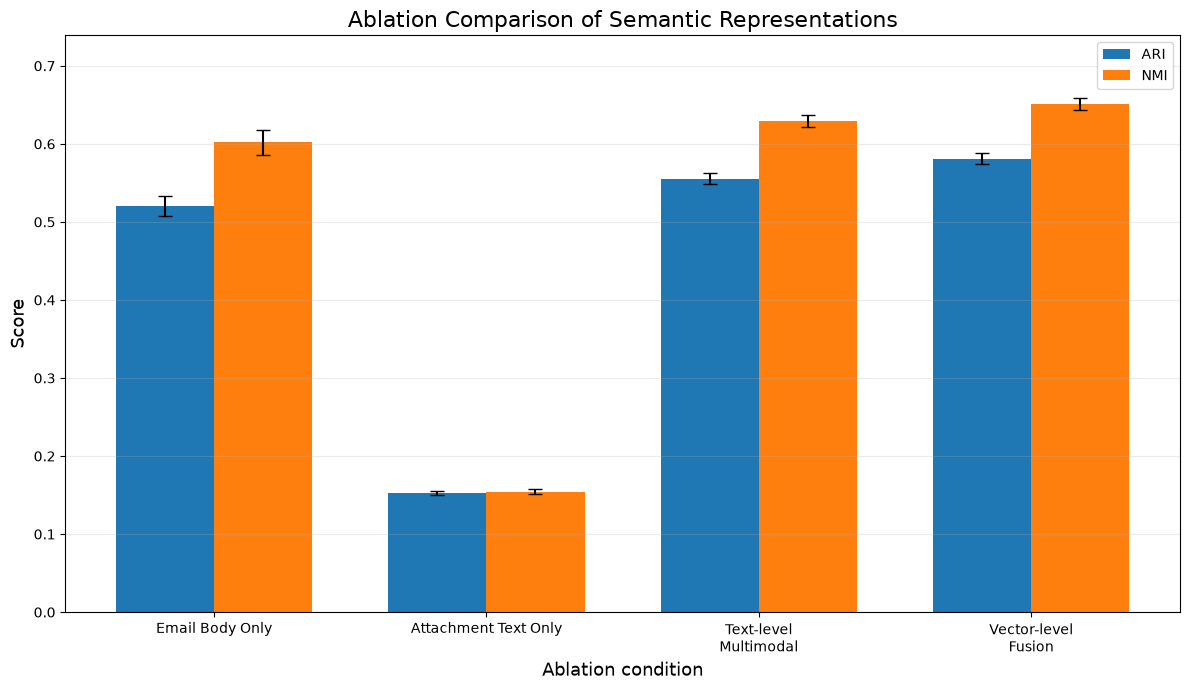


FINAL OUTPUT FILES

1. Per-seed results:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\ablation_full_corpus_4conditions_seeds1-10.csv

2. Mean ± SD:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\ablation_full_corpus_mean_SD.csv

3. Effect sizes + 95% CI:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\ablation_full_corpus_effect_sizes_95CI.csv

4. Wilcoxon + Holm:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\ablation_full_corpus_Wilcoxon_Holm.csv

5. Embedding runtime:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\ablation_full_corpus_embedding_runtime.csv

6. Saved partitions:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\ablation_full_corpus_partitions.npy

7. Final figure:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\Figure_5_Ablation_ARI_NMI_FullCorpus_600dpi.png

FINAL VERIFICATION
✓ Dataset: 17,319 samples
✓ Conditions: 4
✓ Seeds: 10
✓ Total runs: 40
✓ Missing attachments encoded as: [NO_ATTACHME

In [15]:
# ================================================================
# PRIMARY FULL-CORPUS MULTIMODAL ABLATION EXPERIMENT
# ================================================================
#
# Dataset: 17,319 samples
#
# Conditions:
#   1. Email Body Only
#   2. Attachment Text Only
#   3. Text-level Multimodal
#   4. Vector-level Fusion
#
# Embedding:
#   intfloat/e5-base-v2
#   768 dimensions
#   E5 "passage:" prefix
#   normalized embeddings
#
# Missing attachment:
#   [NO_ATTACHMENT]
#
# Missing body:
#   [NO_BODY]
#
# Dimensionality reduction:
#   UMAP
#   n_components = 50
#   n_neighbors = 15
#   min_dist = 0.1
#   metric = cosine
#
# Clustering:
#   Agglomerative Hierarchical Clustering
#   Ward linkage
#   k = 10
#
# Seeds:
#   1–10
#
# Evaluation:
#   Silhouette
#   Davies–Bouldin
#   Calinski–Harabasz
#   ARI
#   NMI
#   AMI
#   Homogeneity
#   Completeness
#
# Statistics:
#   Mean ± SD
#   Paired mean difference
#   Cohen's dz
#   95% CI
#   Wilcoxon signed-rank
#   Holm correction
#
# ================================================================


import os
import time
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, t

from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score,
    homogeneity_score,
    completeness_score
)

from sentence_transformers import SentenceTransformer
import umap.umap_ as umap


warnings.filterwarnings("ignore")


# ================================================================
# 1. CONFIGURATION
# ================================================================

BASE_DIR = (
    r"C:\Users\hmari"
    r"\ai-generated-phishing-detection-multimodal"
)

DATA_PATH = os.path.join(
    BASE_DIR,
    "unsupervised_processed_data.csv"
)

MODEL_NAME = "intfloat/e5-base-v2"

SEEDS = list(range(1, 11))

N_SAMPLES = 17319

N_CLUSTERS = 10

UMAP_COMPONENTS = 50
UMAP_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1
UMAP_METRIC = "cosine"

BATCH_SIZE = 32

E5_PREFIX = "passage: "

NO_ATTACHMENT = "[NO_ATTACHMENT]"
NO_BODY = "[NO_BODY]"


# ================================================================
# 2. OUTPUT PATHS
# ================================================================

PER_SEED_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_full_corpus_4conditions_seeds1-10.csv"
)

SUMMARY_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_full_corpus_mean_SD.csv"
)

EFFECT_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_full_corpus_effect_sizes_95CI.csv"
)

WILCOXON_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_full_corpus_Wilcoxon_Holm.csv"
)

EMBEDDING_RUNTIME_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_full_corpus_embedding_runtime.csv"
)

PARTITION_OUTPUT = os.path.join(
    BASE_DIR,
    "ablation_full_corpus_partitions.npy"
)

FIGURE_OUTPUT = os.path.join(
    BASE_DIR,
    "Figure_5_Ablation_ARI_NMI_FullCorpus_600dpi.png"
)


# ================================================================
# 3. SYSTEM INFORMATION
# ================================================================

print("=" * 90)
print("PRIMARY FULL-CORPUS MULTIMODAL ABLATION")
print("=" * 90)

print("\nSystem")
print("-" * 90)

print(
    "Operating system:",
    platform.platform()
)

print(
    "Python:",
    platform.python_version()
)

try:
    import sklearn
    print(
        "scikit-learn:",
        sklearn.__version__
    )
except:
    pass

try:
    import sentence_transformers
    print(
        "sentence-transformers:",
        sentence_transformers.__version__
    )
except:
    pass

try:
    print(
        "UMAP:",
        umap.__version__
    )
except:
    pass

print(
    "\nEmbedding model:",
    MODEL_NAME
)

print(
    "E5 prefix:",
    repr(E5_PREFIX)
)

print(
    "Dataset:",
    f"{N_SAMPLES:,} samples"
)

print(
    "Seeds:",
    SEEDS
)

print(
    "Clusters:",
    N_CLUSTERS
)

print(
    "UMAP:",
    f"{UMAP_COMPONENTS}D"
)

print(
    "n_neighbors:",
    UMAP_NEIGHBORS
)

print(
    "min_dist:",
    UMAP_MIN_DIST
)

print(
    "metric:",
    UMAP_METRIC
)


# ================================================================
# 4. LOAD DATASET
# ================================================================

print("\n" + "=" * 90)
print("LOADING DATASET")
print("=" * 90)

df = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    low_memory=False
)

print(
    "Dataset shape:",
    df.shape
)

if len(df) != N_SAMPLES:
    raise ValueError(
        f"Expected {N_SAMPLES} rows, "
        f"found {len(df)}."
    )

print(
    "✓ 17,319 samples confirmed."
)

required_columns = [
    "text",
    "attachment_text",
    "attachment_paths",
    "label"
]

missing_columns = [
    c
    for c in required_columns
    if c not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

print(
    "✓ Required columns confirmed."
)


# ================================================================
# 5. PREPARE BODY TEXT
# ================================================================

print("\n" + "=" * 90)
print("PREPARING EMAIL BODY REPRESENTATION")
print("=" * 90)

body_text = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

body_missing = (
    body_text == ""
)

body_text_final = body_text.copy()

body_text_final.loc[
    body_missing
] = NO_BODY

print(
    "Total samples:",
    len(body_text_final)
)

print(
    "Missing/empty body:",
    int(body_missing.sum())
)


# ================================================================
# 6. PREPARE ATTACHMENT TEXT
# ================================================================

print("\n" + "=" * 90)
print("PREPARING ATTACHMENT REPRESENTATION")
print("=" * 90)

attachment_text = (
    df["attachment_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

attachment_missing = (
    attachment_text == ""
)

attachment_text_final = (
    attachment_text.copy()
)

attachment_text_final.loc[
    attachment_missing
] = NO_ATTACHMENT

print(
    "Total samples:",
    len(attachment_text_final)
)

print(
    "Non-empty attachment text:",
    int(
        (~attachment_missing).sum()
    )
)

print(
    "Missing attachment text:",
    int(
        attachment_missing.sum()
    )
)

print(
    "\n✓ Missing attachments will be represented as:",
    NO_ATTACHMENT
)


# ================================================================
# 7. CREATE MULTIMODAL TEXT
# ================================================================

print("\n" + "=" * 90)
print("CREATING TEXT-LEVEL MULTIMODAL REPRESENTATION")
print("=" * 90)

multimodal_text = (
    "[EMAIL_BODY] "
    + body_text_final
    + " [ATTACHMENT_TEXT] "
    + attachment_text_final
)

print(
    "✓ Multimodal representation created."
)

print(
    "Samples:",
    len(multimodal_text)
)


# ================================================================
# 8. ADD E5 PREFIX
# ================================================================

body_e5_text = (
    E5_PREFIX
    + body_text_final
)

attachment_e5_text = (
    E5_PREFIX
    + attachment_text_final
)

multimodal_e5_text = (
    E5_PREFIX
    + multimodal_text
)


# ================================================================
# 9. LOAD E5-BASE-V2
# ================================================================

print("\n" + "=" * 90)
print("LOADING E5-BASE-V2")
print("=" * 90)

model_start = time.perf_counter()

model = SentenceTransformer(
    MODEL_NAME,
    device="cpu"
)

model.max_seq_length = 512

model_load_time = (
    time.perf_counter()
    - model_start
)

embedding_dimension = (
    model.get_sentence_embedding_dimension()
)

print(
    "Embedding dimension:",
    embedding_dimension
)

print(
    f"Model loading time: "
    f"{model_load_time / 60:.2f} min"
)

if embedding_dimension != 768:
    raise ValueError(
        "E5-base-v2 did not produce 768-D embeddings."
    )

print(
    "✓ E5-base-v2 768-D representation confirmed."
)


# ================================================================
# 10. EMBEDDING FUNCTION
# ================================================================

def generate_embeddings(
    name,
    texts
):

    print(
        "\n" + "-" * 80
    )

    print(
        "Embedding:",
        name
    )

    start = time.perf_counter()

    embeddings = model.encode(
        texts.tolist(),
        batch_size=BATCH_SIZE,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    elapsed = (
        time.perf_counter()
        - start
    )

    print(
        "Shape:",
        embeddings.shape
    )

    print(
        f"Runtime: "
        f"{elapsed / 60:.2f} min"
    )

    if embeddings.shape != (
        N_SAMPLES,
        768
    ):
        raise ValueError(
            f"Unexpected shape: "
            f"{embeddings.shape}"
        )

    norms = np.linalg.norm(
        embeddings,
        axis=1
    )

    print(
        f"Mean L2 norm: "
        f"{norms.mean():.6f}"
    )

    return (
        embeddings,
        elapsed
    )


# ================================================================
# 11. GENERATE BODY EMBEDDINGS
# ================================================================

body_embeddings, body_time = (
    generate_embeddings(
        "Email Body Only",
        body_e5_text
    )
)


# ================================================================
# 12. GENERATE ATTACHMENT EMBEDDINGS
# ================================================================

attachment_embeddings, attachment_time = (
    generate_embeddings(
        "Attachment Text Only",
        attachment_e5_text
    )
)


# ================================================================
# 13. GENERATE TEXT-LEVEL MULTIMODAL EMBEDDINGS
# ================================================================

multimodal_embeddings, multimodal_time = (
    generate_embeddings(
        "Text-level Multimodal",
        multimodal_e5_text
    )
)


# ================================================================
# 14. VECTOR-LEVEL FUSION
# ================================================================

print("\n" + "=" * 90)
print("CREATING VECTOR-LEVEL FUSION")
print("=" * 90)

vector_fusion = np.hstack(
    [
        body_embeddings,
        attachment_embeddings
    ]
)

print(
    "Unnormalized fusion shape:",
    vector_fusion.shape
)

vector_fusion = normalize(
    vector_fusion,
    norm="l2"
)

print(
    "Normalized fusion shape:",
    vector_fusion.shape
)

if vector_fusion.shape != (
    N_SAMPLES,
    1536
):
    raise ValueError(
        "Unexpected vector-fusion shape."
    )

print(
    "✓ 768-D body + 768-D attachment = 1536-D."
)


# ================================================================
# 15. SAVE EMBEDDING RUNTIME INFORMATION
# ================================================================

embedding_runtime_df = pd.DataFrame({

    "Condition": [
        "Email Body Only",
        "Attachment Text Only",
        "Text-level Multimodal",
        "Vector-level Fusion"
    ],

    "Embedding_Dimension": [
        768,
        768,
        768,
        1536
    ],

    "Embedding_Runtime_min": [

        body_time / 60,

        attachment_time / 60,

        multimodal_time / 60,

        (
            body_time
            +
            attachment_time
        ) / 60
    ]
})

embedding_runtime_df.to_csv(
    EMBEDDING_RUNTIME_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 16. FOUR REPRESENTATIONS
# ================================================================

representations = {

    "Email Body Only":
        body_embeddings,

    "Attachment Text Only":
        attachment_embeddings,

    "Text-level Multimodal":
        multimodal_embeddings,

    "Vector-level Fusion":
        vector_fusion
}


# ================================================================
# 17. CLUSTERING FUNCTION
# ================================================================

def run_umap_ward(
    X,
    seed
):

    reducer = umap.UMAP(

        n_neighbors=
            UMAP_NEIGHBORS,

        min_dist=
            UMAP_MIN_DIST,

        n_components=
            UMAP_COMPONENTS,

        metric=
            UMAP_METRIC,

        random_state=
            seed
    )

    reduced = (
        reducer.fit_transform(X)
    )

    clusterer = (
        AgglomerativeClustering(

            n_clusters=
                N_CLUSTERS,

            linkage=
                "ward",

            metric=
                "euclidean"
        )
    )

    clusters = (
        clusterer.fit_predict(
            reduced
        )
    )

    return (
        reduced,
        clusters
    )


# ================================================================
# 18. METRIC FUNCTION
# ================================================================

def calculate_metrics(
    reduced,
    clusters,
    labels
):

    return {

        "Silhouette":
            silhouette_score(
                reduced,
                clusters
            ),

        "Davies_Bouldin":
            davies_bouldin_score(
                reduced,
                clusters
            ),

        "Calinski_Harabasz":
            calinski_harabasz_score(
                reduced,
                clusters
            ),

        "ARI":
            adjusted_rand_score(
                labels,
                clusters
            ),

        "NMI":
            normalized_mutual_info_score(
                labels,
                clusters,
                average_method="arithmetic"
            ),

        "AMI":
            adjusted_mutual_info_score(
                labels,
                clusters,
                average_method="arithmetic"
            ),

        "Homogeneity":
            homogeneity_score(
                labels,
                clusters
            ),

        "Completeness":
            completeness_score(
                labels,
                clusters
            )
    }


# ================================================================
# 19. TRUE LABELS
# ================================================================

true_labels = (
    df["label"]
    .astype(int)
    .to_numpy()
)

print("\n" + "=" * 90)
print("GROUND-TRUTH LABEL DISTRIBUTION")
print("=" * 90)

print(
    pd.Series(
        true_labels
    )
    .value_counts()
    .sort_index()
)


# ================================================================
# 20. RUN 40 EXPERIMENTS
# ================================================================

print("\n" + "=" * 90)
print("RUNNING 4 CONDITIONS × 10 SEEDS = 40 RUNS")
print("=" * 90)

results = []

partition_store = {}

total_start = time.perf_counter()


for condition_name, X in representations.items():

    print(
        "\n" + "#" * 90
    )

    print(
        "CONDITION:",
        condition_name
    )

    print(
        "#" * 90
    )

    partition_store[
        condition_name
    ] = {}

    for seed in SEEDS:

        print(
            f"\n{condition_name} "
            f"| Seed {seed}"
        )

        start = time.perf_counter()

        reduced, clusters = (
            run_umap_ward(
                X,
                seed
            )
        )

        metrics = calculate_metrics(
            reduced,
            clusters,
            true_labels
        )

        elapsed = (
            time.perf_counter()
            - start
        )

        results.append({

            "Condition":
                condition_name,

            "Seed":
                seed,

            "N":
                N_SAMPLES,

            "Clusters":
                len(
                    np.unique(
                        clusters
                    )
                ),

            "Silhouette":
                metrics[
                    "Silhouette"
                ],

            "Davies_Bouldin":
                metrics[
                    "Davies_Bouldin"
                ],

            "Calinski_Harabasz":
                metrics[
                    "Calinski_Harabasz"
                ],

            "ARI":
                metrics[
                    "ARI"
                ],

            "NMI":
                metrics[
                    "NMI"
                ],

            "AMI":
                metrics[
                    "AMI"
                ],

            "Homogeneity":
                metrics[
                    "Homogeneity"
                ],

            "Completeness":
                metrics[
                    "Completeness"
                ],

            "Runtime_min":
                elapsed / 60
        })

        partition_store[
            condition_name
        ][seed] = clusters

        print(
            f"Silhouette = "
            f"{metrics['Silhouette']:.4f}"
        )

        print(
            f"DB = "
            f"{metrics['Davies_Bouldin']:.4f}"
        )

        print(
            f"CH = "
            f"{metrics['Calinski_Harabasz']:.2f}"
        )

        print(
            f"ARI = "
            f"{metrics['ARI']:.4f}"
        )

        print(
            f"NMI = "
            f"{metrics['NMI']:.4f}"
        )

        print(
            f"AMI = "
            f"{metrics['AMI']:.4f}"
        )

        print(
            f"Runtime = "
            f"{elapsed / 60:.2f} min"
        )


total_runtime = (
    time.perf_counter()
    - total_start
)

results_df = pd.DataFrame(
    results
)


# ================================================================
# 21. VERIFY 40 RUNS
# ================================================================

if len(results_df) != 40:

    raise ValueError(
        f"Expected 40 runs, "
        f"obtained {len(results_df)}."
    )

print(
    "\n✓ All 40 runs completed."
)


# ================================================================
# 22. SAVE PER-SEED RESULTS
# ================================================================

results_df.to_csv(
    PER_SEED_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)

print(
    "\nPer-seed results saved:"
)

print(
    PER_SEED_OUTPUT
)


# ================================================================
# 23. SAVE PARTITIONS
# ================================================================

partition_array = np.zeros(
    (
        4,
        10,
        N_SAMPLES
    ),
    dtype=np.int8
)

condition_names = list(
    representations.keys()
)

for c, condition in enumerate(
    condition_names
):

    for s, seed in enumerate(
        SEEDS
    ):

        partition_array[
            c,
            s,
            :
        ] = partition_store[
            condition
        ][seed]


np.save(
    PARTITION_OUTPUT,
    partition_array
)

print(
    "\nPartition file saved:"
)

print(
    PARTITION_OUTPUT
)

print(
    "Partition shape:",
    partition_array.shape
)


# ================================================================
# 24. MEAN ± SD SUMMARY
# ================================================================

summary_metrics = [

    "Silhouette",

    "Davies_Bouldin",

    "Calinski_Harabasz",

    "ARI",

    "NMI",

    "AMI",

    "Homogeneity",

    "Completeness",

    "Runtime_min"
]

summary_rows = []


for condition in condition_names:

    subset = results_df[
        results_df["Condition"]
        == condition
    ]

    row = {
        "Condition":
            condition
    }

    for metric in summary_metrics:

        row[
            metric + "_Mean"
        ] = subset[
            metric
        ].mean()

        row[
            metric + "_SD"
        ] = subset[
            metric
        ].std(
            ddof=1
        )

    summary_rows.append(
        row
    )


summary_df = pd.DataFrame(
    summary_rows
)

summary_df.to_csv(
    SUMMARY_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 25. EFFECT SIZE + 95% CI
# ================================================================

def paired_effect_size(
    a,
    b
):

    differences = (
        np.asarray(a)
        -
        np.asarray(b)
    )

    n = len(
        differences
    )

    mean_difference = (
        differences.mean()
    )

    sd_difference = (
        differences.std(
            ddof=1
        )
    )

    if sd_difference == 0:

        dz = np.nan

        ci_low = (
            mean_difference
        )

        ci_high = (
            mean_difference
        )

    else:

        dz = (
            mean_difference
            /
            sd_difference
        )

        se = (
            sd_difference
            /
            np.sqrt(n)
        )

        t_critical = t.ppf(
            0.975,
            n - 1
        )

        ci_low = (
            mean_difference
            -
            t_critical * se
        )

        ci_high = (
            mean_difference
            +
            t_critical * se
        )

    return (
        mean_difference,
        ci_low,
        ci_high,
        dz
    )


effect_rows = []


for i in range(
    len(condition_names)
):

    for j in range(
        i + 1,
        len(condition_names)
    ):

        A = condition_names[i]
        B = condition_names[j]

        for metric in [
            "ARI",
            "NMI"
        ]:

            a = (
                results_df[
                    results_df[
                        "Condition"
                    ]
                    == A
                ]
                .sort_values(
                    "Seed"
                )[metric]
                .to_numpy()
            )

            b = (
                results_df[
                    results_df[
                        "Condition"
                    ]
                    == B
                ]
                .sort_values(
                    "Seed"
                )[metric]
                .to_numpy()
            )

            (
                diff,
                ci_low,
                ci_high,
                dz
            ) = paired_effect_size(
                a,
                b
            )

            effect_rows.append({

                "Comparison":
                    f"{A} vs {B}",

                "Metric":
                    metric,

                "Mean_Paired_Difference":
                    diff,

                "95CI_Lower":
                    ci_low,

                "95CI_Upper":
                    ci_high,

                "Cohens_dz":
                    dz
            })


effect_df = pd.DataFrame(
    effect_rows
)

effect_df.to_csv(
    EFFECT_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 26. WILCOXON + HOLM CORRECTION
# ================================================================

wilcoxon_rows = []


for metric in [
    "ARI",
    "NMI"
]:

    temporary = []

    raw_p_values = []


    for i in range(
        len(condition_names)
    ):

        for j in range(
            i + 1,
            len(condition_names)
        ):

            A = condition_names[i]
            B = condition_names[j]

            a = (
                results_df[
                    results_df[
                        "Condition"
                    ]
                    == A
                ]
                .sort_values(
                    "Seed"
                )[metric]
                .to_numpy()
            )

            b = (
                results_df[
                    results_df[
                        "Condition"
                    ]
                    == B
                ]
                .sort_values(
                    "Seed"
                )[metric]
                .to_numpy()
            )


            differences = (
                a - b
            )


            if np.allclose(
                differences,
                0
            ):

                statistic = 0.0
                p_value = 1.0

            else:

                test = wilcoxon(
                    a,
                    b,
                    alternative="two-sided",
                    method="auto"
                )

                statistic = (
                    test.statistic
                )

                p_value = (
                    test.pvalue
                )


            temporary.append({

                "Metric":
                    metric,

                "Comparison":
                    f"{A} vs {B}",

                "Wilcoxon_statistic":
                    statistic,

                "Raw_p":
                    p_value
            })

            raw_p_values.append(
                p_value
            )


    # ------------------------------------------------------------
    # Holm correction within each metric
    # ------------------------------------------------------------

    m = len(
        raw_p_values
    )

    order = np.argsort(
        raw_p_values
    )

    adjusted = np.zeros(
        m
    )

    running_max = 0.0


    for rank, idx in enumerate(
        order
    ):

        corrected = (
            (m - rank)
            *
            raw_p_values[idx]
        )

        running_max = max(
            running_max,
            corrected
        )

        adjusted[idx] = min(
            running_max,
            1.0
        )


    for k, row in enumerate(
        temporary
    ):

        row[
            "Holm_adjusted_p"
        ] = adjusted[k]

        wilcoxon_rows.append(
            row
        )


wilcoxon_df = pd.DataFrame(
    wilcoxon_rows
)

wilcoxon_df.to_csv(
    WILCOXON_OUTPUT,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 27. PRINT MEAN ± SD
# ================================================================

print("\n" + "=" * 90)
print("FINAL ABLATION RESULTS — MEAN ± SD")
print("=" * 90)


for _, row in summary_df.iterrows():

    print(
        f"\n{row['Condition']}"
    )

    print(
        f"Silhouette: "
        f"{row['Silhouette_Mean']:.4f} ± "
        f"{row['Silhouette_SD']:.4f}"
    )

    print(
        f"Davies-Bouldin: "
        f"{row['Davies_Bouldin_Mean']:.4f} ± "
        f"{row['Davies_Bouldin_SD']:.4f}"
    )

    print(
        f"Calinski-Harabasz: "
        f"{row['Calinski_Harabasz_Mean']:.2f} ± "
        f"{row['Calinski_Harabasz_SD']:.2f}"
    )

    print(
        f"ARI: "
        f"{row['ARI_Mean']:.4f} ± "
        f"{row['ARI_SD']:.4f}"
    )

    print(
        f"NMI: "
        f"{row['NMI_Mean']:.4f} ± "
        f"{row['NMI_SD']:.4f}"
    )

    print(
        f"AMI: "
        f"{row['AMI_Mean']:.4f} ± "
        f"{row['AMI_SD']:.4f}"
    )

    print(
        f"Homogeneity: "
        f"{row['Homogeneity_Mean']:.4f} ± "
        f"{row['Homogeneity_SD']:.4f}"
    )

    print(
        f"Completeness: "
        f"{row['Completeness_Mean']:.4f} ± "
        f"{row['Completeness_SD']:.4f}"
    )


# ================================================================
# 28. PRINT EFFECT SIZES
# ================================================================

print("\n" + "=" * 90)
print("PAIRED EFFECT SIZES — ARI AND NMI")
print("=" * 90)

print(
    effect_df.to_string(
        index=False,
        float_format=lambda x:
        f"{x:.6f}"
    )
)


# ================================================================
# 29. PRINT WILCOXON RESULTS
# ================================================================

print("\n" + "=" * 90)
print("WILCOXON SIGNED-RANK — HOLM CORRECTED")
print("=" * 90)

print(
    wilcoxon_df.to_string(
        index=False,
        float_format=lambda x:
        f"{x:.6f}"
    )
)


# ================================================================
# 30. FINAL GROUPED ARI/NMI FIGURE
# ================================================================

print("\n" + "=" * 90)
print("GENERATING FINAL ABLATION FIGURE")
print("=" * 90)


ari_means = []
ari_sds = []

nmi_means = []
nmi_sds = []


for condition in condition_names:

    subset = results_df[
        results_df["Condition"]
        == condition
    ]

    ari_means.append(
        subset["ARI"].mean()
    )

    ari_sds.append(
        subset["ARI"].std(
            ddof=1
        )
    )

    nmi_means.append(
        subset["NMI"].mean()
    )

    nmi_sds.append(
        subset["NMI"].std(
            ddof=1
        )
    )


x = np.arange(
    len(condition_names)
)

width = 0.36


fig, ax = plt.subplots(
    figsize=(12, 7)
)


ax.bar(
    x - width / 2,
    ari_means,
    width,
    yerr=ari_sds,
    capsize=5,
    label="ARI"
)


ax.bar(
    x + width / 2,
    nmi_means,
    width,
    yerr=nmi_sds,
    capsize=5,
    label="NMI"
)


ax.set_xlabel(
    "Ablation condition",
    fontsize=13
)

ax.set_ylabel(
    "Score",
    fontsize=13
)

ax.set_title(
    "Ablation Comparison of Semantic Representations",
    fontsize=16
)

ax.set_xticks(
    x
)

ax.set_xticklabels([
    "Email Body Only",
    "Attachment Text Only",
    "Text-level\nMultimodal",
    "Vector-level\nFusion"
])

maximum = max(

    max(
        np.array(ari_means)
        +
        np.array(ari_sds)
    ),

    max(
        np.array(nmi_means)
        +
        np.array(nmi_sds)
    )
)

ax.set_ylim(
    0,
    maximum + 0.08
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIGURE_OUTPUT,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 31. FINAL FILE REPORT
# ================================================================

print("\n" + "=" * 90)
print("FINAL OUTPUT FILES")
print("=" * 90)

print(
    "\n1. Per-seed results:"
)

print(
    PER_SEED_OUTPUT
)

print(
    "\n2. Mean ± SD:"
)

print(
    SUMMARY_OUTPUT
)

print(
    "\n3. Effect sizes + 95% CI:"
)

print(
    EFFECT_OUTPUT
)

print(
    "\n4. Wilcoxon + Holm:"
)

print(
    WILCOXON_OUTPUT
)

print(
    "\n5. Embedding runtime:"
)

print(
    EMBEDDING_RUNTIME_OUTPUT
)

print(
    "\n6. Saved partitions:"
)

print(
    PARTITION_OUTPUT
)

print(
    "\n7. Final figure:"
)

print(
    FIGURE_OUTPUT
)


# ================================================================
# 32. FINAL VERIFICATION
# ================================================================

print("\n" + "=" * 90)
print("FINAL VERIFICATION")
print("=" * 90)

print(
    "✓ Dataset:",
    f"{N_SAMPLES:,} samples"
)

print(
    "✓ Conditions:",
    len(condition_names)
)

print(
    "✓ Seeds:",
    len(SEEDS)
)

print(
    "✓ Total runs:",
    len(results_df)
)

print(
    "✓ Missing attachments encoded as:",
    NO_ATTACHMENT
)

print(
    "✓ E5-base-v2:",
    "768-D"
)

print(
    "✓ UMAP:",
    "50-D, cosine, n_neighbors=15, min_dist=0.1"
)

print(
    "✓ Ward clustering:",
    "k=10"
)

print(
    f"✓ Total UMAP + clustering runtime: "
    f"{total_runtime / 60:.2f} min"
)

print(
    "\n✓ PRIMARY FULL-CORPUS ABLATION COMPLETE."
)

print("=" * 90) 

In [16]:
# ================================================================
# ROBUSTNESS ANALYSIS — E5-base-v2, UMAP SEEDS 1–10
# Pairwise Partition Stability + Seed-level Metrics
# ================================================================

import os
import glob
import numpy as np
import pandas as pd

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score,
    homogeneity_score,
    completeness_score
)

import umap


# ================================================================
# 1. PATHS
# ================================================================

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

EMBEDDING_DIR = os.path.join(
    BASE_DIR,
    "embedding_model_comparison"
)

ORIGINAL_UMAP_FILE = os.path.join(
    EMBEDDING_DIR,
    "e5_base_umap50.npy"
)

ORIGINAL_CLUSTER_FILE = os.path.join(
    EMBEDDING_DIR,
    "e5_base_clusters.csv"
)

# ------------------------------------------------
# IMPORTANT:
# The file below must be the ORIGINAL 768-D
# E5-base-v2 embeddings.
# ------------------------------------------------

POSSIBLE_EMBEDDING_NAMES = [
    "e5_base_embeddings.npy",
    "e5_base_v2_embeddings.npy",
    "e5_embeddings.npy",
    "E5_base_embeddings.npy",
    "E5_base_v2_embeddings.npy",
    "e5_base.npy"
]


# ================================================================
# 2. EXPERIMENTAL PARAMETERS
# ================================================================

SEEDS = list(range(1, 11))

N_CLUSTERS = 10

UMAP_COMPONENTS = 50
UMAP_N_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1
UMAP_METRIC = "cosine"

N_INIT = 20

MODEL_NAME = "intfloat/e5-base-v2"


# ================================================================
# 3. OUTPUT DIRECTORY
# ================================================================

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "robustness_seed_1_10_final"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ================================================================
# 4. HEADER
# ================================================================

print("=" * 90)
print("E5-BASE-V2 ROBUSTNESS ANALYSIS")
print("=" * 90)

print("Model:", MODEL_NAME)
print("Seeds:", SEEDS)
print("Clusters:", N_CLUSTERS)
print("UMAP dimensions:", UMAP_COMPONENTS)
print("UMAP n_neighbors:", UMAP_N_NEIGHBORS)
print("UMAP min_dist:", UMAP_MIN_DIST)
print("UMAP metric:", UMAP_METRIC)
print("Agglomerative linkage: Ward")
print()


# ================================================================
# 5. FIND ORIGINAL 768-D E5 EMBEDDINGS
# ================================================================

print("=" * 90)
print("SEARCHING FOR ORIGINAL 768-D E5 EMBEDDINGS")
print("=" * 90)

embedding_file = None

for filename in POSSIBLE_EMBEDDING_NAMES:

    candidate = os.path.join(
        EMBEDDING_DIR,
        filename
    )

    if os.path.exists(candidate):

        arr = np.load(candidate, mmap_mode="r")

        if arr.ndim == 2 and arr.shape[1] == 768:

            embedding_file = candidate
            break


# ------------------------------------------------
# If not found, search recursively
# ------------------------------------------------

if embedding_file is None:

    print("Named 768-D embedding file not found.")
    print("Searching recursively...")

    all_npy = glob.glob(
        os.path.join(BASE_DIR, "**", "*.npy"),
        recursive=True
    )

    candidates = []

    for file in all_npy:

        try:

            arr = np.load(
                file,
                mmap_mode="r"
            )

            if (
                arr.ndim == 2
                and arr.shape[1] == 768
                and arr.shape[0] == 17319
            ):

                candidates.append(file)

        except Exception:
            pass


    if len(candidates) == 1:

        embedding_file = candidates[0]

    elif len(candidates) > 1:

        print("\nMultiple 768-D candidate files found:\n")

        for i, file in enumerate(candidates):

            print(i, file)

        raise ValueError(
            "\nMultiple 768-D embedding files were found. "
            "Set embedding_file manually to the ORIGINAL "
            "E5-base-v2 embedding file."
        )


# ================================================================
# 6. STOP IF ORIGINAL 768-D EMBEDDINGS ARE NOT FOUND
# ================================================================

if embedding_file is None:

    raise FileNotFoundError(
        "\nCould not locate the original 768-D E5-base-v2 embeddings.\n\n"
        "This analysis must start from the fixed 768-D E5 embeddings.\n"
        "Do NOT use e5_base_umap50.npy as the input here because that "
        "file is already a 50-D UMAP representation.\n\n"
        "Please locate the original 768-D E5 embedding .npy file and "
        "set EMBEDDING_FILE manually."
    )


print("\n✓ Original 768-D E5 embedding file:")
print(embedding_file)


# ================================================================
# 7. LOAD EMBEDDINGS
# ================================================================

X_768 = np.load(embedding_file)

print("\nEmbedding shape:", X_768.shape)

if X_768.shape != (17319, 768):

    raise ValueError(
        f"Expected embedding shape (17319, 768), "
        f"but found {X_768.shape}"
    )

print("✓ Confirmed: 17,319 × 768")


# ================================================================
# 8. LOAD ORIGINAL CLUSTER FILE
# ================================================================

print("\n" + "=" * 90)
print("LOADING ORIGINAL CLUSTER FILE")
print("=" * 90)

clusters_df = pd.read_csv(
    ORIGINAL_CLUSTER_FILE
)

print("Cluster file:", ORIGINAL_CLUSTER_FILE)
print("Shape:", clusters_df.shape)
print("Columns:", list(clusters_df.columns))


# ================================================================
# 9. VERIFY REQUIRED COLUMNS
# ================================================================

required_columns = [
    "row_index",
    "true_label",
    "cluster"
]

for col in required_columns:

    if col not in clusters_df.columns:

        raise ValueError(
            f"Required column '{col}' is missing from "
            f"{ORIGINAL_CLUSTER_FILE}"
        )


# ================================================================
# 10. VERIFY ROW ORDER
# ================================================================

row_index = clusters_df["row_index"].to_numpy()

expected_indices = np.arange(17319)

if not np.array_equal(
    row_index,
    expected_indices
):

    raise ValueError(
        "row_index does not match 0–17,318. "
        "Embedding/label alignment cannot be guaranteed."
    )

print("✓ row_index alignment confirmed")


# ================================================================
# 11. LOAD TRUE LABELS
# ================================================================

y_true = clusters_df["true_label"].to_numpy()

if len(y_true) != 17319:

    raise ValueError(
        "True-label count does not equal 17,319."
    )

print("✓ True labels loaded")
print("Class distribution:")
print(
    pd.Series(y_true).value_counts().sort_index()
)


# ================================================================
# 12. LOAD ORIGINAL SAVED PARTITION
# ================================================================

original_partition = clusters_df["cluster"].to_numpy()

print("\nOriginal saved cluster sizes:")

print(
    pd.Series(
        original_partition
    ).value_counts().sort_index()
)


# ================================================================
# 13. VERIFY ORIGINAL 50-D UMAP FILE
# ================================================================

print("\n" + "=" * 90)
print("VERIFYING ORIGINAL 50-D UMAP FILE")
print("=" * 90)

original_umap = np.load(
    ORIGINAL_UMAP_FILE
)

print(
    "Original UMAP shape:",
    original_umap.shape
)

if original_umap.shape != (17319, 50):

    raise ValueError(
        f"Expected original UMAP shape "
        f"(17319, 50), got {original_umap.shape}"
    )

print("✓ Confirmed: original UMAP is 17,319 × 50")


# ================================================================
# 14. STORAGE FOR RESULTS
# ================================================================

seed_results = []

partitions = {}

umap_representations = {}


# ================================================================
# 15. RUN SEEDS 1–10
# ================================================================

for seed in SEEDS:

    print("\n")
    print("=" * 90)
    print(f"RUNNING UMAP + WARD — SEED {seed}")
    print("=" * 90)


    # ------------------------------------------------------------
    # UMAP
    # ------------------------------------------------------------

    print("Running UMAP...")

    reducer = umap.UMAP(
        n_components=UMAP_COMPONENTS,
        n_neighbors=UMAP_N_NEIGHBORS,
        min_dist=UMAP_MIN_DIST,
        metric=UMAP_METRIC,
        random_state=seed,
        low_memory=True
    )

    X_50 = reducer.fit_transform(
        X_768
    )

    print(
        "UMAP output:",
        X_50.shape
    )


    # ------------------------------------------------------------
    # Save UMAP representation
    # ------------------------------------------------------------

    umap_file = os.path.join(
        OUTPUT_DIR,
        f"e5_base_v2_umap50_seed_{seed}.npy"
    )

    np.save(
        umap_file,
        X_50
    )

    umap_representations[seed] = X_50


    # ------------------------------------------------------------
    # Ward clustering
    # ------------------------------------------------------------

    print("Running Ward clustering...")

    clusterer = AgglomerativeClustering(
        n_clusters=N_CLUSTERS,
        linkage="ward",
        metric="euclidean",
        compute_full_tree=True
    )

    labels_cluster = clusterer.fit_predict(
        X_50
    )

    partitions[seed] = labels_cluster


    # ------------------------------------------------------------
    # Cluster sizes
    # ------------------------------------------------------------

    cluster_sizes = (
        pd.Series(
            labels_cluster
        )
        .value_counts()
        .sort_index()
    )

    print("\nCluster sizes:")

    print(
        cluster_sizes.to_string()
    )


    # ------------------------------------------------------------
    # Internal metrics
    # ------------------------------------------------------------

    print("Calculating internal metrics...")

    silhouette = silhouette_score(
        X_50,
        labels_cluster,
        metric="euclidean"
    )

    davies_bouldin = davies_bouldin_score(
        X_50,
        labels_cluster
    )

    calinski_harabasz = calinski_harabasz_score(
        X_50,
        labels_cluster
    )


    # ------------------------------------------------------------
    # External metrics
    # ------------------------------------------------------------

    print("Calculating external metrics...")

    ari = adjusted_rand_score(
        y_true,
        labels_cluster
    )

    nmi = normalized_mutual_info_score(
        y_true,
        labels_cluster,
        average_method="arithmetic"
    )

    ami = adjusted_mutual_info_score(
        y_true,
        labels_cluster,
        average_method="arithmetic"
    )

    homogeneity = homogeneity_score(
        y_true,
        labels_cluster
    )

    completeness = completeness_score(
        y_true,
        labels_cluster
    )


    # ------------------------------------------------------------
    # Save partition
    # ------------------------------------------------------------

    partition_file = os.path.join(
        OUTPUT_DIR,
        f"e5_base_v2_clusters_seed_{seed}.npy"
    )

    np.save(
        partition_file,
        labels_cluster
    )


    # ------------------------------------------------------------
    # Save combined seed CSV
    # ------------------------------------------------------------

    seed_df = pd.DataFrame({

        "row_index": np.arange(17319),

        "true_label": y_true,

        "cluster": labels_cluster

    })

    seed_csv = os.path.join(
        OUTPUT_DIR,
        f"seed_{seed}_cluster_assignments.csv"
    )

    seed_df.to_csv(
        seed_csv,
        index=False
    )


    # ------------------------------------------------------------
    # Store results
    # ------------------------------------------------------------

    seed_results.append({

        "Seed": seed,

        "Clusters": N_CLUSTERS,

        "Silhouette": silhouette,

        "Davies_Bouldin": davies_bouldin,

        "Calinski_Harabasz": calinski_harabasz,

        "ARI": ari,

        "NMI": nmi,

        "AMI": ami,

        "Homogeneity": homogeneity,

        "Completeness": completeness

    })


    print("\nSeed results:")

    print(
        f"Silhouette:       {silhouette:.6f}"
    )

    print(
        f"Davies-Bouldin:   {davies_bouldin:.6f}"
    )

    print(
        f"Calinski-Harabasz: {calinski_harabasz:.6f}"
    )

    print(
        f"ARI:              {ari:.6f}"
    )

    print(
        f"NMI:              {nmi:.6f}"
    )

    print(
        f"AMI:              {ami:.6f}"
    )

    print(
        f"Homogeneity:      {homogeneity:.6f}"
    )

    print(
        f"Completeness:     {completeness:.6f}"
    )


# ================================================================
# 16. SEED-LEVEL RESULTS TABLE
# ================================================================

results_df = pd.DataFrame(
    seed_results
)

results_df = results_df.sort_values(
    "Seed"
).reset_index(
    drop=True
)


# ================================================================
# 17. SAVE SEED-LEVEL RESULTS
# ================================================================

seed_results_file = os.path.join(
    OUTPUT_DIR,
    "robustness_seed_1_10_results.csv"
)

results_df.to_csv(
    seed_results_file,
    index=False
)


# ================================================================
# 18. MEAN ± SD
# ================================================================

metric_columns = [
    "Silhouette",
    "Davies_Bouldin",
    "Calinski_Harabasz",
    "ARI",
    "NMI",
    "AMI",
    "Homogeneity",
    "Completeness"
]

summary_rows = []

for metric in metric_columns:

    summary_rows.append({

        "Metric": metric,

        "Mean": results_df[metric].mean(),

        "SD": results_df[metric].std(
            ddof=1
        )

    })


summary_df = pd.DataFrame(
    summary_rows
)


# ================================================================
# 19. PRINT MEAN ± SD
# ================================================================

print("\n")
print("=" * 90)
print("FINAL ROBUSTNESS RESULTS — MEAN ± SD")
print("=" * 90)

for _, row in summary_df.iterrows():

    print(
        f"{row['Metric']:<20} "
        f"{row['Mean']:.6f} ± "
        f"{row['SD']:.6f}"
    )


# ================================================================
# 20. SAVE SUMMARY
# ================================================================

summary_file = os.path.join(
    OUTPUT_DIR,
    "robustness_seed_1_10_mean_sd.csv"
)

summary_df.to_csv(
    summary_file,
    index=False
)


# ================================================================
# 21. PAIRWISE PARTITION ARI
# ================================================================

print("\n")
print("=" * 90)
print("PAIRWISE PARTITION STABILITY")
print("=" * 90)

pairwise_records = []

for i, seed_i in enumerate(SEEDS):

    for seed_j in SEEDS[i + 1:]:

        partition_i = partitions[seed_i]

        partition_j = partitions[seed_j]

        pair_ari = adjusted_rand_score(
            partition_i,
            partition_j
        )

        pairwise_records.append({

            "Seed_A": seed_i,

            "Seed_B": seed_j,

            "Pairwise_ARI": pair_ari

        })


pairwise_df = pd.DataFrame(
    pairwise_records
)


# ================================================================
# 22. VERIFY 45 PAIRS
# ================================================================

expected_pairs = 10 * 9 // 2

print(
    "\nNumber of pairwise comparisons:",
    len(pairwise_df)
)

if len(pairwise_df) != expected_pairs:

    raise ValueError(
        f"Expected {expected_pairs} pairwise comparisons, "
        f"but obtained {len(pairwise_df)}."
    )

print(
    f"✓ Confirmed: {expected_pairs} unique pairwise comparisons"
)


# ================================================================
# 23. PAIRWISE ARI SUMMARY
# ================================================================

pairwise_mean = pairwise_df[
    "Pairwise_ARI"
].mean()

pairwise_sd = pairwise_df[
    "Pairwise_ARI"
].std(
    ddof=1
)

pairwise_min = pairwise_df[
    "Pairwise_ARI"
].min()

pairwise_max = pairwise_df[
    "Pairwise_ARI"
].max()


print("\nPairwise partition ARI:")
print(
    f"Mean: {pairwise_mean:.6f}"
)

print(
    f"SD:   {pairwise_sd:.6f}"
)

print(
    f"Min:  {pairwise_min:.6f}"
)

print(
    f"Max:  {pairwise_max:.6f}"
)


# ================================================================
# 24. SAVE PAIRWISE ARI TABLE
# ================================================================

pairwise_file = os.path.join(
    OUTPUT_DIR,
    "pairwise_partition_ARI_45_comparisons.csv"
)

pairwise_df.to_csv(
    pairwise_file,
    index=False
)


# ================================================================
# 25. PAIRWISE ARI MATRIX
# ================================================================

pairwise_matrix = pd.DataFrame(
    np.eye(
        len(SEEDS)
    ),
    index=SEEDS,
    columns=SEEDS
)

for _, row in pairwise_df.iterrows():

    a = int(row["Seed_A"])

    b = int(row["Seed_B"])

    value = row["Pairwise_ARI"]

    pairwise_matrix.loc[a, b] = value

    pairwise_matrix.loc[b, a] = value


pairwise_matrix_file = os.path.join(
    OUTPUT_DIR,
    "pairwise_partition_ARI_matrix.csv"
)

pairwise_matrix.to_csv(
    pairwise_matrix_file
)


# ================================================================
# 26. SEED 2 REPRODUCTION CHECK
# ================================================================

print("\n")
print("=" * 90)
print("SEED 2 REPRODUCTION CHECK")
print("=" * 90)

seed2_partition = partitions[2]

seed2_ari_vs_original = adjusted_rand_score(
    original_partition,
    seed2_partition
)

exact_match = np.array_equal(
    original_partition,
    seed2_partition
)

print(
    "ARI between original saved partition "
    "and regenerated seed-2 partition:",
    f"{seed2_ari_vs_original:.10f}"
)

print(
    "Exact cluster-label sequence match:",
    exact_match
)


# ================================================================
# 27. SEED 2 CLUSTER SIZE COMPARISON
# ================================================================

original_sizes = (
    pd.Series(
        original_partition
    )
    .value_counts()
    .sort_index()
)

seed2_sizes = (
    pd.Series(
        seed2_partition
    )
    .value_counts()
    .sort_index()
)

comparison_df = pd.DataFrame({

    "Original": original_sizes,

    "Seed_2_Regenerated": seed2_sizes

})

comparison_df[
    "Size_Match"
] = (
    comparison_df["Original"]
    ==
    comparison_df["Seed_2_Regenerated"]
)


print("\nCluster-size comparison:")
print(
    comparison_df.to_string()
)


# ================================================================
# 28. SAVE SEED 2 CHECK
# ================================================================

seed2_check_file = os.path.join(
    OUTPUT_DIR,
    "seed2_original_partition_verification.csv"
)

comparison_df.to_csv(
    seed2_check_file
)


# ================================================================
# 29. FINAL ROBUSTNESS SUMMARY
# ================================================================

final_summary = pd.DataFrame({

    "Number_of_seeds": [len(SEEDS)],

    "Number_of_pairwise_comparisons": [
        len(pairwise_df)
    ],

    "Pairwise_ARI_mean": [
        pairwise_mean
    ],

    "Pairwise_ARI_SD": [
        pairwise_sd
    ],

    "Pairwise_ARI_min": [
        pairwise_min
    ],

    "Pairwise_ARI_max": [
        pairwise_max
    ],

    "Seed2_ARI_vs_original": [
        seed2_ari_vs_original
    ],

    "Seed2_exact_match": [
        exact_match
    ]

})


final_summary_file = os.path.join(
    OUTPUT_DIR,
    "FINAL_ROBUSTNESS_SUMMARY.csv"
)

final_summary.to_csv(
    final_summary_file,
    index=False
)


# ================================================================
# 30. FINAL OUTPUT
# ================================================================

print("\n")
print("=" * 90)
print("FINAL ROBUSTNESS ANALYSIS COMPLETE")
print("=" * 90)

print("\nSeed-level results:")
print(seed_results_file)

print("\nMean ± SD:")
print(summary_file)

print("\nPairwise ARI — 45 comparisons:")
print(pairwise_file)

print("\nPairwise ARI matrix:")
print(pairwise_matrix_file)

print("\nFinal summary:")
print(final_summary_file)

print("\n")
print("Key result:")
print(
    f"Mean pairwise partition ARI = "
    f"{pairwise_mean:.6f} ± {pairwise_sd:.6f}"
)

print("\n")
print("=" * 90)
print("IMPORTANT")
print("=" * 90)

if (
    seed2_ari_vs_original >= 0.999999
    and exact_match
):

    print(
        "✓ Seed 2 reproduces the original saved Ward partition exactly."
    )

else:

    print(
        "⚠ Seed 2 does NOT exactly reproduce the original saved partition."
    )

print("=" * 90) 

E5-BASE-V2 ROBUSTNESS ANALYSIS
Model: intfloat/e5-base-v2
Seeds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Clusters: 10
UMAP dimensions: 50
UMAP n_neighbors: 15
UMAP min_dist: 0.1
UMAP metric: cosine
Agglomerative linkage: Ward

SEARCHING FOR ORIGINAL 768-D E5 EMBEDDINGS

✓ Original 768-D E5 embedding file:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_embeddings.npy

Embedding shape: (17319, 768)
✓ Confirmed: 17,319 × 768

LOADING ORIGINAL CLUSTER FILE
Cluster file: C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_clusters.csv
Shape: (17319, 3)
Columns: ['row_index', 'true_label', 'cluster']
✓ row_index alignment confirmed
✓ True labels loaded
Class distribution:
0    4000
1    4454
2    4000
3    4865
Name: count, dtype: int64

Original saved cluster sizes:
0    2123
1    2938
2     541
3    4759
4    2679
5     718
6    2764
7     301
8     250
9     246
Name: count, dtype: int64

VERIFYING ORIGINAL 50-

In [17]:
# ================================================================
# AXIS-WISE CLUSTERING AGREEMENT ANALYSIS
# ================================================================
#
# Uses the EXISTING 10 seed-specific Ward partitions.
# NO new UMAP or clustering is performed.
#
# Axes:
#   1. Authorship: Human vs AI
#   2. Overall intent: Ham vs Phish
#   3. AI-only intent: AI-Ham vs AI-Phish
#   4. Human-only intent: Human-Ham vs Human-Phish
#
# Metrics:
#   ARI
#   NMI (arithmetic averaging)
#
# Seeds:
#   1–10
# ================================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)


# ================================================================
# 1. PATHS
# ================================================================

BASE_DIR = (
    r"C:\Users\hmari"
    r"\ai-generated-phishing-detection-multimodal"
)

ROBUSTNESS_DIR = os.path.join(
    BASE_DIR,
    "robustness_seed_1_10_final"
)

CLUSTER_FILE = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_clusters.csv"
)

OUTPUT_FILE = os.path.join(
    ROBUSTNESS_DIR,
    "axis_wise_ARI_NMI_seed_1_10.csv"
)

SUMMARY_FILE = os.path.join(
    ROBUSTNESS_DIR,
    "axis_wise_ARI_NMI_mean_SD.csv"
)


# ================================================================
# 2. PARAMETERS
# ================================================================

SEEDS = list(range(1, 11))

N_SAMPLES = 17319


# ================================================================
# 3. HEADER
# ================================================================

print("=" * 90)
print("AXIS-WISE CLUSTERING AGREEMENT ANALYSIS")
print("=" * 90)

print(
    "Seeds:",
    SEEDS
)

print(
    "Number of samples:",
    f"{N_SAMPLES:,}"
)

print(
    "Existing partitions:",
    ROBUSTNESS_DIR
)


# ================================================================
# 4. LOAD TRUE LABELS
# ================================================================

print("\n" + "=" * 90)
print("LOADING TRUE LABELS")
print("=" * 90)

df = pd.read_csv(
    CLUSTER_FILE
)

print(
    "Cluster/reference file:",
    CLUSTER_FILE
)

print(
    "Shape:",
    df.shape
)

required_columns = [
    "row_index",
    "true_label",
    "cluster"
]

for col in required_columns:

    if col not in df.columns:

        raise ValueError(
            f"Missing required column: {col}"
        )


# ================================================================
# 5. VERIFY ROW ORDER
# ================================================================

row_index = (
    df["row_index"]
    .to_numpy()
)

if not np.array_equal(
    row_index,
    np.arange(N_SAMPLES)
):

    raise ValueError(
        "row_index is not 0–17,318. "
        "Cannot guarantee alignment."
    )

print(
    "✓ Row alignment confirmed."
)


# ================================================================
# 6. TRUE FOUR-CLASS LABELS
# ================================================================

y_four = (
    df["true_label"]
    .astype(int)
    .to_numpy()
)

if len(y_four) != N_SAMPLES:

    raise ValueError(
        "Incorrect number of true labels."
    )

print(
    "\nFour-class distribution:"
)

print(
    pd.Series(
        y_four
    )
    .value_counts()
    .sort_index()
)


# ================================================================
# 7. CREATE AXES
# ================================================================
#
# Original labels:
#
# 0 = Human-Ham
# 1 = Human-Phish
# 2 = AI-Ham
# 3 = AI-Phish
#
# ------------------------------------------------
# Authorship:
# Human = 0
# AI    = 1
#
# ------------------------------------------------
# Overall intent:
# Ham   = 0
# Phish = 1
#
# ------------------------------------------------
# AI-only:
# AI-Ham   = 0
# AI-Phish = 1
#
# ------------------------------------------------
# Human-only:
# Human-Ham   = 0
# Human-Phish = 1
# ================================================================


# ------------------------------------------------
# AUTHORSHP AXIS
# ------------------------------------------------

authorship_labels = np.where(
    np.isin(
        y_four,
        [0, 1]
    ),
    0,       # Human
    1        # AI
)


# ------------------------------------------------
# OVERALL INTENT AXIS
# ------------------------------------------------

intent_labels = np.where(
    np.isin(
        y_four,
        [0, 2]
    ),
    0,       # Ham
    1        # Phish
)


# ------------------------------------------------
# AI-ONLY INTENT
# ------------------------------------------------

ai_mask = np.isin(
    y_four,
    [2, 3]
)

ai_intent_labels = np.where(
    y_four[ai_mask] == 2,
    0,       # AI-Ham
    1        # AI-Phish
)


# ------------------------------------------------
# HUMAN-ONLY INTENT
# ------------------------------------------------

human_mask = np.isin(
    y_four,
    [0, 1]
)

human_intent_labels = np.where(
    y_four[human_mask] == 0,
    0,       # Human-Ham
    1        # Human-Phish
)


# ================================================================
# 8. VERIFY AXIS DISTRIBUTIONS
# ================================================================

print("\n" + "=" * 90)
print("AXIS DISTRIBUTIONS")
print("=" * 90)

print(
    "\nAuthorship:"
)

print(
    pd.Series(
        authorship_labels
    )
    .value_counts()
    .sort_index()
)

print(
    "\nOverall intent:"
)

print(
    pd.Series(
        intent_labels
    )
    .value_counts()
    .sort_index()
)

print(
    "\nAI-only intent:"
)

print(
    pd.Series(
        ai_intent_labels
    )
    .value_counts()
    .sort_index()
)

print(
    "\nHuman-only intent:"
)

print(
    pd.Series(
        human_intent_labels
    )
    .value_counts()
    .sort_index()
)


# ================================================================
# 9. LOAD TEN EXISTING PARTITIONS
# ================================================================

print("\n" + "=" * 90)
print("LOADING EXISTING SEED-SPECIFIC PARTITIONS")
print("=" * 90)

partitions = {}

for seed in SEEDS:

    partition_file = os.path.join(
        ROBUSTNESS_DIR,
        f"e5_base_v2_clusters_seed_{seed}.npy"
    )

    if not os.path.exists(
        partition_file
    ):

        raise FileNotFoundError(
            f"Missing partition file:\n"
            f"{partition_file}"
        )

    clusters = np.load(
        partition_file
    )

    if clusters.shape != (
        N_SAMPLES,
    ):

        raise ValueError(
            f"Seed {seed} partition has shape "
            f"{clusters.shape}, expected "
            f"({N_SAMPLES},)"
        )

    partitions[seed] = clusters

    print(
        f"✓ Seed {seed}: "
        f"{clusters.shape}"
    )


# ================================================================
# 10. CALCULATE AXIS-WISE METRICS
# ================================================================

print("\n" + "=" * 90)
print("CALCULATING AXIS-WISE ARI AND NMI")
print("=" * 90)


axis_results = []


for seed in SEEDS:

    clusters = partitions[seed]


    # ============================================================
    # AUTHORSHP — FULL DATASET
    # ============================================================

    ari_authorship = adjusted_rand_score(
        authorship_labels,
        clusters
    )

    nmi_authorship = normalized_mutual_info_score(
        authorship_labels,
        clusters,
        average_method="arithmetic"
    )


    # ============================================================
    # OVERALL INTENT — FULL DATASET
    # ============================================================

    ari_intent = adjusted_rand_score(
        intent_labels,
        clusters
    )

    nmi_intent = normalized_mutual_info_score(
        intent_labels,
        clusters,
        average_method="arithmetic"
    )


    # ============================================================
    # AI-ONLY INTENT
    # ============================================================

    ai_clusters = clusters[
        ai_mask
    ]

    ari_ai_intent = adjusted_rand_score(
        ai_intent_labels,
        ai_clusters
    )

    nmi_ai_intent = normalized_mutual_info_score(
        ai_intent_labels,
        ai_clusters,
        average_method="arithmetic"
    )


    # ============================================================
    # HUMAN-ONLY INTENT
    # ============================================================

    human_clusters = clusters[
        human_mask
    ]

    ari_human_intent = adjusted_rand_score(
        human_intent_labels,
        human_clusters
    )

    nmi_human_intent = normalized_mutual_info_score(
        human_intent_labels,
        human_clusters,
        average_method="arithmetic"
    )


    # ============================================================
    # STORE
    # ============================================================

    axis_results.extend([

        {
            "Seed": seed,
            "Axis": "Authorship: Human vs AI",
            "N": N_SAMPLES,
            "ARI": ari_authorship,
            "NMI": nmi_authorship
        },

        {
            "Seed": seed,
            "Axis": "Overall intent: Ham vs Phish",
            "N": N_SAMPLES,
            "ARI": ari_intent,
            "NMI": nmi_intent
        },

        {
            "Seed": seed,
            "Axis": "AI-only intent: AI-Ham vs AI-Phish",
            "N": int(ai_mask.sum()),
            "ARI": ari_ai_intent,
            "NMI": nmi_ai_intent
        },

        {
            "Seed": seed,
            "Axis": "Human-only intent: Human-Ham vs Human-Phish",
            "N": int(human_mask.sum()),
            "ARI": ari_human_intent,
            "NMI": nmi_human_intent
        }

    ])


# ================================================================
# 11. CREATE DATAFRAME
# ================================================================

axis_df = pd.DataFrame(
    axis_results
)


# ================================================================
# 12. SAVE SEED-LEVEL RESULTS
# ================================================================

axis_df.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 13. CALCULATE MEAN ± SD
# ================================================================

summary = (
    axis_df
    .groupby("Axis")
    .agg(

        N=("N", "first"),

        ARI_Mean=("ARI", "mean"),

        ARI_SD=("ARI", "std"),

        NMI_Mean=("NMI", "mean"),

        NMI_SD=("NMI", "std")

    )
    .reset_index()
)


# ================================================================
# 14. SAVE SUMMARY
# ================================================================

summary.to_csv(
    SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ================================================================
# 15. PRINT SEED-LEVEL RESULTS
# ================================================================

print("\n" + "=" * 90)
print("SEED-LEVEL AXIS-WISE RESULTS")
print("=" * 90)

print(
    axis_df.to_string(
        index=False,
        float_format=lambda x:
        f"{x:.6f}"
    )
)


# ================================================================
# 16. PRINT MEAN ± SD
# ================================================================

print("\n" + "=" * 90)
print("AXIS-WISE RESULTS — MEAN ± SD")
print("=" * 90)

for _, row in summary.iterrows():

    print(
        f"\n{row['Axis']}"
    )

    print(
        f"N = {int(row['N']):,}"
    )

    print(
        f"ARI = "
        f"{row['ARI_Mean']:.4f} ± "
        f"{row['ARI_SD']:.4f}"
    )

    print(
        f"NMI = "
        f"{row['NMI_Mean']:.4f} ± "
        f"{row['NMI_SD']:.4f}"
    )


# ================================================================
# 17. OPTIONAL: RANGE ACROSS SEEDS
# ================================================================

print("\n" + "=" * 90)
print("AXIS-WISE RANGES ACROSS SEEDS")
print("=" * 90)

for axis in summary["Axis"]:

    subset = axis_df[
        axis_df["Axis"] == axis
    ]

    print(
        f"\n{axis}"
    )

    print(
        f"ARI range: "
        f"{subset['ARI'].min():.4f}–"
        f"{subset['ARI'].max():.4f}"
    )

    print(
        f"NMI range: "
        f"{subset['NMI'].min():.4f}–"
        f"{subset['NMI'].max():.4f}"
    )


# ================================================================
# 18. FINAL FILE REPORT
# ================================================================

print("\n" + "=" * 90)
print("FILES CREATED")
print("=" * 90)

print(
    "\n1. Seed-level axis results:"
)

print(
    OUTPUT_FILE
)

print(
    "\n2. Mean ± SD axis results:"
)

print(
    SUMMARY_FILE
)


# ================================================================
# 19. FINAL VERIFICATION
# ================================================================

print("\n" + "=" * 90)
print("FINAL VERIFICATION")
print("=" * 90)

print(
    "✓ Existing partitions used:"
)

print(
    "  Seeds 1–10"
)

print(
    "✓ No new UMAP was performed."
)

print(
    "✓ No new clustering was performed."
)

print(
    "✓ NMI averaging method: arithmetic"
)

print(
    "✓ Number of axes:",
    summary.shape[0]
)

print(
    "✓ Expected axes: 4"
)

if summary.shape[0] == 4:

    print(
        "\n✓ AXIS-WISE ANALYSIS COMPLETE."
    )

else:

    print(
        "\n⚠ Unexpected number of axes."
    )

print("=" * 90) 

AXIS-WISE CLUSTERING AGREEMENT ANALYSIS
Seeds: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Number of samples: 17,319
Existing partitions: C:\Users\hmari\ai-generated-phishing-detection-multimodal\robustness_seed_1_10_final

LOADING TRUE LABELS
Cluster/reference file: C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_clusters.csv
Shape: (17319, 3)
✓ Row alignment confirmed.

Four-class distribution:
0    4000
1    4454
2    4000
3    4865
Name: count, dtype: int64

AXIS DISTRIBUTIONS

Authorship:
0    8454
1    8865
Name: count, dtype: int64

Overall intent:
0    8000
1    9319
Name: count, dtype: int64

AI-only intent:
0    4000
1    4865
Name: count, dtype: int64

Human-only intent:
0    4000
1    4454
Name: count, dtype: int64

LOADING EXISTING SEED-SPECIFIC PARTITIONS
✓ Seed 1: (17319,)
✓ Seed 2: (17319,)
✓ Seed 3: (17319,)
✓ Seed 4: (17319,)
✓ Seed 5: (17319,)
✓ Seed 6: (17319,)
✓ Seed 7: (17319,)
✓ Seed 8: (17319,)
✓ Seed 9: (17319,)
✓ Seed 10: (1731

K-SENSITIVITY ANALYSIS — E5-BASE-V2 50-D UMAP
UMAP file: C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_umap50.npy
Original cluster file: C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_clusters.csv
k values: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
Clustering: Ward agglomerative
Distance: Euclidean
Silhouette sample size: 5000
Silhouette random state: 42

LOADING ORIGINAL VERIFIED 50-D UMAP
Loaded shape: (17319, 50)
Data type: float32
✓ Confirmed: 17,319 × 50
✓ No new UMAP will be performed.

LOADING ORIGINAL VERIFIED CLUSTER ASSIGNMENTS
Original cluster file shape: (17319, 3)
Columns: ['row_index', 'true_label', 'cluster']
✓ Original cluster assignments loaded.
✓ Row alignment confirmed.

Original k=10 cluster sizes:
0    2123
1    2938
2     541
3    4759
4    2679
5     718
6    2764
7     301
8     250
9     246
Name: count, dtype: int64

CREAT

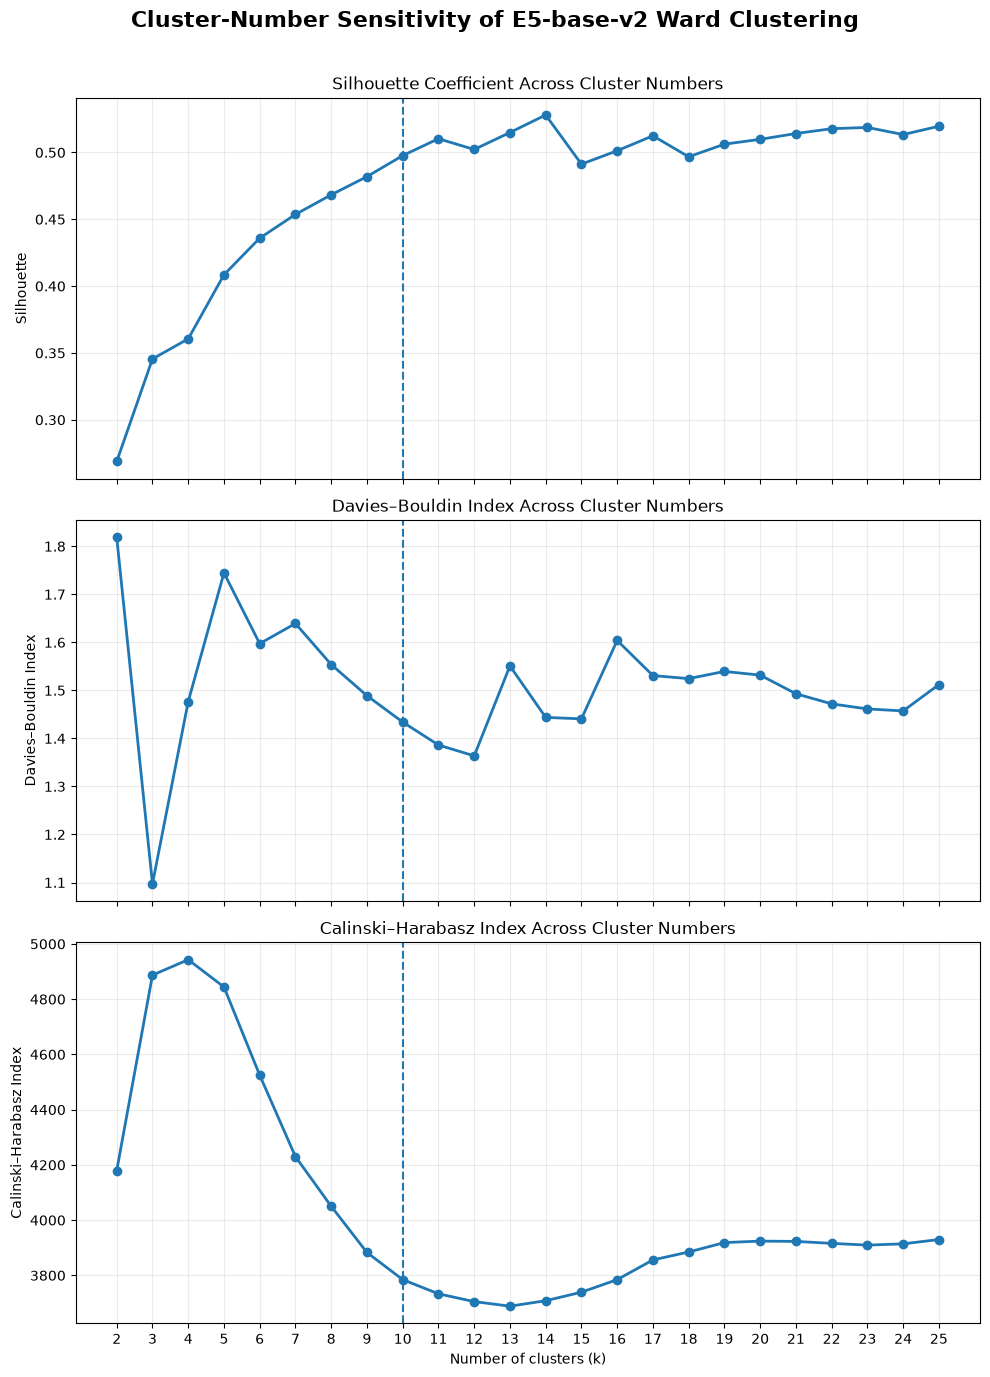


Saved:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\k_sensitivity_final\Figure_k_sensitivity_E5_base_v2_Ward_k2_k25_600dpi.png

FINAL K-SENSITIVITY ANALYSIS SUMMARY
Embedding: E5-base-v2 original 50-D UMAP
Samples: 17,319
Cluster range: k = 2–25
Clustering: Ward agglomerative, Euclidean
Silhouette sample: 5,000
Best Silhouette k: 14
Best Davies-Bouldin k: 3
Best Calinski-Harabasz k: 4
k=10 reproduction ARI: 1.0000000000
k=10 exact sequence match: False

Output directory:
C:\Users\hmari\ai-generated-phishing-detection-multimodal\k_sensitivity_final

K-SENSITIVITY ANALYSIS COMPLETE


In [1]:
# ================================================================
# K-SENSITIVITY ANALYSIS: k = 2–25
# E5-base-v2 | Original 50-D UMAP | Ward | Euclidean
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

# ================================================================
# 1. PATHS
# ================================================================

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

UMAP_FILE = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_umap50.npy"
)

ORIGINAL_CLUSTER_FILE = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_clusters.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "k_sensitivity_final"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ================================================================
# 2. CONFIGURATION
# ================================================================

K_VALUES = list(range(2, 26))

# Fixed sample for Silhouette calculation.
# Same sample is used for every k.
SILHOUETTE_SAMPLE_SIZE = 5000
SILHOUETTE_RANDOM_STATE = 42

EXPECTED_N = 17319
EXPECTED_DIM = 50

PRIMARY_K = 10


# ================================================================
# 3. HEADER
# ================================================================

print("=" * 90)
print("K-SENSITIVITY ANALYSIS — E5-BASE-V2 50-D UMAP")
print("=" * 90)

print(f"UMAP file: {UMAP_FILE}")
print(f"Original cluster file: {ORIGINAL_CLUSTER_FILE}")
print(f"k values: {K_VALUES}")
print("Clustering: Ward agglomerative")
print("Distance: Euclidean")
print(f"Silhouette sample size: {SILHOUETTE_SAMPLE_SIZE}")
print(f"Silhouette random state: {SILHOUETTE_RANDOM_STATE}")


# ================================================================
# 4. LOAD ORIGINAL VERIFIED 50-D UMAP
# ================================================================

print("\n" + "=" * 90)
print("LOADING ORIGINAL VERIFIED 50-D UMAP")
print("=" * 90)

X = np.load(UMAP_FILE)

print("Loaded shape:", X.shape)
print("Data type:", X.dtype)

if X.ndim != 2:
    raise ValueError(
        f"Expected a 2-D embedding matrix, got shape {X.shape}"
    )

if X.shape != (EXPECTED_N, EXPECTED_DIM):
    raise ValueError(
        f"Expected shape {(EXPECTED_N, EXPECTED_DIM)}, "
        f"but found {X.shape}"
    )

if not np.isfinite(X).all():
    raise ValueError("Embedding contains NaN or infinite values.")

print(f"✓ Confirmed: {EXPECTED_N:,} × {EXPECTED_DIM}")
print("✓ No new UMAP will be performed.")


# ================================================================
# 5. LOAD ORIGINAL CLUSTER FILE
#    ONLY FOR POST-HOC k=10 REPRODUCTION CHECK
# ================================================================

print("\n" + "=" * 90)
print("LOADING ORIGINAL VERIFIED CLUSTER ASSIGNMENTS")
print("=" * 90)

original_df = pd.read_csv(ORIGINAL_CLUSTER_FILE)

print("Original cluster file shape:", original_df.shape)
print("Columns:", list(original_df.columns))

required_columns = {"row_index", "true_label", "cluster"}

missing = required_columns - set(original_df.columns)

if missing:
    raise ValueError(
        f"Missing required columns in original cluster file: {missing}"
    )

if len(original_df) != EXPECTED_N:
    raise ValueError(
        f"Expected {EXPECTED_N} rows in original cluster file, "
        f"found {len(original_df)}"
    )

# Check row alignment
expected_row_index = np.arange(EXPECTED_N)

if not np.array_equal(
    original_df["row_index"].to_numpy(),
    expected_row_index
):
    raise ValueError(
        "Row alignment failed: row_index is not 0..17318."
    )

original_labels_k10 = original_df["cluster"].to_numpy()

print("✓ Original cluster assignments loaded.")
print("✓ Row alignment confirmed.")

print("\nOriginal k=10 cluster sizes:")
print(
    pd.Series(original_labels_k10)
    .value_counts()
    .sort_index()
)


# ================================================================
# 6. CREATE FIXED SILHOUETTE SAMPLE
# ================================================================

print("\n" + "=" * 90)
print("CREATING FIXED SILHOUETTE SAMPLE")
print("=" * 90)

rng = np.random.RandomState(SILHOUETTE_RANDOM_STATE)

if SILHOUETTE_SAMPLE_SIZE is None:
    silhouette_indices = np.arange(EXPECTED_N)

else:
    sample_n = min(
        SILHOUETTE_SAMPLE_SIZE,
        EXPECTED_N
    )

    silhouette_indices = np.sort(
        rng.choice(
            EXPECTED_N,
            size=sample_n,
            replace=False
        )
    )

print(
    f"Silhouette sample: "
    f"{len(silhouette_indices):,} / {EXPECTED_N:,}"
)

print("✓ Same fixed sample will be used for every k.")


# ================================================================
# 7. BUILD THE COMPLETE WARD HIERARCHY ONCE
# ================================================================

print("\n" + "=" * 90)
print("BUILDING COMPLETE WARD HIERARCHY")
print("=" * 90)

print("This is performed once.")
print("The hierarchy will subsequently be cut at k = 2–25.")

ward_model = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0,
    metric="euclidean",
    linkage="ward",
    compute_full_tree=True
)

ward_model.fit(X)

children = ward_model.children_

print("Ward hierarchy generated.")
print("children_ shape:", children.shape)

if children.shape[0] != EXPECTED_N - 1:
    raise ValueError(
        "Complete Ward hierarchy was not generated correctly."
    )

print("✓ Complete hierarchy confirmed.")


# ================================================================
# 8. UNION-FIND FUNCTION
#    Used to cut the Ward tree at arbitrary k
# ================================================================

def build_partition_at_k(children, n_samples, k):
    """
    Reconstruct the partition corresponding to k clusters
    from the complete Ward merge hierarchy.
    """

    parent = np.arange(n_samples, dtype=np.int32)
    rank = np.zeros(n_samples, dtype=np.int8)

    # Representative leaf for every dendrogram node.
    node_rep = np.arange(
        2 * n_samples - 1,
        dtype=np.int32
    )

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra = find(a)
        rb = find(b)

        if ra == rb:
            return ra

        if rank[ra] < rank[rb]:
            ra, rb = rb, ra

        parent[rb] = ra

        if rank[ra] == rank[rb]:
            rank[ra] += 1

        return ra

    merges_required = n_samples - k

    for i in range(merges_required):

        child_a = int(children[i, 0])
        child_b = int(children[i, 1])

        rep_a = node_rep[child_a]
        rep_b = node_rep[child_b]

        merged_rep = union(rep_a, rep_b)

        # Internal node ID created by this merge
        new_node = n_samples + i

        node_rep[new_node] = merged_rep

    # Convert final roots into consecutive cluster IDs
    roots = np.empty(
        n_samples,
        dtype=np.int32
    )

    for i in range(n_samples):
        roots[i] = find(i)

    _, labels = np.unique(
        roots,
        return_inverse=True
    )

    labels = labels.astype(np.int32)

    return labels


# ================================================================
# 9. RUN k = 2–25
# ================================================================

print("\n" + "=" * 90)
print("EVALUATING k = 2–25")
print("=" * 90)

results = []

partitions = {}

for k in K_VALUES:

    print("\n" + "-" * 90)
    print(f"RUNNING k = {k}")
    print("-" * 90)

    labels = build_partition_at_k(
        children=children,
        n_samples=EXPECTED_N,
        k=k
    )

    unique_clusters = np.unique(labels)

    if len(unique_clusters) != k:
        raise ValueError(
            f"k={k}: expected {k} clusters, "
            f"found {len(unique_clusters)}"
        )

    # ------------------------------------------------------------
    # Cluster sizes
    # ------------------------------------------------------------

    cluster_sizes = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )

    print("Number of clusters:", len(unique_clusters))
    print(
        "Smallest cluster:",
        cluster_sizes.min()
    )
    print(
        "Largest cluster:",
        cluster_sizes.max()
    )

    # ------------------------------------------------------------
    # Silhouette
    # ------------------------------------------------------------

    sample_labels = labels[silhouette_indices]
    sample_X = X[silhouette_indices]

    # Make sure every cluster occurs in the silhouette sample.
    sample_unique = np.unique(sample_labels)

    if len(sample_unique) != k:

        print(
            "WARNING: Not every cluster is represented "
            "in the fixed Silhouette sample."
        )

        print(
            f"Clusters represented: "
            f"{len(sample_unique)} / {k}"
        )

        raise ValueError(
            f"Silhouette sample does not contain all {k} clusters "
            f"for k={k}. Increase SILHOUETTE_SAMPLE_SIZE."
        )

    silhouette = silhouette_score(
        sample_X,
        sample_labels,
        metric="euclidean"
    )

    # ------------------------------------------------------------
    # Davies–Bouldin
    # ------------------------------------------------------------

    db = davies_bouldin_score(
        X,
        labels
    )

    # ------------------------------------------------------------
    # Calinski–Harabasz
    # ------------------------------------------------------------

    ch = calinski_harabasz_score(
        X,
        labels
    )

    # ------------------------------------------------------------
    # Save partition
    # ------------------------------------------------------------

    partitions[f"k_{k}"] = labels

    # ------------------------------------------------------------
    # Store results
    # ------------------------------------------------------------

    results.append({
        "k": k,
        "Silhouette": silhouette,
        "Davies_Bouldin": db,
        "Calinski_Harabasz": ch,
        "Smallest_Cluster_Size": int(cluster_sizes.min()),
        "Largest_Cluster_Size": int(cluster_sizes.max())
    })

    print(f"Silhouette:        {silhouette:.6f}")
    print(f"Davies-Bouldin:    {db:.6f}")
    print(f"Calinski-Harabasz: {ch:.6f}")


# ================================================================
# 10. RESULTS DATAFRAME
# ================================================================

results_df = pd.DataFrame(results)

# ------------------------------------------------
# Metric ranks
# ------------------------------------------------

# Higher is better
results_df["Silhouette_Rank"] = (
    results_df["Silhouette"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

# Lower is better
results_df["Davies_Bouldin_Rank"] = (
    results_df["Davies_Bouldin"]
    .rank(
        ascending=True,
        method="min"
    )
    .astype(int)
)

# Higher is better
results_df["Calinski_Harabasz_Rank"] = (
    results_df["Calinski_Harabasz"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)


# ================================================================
# 11. SAVE RESULTS
# ================================================================

RESULTS_CSV = os.path.join(
    OUTPUT_DIR,
    "k_sensitivity_results_k2_k25.csv"
)

results_df.to_csv(
    RESULTS_CSV,
    index=False
)

print("\n" + "=" * 90)
print("K-SENSITIVITY RESULTS")
print("=" * 90)

print(
    results_df[
        [
            "k",
            "Silhouette",
            "Davies_Bouldin",
            "Calinski_Harabasz",
            "Silhouette_Rank",
            "Davies_Bouldin_Rank",
            "Calinski_Harabasz_Rank"
        ]
    ].to_string(index=False)
)

print("\nSaved:")
print(RESULTS_CSV)


# ================================================================
# 12. IDENTIFY METRIC-OPTIMAL k VALUES
# ================================================================

best_silhouette = results_df.loc[
    results_df["Silhouette"].idxmax()
]

best_db = results_df.loc[
    results_df["Davies_Bouldin"].idxmin()
]

best_ch = results_df.loc[
    results_df["Calinski_Harabasz"].idxmax()
]

k10_row = results_df[
    results_df["k"] == PRIMARY_K
].iloc[0]

print("\n" + "=" * 90)
print("METRIC-OPTIMAL k VALUES")
print("=" * 90)

print(
    f"Highest Silhouette: "
    f"k = {int(best_silhouette['k'])}, "
    f"value = {best_silhouette['Silhouette']:.6f}"
)

print(
    f"Lowest Davies-Bouldin: "
    f"k = {int(best_db['k'])}, "
    f"value = {best_db['Davies_Bouldin']:.6f}"
)

print(
    f"Highest Calinski-Harabasz: "
    f"k = {int(best_ch['k'])}, "
    f"value = {best_ch['Calinski_Harabasz']:.6f}"
)


# ================================================================
# 13. k=10 INTERNAL-METRIC POSITION
# ================================================================

print("\n" + "=" * 90)
print("k = 10 INTERNAL-METRIC POSITION")
print("=" * 90)

print(
    f"Silhouette:        {k10_row['Silhouette']:.6f}"
)

print(
    f"Silhouette rank:   "
    f"{int(k10_row['Silhouette_Rank'])} / {len(K_VALUES)}"
)

print(
    f"Davies-Bouldin:    {k10_row['Davies_Bouldin']:.6f}"
)

print(
    f"DB rank:           "
    f"{int(k10_row['Davies_Bouldin_Rank'])} / {len(K_VALUES)}"
)

print(
    f"Calinski-Harabasz: "
    f"{k10_row['Calinski_Harabasz']:.6f}"
)

print(
    f"CH rank:           "
    f"{int(k10_row['Calinski_Harabasz_Rank'])} / {len(K_VALUES)}"
)


# ================================================================
# 14. VERIFY k=10 AGAINST ORIGINAL SAVED PARTITION
# ================================================================

print("\n" + "=" * 90)
print("k = 10 ORIGINAL PARTITION REPRODUCTION CHECK")
print("=" * 90)

labels_k10 = partitions["k_10"]

ari_k10_reproduction = adjusted_rand_score(
    original_labels_k10,
    labels_k10
)

print(
    f"ARI between original k=10 partition and "
    f"reconstructed k=10 partition: "
    f"{ari_k10_reproduction:.10f}"
)

# Direct sequence comparison
exact_sequence_match = np.array_equal(
    original_labels_k10,
    labels_k10
)

print(
    "Exact cluster-label sequence match:",
    exact_sequence_match
)


# ------------------------------------------------
# Compare cluster sizes
# ------------------------------------------------

original_sizes = (
    pd.Series(original_labels_k10)
    .value_counts()
    .sort_index()
)

reconstructed_sizes = (
    pd.Series(labels_k10)
    .value_counts()
    .sort_index()
)

size_comparison = pd.DataFrame({
    "Original": original_sizes,
    "Reconstructed_k10": reconstructed_sizes
})

size_comparison["Size_Match"] = (
    size_comparison["Original"]
    ==
    size_comparison["Reconstructed_k10"]
)

print("\nCluster-size comparison:")
print(size_comparison)


# ================================================================
# 15. SAVE ALL k PARTITIONS
# ================================================================

PARTITIONS_FILE = os.path.join(
    OUTPUT_DIR,
    "k_sensitivity_partitions_k2_k25.npz"
)

np.savez_compressed(
    PARTITIONS_FILE,
    **partitions
)

print("\nSaved:")
print(PARTITIONS_FILE)


# ================================================================
# 16. PUBLICATION-QUALITY FIGURE
# ================================================================

FIGURE_FILE = os.path.join(
    OUTPUT_DIR,
    "Figure_k_sensitivity_E5_base_v2_Ward_k2_k25_600dpi.png"
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 14),
    sharex=True
)

# ------------------------------------------------
# Silhouette
# ------------------------------------------------

axes[0].plot(
    results_df["k"],
    results_df["Silhouette"],
    marker="o",
    linewidth=2
)

axes[0].axvline(
    PRIMARY_K,
    linestyle="--",
    linewidth=1.5
)

axes[0].set_ylabel(
    "Silhouette"
)

axes[0].set_title(
    "Silhouette Coefficient Across Cluster Numbers"
)

axes[0].grid(
    True,
    alpha=0.25
)


# ------------------------------------------------
# Davies-Bouldin
# ------------------------------------------------

axes[1].plot(
    results_df["k"],
    results_df["Davies_Bouldin"],
    marker="o",
    linewidth=2
)

axes[1].axvline(
    PRIMARY_K,
    linestyle="--",
    linewidth=1.5
)

axes[1].set_ylabel(
    "Davies–Bouldin Index"
)

axes[1].set_title(
    "Davies–Bouldin Index Across Cluster Numbers"
)

axes[1].grid(
    True,
    alpha=0.25
)


# ------------------------------------------------
# Calinski-Harabasz
# ------------------------------------------------

axes[2].plot(
    results_df["k"],
    results_df["Calinski_Harabasz"],
    marker="o",
    linewidth=2
)

axes[2].axvline(
    PRIMARY_K,
    linestyle="--",
    linewidth=1.5
)

axes[2].set_xlabel(
    "Number of clusters (k)"
)

axes[2].set_ylabel(
    "Calinski–Harabasz Index"
)

axes[2].set_title(
    "Calinski–Harabasz Index Across Cluster Numbers"
)

axes[2].grid(
    True,
    alpha=0.25
)

axes[2].set_xticks(
    K_VALUES
)

plt.suptitle(
    "Cluster-Number Sensitivity of E5-base-v2 Ward Clustering",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.savefig(
    FIGURE_FILE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(FIGURE_FILE)


# ================================================================
# 17. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 90)
print("FINAL K-SENSITIVITY ANALYSIS SUMMARY")
print("=" * 90)

print(
    f"Embedding: E5-base-v2 original 50-D UMAP"
)

print(
    f"Samples: {EXPECTED_N:,}"
)

print(
    f"Cluster range: k = 2–25"
)

print(
    "Clustering: Ward agglomerative, Euclidean"
)

print(
    f"Silhouette sample: "
    f"{SILHOUETTE_SAMPLE_SIZE:,}"
)

print(
    f"Best Silhouette k: "
    f"{int(best_silhouette['k'])}"
)

print(
    f"Best Davies-Bouldin k: "
    f"{int(best_db['k'])}"
)

print(
    f"Best Calinski-Harabasz k: "
    f"{int(best_ch['k'])}"
)

print(
    f"k=10 reproduction ARI: "
    f"{ari_k10_reproduction:.10f}"
)

print(
    f"k=10 exact sequence match: "
    f"{exact_sequence_match}"
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\n" + "=" * 90)
print("K-SENSITIVITY ANALYSIS COMPLETE")
print("=" * 90) 

LOADING EXISTING VERIFIED 50-D UMAP
UMAP shape: (17319, 50)
✓ Confirmed: 17,319 samples × 50 dimensions
✓ No UMAP recomputation will be performed.

LOADING ORIGINAL k=10 WARD CLUSTER PARTITION
Original partition shape: (17319,)
Original number of clusters: 10
✓ Original k=10 partition confirmed.

RECONSTRUCTING COMPLETE WARD HIERARCHY
This may require substantial RAM for 17,319 observations.
Using Ward linkage with Euclidean distance...
Linkage matrix shape: (17318, 4)
✓ Complete Ward hierarchy successfully reconstructed.

VERIFYING k=10 PARTITION
ARI between saved partition and reconstructed Ward k=10: 1.0000000000
✓ ARI = 1.0000000000
✓ Reconstructed k=10 partition is identical as a partition.
✓ Existing clustering results are preserved.

k=10 DENDROGRAM CUT
Height producing 10 clusters: 183.232633
Next merge height (9 clusters): 186.467725
Visual k=10 threshold: 184.850179

GENERATING PUBLICATION-QUALITY DENDROGRAM


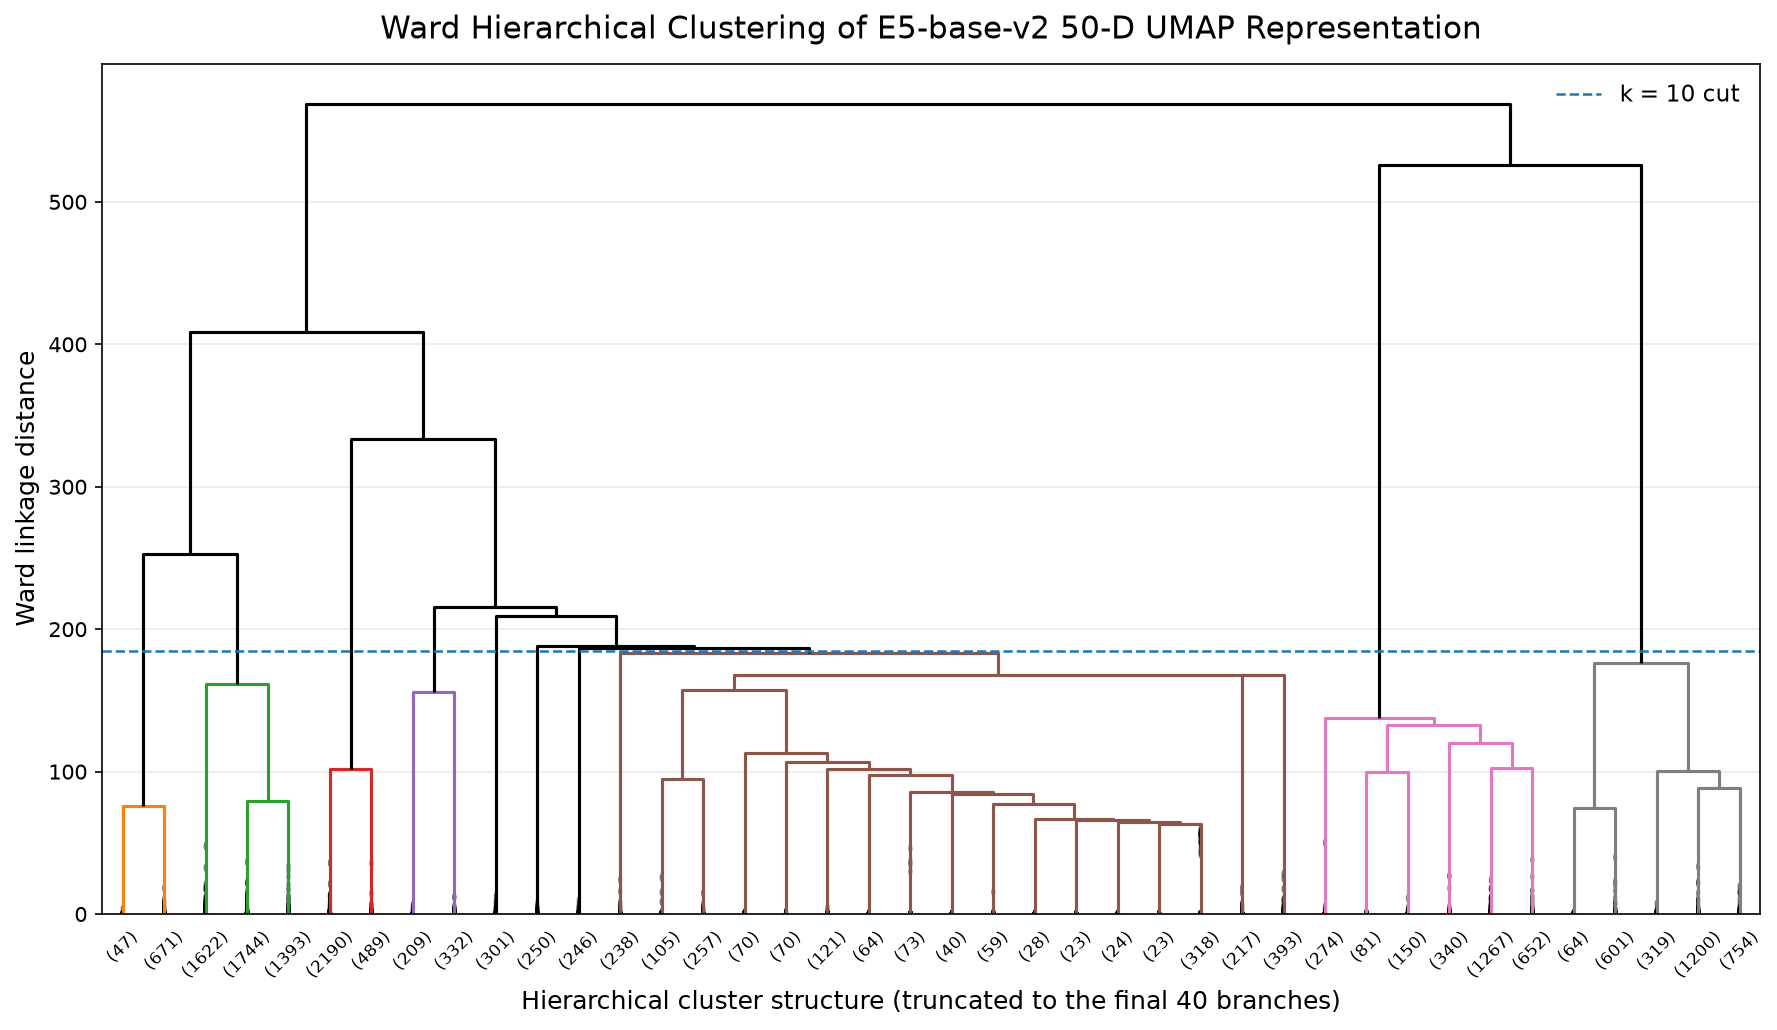


WARD DENDROGRAM GENERATION COMPLETE
Existing UMAP:
  C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_umap50.npy

Original clustering:
  C:\Users\hmari\ai-generated-phishing-detection-multimodal\embedding_model_comparison\e5_base_clusters.csv

UMAP shape:
  (17319, 50)

Number of clusters:
  k = 10

Partition verification:
  ARI = 1.0000000000

Outputs:
  PNG: C:\Users\hmari\ai-generated-phishing-detection-multimodal\dendrogram_final\Figure_Ward_Dendrogram_E5_base_v2_50D_UMAP_600dpi.png
  PDF: C:\Users\hmari\ai-generated-phishing-detection-multimodal\dendrogram_final\Figure_Ward_Dendrogram_E5_base_v2_50D_UMAP.pdf

✓ UMAP was NOT rerun.
✓ Existing 50-D UMAP was used.
✓ Ward k=10 partition was verified against the original.
✓ Dendrogram generated only after successful partition verification.


In [1]:
# ================================================================
# PUBLICATION-QUALITY WARD DENDROGRAM
# Existing E5-base-v2 50-D UMAP — NO UMAP RERUN
# k = 10 partition verification included
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import adjusted_rand_score


# ================================================================
# 1. PATHS
# ================================================================

BASE_DIR = r"C:\Users\hmari\ai-generated-phishing-detection-multimodal"

UMAP_FILE = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_umap50.npy"
)

CLUSTER_FILE = os.path.join(
    BASE_DIR,
    "embedding_model_comparison",
    "e5_base_clusters.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "dendrogram_final"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

PNG_FILE = os.path.join(
    OUTPUT_DIR,
    "Figure_Ward_Dendrogram_E5_base_v2_50D_UMAP_600dpi.png"
)

PDF_FILE = os.path.join(
    OUTPUT_DIR,
    "Figure_Ward_Dendrogram_E5_base_v2_50D_UMAP.pdf"
)


# ================================================================
# 2. LOAD EXISTING 50-D UMAP
# ================================================================

print("=" * 80)
print("LOADING EXISTING VERIFIED 50-D UMAP")
print("=" * 80)

X = np.load(UMAP_FILE)

print("UMAP shape:", X.shape)

if X.shape != (17319, 50):
    raise ValueError(
        f"Expected UMAP shape (17319, 50), but found {X.shape}"
    )

print("✓ Confirmed: 17,319 samples × 50 dimensions")
print("✓ No UMAP recomputation will be performed.")


# ================================================================
# 3. LOAD ORIGINAL PRIMARY k=10 CLUSTER LABELS
# ================================================================

print("\n" + "=" * 80)
print("LOADING ORIGINAL k=10 WARD CLUSTER PARTITION")
print("=" * 80)

cluster_df = pd.read_csv(CLUSTER_FILE)

required_columns = {"row_index", "cluster"}

if not required_columns.issubset(cluster_df.columns):
    raise ValueError(
        f"Cluster file must contain columns {required_columns}. "
        f"Found: {cluster_df.columns.tolist()}"
    )

if len(cluster_df) != 17319:
    raise ValueError(
        f"Expected 17,319 cluster assignments, found {len(cluster_df)}"
    )

# Verify row alignment
expected_indices = np.arange(17319)

if not np.array_equal(
    cluster_df["row_index"].to_numpy(),
    expected_indices
):
    raise ValueError(
        "Row alignment failed. The saved cluster file does not "
        "match the UMAP row order."
    )

original_labels = cluster_df["cluster"].to_numpy()

print("Original partition shape:", original_labels.shape)
print("Original number of clusters:", len(np.unique(original_labels)))

if len(np.unique(original_labels)) != 10:
    raise ValueError(
        "The saved primary partition does not contain exactly 10 clusters."
    )

print("✓ Original k=10 partition confirmed.")


# ================================================================
# 4. RECONSTRUCT COMPLETE WARD HIERARCHY
# ================================================================
#
# IMPORTANT:
# - UMAP is NOT rerun.
# - The exact existing 50-D representation is used.
# - Ward is reconstructed only to obtain the hierarchical
#   merge history required for a dendrogram.
#
# The resulting k=10 partition is checked against the saved
# original partition immediately afterward.
# ================================================================

print("\n" + "=" * 80)
print("RECONSTRUCTING COMPLETE WARD HIERARCHY")
print("=" * 80)

print("This may require substantial RAM for 17,319 observations.")
print("Using Ward linkage with Euclidean distance...")

Z = linkage(
    X,
    method="ward",
    metric="euclidean",
    optimal_ordering=False
)

print("Linkage matrix shape:", Z.shape)

expected_linkage_shape = (17319 - 1, 4)

if Z.shape != expected_linkage_shape:
    raise ValueError(
        f"Unexpected linkage shape {Z.shape}; "
        f"expected {expected_linkage_shape}"
    )

print("✓ Complete Ward hierarchy successfully reconstructed.")


# ================================================================
# 5. VERIFY k=10 PARTITION
# ================================================================

print("\n" + "=" * 80)
print("VERIFYING k=10 PARTITION")
print("=" * 80)

reconstructed_labels = fcluster(
    Z,
    t=10,
    criterion="maxclust"
)

# Convert to zero-based labels for convenience
reconstructed_labels = reconstructed_labels - 1

ari_check = adjusted_rand_score(
    original_labels,
    reconstructed_labels
)

print(f"ARI between saved partition and reconstructed Ward k=10: "
      f"{ari_check:.10f}")

if not np.isclose(ari_check, 1.0, atol=1e-12):
    raise RuntimeError(
        "\nSTOP: The reconstructed Ward hierarchy does NOT reproduce "
        "the saved k=10 partition.\n"
        f"ARI = {ari_check:.10f}\n\n"
        "The dendrogram will NOT be generated because this could "
        "indicate a difference in the clustering implementation, "
        "data ordering, or preprocessing."
    )

print("✓ ARI = 1.0000000000")
print("✓ Reconstructed k=10 partition is identical as a partition.")
print("✓ Existing clustering results are preserved.")


# ================================================================
# 6. DETERMINE k=10 CUT HEIGHT
# ================================================================
#
# For n observations:
# row n-k-1 produces k clusters.
# The following merge produces k-1 clusters.
#
# We place the visual threshold halfway between those two heights.
# ================================================================

n_samples = X.shape[0]
k = 10

height_k = Z[n_samples - k - 1, 2]
height_k_minus_1 = Z[n_samples - k, 2]

color_threshold = (
    height_k + height_k_minus_1
) / 2.0

print("\n" + "=" * 80)
print("k=10 DENDROGRAM CUT")
print("=" * 80)

print(f"Height producing {k} clusters: {height_k:.6f}")
print(f"Next merge height ({k-1} clusters): {height_k_minus_1:.6f}")
print(f"Visual k=10 threshold: {color_threshold:.6f}")


# ================================================================
# 7. PUBLICATION-QUALITY DENDROGRAM
# ================================================================
#
# A full 17,319-leaf dendrogram would be unreadable in a paper.
# Therefore, only the final 40 hierarchical branches are displayed.
#
# The complete Ward hierarchy was nevertheless calculated above,
# and the k=10 partition was independently verified.
# ================================================================

print("\n" + "=" * 80)
print("GENERATING PUBLICATION-QUALITY DENDROGRAM")
print("=" * 80)

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "xtick.labelsize": 9,
    "ytick.labelsize": 10,
    "figure.dpi": 150,
    "savefig.dpi": 600
})

fig, ax = plt.subplots(figsize=(12, 7))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=40,
    show_leaf_counts=True,
    show_contracted=True,
    color_threshold=color_threshold,
    above_threshold_color="black",
    ax=ax
)

ax.axhline(
    y=color_threshold,
    linestyle="--",
    linewidth=1.2,
    label="k = 10 cut"
)

ax.set_title(
    "Ward Hierarchical Clustering of E5-base-v2 50-D UMAP Representation",
    pad=12
)

ax.set_xlabel(
    "Hierarchical cluster structure "
    "(truncated to the final 40 branches)"
)

ax.set_ylabel(
    "Ward linkage distance"
)

ax.legend(
    frameon=False,
    loc="upper right"
)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()


# ================================================================
# 8. SAVE FIGURE
# ================================================================

fig.savefig(
    PNG_FILE,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    PDF_FILE,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ================================================================
# 9. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 80)
print("WARD DENDROGRAM GENERATION COMPLETE")
print("=" * 80)

print("Existing UMAP:")
print(f"  {UMAP_FILE}")

print("\nOriginal clustering:")
print(f"  {CLUSTER_FILE}")

print("\nUMAP shape:")
print(f"  {X.shape}")

print("\nNumber of clusters:")
print("  k = 10")

print("\nPartition verification:")
print(f"  ARI = {ari_check:.10f}")

print("\nOutputs:")
print(f"  PNG: {PNG_FILE}")
print(f"  PDF: {PDF_FILE}")

print("\n✓ UMAP was NOT rerun.")
print("✓ Existing 50-D UMAP was used.")
print("✓ Ward k=10 partition was verified against the original.")
print("✓ Dendrogram generated only after successful partition verification.")
print("=" * 80) 